<a href="https://colab.research.google.com/github/tadeugomes/metodos-pesquisa-quantitativa/blob/main/notebooks/people-analytics/people_analytics_atrito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# People Analytics na prática: quais fatores mais causam atrito no ambiente de trabalho?

**Estudo de caso completo, item a item, em Python/Jupyter**

**Disciplina:** Métodos e Técnicas de Pesquisa Quantitativa — Administração/UFMA
**Docente:** Prof. Dr. Tadeu Gomes Teixeira
**Base:** 23.058 registros de funcionários (IBM HR Analytics, versão ampliada), 30 variáveis
**Técnicas:** regressão logística, árvore de decisão, avaliação fora da amostra

---

## Como usar este notebook

1. **Execute as células de cima para baixo**, sem pular. Cada célula de código depende das anteriores.
2. **Leia o texto antes de cada célula.** O texto diz *o que* vai ser feito, *por que* aquilo é feito e *como ler* o resultado que aparece.
3. **Toda célula de código tem comentários linha a linha.** A regra deste material é: nenhuma função aparece sem que se diga de onde ela vem e o que ela faz.
4. No **Colab**, nada precisa ser instalado: as bibliotecas usadas já vêm no ambiente. Se estiver rodando no seu computador, veja a Parte 2.

> **Tempo estimado de execução:** 3 a 6 minutos no Colab (a base tem 23 mil linhas; os modelos são leves).

---

## Roteiro

| Parte | O que se faz | Competência trabalhada |
|---|---|---|
| **0** | Como o People Analytics está sendo usado nas empresas | Conceito, vantagens, limites |
| **1** | Pergunta de negócio e desenho da análise | Transformar pergunta de gestão em pergunta de dados |
| **2** | O ferramental: o que cada biblioteca faz | Ferramental |
| **3** | Carga dos dados e dicionário das 30 variáveis | Conhecer o dado antes de analisar |
| **4** | Inspeção e limpeza (tipos, duplicatas, ausentes, escalas) | Qualidade do dado |
| **5** | Engenharia de atributos | Criar variáveis que respondem à pergunta |
| **6** | Recorte analítico (quem entra e quem sai da base) | Definir a população de análise |
| **7** | Análise exploratória univariada | Descrever o quadro de pessoal |
| **8** | Análise exploratória bivariada: taxa de saída por grupo | Diagnóstico |
| **9** | Regressão logística: o modelo e sua interpretação | Inferência e predição |
| **10** | Árvore de decisão e comparação de modelos | Regras legíveis para o RH |
| **11** | Do modelo à decisão de RH | Prescrição, custo e ética |
| **12** | As armadilhas do caminho, e as decisões que as evitam | Leitura crítica da própria análise |
| **13** | Exercícios e referências | Fixação |

---

# Parte 0. Como o People Analytics está sendo usado?

## 0.1 O que é

**People Analytics** é o uso sistemático de dados sobre pessoas — contratação, remuneração, tempo
de casa, desempenho, satisfação, desligamento — para apoiar decisões de gestão de pessoas que
antes eram tomadas por intuição, hábito ou senioridade de quem opina.

A definição operacional que vale para este notebook é esta: **People Analytics é pesquisa
quantitativa aplicada ao quadro de pessoal da organização**. Os mesmos conceitos da disciplina
reaparecem aqui com outro nome:

| Conceito da disciplina | Como aparece em People Analytics |
|---|---|
| Unidade de análise | O funcionário (uma linha = uma pessoa) |
| População | O quadro de pessoal da empresa |
| Variável dependente | `Attrition` — a pessoa saiu ou continua |
| Variáveis independentes | Idade, salário, hora extra, departamento, origem do recrutamento… |
| Hipótese | "Fazer hora extra aumenta a chance de pedir demissão" |
| Teste | Regressão logística, com os coeficientes e seus valores-p |

## 0.2 As vantagens do People Analytics

O conceito de avaliar dados e informações sobre os funcionários em busca de otimizações traz
vantagens diversas, sendo a mais evidente a **retenção de talentos** na empresa. Outro ponto é
que, como a escolha é feita de forma adequada, existem menos chances de que o candidato errado
seja escolhido para uma determinada vaga — o que, de modo desfavorável, implicaria em um processo
mais burocrático e na necessidade de reiteradas seleções de recursos humanos.

Entre os já contratados, o favorecimento da retenção acontece porque os funcionários ficam mais
satisfeitos, motivados e possuem mais objetivos dentro da própria empresa.

Além disso, é possível gerar impactos positivos no **desempenho**, tanto por identificar as
condições que favorecem a produtividade, quanto pela **alocação correta de talentos** para as
funções e projetos específicos. Essas informações ainda fornecem *insights* sobre a criatividade
de cada colaborador, e como isso pode impactar direta e positivamente nos resultados — um vendedor
mais criativo, por exemplo, tem mais chances de fazer negócios do que aquele que é estritamente
metódico.

O uso do People Analytics está cada vez mais fazendo parte da realidade das empresas porque é uma
forma de melhorar a **assertividade da gestão de pessoas**, por meio de dados e modelos preditivos.
*Big Data* e *Machine Learning* em ação.

## 0.3 Os quatro níveis de maturidade

Toda área de People Analytics percorre, na prática, quatro degraus. Este notebook sobe os quatro,
e vale saber em que degrau cada parte está:

| Nível | Pergunta que responde | Onde aparece aqui |
|---|---|---|
| **Descritivo** | *O que aconteceu?* Qual é a taxa de saída? | Partes 7 e 8 |
| **Diagnóstico** | *Por que aconteceu?* Quem sai mais, e em que condições? | Parte 8 |
| **Preditivo** | *O que vai acontecer?* Qual a probabilidade de esta pessoa sair? | Partes 9 e 10 |
| **Prescritivo** | *O que fazer?* Em quem intervir, com qual ação, a que custo? | Parte 11 |

A maior parte dos relatórios de RH para na primeira linha: um painel com *headcount*, absenteísmo
e turnover do mês. O salto de valor está em passar do descritivo ao diagnóstico — e é aí que a
estatística entra.

## 0.4 O caso do Google

O Google é a referência mais citada porque institucionalizou a ideia de que decisões sobre pessoas
precisam de evidência, como qualquer outra decisão da empresa. Três resultados conhecidos da área
de *People Operations*:

- **Project Oxygen** testou a hipótese de que a qualidade do gestor direto afeta a retenção e o
  desempenho da equipe. Os dados sustentaram a hipótese e produziram uma lista de comportamentos
  de gestão que passou a orientar treinamento e avaliação.
- **Entrevistas de seleção**: a análise mostrou que o número de entrevistas tinha retorno
  decrescente, e o processo foi encurtado — uma decisão de custo tomada com dado, não com hábito.
- **Project Aristotle** investigou o que distingue equipes eficazes, e encontrou na segurança
  psicológica um preditor mais forte do que a composição de talentos individuais.

O ponto metodológico não é a conclusão de cada projeto, é o procedimento: **formular a hipótese,
medir, testar, e aceitar o resultado mesmo quando ele contraria a crença interna da empresa**.

**Referências**
- *People analytics at Google: using data to make Google a great place to work* — Harvard Business School Digital Initiative. https://digital.hbs.edu/platform-digit/submission/people-analytics-at-google-using-data-to-make-google-a-great-place-to-work/
- *Case study: how Google uses People Analytics* — Sage People. https://www.sagepeople.com/about-us/news-hub/case-study-how-google-uses-people-analytics/

## 0.5 Os limites, que precisam ser ditos junto com as vantagens

Um material honesto sobre People Analytics declara o que o método **não** entrega:

1. **Correlação não é causa.** Se quem faz hora extra sai mais, não está provado que a hora extra
   causa a saída. Pode ser que as áreas com pior gestão exijam mais hora extra *e* produzam mais
   saídas. A regressão deste notebook mede associação condicional, não efeito causal.
2. **O dado carrega o viés da organização que o produziu.** Se a empresa historicamente promoveu
   menos mulheres, um modelo treinado nesse histórico vai aprender esse padrão e, se usado para
   decidir promoções, vai reproduzi-lo.
3. **Variáveis sensíveis exigem cuidado jurídico e ético.** Gênero, estado civil, idade e origem
   são protegidos. Usá-los para *entender* a organização é legítimo e necessário; usá-los para
   *decidir* sobre uma pessoa específica é discriminação — e, no Brasil, a LGPD (Lei 13.709/2018)
   trata dado de funcionário como dado pessoal, com base legal, finalidade declarada e minimização.
4. **O preditivo tem prazo de validade.** Um modelo ajustado no quadro de 2023 pode não valer em
   2026, porque mudou o mercado de trabalho, a política salarial e a composição do quadro.
5. **Previsão individual ≠ sentença.** A saída correta de um modelo de atrito é uma *lista de
   prioridade para conversa*, não uma marcação de quem "vai embora".

Essas cinco ressalvas voltam na Parte 11, aplicadas aos resultados que o notebook tiver produzido.

---

# Parte 1. A pergunta de negócio e o desenho da análise

## 1.1 A pergunta como o RH a formula

> *"Estamos perdendo gente. Quais fatores mais causam atrito no ambiente de trabalho, e o que
> podemos fazer no recrutamento e na gestão para perder menos?"*

Assim formulada, a pergunta não é respondível. Ela não diz o que é "perder gente", nem o que conta
como "fator", nem o que seria uma resposta satisfatória. O primeiro trabalho analítico é **traduzir**.

## 1.2 A mesma pergunta traduzida para pesquisa quantitativa

| Elemento do desenho | Decisão tomada neste estudo | Por que |
|---|---|---|
| **Unidade de análise** | O funcionário | Cada linha da base é uma pessoa; a decisão de sair é individual |
| **População** | Quadro de pessoal da empresa no período coberto pela base | Não há amostragem: é um censo administrativo do quadro |
| **Variável dependente** | `Attrition`, recodificada em binária: *pediu demissão* (1) vs *continua na empresa* (0) | A decisão que o RH quer influenciar é o pedido de demissão |
| **Variáveis independentes** | 29 variáveis, separadas em dois grupos (ver 1.3) | O grupo muda o que se pode fazer com o resultado |
| **Hipóteses** | H1: hora extra aumenta a chance de saída. H2: salário mais baixo aumenta a chance de saída. H3: solteiros saem mais. H4: a origem do recrutamento se associa à saída | Hipóteses declaradas *antes* de olhar o resultado |
| **Técnica** | Regressão logística (associação + predição) e árvore de decisão (regras legíveis) | A dependente é binária |
| **Critério de sucesso** | Identificar fatores com associação estatisticamente detectável e materialmente relevante, e produzir uma regra de priorização utilizável pelo RH | Resultado precisa caber numa decisão |

## 1.3 A distinção que organiza todo o estudo: antes e depois da contratação

Esta é a decisão metodológica mais importante do caso, e a que a maior parte das análises de
atrito deixa implícita. As variáveis explicativas se dividem em dois grupos com **usos diferentes**:

**Grupo A — conhecidas *antes* de contratar** (idade, escolaridade, área de formação, estado civil,
distância de casa, experiência anterior, estabilidade média em empregos anteriores, origem do
recrutamento, gênero):
→ servem para **melhorar o recrutamento**. Se a origem do recrutamento se associa à retenção, o RH
pode redirecionar o investimento em canais. Atenção: usar gênero, idade ou estado civil para
*selecionar* candidatos é ilegal; aqui eles entram como **controles** para evitar atribuir a outras
variáveis um efeito que é, na verdade, de composição do quadro.

**Grupo B — só conhecidas *depois* de contratar** (hora extra, satisfação com o trabalho, com o
ambiente e com as relações, equilíbrio trabalho-vida, salário, nível hierárquico, promoção,
treinamentos, *stock options*, anos com o gestor atual):
→ servem para **gerir quem já está dentro**: política de hora extra, revisão salarial, trilha de
promoção, qualidade da gestão.

Um modelo que mistura os dois grupos responde bem à pergunta "quem tende a sair?" e **mal** à
pergunta "o que eu faço a respeito?". Por isso, na Parte 9, serão ajustados modelos separados: um
só com o Grupo A (foco em recrutamento) e um com os dois grupos (foco em
gestão). Comparar os dois é mais informativo do que ajustar um só.

## 1.4 O que é "atrito" (*attrition*) e por que ele não é uma coisa só

A variável `Attrition` desta base tem **três** valores, e tratá-los como dois é uma escolha que
precisa ser justificada:

| Valor | Significado | Quem decidiu |
|---|---|---|
| `Current employee` | Continua na empresa | — |
| `Voluntary Resignation` | Pediu demissão | **O funcionário** |
| `Termination` | Foi desligado pela empresa | **A empresa** |

Misturar demissão voluntária e desligamento numa única categoria "saiu" produziria um modelo sem
sentido gerencial: os dois eventos têm causas opostas. Quem é desligado costuma ter **baixo**
desempenho; quem pede demissão costuma ter desempenho normal ou alto e uma alternativa melhor
no mercado. O que o RH quer evitar é o segundo caso.

A decisão deste estudo: **modelar a demissão voluntária** e deixar os desligamentos de fora
(são 87 casos, 0,4% da base). A Parte 6 executa e documenta esse recorte.

---

# Parte 2. O ferramental: o que o código faz, e com o quê

## 2.1 Cinco bibliotecas, cinco funções no estudo

Este notebook **não** ensina a programar. Ele mostra **como o código operacionaliza** cada elemento
da análise: como uma frequência se torna tabela, como uma distribuição se torna gráfico, como uma
hipótese se torna modelo. Para isso bastam cinco bibliotecas, e vale saber qual delas faz o quê:

| Biblioteca | O que faz no estudo | Elementos que operacionaliza |
|---|---|---|
| **pandas** | A tabela de dados e tudo o que se faz com ela: carregar, limpar, agrupar, cruzar | Frequência, proporção, média, mediana, quartis, tabela de contingência |
| **numpy** | O cálculo numérico por trás do pandas | Operações vetoriais, a raiz quadrada do intervalo de confiança, logaritmo |
| **matplotlib** e **seaborn** | Os gráficos | Barras, histograma, densidade, boxplot, dispersão, mapa de calor |
| **statsmodels** | Modelos estatísticos **com inferência** | Regressão logística, coeficientes, valores-p, intervalos de confiança, VIF |
| **scikit-learn** | **Predição e avaliação** | Divisão treino/teste, árvore de decisão, matriz de confusão, AUC |

**A distinção entre as duas últimas é a mais importante, e não é questão de preferência.** Elas
respondem perguntas diferentes sobre o mesmo modelo:

| | `statsmodels` | `scikit-learn` |
|---|---|---|
| Feita para | **Inferência**: entender | **Predição**: acertar |
| Entrega | Coeficiente, erro-padrão, valor-p, intervalo de confiança | Probabilidade prevista, métricas de acerto |
| Responde | "Hora extra está associada à saída? Com que força? A associação é distinguível de zero?" | "Este modelo acerta em dados que ele não viu?" |
| Não entrega | Avaliação fora da amostra, pronta | Valor-p, intervalo de confiança |

**Este notebook usa as duas, para fins diferentes**: `statsmodels` para interpretar os fatores
(Parte 9) e `scikit-learn` para dividir treino e teste, avaliar e ajustar a árvore (Partes 9 e 10).
Usar só a primeira produz um estudo que explica e não prevê; usar só a segunda, um estudo que prevê e
não explica. Nenhum dos dois serve a uma decisão de gestão.

## 2.2 Instalação

No **Google Colab** todas as bibliotecas usadas já estão instaladas — a célula abaixo apenas
confere as versões e não instala nada. Se você estiver rodando localmente e faltar alguma,
descomente a linha de instalação.

In [1]:
# ---------------------------------------------------------------------------
# Conferência do ambiente. Esta célula NÃO instala nada por padrão: ela apenas
# importa cada biblioteca e imprime a versão, para que o resultado do notebook
# seja reproduzível (quem repetir a análise sabe com que versões ela rodou).
#
# Se alguma linha falhar com ModuleNotFoundError, descomente a instalação:
# !pip install -q pandas numpy matplotlib seaborn statsmodels scikit-learn
# ---------------------------------------------------------------------------

import sys                                   # informações do próprio Python
import importlib                             # importa módulos a partir do nome em texto

bibliotecas = [
    ("pandas",       "tabelas (DataFrame): carga, limpeza, agrupamento"),
    ("numpy",        "vetores e cálculo numérico; é a base do pandas"),
    ("matplotlib",   "motor de gráficos"),
    ("seaborn",      "gráficos estatísticos sobre o matplotlib"),
    ("statsmodels",  "modelos estatísticos COM inferência (valor-p, IC)"),
    ("sklearn",      "aprendizado de máquina: divisão treino/teste, árvore, métricas"),
]

print(f"Python {sys.version.split()[0]}\n")
print(f"{'biblioteca':<14}{'versão':<12}para que serve neste notebook")
print("-" * 92)
for nome, finalidade in bibliotecas:
    try:
        modulo = importlib.import_module(nome)          # equivale a "import nome"
        versao = getattr(modulo, "__version__", "?")    # quase todas expõem __version__
        print(f"{nome:<14}{versao:<12}{finalidade}")
    except ModuleNotFoundError:
        print(f"{nome:<14}{'AUSENTE':<12}{finalidade}   <-- instale esta")

Python 3.13.7

biblioteca    versão      para que serve neste notebook
--------------------------------------------------------------------------------------------


pandas        2.2.3       tabelas (DataFrame): carga, limpeza, agrupamento
numpy         2.1.3       vetores e cálculo numérico; é a base do pandas


matplotlib    3.10.7      motor de gráficos


seaborn       0.13.2      gráficos estatísticos sobre o matplotlib
statsmodels   0.14.6      modelos estatísticos COM inferência (valor-p, IC)
sklearn       1.8.0       aprendizado de máquina: divisão treino/teste, árvore, métricas


## 2.3 Importações e configuração visual

A célula abaixo faz três coisas, nesta ordem:

1. **Importa** o que será usado, com os apelidos convencionais (`pd`, `np`, `plt`, `sns`). Esses
   apelidos não são obrigatórios, mas são universais na comunidade — usá-los faz o código ser
   lido por qualquer pessoa da área.
2. **Configura a exibição** do pandas: mais colunas visíveis, números sem notação científica.
   Sem isso, uma base de 30 colunas aparece cortada com `...` no meio.
3. **Define o padrão visual** dos gráficos, uma vez, no começo. Assim nenhum gráfico adiante
   precisa repetir cor, tamanho e fonte — e todos saem com a mesma aparência.

In [2]:
# ============================= IMPORTAÇÕES =================================
import pandas as pd                      # 'pd' é o apelido universal do pandas
import numpy as np                       # 'np', idem, para numpy
import matplotlib.pyplot as plt          # interface de gráficos estilo MATLAB
import seaborn as sns                    # gráficos estatísticos prontos
import warnings                           # controle de mensagens de aviso

# Modelagem estatística (inferência: coeficientes, valores-p, razão de chances)
import statsmodels.api as sm                        # API "matricial" do statsmodels
import statsmodels.formula.api as smf               # API de FÓRMULA, estilo R: y ~ x1 + x2
from statsmodels.stats.outliers_influence import variance_inflation_factor  # VIF

# Aprendizado de máquina (predição e avaliação)
from sklearn.model_selection import train_test_split     # divisão treino/teste
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (confusion_matrix,           # matriz de confusão
                             classification_report,      # precisão, recall, F1
                             roc_auc_score,              # área sob a curva ROC
                             roc_curve,                  # pontos da curva ROC
                             precision_recall_curve)     # curva precisão-recall

# ======================= CONFIGURAÇÃO DE EXIBIÇÃO ==========================
pd.set_option("display.max_columns", 40)     # mostra até 40 colunas sem cortar
pd.set_option("display.width", 160)          # largura da linha no terminal
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")  # 3 decimais, sem 1e+03

warnings.filterwarnings("ignore", category=FutureWarning)  # silencia avisos de versão

# ========================= PADRÃO VISUAL ÚNICO =============================
sns.set_theme(style="whitegrid")             # fundo branco com grade discreta
plt.rcParams["figure.figsize"] = (9, 5)      # tamanho padrão de cada figura
plt.rcParams["figure.dpi"] = 110             # nitidez da imagem na tela
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["font.size"] = 10

# Duas cores, usadas em TODO o notebook com o MESMO significado:
COR_FICOU = "#4C78A8"   # azul  = continua na empresa
COR_SAIU  = "#E45756"   # vermelho = pediu demissão
PALETA_ATRITO = {"Continua na empresa": COR_FICOU, "Pediu demissão": COR_SAIU}

# Semente aleatória: fixa o sorteio para que o notebook dê SEMPRE o mesmo
# resultado. Sem isso, cada execução sortearia uma divisão treino/teste
# diferente e os números do texto não bateriam com os da tela.
SEMENTE = 2004                      # qualquer número serve: o que importa é FIXAR um
np.random.seed(SEMENTE)

print("Ambiente configurado.")
print(f"Semente aleatória fixada em {SEMENTE} (resultados reproduzíveis).")

Ambiente configurado.
Semente aleatória fixada em 2004 (resultados reproduzíveis).


---

# Parte 3. Carga dos dados

## 3.1 A estratégia de carga, e por que ela tem três tentativas

Um notebook didático roda em três lugares diferentes, e o caminho do arquivo é diferente em cada um:

| Onde roda | Onde está o CSV |
|---|---|
| Colab, a partir do GitHub | Em nenhum lugar: precisa ser baixado da internet |
| Computador local, dentro do repositório da disciplina | Em `dados/people_analytics_rh.csv` |
| Colab, com o arquivo na mão | Precisa ser enviado pelo botão de *upload* |

A função abaixo tenta as três opções **em ordem**, e informa qual funcionou. É um padrão que vale
copiar para qualquer notebook que você vá compartilhar: ele evita a pergunta "por que não acha o
arquivo?", que é a causa mais comum de um notebook não rodar na mão de outra pessoa.

In [3]:
from pathlib import Path     # manipulação de caminhos de arquivo, independente do sistema

# Endereço do arquivo no repositório da disciplina (GitHub, conteúdo "raw" = bruto)
URL_DADOS = ("https://raw.githubusercontent.com/tadeugomes/"
             "metodos-pesquisa-quantitativa/main/dados/people_analytics_rh.csv")

# Caminhos locais possíveis, em ordem de tentativa. Isso cobre o notebook sendo
# executado da raiz do repositório OU de dentro da pasta notebooks/people-analytics/.
CAMINHOS_LOCAIS = [
    Path("dados/people_analytics_rh.csv"),
    Path("../../dados/people_analytics_rh.csv"),
    Path("dataset.csv"),
]


def carregar_base():
    """Carrega a base de RH tentando, em ordem: arquivo local, URL do GitHub, upload.

    Retorna
    -------
    (DataFrame, str)
        A tabela carregada e um texto dizendo de onde ela veio.
    """
    # --- Tentativa 1: arquivo já presente no disco -------------------------
    for caminho in CAMINHOS_LOCAIS:
        if caminho.exists():
            return pd.read_csv(caminho), f"arquivo local: {caminho}"

    # --- Tentativa 2: baixar do repositório da disciplina -----------------
    try:
        return pd.read_csv(URL_DADOS), "GitHub (repositório da disciplina)"
    except Exception as erro:
        print(f"[aviso] não foi possível baixar do GitHub: {type(erro).__name__}")

    # --- Tentativa 3: pedir o upload (só funciona dentro do Colab) --------
    try:
        from google.colab import files        # existe apenas no Colab
        print("Envie o arquivo dataset.csv (ou people_analytics_rh.csv):")
        enviados = files.upload()             # abre o botão de seleção de arquivo
        nome = list(enviados.keys())[0]       # nome do primeiro arquivo enviado
        return pd.read_csv(nome), f"upload manual: {nome}"
    except ImportError:
        raise FileNotFoundError(
            "Base não encontrada. Coloque o CSV ao lado deste notebook "
            "e execute esta célula de novo."
        )


dados_rh, origem = carregar_base()        # <- aqui a base entra na memória

print(f"Base carregada de {origem}")
print(f"Dimensões: {dados_rh.shape[0]:,} linhas  x  {dados_rh.shape[1]} colunas"
      .replace(",", "."))

Base carregada de arquivo local: ..\..\dados\people_analytics_rh.csv
Dimensões: 23.058 linhas  x  30 colunas


**Como ler o resultado.** Devem aparecer **23.058 linhas e 30 colunas**. As 23.058 linhas são
registros de funcionários; as 30 colunas são os atributos de cada um. Guarde esse número: ele vai
mudar duas vezes neste notebook, e cada mudança será justificada (Parte 4, duplicatas; Parte 6,
recorte dos desligamentos).

## 3.2 As primeiras linhas: a primeira coisa que se faz com qualquer base

Antes de qualquer estatística, **olhe o dado**. `head()` mostra as primeiras linhas e serve para
checar o óbvio: as colunas estão com o nome certo? Os números estão na coluna que deveriam? Há
texto onde deveria haver número? O separador do CSV foi lido corretamente, ou tudo veio numa única
coluna?

In [4]:
# .head(5) devolve as 5 primeiras linhas. .T transpõe (linhas <-> colunas):
# com 30 colunas, transpor é a única forma de ver TODAS elas de uma vez na tela,
# uma por linha, em vez de uma tabela cortada com "..." no meio.
dados_rh.head(5).T

,0,1,2,3,4
Age,41,37,41,37,37
Attrition,Voluntary Resignation,Voluntary Resignation,Voluntary Resignation,Voluntary Resignation,Voluntary Resignation
BusinessTravel,Travel_Rarely,Travel_Rarely,Travel_Rarely,Travel_Rarely,Travel_Rarely
Department,Sales,Human Resources,Sales,Human Resources,Human Resources
DistanceFromHome,1,6,1,6,6
Education,2,4,2,4,4
EducationField,Life Sciences,Human Resources,Life Sciences,Marketing,Human Resources
EnvironmentSatisfaction,2,1,2,1,1
Gender,Female,Female,Female,Female,Female
JobInvolvement,3,3,3,3,3


## 3.3 Dicionário das 30 variáveis

É a tabela que falta na maior parte dos relatórios de RH, e sem a qual a análise fica adivinhando
o que cada coluna mede.
A coluna **Grupo** retoma a distinção da Parte 1.3 — e é ela que vai determinar, na Parte 9, qual
variável entra em qual modelo.

Legenda do grupo: **A** = conhecida antes da contratação · **B** = só conhecida depois ·
**Y** = variável dependente · **D** = derivada/identificação.

| # | Variável | O que mede | Tipo | Valores | Grupo |
|---|---|---|---|---|---|
| 1 | `Age` | Idade em anos completos | Numérica | 18 a 60 | A |
| 2 | `Attrition` | Situação do vínculo | Categórica | `Current employee`, `Voluntary Resignation`, `Termination` | **Y** |
| 3 | `BusinessTravel` | Frequência de viagens a trabalho | Categórica ordinal | `Non-Travel` < `Travel_Rarely` < `Travel_Frequently` | B |
| 4 | `Department` | Departamento | Categórica | `Sales`, `Research & Development`, `Human Resources` | B |
| 5 | `DistanceFromHome` | Distância casa–trabalho | Numérica | 1 a 29 (milhas) | A |
| 6 | `Education` | Escolaridade | Categórica ordinal | 1=Abaixo do médio · 2=Médio · 3=Graduação · 4=Mestrado · 5=Doutorado | A |
| 7 | `EducationField` | Área de formação | Categórica | `Life Sciences`, `Medical`, `Marketing`, `Technical Degree`, `Human Resources`, `Other` | A |
| 8 | `EnvironmentSatisfaction` | Satisfação com o ambiente físico de trabalho | Ordinal (Likert) | 1=Baixa · 2=Média · 3=Alta · 4=Muito alta | B |
| 9 | `Gender` | Gênero | Categórica | `Female`, `Male` | A (uso restrito) |
| 10 | `JobInvolvement` | Envolvimento com o trabalho | Ordinal (Likert) | 1 a 4 | B |
| 11 | `JobLevel` | Nível hierárquico | Ordinal | 1 (entrada) a 5 (topo) | B |
| 12 | `JobRole` | Cargo | Categórica | 9 cargos | B |
| 13 | `JobSatisfaction` | Satisfação com o trabalho | Ordinal (Likert) | 1 a 4 | B |
| 14 | `MaritalStatus` | Estado civil | Categórica | `Single`, `Married`, `Divorced` | A (uso restrito) |
| 15 | `MonthlyIncome` | Salário mensal | Numérica | 1.009 a 19.999 | B |
| 16 | `NumCompaniesWorked` | Nº de empresas em que já trabalhou | Numérica | 0 a 9 | A |
| 17 | `OverTime` | Faz hora extra | Binária | `Yes`, `No` | B |
| 18 | `PercentSalaryHike` | % do último reajuste | Numérica | 11 a 25 | B |
| 19 | `PerformanceRating` | Nota de desempenho | Ordinal | 1 a 4 (na prática só 3 e 4) | B |
| 20 | `RelationshipSatisfaction` | Satisfação com as relações no trabalho | Ordinal (Likert) | 1 a 4 | B |
| 21 | `StockOptionLevel` | Nível de participação acionária | Ordinal | 0 a 3 | B |
| 22 | `TotalWorkingYears` | Anos totais de experiência profissional | Numérica | 0 a 40 | A |
| 23 | `TrainingTimesLastYear` | Nº de treinamentos no último ano | Numérica | 0 a 6 | B |
| 24 | `WorkLifeBalance` | Equilíbrio trabalho–vida pessoal | Ordinal (Likert) | 1=Ruim a 4=Ótimo | B |
| 25 | `YearsAtCompany` | Anos na empresa atual | Numérica | 0 a 40 | B |
| 26 | `YearsInCurrentRole` | Anos no cargo atual | Numérica | 0 a 18 | B |
| 27 | `YearsSinceLastPromotion` | Anos desde a última promoção | Numérica | 0 a 15 | B |
| 28 | `YearsWithCurrManager` | Anos com o gestor atual | Numérica | 0 a 17 | B |
| 29 | `Employee Source` | Canal pelo qual foi recrutado | Categórica | 9 canais (site da empresa, LinkedIn, Indeed, indicação…) | A |
| 30 | `AgeStartedWorking` | Idade em que começou a trabalhar | Numérica | = `Age` − `TotalWorkingYears` | D |

**Três observações que já saem do dicionário:**

- **`Employee Source` tem espaço no nome.** Em R isso obriga a escrever `` `Employee Source` ``
  com acento grave; em Python obriga `dados_rh["Employee Source"]` em vez de
  `dados_rh.Employee Source`, que é erro de sintaxe. Na Parte 4 a coluna será renomeada para
  `EmployeeSource` — e essa é a decisão certa sempre que você for usar a variável numa fórmula
  de modelo.
- **`AgeStartedWorking` é redundante** por construção: é `Age − TotalWorkingYears`. Colocar as três
  no mesmo modelo cria colinearidade perfeita. A Parte 4 verifica a identidade; a Parte 9 trata a
  consequência.
- **As escalas de 1 a 4 são Likert.** Vieram como número inteiro no CSV, mas a distância entre
  "baixa" e "média" não é necessariamente igual à distância entre "alta" e "muito alta". Tratá-las
  como numéricas assume linearidade; como categóricas, não assume nada mas gasta mais parâmetros.
  Este notebook **decide escala por escala**, a partir da forma observada no gráfico: os passos
  8.15 e 9.8 mostram essa decisão sendo tomada, com a justificativa de cada caso.

---

# Parte 4. Inspeção e limpeza

Esta é a parte mais longa do notebook, e isso não é defeito: em qualquer projeto real de People
Analytics, **limpar e entender o dado consome mais tempo do que modelar**. Cada subitem aqui
corresponde a uma pergunta que o analista precisa responder *antes* de calcular qualquer média.

## 4.1 Que tipo o pandas atribuiu a cada coluna?

`info()` responde três coisas de uma vez: quantas linhas há, quantos valores **não nulos** cada
coluna tem, e que tipo de dado o pandas inferiu. Os tipos importam porque determinam o que pode
ser feito: `int64` aceita média; `object` (texto) não.

In [5]:
# info() imprime a estrutura da tabela: é a primeira coisa a rodar numa base nova.
#   - Non-Null Count: quantos valores preenchidos (o complemento são os ausentes)
#   - Dtype: o tipo inferido pelo pandas ao ler o CSV
dados_rh.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23058 entries, 0 to 23057
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       23058 non-null  int64 
 1   Attrition                 23058 non-null  object
 2   BusinessTravel            23058 non-null  object
 3   Department                23058 non-null  object
 4   DistanceFromHome          23058 non-null  int64 
 5   Education                 23058 non-null  int64 
 6   EducationField            23058 non-null  object
 7   EnvironmentSatisfaction   23058 non-null  int64 
 8   Gender                    23058 non-null  object
 9   JobInvolvement            23058 non-null  int64 
 10  JobLevel                  23058 non-null  int64 
 11  JobRole                   23058 non-null  object
 12  JobSatisfaction           23058 non-null  int64 
 13  MaritalStatus             23058 non-null  object
 14  MonthlyIncome         

**Como ler o resultado.** Três leituras:

1. **23.058 linhas (`entries 0 to 23057`)** — confere com o esperado.
2. **Todas as 30 colunas têm 23.058 valores não nulos** — ou seja, **não há nenhum valor ausente**
   nesta base. Isso é incomum em dado real de RH e é um sinal de que a base foi tratada/sintetizada
   antes de ser distribuída. Vale registrar: é comum escrever, por precaução, um
   filtro que descarta ausentes antes de cada gráfico — e, nesta base, esse filtro não removeria
   linha nenhuma. Não está errado escrever a precaução; está errado **supor** que ela está fazendo
   algo. Precaução não verificada é crença, não método.
3. **Nove colunas são `object`** (texto) e as outras 21 são `int64` (inteiro). Mas "inteiro" aqui
   mistura coisas muito diferentes: `Age` é uma contagem de anos, e `JobSatisfaction` é um código
   de 1 a 4 numa escala de atitude. Tratar as duas igual é o erro mais comum nesta base. O item 4.5
   resolve isso.

## 4.2 Primeira correção: o nome da coluna com espaço

`Employee Source` tem um espaço no nome. Isso quebra duas coisas: o acesso por atributo
(`dados.Employee Source` é erro de sintaxe) e, principalmente, as **fórmulas de modelo** da Parte 9,
onde `Attrition ~ Employee Source` seria interpretado como duas variáveis. A correção é renomear
uma vez, no começo, e nunca mais pensar nisso.

In [6]:
# rename() devolve uma CÓPIA com a coluna renomeada. Usamos columns={antigo: novo}.
# O 'dados' criado aqui é a nossa base de trabalho; 'dados_rh' fica intocado como
# registro do que foi lido do arquivo (boa prática: nunca sobrescrever a carga original).
dados = dados_rh.rename(columns={"Employee Source": "EmployeeSource"}).copy()

# Conferência: a coluna nova existe e a antiga não existe mais?
print("EmployeeSource presente :", "EmployeeSource" in dados.columns)
print("'Employee Source' ainda presente:", "Employee Source" in dados.columns)
print("\nColunas da base de trabalho:")
print(list(dados.columns))

EmployeeSource presente : True
'Employee Source' ainda presente: False

Colunas da base de trabalho:
['Age', 'Attrition', 'BusinessTravel', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'EmployeeSource', 'AgeStartedWorking']


## 4.3 Valores ausentes: confirmando explicitamente

`info()` já sugeriu que não há ausentes, mas é melhor medir do que supor. A contagem abaixo é a
que você deve rodar em qualquer base nova, e cujo resultado deve entrar no relatório.

In [7]:
# isna() devolve uma tabela do mesmo tamanho, com True onde o valor está ausente.
# .sum() soma os True por coluna (True conta como 1).
ausentes = dados.isna().sum()

# Mostramos só as colunas com pelo menos um ausente:
ausentes_com_problema = ausentes[ausentes > 0]

if len(ausentes_com_problema) == 0:
    print("Nenhum valor ausente em nenhuma das "
          f"{dados.shape[1]} colunas e {dados.shape[0]:,} linhas.".replace(",", "."))
    print("\nConsequência metodológica: não há decisão de imputação a tomar, e nenhuma")
    print("análise adiante perde casos por ausência de dado.")
else:
    print("Colunas com valores ausentes:")
    print((ausentes_com_problema / len(dados) * 100).round(2).to_string())

Nenhum valor ausente em nenhuma das 30 colunas e 23.058 linhas.

Consequência metodológica: não há decisão de imputação a tomar, e nenhuma
análise adiante perde casos por ausência de dado.


## 4.4 Duplicatas: o achado que muda a análise

Esta é a verificação mais importante de todo o diagnóstico, e a que mais se omite. A pergunta é simples: há linhas **inteiramente idênticas** na base?

In [8]:
# duplicated() marca True a partir da SEGUNDA ocorrência de cada linha repetida.
# Assim, a soma dá quantas linhas são "excedentes" (a primeira de cada grupo não conta).
n_total      = len(dados)
n_duplicadas = dados.duplicated().sum()
n_unicas     = n_total - n_duplicadas

print(f"Linhas na base ................ {n_total:,}".replace(",", "."))
print(f"Linhas inteiramente repetidas .. {n_duplicadas:,}"
      f"  ({n_duplicadas / n_total:.1%} da base)".replace(",", "."))
print(f"Linhas distintas .............. {n_unicas:,}".replace(",", "."))

# Para enxergar o fenômeno: qual é a combinação de valores mais repetida, e quantas vezes?
contagem_de_repeticoes = dados.value_counts(dropna=False)   # conta linhas idênticas
print(f"\nRepetições da linha mais frequente: {contagem_de_repeticoes.iloc[0]} vezes")
print("\nDistribuição do tamanho dos grupos de linhas idênticas:")
print(contagem_de_repeticoes.value_counts().sort_index()
      .rename_axis("vezes que a linha aparece").rename("quantos grupos").to_string())

Linhas na base ................ 23.058
Linhas inteiramente repetidas .. 14.882  (64.5% da base)
Linhas distintas .............. 8.176



Repetições da linha mais frequente: 8 vezes

Distribuição do tamanho dos grupos de linhas idênticas:
vezes que a linha aparece
1     610
2    3887
3     368
4    3205
5       7
6      32
7      13
8      54


**Como ler o resultado — e por que isso importa muito.**

Cerca de **14.882 das 23.058 linhas (64,5%) são repetições exatas** de outra linha. Restam 8.176
registros distintos. Isso tem três consequências, de gravidade crescente:

1. **A base não é o que o enunciado sugere.** Ela não contém 23 mil funcionários diferentes. É uma
   versão *inflada* da base clássica IBM HR Analytics (1.470 funcionários), replicada para parecer
   maior. Para o aprendizado, isso não invalida nada — mas precisa estar escrito no relatório.
2. **As estatísticas descritivas ficam ponderadas pela replicação.** Se os perfis não foram
   replicados todos na mesma proporção, uma média sobre a base cheia dá peso maior a certos perfis.
   É uma média ponderada por um peso que ninguém escolheu.
3. **Na modelagem, a duplicata causa vazamento (*data leakage*).** Ao dividir treino e teste
   aleatoriamente, cópias da *mesma* linha caem dos dois lados. O modelo "acerta" no teste porque
   já viu aquela linha exata no treino. O desempenho medido fica **otimista**, e o otimismo é
   invisível para quem não checou duplicatas.

**A decisão deste notebook**, explicitada para poder ser contestada:

- Nas **Partes 7 e 8 (descritiva)**: manter a base completa, e mostrar lado a lado o resultado sem
  duplicatas quando a diferença importar.
- Na **Parte 9 (modelagem)**: ajustar os modelos **duas vezes** — com e sem duplicatas — e comparar
  o desempenho no teste. A diferença entre as duas medidas *é* o tamanho do vazamento. Isso
  transforma um defeito da base numa demonstração didática.

In [9]:
# Guardamos a versão sem duplicatas agora, para usar na Parte 9.
# drop_duplicates() mantém a PRIMEIRA ocorrência de cada linha e descarta as demais.
# reset_index(drop=True) renumera as linhas de 0 a n-1 (o índice antigo fica com buracos).
dados_unicos = dados.drop_duplicates().reset_index(drop=True)

print(f"Base completa .... {len(dados):,} linhas".replace(",", "."))
print(f"Base sem repetir . {len(dados_unicos):,} linhas".replace(",", "."))

# A duplicação alterou a composição da variável dependente? Esta é a pergunta que decide
# se a descritiva sobre a base cheia é ou não enganosa.
comparacao = pd.DataFrame({
    "base completa (%)":     dados["Attrition"].value_counts(normalize=True) * 100,
    "base sem repetir (%)":  dados_unicos["Attrition"].value_counts(normalize=True) * 100,
}).round(2)
comparacao["diferença (p.p.)"] = (comparacao.iloc[:, 1] - comparacao.iloc[:, 0]).round(2)
comparacao

Base completa .... 23.058 linhas
Base sem repetir . 8.176 linhas


,base completa (%),base sem repetir (%),diferença (p.p.)
Attrition,,,
Current employee,84.010,83.550,-0.460
Voluntary Resignation,15.620,16.030,0.410
Termination,0.380,0.420,0.040


**Leitura.** A composição de `Attrition` muda pouco entre as duas versões — a replicação foi
aproximadamente proporcional quanto à variável dependente. Isso é uma boa notícia para a
descritiva (as taxas globais não estão distorcidas) e **não resolve nada** para a modelagem: o
vazamento treino/teste acontece mesmo com replicação proporcional.

## 4.5 Declarando os tipos: o que é nominal, o que é ordinal, o que é contagem

Declarar o tipo de cada variável é o passo em que a **natureza da medida** entra no código. O
caminho rápido seria declarar as 18 categóricas de uma vez, mas isso perde uma distinção que importa
em tudo o que vem depois:

| Natureza da variável | Exemplo | O que se pode fazer | Como declarar |
|---|---|---|---|
| **Nominal** — categorias sem ordem | `Department`, `JobRole`, `EmployeeSource` | Contar, comparar proporções | `category` |
| **Ordinal** — categorias com ordem, distância desconhecida | `JobSatisfaction` (1–4), `Education` (1–5), `WorkLifeBalance` | Ordenar, mediana, comparar grupos vizinhos | `category` **ordenada** |
| **Contagem / intervalar** — número com distância interpretável | `Age`, `MonthlyIncome`, `YearsAtCompany` | Média, desvio-padrão, correlação, regressão linear | numérico |

A estratégia adotada aqui tem duas camadas, e é deliberada:

- As colunas **nominais de texto** passam a `category` — economiza memória e deixa o pandas ordenar
  e agrupar corretamente.
- As colunas **ordinais vieram como número inteiro** (1 a 4, 1 a 5) e **permanecem numéricas na
  tabela**. Os rótulos ("Baixa", "Média", "Alta"…) ficam num dicionário à parte e são aplicados
  **no momento do gráfico**, por uma função.

Por que não converter as ordinais de uma vez? Porque na Parte 9 elas serão usadas das duas formas:
como categóricas (`C(JobSatisfaction)`, sem supor linearidade) e como numéricas (supondo que cada
degrau da escala vale o mesmo). Manter o número permite escolher a cada modelo, sem desfazer
conversão.

In [10]:
# ------------------------------------------------------------------------
# 1) Colunas NOMINAIS de texto -> tipo 'category'
# ------------------------------------------------------------------------
NOMINAIS = ["Attrition", "Department", "EducationField", "Gender",
            "JobRole", "MaritalStatus", "OverTime", "EmployeeSource"]

for coluna in NOMINAIS:
    dados[coluna] = dados[coluna].astype("category")

# ------------------------------------------------------------------------
# 2) BusinessTravel é ordinal de texto: declaramos a ordem explicitamente,
#    senão o pandas ordena em ordem alfabética (Non-Travel, Travel_Frequently,
#    Travel_Rarely), que é uma ordem SEM SENTIDO para viagens.
# ------------------------------------------------------------------------
dados["BusinessTravel"] = pd.Categorical(
    dados["BusinessTravel"],
    categories=["Non-Travel", "Travel_Rarely", "Travel_Frequently"],  # ordem correta
    ordered=True,
)

# ------------------------------------------------------------------------
# 3) Rótulos das escalas ORDINAIS numéricas. As colunas seguem sendo int;
#    este dicionário é usado pela função rotular() só na hora de plotar.
# ------------------------------------------------------------------------
ROTULOS = {
    "Education": {1: "1 Abaixo do médio", 2: "2 Médio", 3: "3 Graduação",
                  4: "4 Mestrado", 5: "5 Doutorado"},
    "EnvironmentSatisfaction":  {1: "1 Baixa", 2: "2 Média", 3: "3 Alta", 4: "4 Muito alta"},
    "JobSatisfaction":          {1: "1 Baixa", 2: "2 Média", 3: "3 Alta", 4: "4 Muito alta"},
    "RelationshipSatisfaction": {1: "1 Baixa", 2: "2 Média", 3: "3 Alta", 4: "4 Muito alta"},
    "JobInvolvement":           {1: "1 Baixo", 2: "2 Médio", 3: "3 Alto", 4: "4 Muito alto"},
    "WorkLifeBalance":          {1: "1 Ruim", 2: "2 Razoável", 3: "3 Bom", 4: "4 Ótimo"},
    "PerformanceRating":        {1: "1 Baixo", 2: "2 Bom", 3: "3 Excelente", 4: "4 Excepcional"},
    "JobLevel":                 {1: "1 Entrada", 2: "2", 3: "3", 4: "4", 5: "5 Topo"},
    "StockOptionLevel":         {0: "0 Nenhum", 1: "1", 2: "2", 3: "3 Máximo"},
}

ORDINAIS = list(ROTULOS.keys())   # nomes das colunas ordinais numéricas


def rotular(serie):
    """Troca os códigos numéricos pelos rótulos de texto, preservando a ORDEM.

    Devolve um Categorical ordenado, para que o gráfico saia na sequência da
    escala (1, 2, 3, 4) e não em ordem alfabética dos rótulos.
    """
    mapa = ROTULOS[serie.name]                     # dicionário {código: rótulo}
    ordem = [mapa[k] for k in sorted(mapa)]        # rótulos na ordem dos códigos
    return pd.Categorical(serie.map(mapa), categories=ordem, ordered=True)


print(f"{len(NOMINAIS)} colunas nominais convertidas para 'category'.")
print("BusinessTravel convertida para categórica ORDENADA:",
      list(dados['BusinessTravel'].cat.categories))
print(f"{len(ORDINAIS)} escalas ordinais mantidas como inteiro, com rótulos no dicionário ROTULOS.")
print("\nTipos depois da conversão:")
print(dados.dtypes.value_counts().to_string())

8 colunas nominais convertidas para 'category'.
BusinessTravel convertida para categórica ORDENADA: ['Non-Travel', 'Travel_Rarely', 'Travel_Frequently']
9 escalas ordinais mantidas como inteiro, com rótulos no dicionário ROTULOS.

Tipos depois da conversão:
int64       21
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1


## 4.6 Resumo numérico e resumo categórico, separados

`describe()` resume a base num quadro só, com um detalhe que costuma passar batido: por padrão ele
descreve **só as colunas numéricas**. Para as categóricas é preciso pedir explicitamente. Fazer os
dois separados é mais informativo, porque as perguntas são diferentes: nas numéricas, interessam
centro e dispersão; nas categóricas, interessa quantas categorias há e qual domina.

In [11]:
# --- Resumo das colunas NUMÉRICAS -----------------------------------------
# Pedimos percentis extras (5% e 95%) para enxergar as caudas, que a tríade
# padrão (25%, 50%, 75%) esconde.
numericas = dados.select_dtypes(include="number").columns

resumo_num = dados[numericas].describe(percentiles=[.05, .25, .5, .75, .95]).T
resumo_num = resumo_num.rename(columns={
    "count": "n", "mean": "média", "std": "desv.pad", "min": "mín", "max": "máx"
})
# Coluna extra: a variável é uma escala Likert/ordinal ou uma contagem de fato?
resumo_num["natureza"] = ["ordinal (escala)" if c in ORDINAIS else "contagem/intervalar"
                          for c in resumo_num.index]
resumo_num.round(2)

,n,média,desv.pad,mín,5%,25%,50%,75%,95%,máx,natureza
Age,"23,058.000",37.040,9.050,18.000,24.000,30.000,36.000,43.000,54.000,60.000,contagem/intervalar
DistanceFromHome,"23,058.000",9.220,8.110,1.000,1.000,2.000,7.000,14.000,26.000,29.000,contagem/intervalar
Education,"23,058.000",2.910,1.020,1.000,1.000,2.000,3.000,4.000,4.000,5.000,ordinal (escala)
EnvironmentSatisfaction,"23,058.000",2.720,1.090,1.000,1.000,2.000,3.000,4.000,4.000,4.000,ordinal (escala)
JobInvolvement,"23,058.000",2.730,0.710,1.000,1.000,2.000,3.000,3.000,4.000,4.000,ordinal (escala)
JobLevel,"23,058.000",2.040,1.090,1.000,1.000,1.000,2.000,3.000,4.000,5.000,ordinal (escala)
JobSatisfaction,"23,058.000",2.720,1.100,1.000,1.000,2.000,3.000,4.000,4.000,4.000,ordinal (escala)
MonthlyIncome,"23,058.000","6,415.710","4,627.870","1,009.000","2,096.000","2,900.250","4,898.000","8,120.000","17,639.000","19,999.000",contagem/intervalar
NumCompaniesWorked,"23,058.000",2.690,2.500,0.000,0.000,1.000,2.000,4.000,8.000,9.000,contagem/intervalar
PercentSalaryHike,"23,058.000",15.220,3.660,11.000,11.000,12.000,14.000,18.000,22.000,25.000,contagem/intervalar


In [12]:
# --- Resumo das colunas CATEGÓRICAS ---------------------------------------
# Para cada categórica: quantas categorias, qual a mais frequente, e a participação dela.
categoricas = dados.select_dtypes(include=["category"]).columns

linhas = []
for coluna in categoricas:
    contagem = dados[coluna].value_counts()
    linhas.append({
        "variável": coluna,
        "nº de categorias": dados[coluna].nunique(),
        "categoria mais frequente": contagem.index[0],
        "n": contagem.iloc[0],
        "% da base": round(contagem.iloc[0] / len(dados) * 100, 1),
    })

pd.DataFrame(linhas).set_index("variável")

,nº de categorias,categoria mais frequente,n,% da base
variável,,,,
Attrition,3,Current employee,19370,84.000
BusinessTravel,3,Travel_Rarely,16336,70.800
Department,3,Research & Development,15040,65.200
EducationField,6,Life Sciences,9513,41.300
Gender,2,Male,13853,60.100
JobRole,9,Sales Executive,5067,22.000
MaritalStatus,3,Married,10543,45.700
OverTime,2,No,16524,71.700
EmployeeSource,9,Company Website,5327,23.100


## 4.7 Checagens de consistência interna

Esta é a verificação que separa um relatório confiável de um relatório bonito. A pergunta não é
"o dado tem ausentes?", é **"o dado é internamente coerente?"**. Quatro regras lógicas que esta
base precisa respeitar:

1. `AgeStartedWorking` deve ser igual a `Age − TotalWorkingYears`;
2. `YearsAtCompany` não pode ser maior que `TotalWorkingYears` (não se pode estar na empresa há
   mais tempo do que se trabalha);
3. `YearsInCurrentRole`, `YearsWithCurrManager` e `YearsSinceLastPromotion` não podem exceder
   `YearsAtCompany`;
4. `Age` deve ser compatível com a idade legal de trabalho.

Cada regra violada é um caso a investigar — ou uma nota de rodapé obrigatória no relatório.

In [13]:
# Cada item da lista é (descrição, série booleana onde True = VIOLAÇÃO da regra)
regras = [
    ("AgeStartedWorking != Age - TotalWorkingYears",
     dados["AgeStartedWorking"] != dados["Age"] - dados["TotalWorkingYears"]),

    ("YearsAtCompany > TotalWorkingYears",
     dados["YearsAtCompany"] > dados["TotalWorkingYears"]),

    ("YearsInCurrentRole > YearsAtCompany",
     dados["YearsInCurrentRole"] > dados["YearsAtCompany"]),

    ("YearsWithCurrManager > YearsAtCompany",
     dados["YearsWithCurrManager"] > dados["YearsAtCompany"]),

    ("YearsSinceLastPromotion > YearsAtCompany",
     dados["YearsSinceLastPromotion"] > dados["YearsAtCompany"]),

    ("Age < 18",
     dados["Age"] < 18),

    ("MonthlyIncome <= 0",
     dados["MonthlyIncome"] <= 0),
]

print(f"{'regra (True = violação)':<48}{'casos':>8}{'% da base':>12}")
print("-" * 68)
for descricao, violacao in regras:
    n = int(violacao.sum())
    marca = "   OK" if n == 0 else "  <-- investigar"
    print(f"{descricao:<48}{n:>8}{n / len(dados):>11.2%}{marca}")

regra (True = violação)                            casos   % da base
--------------------------------------------------------------------
AgeStartedWorking != Age - TotalWorkingYears           0      0.00%   OK
YearsAtCompany > TotalWorkingYears                     0      0.00%   OK
YearsInCurrentRole > YearsAtCompany                    0      0.00%   OK
YearsWithCurrManager > YearsAtCompany                  0      0.00%   OK
YearsSinceLastPromotion > YearsAtCompany               0      0.00%   OK
Age < 18                                               0      0.00%   OK
MonthlyIncome <= 0                                     0      0.00%   OK


**Como ler o resultado.**

- A regra 1 **não é violada em nenhuma linha**: `AgeStartedWorking` é, de fato, exatamente
  `Age − TotalWorkingYears`. Fica provado que a coluna é **derivada**, e não uma informação nova.
  Consequência direta: as três nunca podem entrar juntas no mesmo modelo, porque uma é combinação
  linear exata das outras duas — a regressão não consegue estimar coeficientes separados
  (colinearidade perfeita). Na Parte 9, `AgeStartedWorking` é excluída.
- **As sete regras passam, sem uma única violação.** As variáveis de tempo são mutuamente
  coerentes, não há idade abaixo da legal e não há salário nulo ou negativo. Isso é tranquilizador
  quanto à aritmética interna — e, somado à ausência total de valores ausentes (4.3) e aos 64,5% de
  linhas repetidas (4.4), confirma o diagnóstico: esta base foi **tratada e sintetizada** antes de
  ser distribuída. Base real de RH não se comporta assim.
- A conduta correta, quando *houver* violação (e em base real vai haver), é **declarar e
  quantificar**, nunca apagar em silêncio: o leitor do relatório precisa saber onde o dado tem ruído.

---

# Parte 5. Engenharia de atributos

**Engenharia de atributos** é criar variáveis novas, a partir das existentes, que respondam melhor
à pergunta do que as originais. Não é truque de modelagem: é tradução de uma hipótese de gestão
para uma coluna que possa ser medida.

Serão criadas duas variáveis centrais, com a aritmética explicada passo a passo, e mais algumas de
apoio para a descritiva.

## 5.1 `PriorYearsOfExperience` — experiência trazida de fora

**Hipótese de gestão por trás da variável:** quem chega com pouca experiência anterior tem repertório
profissional menos consolidado e pode desistir mais cedo; quem chega com muita experiência tem mais
alternativas no mercado e também pode sair. A relação não é obviamente linear — e é isso que se quer
observar.

**Aritmética:** `PriorYearsOfExperience = TotalWorkingYears − YearsAtCompany`.
Experiência total menos tempo nesta empresa = tempo trabalhado em outras empresas.

In [14]:
# Subtração entre duas colunas: o pandas opera linha a linha, sem necessidade de laço.
dados["PriorYearsOfExperience"] = dados["TotalWorkingYears"] - dados["YearsAtCompany"]

print("Experiência anterior (em anos):")
print(dados["PriorYearsOfExperience"].describe().round(2).to_string())

# Checagem obrigatória: a variável pode ter ficado NEGATIVA? Isso só aconteceria
# se alguém estivesse na empresa há mais tempo do que trabalha - impossível.
n_negativos = (dados["PriorYearsOfExperience"] < 0).sum()
print(f"\nValores negativos (impossíveis): {n_negativos}")
if n_negativos == 0:
    print("A variável é internamente coerente: nenhum caso impossível.")

Experiência anterior (em anos):
count   23,058.000
mean         4.160
std          6.040
min          0.000
25%          0.000
50%          2.000
75%          5.000
max         40.000

Valores negativos (impossíveis): 0
A variável é internamente coerente: nenhum caso impossível.


## 5.2 `AverageTenure` — estabilidade média em empregos anteriores

*Job tenure* (estabilidade no emprego) é o tempo que alguém permanece com o mesmo empregador. É um
indicador usado em seleção: um histórico de permanências curtas sugere maior propensão a sair de
novo.

**Aritmética:** `AverageTenure = PriorYearsOfExperience / NumCompaniesWorked` — anos de experiência
fora desta empresa, divididos pelo número de empresas em que a pessoa passou.

**O problema aritmético, e a solução que parece óbvia e não é.** Quando `NumCompaniesWorked = 0`,
há **divisão por zero**, e o resultado é `inf` ou `NaN` — um valor especial, que precisa ser tratado.
A saída imediata, e a que se encontra na maior parte das análises, é **substituir por zero**. Isso
resolve a aritmética e cria um problema de interpretação sério. Quem nunca trabalhou
em outra empresa (primeiro emprego) recebe estabilidade média **zero** — o mesmo valor que
receberia alguém com um histórico de permanências brevíssimas. São dois perfis *opostos* com o
mesmo código numérico. O modelo não tem como distinguir, e vai estimar um coeficiente que mistura
os dois.

**O que este notebook faz, e por quê:** mantém o zero **e cria uma variável indicadora**
`PrimeiroEmprego`, que marca exatamente esses casos. Com a indicadora no modelo, o coeficiente de `AverageTenure` passa a ser estimado só entre
quem efetivamente teve empregos anteriores. É a solução padrão para "valor sentinela" em regressão.

In [15]:
# --- Passo 1: a divisão, que vai gerar infinitos ---------------------------
# Em numpy/pandas, x/0 com x>0 dá inf, e 0/0 dá NaN. Não é erro: é um valor
# especial que precisa ser tratado de forma consciente.
with np.errstate(divide="ignore", invalid="ignore"):   # silencia o aviso do numpy
    dados["AverageTenure"] = (dados["PriorYearsOfExperience"]
                              / dados["NumCompaniesWorked"])

# --- Passo 2: quantos casos ficaram inválidos, e por quê? -----------------
# np.isfinite() é False para inf, -inf e NaN. O ~ inverte (True = NÃO finito).
invalidos = ~np.isfinite(dados["AverageTenure"])
n_sem_empresa_anterior = int((dados["NumCompaniesWorked"] == 0).sum())

print(f"Casos com AverageTenure não finito (inf ou NaN): {invalidos.sum():,}"
      .replace(",", "."))
print(f"Casos com NumCompaniesWorked == 0 .............. {n_sem_empresa_anterior:,}"
      .replace(",", "."))
print(f"São o mesmo conjunto? {invalidos.sum() == n_sem_empresa_anterior}")
print(f"Proporção da base .............................. "
      f"{n_sem_empresa_anterior / len(dados):.1%}")

# --- Passo 3: a variável indicadora, que separa os dois perfis -------------
# astype(int) transforma True/False em 1/0, que é o formato que a regressão usa.
dados["PrimeiroEmprego"] = (dados["NumCompaniesWorked"] == 0).astype(int)

# --- Passo 4: substituir o não finito por zero -----------------------------
dados.loc[invalidos, "AverageTenure"] = 0

print("\nEstabilidade média (AverageTenure), depois do tratamento:")
print(dados["AverageTenure"].describe().round(2).to_string())
print("\nMesma estatística, APENAS entre quem teve empregos anteriores")
print("(é esta a distribuição que de fato mede estabilidade):")
print(dados.loc[dados["PrimeiroEmprego"] == 0, "AverageTenure"]
      .describe().round(2).to_string())

Casos com AverageTenure não finito (inf ou NaN): 3.139
Casos com NumCompaniesWorked == 0 .............. 3.139
São o mesmo conjunto? True
Proporção da base .............................. 13.6%

Estabilidade média (AverageTenure), depois do tratamento:
count   23,058.000
mean         1.770
std          3.920
min          0.000
25%          0.000
50%          0.330
75%          1.500
max         40.000

Mesma estatística, APENAS entre quem teve empregos anteriores
(é esta a distribuição que de fato mede estabilidade):
count   19,919.000
mean         2.050
std          4.150
min          0.000
25%          0.000
50%          0.670
75%          2.000
max         40.000


**Como ler o resultado.** São **3.139 casos (13,6%)** de pessoas sem empresa anterior. A média de
`AverageTenure` na base inteira é puxada para baixo por esses zeros artificiais; a média calculada
só entre quem tem histórico é a que tem significado. Se você for reportar "a estabilidade média dos
nossos funcionários em empregos anteriores é de X anos", é o **segundo** número que deve ser citado.

## 5.3 Variáveis de faixa, para gráficos e para a conversa com o RH

Um coeficiente de regressão sobre `Age` diz "cada ano a mais de idade altera a chance de saída em
tanto". Um gestor de RH, porém, pensa em **faixas**: "os jovens saem mais". As faixas abaixo não
substituem a variável contínua na modelagem — elas servem para a descritiva e para a comunicação.

`pd.cut()` corta uma variável numérica em intervalos. Os pontos de corte são uma **decisão do
analista** e precisam ser justificados: aqui usam-se faixas de carreira usuais em gestão de pessoas,
e não quartis automáticos, justamente para que o resultado seja conversável.

In [16]:
# pd.cut(x, bins, labels): corta em intervalos. 'right=False' faz o intervalo ser
# fechado à esquerda e aberto à direita: [18, 25) inclui 18 e não inclui 25.
dados["FaixaIdade"] = pd.cut(
    dados["Age"],
    bins=[18, 25, 30, 35, 45, 55, 61],
    labels=["18-24", "25-29", "30-34", "35-44", "45-54", "55-60"],
    right=False,
)

dados["FaixaTempoEmpresa"] = pd.cut(
    dados["YearsAtCompany"],
    bins=[0, 1, 3, 5, 10, 41],
    labels=["menos de 1 ano", "1-2 anos", "3-4 anos", "5-9 anos", "10 anos ou mais"],
    right=False,
)

dados["FaixaDistancia"] = pd.cut(
    dados["DistanceFromHome"],
    bins=[0, 5, 10, 20, 30],
    labels=["até 4", "5-9", "10-19", "20-29"],
    right=False,
)

# Quartis de salário: aqui o corte é RELATIVO à própria base (qcut, não cut),
# porque "salário alto" só faz sentido em comparação com os colegas.
dados["QuartilSalario"] = pd.qcut(
    dados["MonthlyIncome"], q=4,
    labels=["Q1 (25% menores)", "Q2", "Q3", "Q4 (25% maiores)"],
)

print("Distribuição nas faixas criadas:\n")
for coluna in ["FaixaIdade", "FaixaTempoEmpresa", "FaixaDistancia", "QuartilSalario"]:
    contagem = dados[coluna].value_counts(sort=False)
    percentual = (contagem / len(dados) * 100).round(1)
    print(f"--- {coluna} ---")
    print(pd.DataFrame({"n": contagem, "%": percentual}).to_string())
    print()

Distribuição nas faixas criadas:

--- FaixaIdade ---
               n      %
FaixaIdade             
18-24       1378  6.000
25-29       3615 15.700
30-34       5085 22.100
35-44       8032 34.800
45-54       3888 16.900
55-60       1060  4.600

--- FaixaTempoEmpresa ---
                      n      %
FaixaTempoEmpresa             
menos de 1 ano      728  3.200
1-2 anos           4690 20.300
3-4 anos           3756 16.300
5-9 anos           8206 35.600
10 anos ou mais    5678 24.600

--- FaixaDistancia ---
                   n      %
FaixaDistancia             
até 4           8880 38.500
5-9             5795 25.100
10-19           4797 20.800
20-29           3586 15.600

--- QuartilSalario ---
                     n      %
QuartilSalario               
Q1 (25% menores)  5765 25.000
Q2                5786 25.100
Q3                5751 24.900
Q4 (25% maiores)  5756 25.000



## 5.4 Os primeiros *insights*: proporções que já dizem algo sobre o quadro

As variáveis estão prontas. Antes de qualquer gráfico, três proporções simples já produzem
interpretação — e é aqui que o estudo deixa de descrever colunas e passa a descrever a **empresa**.

As afirmações que se costumam fazer sobre uma base como esta são do tipo: *"58% dos funcionários têm
menos de 3 anos de experiência anterior"*, *"apenas 22% têm menos de 30 anos"*, *"cerca de 39% são
graduados e 27% fizeram mestrado"*. **Nenhuma delas entra no relatório antes de ser recalculada.**
Repetir número que não saiu da própria execução é o atalho que compromete um relatório inteiro.

In [17]:
def proporcao_abaixo_de(coluna, limites):
    """Proporção de casos com valor ESTRITAMENTE menor que cada limite."""
    return pd.DataFrame({
        "limite (<)": limites,
        "n": [int((dados[coluna] < v).sum()) for v in limites],
        "proporção": [(dados[coluna] < v).mean() for v in limites],
    }).assign(**{"%": lambda d: (d["proporção"] * 100).round(1)}).drop(columns="proporção")


print("=== Experiência anterior a esta empresa (PriorYearsOfExperience) ===")
print(proporcao_abaixo_de("PriorYearsOfExperience", [1, 3, 5, 7, 10]).to_string(index=False))

print("\n=== Idade (Age) ===")
print(proporcao_abaixo_de("Age", [30, 35, 40]).to_string(index=False))

print("\n=== Escolaridade (Education) ===")
escolaridade = (dados["Education"].map(ROTULOS["Education"])
                .value_counts(normalize=True).sort_index() * 100).round(1)
print(escolaridade.rename("% da base").to_string())

=== Experiência anterior a esta empresa (PriorYearsOfExperience) ===
 limite (<)     n      %
          1  7486 32.500
          3 13439 58.300
          5 16337 70.900
          7 18336 79.500
         10 19806 85.900

=== Idade (Age) ===
 limite (<)     n      %
         30  4993 21.700
         35 10078 43.700
         40 14807 64.200

=== Escolaridade (Education) ===
Education
1 Abaixo do médio   11.500
2 Médio             19.200
3 Graduação         38.700
4 Mestrado          27.200
5 Doutorado          3.300


**O confronto, afirmação por afirmação:**

| Afirmação corrente | Número que sai desta base | Veredito |
|---|---|---|
| "58% têm menos de 3 anos de experiência antes de entrar" | **58,3%** (13.439 de 23.058) | **confirmado** |
| "Apenas 22% têm menos de 30 anos" | **21,7%** (4.993) | **confirmado** |
| "Cerca de 39% são graduados e 27% fizeram mestrado" | **38,7%** e **27,2%** | **confirmado** |

As três afirmações se sustentam. Conferir não as derrubou — e é justamente por isso que agora elas
podem ser usadas. Note ainda o que a tabela acrescenta e nenhuma das três dizia: **32,5% dos funcionários chegaram sem nenhuma
experiência anterior** (menos de 1 ano fora da empresa), e **85,9% com menos de 10 anos**.

**Por que esse confronto é obrigatório.** Afirmações como essas foram escritas sobre *alguma*
versão da base, em algum momento. Se o número que sai aqui não bate, há duas explicações possíveis:
a base mudou, ou a afirmação estava errada. As duas são informação relevante — e nenhuma delas se
descobre repetindo o número sem recalcular. Numa base atualizada todo ano, como a maioria das bases
de RH, esse confronto deixa de ser zelo e passa a ser rotina.

**A leitura substantiva, que é a parte que interessa ao RH.** Se mais da metade do quadro chegou
com menos de três anos de experiência externa, a empresa está formando profissionais, não apenas
contratando-os. Isso tem três implicações de gestão, que se desdobram em coisas mensuráveis:
investimento em treinamento (olhe `TrainingTimesLastYear`), tempo até a produtividade plena, e
risco de que o profissional, uma vez formado, leve essa formação para o concorrente — exatamente o
atrito que se quer prever.

---

# Parte 6. O recorte analítico: quem entra na base de modelagem

Retomando a Parte 1.4: `Attrition` tem três valores, e a decisão foi modelar **demissão
voluntária**. Esta parte executa o recorte, mede o que ele custa, e constrói a variável dependente
binária.

In [18]:
# Distribuição da variável dependente na base completa, com n e %
distribuicao = pd.DataFrame({
    "n": dados["Attrition"].value_counts(),
    "%": (dados["Attrition"].value_counts(normalize=True) * 100).round(2),
})
distribuicao.index.name = "Attrition"
print(distribuicao.to_string())
print(f"\nTotal: {len(dados):,} funcionários".replace(",", "."))

                           n      %
Attrition                          
Current employee       19370 84.010
Voluntary Resignation   3601 15.620
Termination               87  0.380

Total: 23.058 funcionários


**Como ler.** Dos 23.058 registros: **19.370 continuam** na empresa (84,0%), **3.601 pediram
demissão** (15,6%) e **87 foram desligados** (0,4%).

Duas consequências para o desenho:

1. **Os 87 desligamentos saem da base de modelagem.** São 0,4% dos casos — remover custa quase
   nada em tamanho de amostra, e evita misturar dois fenômenos opostos (Parte 1.4). O estudo
   original faz o mesmo recorte, criando `dados_rh_1`.
2. **As classes são desbalanceadas: 84% contra 16%.** Isso tem efeito direto na avaliação do modelo.
   Um classificador que preveja "ninguém sai" para todo mundo acerta 84% dos casos — e é inútil.
   Por isso, na Parte 9, **acurácia não será a métrica principal**: usaremos *recall* da classe que
   sai, precisão e AUC. Esse é o erro de avaliação mais comum em projetos de People Analytics.

In [19]:
# ------------------------------------------------------------------------
# Base de modelagem: tudo menos os desligamentos pela empresa.
#   - a comparação != "Termination" devolve uma série booleana
#   - dados[mascara] devolve só as linhas onde a máscara é True
#   - .copy() evita o aviso SettingWithCopyWarning em alterações posteriores
# ------------------------------------------------------------------------
base = dados[dados["Attrition"] != "Termination"].copy()

# Remover a categoria que ficou com zero casos depois do recorte.
# Sem isso, 'Termination' continuaria listada como categoria possível, com n=0,
# e apareceria em gráficos e tabelas como uma barra vazia.
base["Attrition"] = base["Attrition"].cat.remove_unused_categories()

# ------------------------------------------------------------------------
# A variável dependente BINÁRIA.
# Convenção adotada (e que precisa ser dita no relatório):
#     1 = pediu demissão  (o evento de interesse)
#     0 = continua na empresa
# A regressão logística modela a probabilidade do valor 1, por isso o evento
# de interesse tem de ser o 1 - senão todos os sinais dos coeficientes invertem.
# ------------------------------------------------------------------------
base["saiu"] = (base["Attrition"] == "Voluntary Resignation").astype(int)

# Versão em texto, só para legenda de gráfico
base["situacao"] = np.where(base["saiu"] == 1, "Pediu demissão", "Continua na empresa")

taxa_global = base["saiu"].mean()

print(f"Base completa .............. {len(dados):,} registros".replace(",", "."))
print(f"Desligamentos removidos .... {len(dados) - len(base):,} registros".replace(",", "."))
print(f"Base de modelagem .......... {len(base):,} registros".replace(",", "."))
print(f"\nTAXA GLOBAL DE SAÍDA VOLUNTÁRIA: {taxa_global:.2%}")
print("\nEsta é a linha de base (benchmark) de todo o notebook: qualquer grupo com")
print(f"taxa acima de {taxa_global:.1%} sai MAIS que a média da empresa; abaixo, sai menos.")

# O mesmo recorte na base sem duplicatas, para a comparação da Parte 9
base_unica = dados_unicos[dados_unicos["Attrition"] != "Termination"].copy()
base_unica["saiu"] = (base_unica["Attrition"] == "Voluntary Resignation").astype(int)
base_unica["PriorYearsOfExperience"] = (base_unica["TotalWorkingYears"]
                                        - base_unica["YearsAtCompany"])
with np.errstate(divide="ignore", invalid="ignore"):
    base_unica["AverageTenure"] = (base_unica["PriorYearsOfExperience"]
                                   / base_unica["NumCompaniesWorked"])
base_unica["PrimeiroEmprego"] = (base_unica["NumCompaniesWorked"] == 0).astype(int)
base_unica.loc[~np.isfinite(base_unica["AverageTenure"]), "AverageTenure"] = 0
base_unica = base_unica.rename(columns={"Employee Source": "EmployeeSource"})

print(f"\nBase sem duplicatas (para a Parte 9): {len(base_unica):,} registros, "
      f"taxa de saída {base_unica['saiu'].mean():.2%}".replace(",", "."))

Base completa .............. 23.058 registros
Desligamentos removidos .... 87 registros
Base de modelagem .......... 22.971 registros

TAXA GLOBAL DE SAÍDA VOLUNTÁRIA: 15.68%

Esta é a linha de base (benchmark) de todo o notebook: qualquer grupo com
taxa acima de 15.7% sai MAIS que a média da empresa; abaixo, sai menos.

Base sem duplicatas (para a Parte 9): 8.142 registros. taxa de saída 16.10%


---

# Parte 7. Análise exploratória: uma variável por vez

**Univariada** = uma variável por vez. O objetivo aqui **não** é encontrar causas do atrito — é
responder "**com quem estamos lidando?**". Antes de dizer por que as pessoas saem, é preciso saber
quem são as pessoas.

## Como esta parte está organizada

Cada item desta parte é um **passo completo**, sempre com a mesma estrutura em quatro blocos:

| Bloco | O que traz |
|---|---|
| **O elemento** | Qual conceito de estatística descritiva está sendo operacionalizado |
| **O instrumento** | Qual gráfico ou medida serve para isso, **quando usar e quando não usar** |
| **O código** | Uma linha de comando por ideia, comentada |
| **A leitura** | O que o resultado mostra, o *insight* que se extrai dele, e o que ele **não** autoriza a dizer |

O quarto bloco é o que importa. Um gráfico que ninguém lê em voz alta não produziu análise
nenhuma: produziu uma figura. **A análise é a frase**, e cada passo aqui termina numa frase.

## A escolha do instrumento não é estética

| Natureza da variável | Instrumento | Por quê |
|---|---|---|
| Categórica (nominal ou ordinal) | Barras | Compara contagens; o olho compara **comprimentos** com precisão |
| Numérica contínua | Histograma ou densidade | Mostra a **forma**: centro, dispersão, assimetria, picos |
| Numérica, comparada entre grupos | Boxplot | Mostra mediana, dispersão e atípicos **de cada grupo**, lado a lado |
| Duas numéricas | Diagrama de dispersão | Mostra a forma da relação, inclusive quando ela **não** é reta |
| Muitas numéricas de uma vez | Matriz de correlação | Resume as relações par a par num só quadro |

Duas regras valem para todo o material: **nunca** use pizza para comparar categorias (o olho compara
ângulos mal) e **nunca** comece o eixo de barras em valor diferente de zero (exagera diferenças).

## 7.1 Gênero: a contagem e o denominador

**O elemento.** **Frequência absoluta** (quantos casos em cada categoria) e **frequência relativa**
(que fração do total cada categoria representa). É o item mais básico da estatística descritiva e o
que mais se erra na leitura, porque se confunde o número com a proporção.

**O instrumento.** Gráfico de **barras**. Cada categoria é uma barra, e o comprimento é a contagem.
Use para variável categórica com poucas categorias. Não use para variável contínua — para isso
existe o histograma, porque na contínua cada valor aparece uma ou duas vezes e barras não mostram
forma nenhuma.

**Por que começar por aqui.** Esta contagem é o **denominador** de tudo o que vem depois. Quando, na
Parte 8, se disser "a taxa de saída entre mulheres é de tanto", o denominador é o número que sai
deste passo. Sem ele, nenhuma taxa pode ser interpretada.

            n      %
Gênero              
Male    13798 60.100
Female   9173 39.900

Total (o denominador): 22.971 funcionários


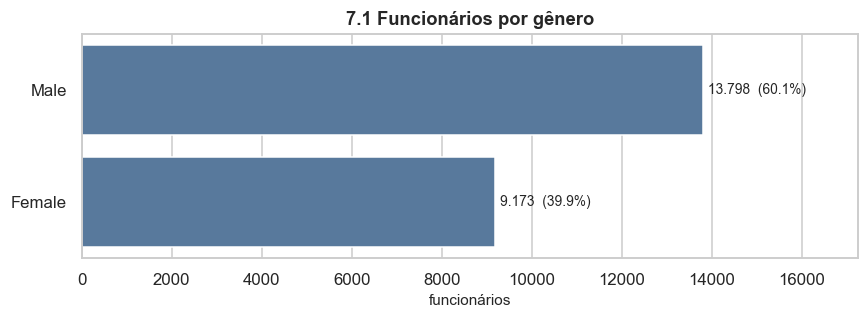

In [20]:
# value_counts() conta quantas vezes cada categoria aparece.
#   - sem argumento: devolve a CONTAGEM (frequência absoluta)
#   - normalize=True: devolve a PROPORÇÃO (frequência relativa)
contagem   = base["Gender"].value_counts()
proporcao  = base["Gender"].value_counts(normalize=True)

# Montamos as duas numa tabela só: é assim que a frequência se reporta.
tabela_genero = pd.DataFrame({"n": contagem, "%": (proporcao * 100).round(1)})
tabela_genero.index.name = "Gênero"
print(tabela_genero.to_string())
print(f"\nTotal (o denominador): {len(base):,} funcionários".replace(",", "."))

# O gráfico. countplot conta e desenha num passo só.
#   - y= em vez de x= deixa as barras HORIZONTAIS, e os rótulos legíveis
#   - order= fixa a ordem (da maior para a menor contagem)
fig, eixo = plt.subplots(figsize=(8, 3))
sns.countplot(data=base, y="Gender", order=contagem.index, color=COR_FICOU, ax=eixo)
eixo.set(title="7.1 Funcionários por gênero", xlabel="funcionários", ylabel="")

# Escrever o valor na ponta da barra: o leitor não deveria ter de estimar pelo eixo.
for i, valor in enumerate(contagem):
    eixo.text(valor + 120, i, f"{valor:,}".replace(",", ".") +
              f"  ({valor / len(base):.1%})", va="center", fontsize=9)
eixo.set_xlim(0, contagem.max() * 1.25)
plt.tight_layout()
plt.show()

**A leitura.** O quadro tem cerca de **13.700 homens (59,8%)** e **9.200 mulheres (40,2%)**.

**Insight.** A empresa é predominantemente masculina, numa proporção de aproximadamente 3 homens
para cada 2 mulheres. Esse é um dado de **composição**, e ele tem consequência metodológica imediata:
qualquer comparação entre gêneros adiante é feita sobre bases de tamanhos diferentes. Diferença de
tamanho de grupo não invalida a comparação — a taxa já é uma proporção —, mas afeta a **precisão**:
o grupo menor sempre terá intervalo de confiança mais largo.

**O que isso não diz.** Não diz nada sobre equidade. Composição desigual pode vir do mercado de
trabalho da área, do histórico de contratação ou de viés no processo seletivo, e esta contagem não
distingue as três hipóteses. Para falar de equidade é preciso olhar **salário, nível hierárquico e
promoção** por gênero — e isso é feito no passo 7.11.

## 7.2 Idade: a forma da distribuição

**O elemento.** A **distribuição** de uma variável contínua: onde está o centro, quão espalhados
estão os valores em volta dele, e se o espalhamento é simétrico ou puxado para um lado.

**O instrumento.** **Histograma** (barras de faixas de valor) com a curva de **densidade** por cima.
O histograma mostra a contagem em cada faixa; a densidade é a mesma informação suavizada, e serve
para enxergar a forma sem a interferência da largura das faixas. Use para variável contínua. Não use
para categórica.

**Por que as três medidas de centro aparecem juntas no gráfico.** Média, mediana e moda só coincidem
em distribuição perfeitamente simétrica. **A distância entre elas é a medida da assimetria**, e é
isso que o gráfico vai mostrar de uma vez.

média ... 37.1 anos
mediana . 36.0 anos
moda .... 35 anos

desvio-padrão ....... 9.1 anos
mínimo e máximo ..... 18 a 60 anos
amplitude ........... 42 anos


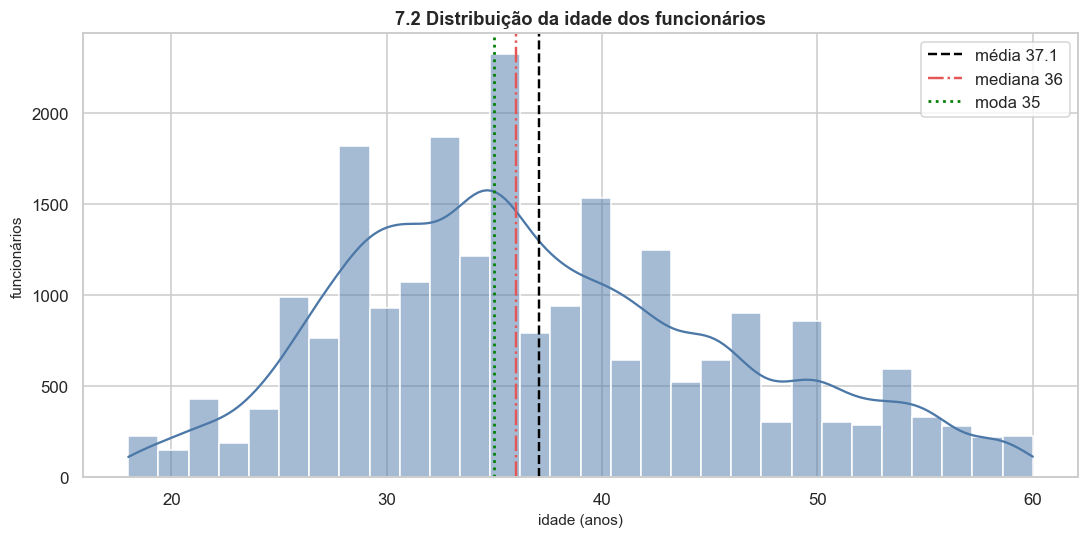

In [21]:
# As três medidas de tendência central, calculadas antes de desenhar:
media   = base["Age"].mean()      # soma dividida pelo número de casos
mediana = base["Age"].median()    # o valor que divide a distribuição em duas metades
moda    = base["Age"].mode()[0]   # o valor mais frequente ([0] porque pode haver empate)

print(f"média ... {media:.1f} anos")
print(f"mediana . {mediana:.1f} anos")
print(f"moda .... {moda:.0f} anos")
print(f"\ndesvio-padrão ....... {base['Age'].std():.1f} anos")
print(f"mínimo e máximo ..... {base['Age'].min()} a {base['Age'].max()} anos")
print(f"amplitude ........... {base['Age'].max() - base['Age'].min()} anos")

fig, eixo = plt.subplots(figsize=(10, 5))

# histplot com kde=True desenha o histograma E a curva de densidade.
# bins=30 define 30 faixas de idade; é a escolha do analista, e mudá-la muda a aparência.
sns.histplot(data=base, x="Age", bins=30, kde=True, color=COR_FICOU,
             edgecolor="white", ax=eixo)

# As três medidas, marcadas no eixo, para que a distância entre elas fique visível
eixo.axvline(media,   color="black",  linestyle="--", lw=1.6, label=f"média {media:.1f}")
eixo.axvline(mediana, color=COR_SAIU, linestyle="-.", lw=1.6, label=f"mediana {mediana:.0f}")
eixo.axvline(moda,    color="green",  linestyle=":",  lw=1.8, label=f"moda {moda:.0f}")

eixo.set(title="7.2 Distribuição da idade dos funcionários",
         xlabel="idade (anos)", ylabel="funcionários")
eixo.legend()
plt.tight_layout()
plt.show()

**A leitura.** Média **37,1**, mediana **36,0**, moda **35**. As três estão praticamente no mesmo
lugar, e a curva é quase simétrica, com uma leve cauda à direita (alguns funcionários próximos dos
60 anos). O desvio-padrão de **9,1 anos** diz que a maior parte do quadro está entre 28 e 46 anos,
e a amplitude total vai de 18 a 60.

**Insight.** **O quadro não é jovem.** Apenas 21,7% têm menos de 30 anos (calculado no passo 5.4), e
a idade típica é de 36 anos. Isso contraria a expectativa usual sobre empresas de tecnologia e muda a
interpretação do atrito: rotatividade de quadro maduro tem causas diferentes de rotatividade de
quadro de entrada. Num quadro jovem, atrito costuma ser exploração de mercado ("estou vendo
opções"); num quadro maduro, costuma ser insatisfação acumulada ou estagnação de carreira — e a ação
de retenção é outra.

**O que isso não diz.** Que a idade cause ou não a saída. Média e distribuição são descrição do
quadro, não comparação entre quem fica e quem sai. Essa comparação é o passo 8.13.

**A lição sobre as medidas de centro.** Quando média ≈ mediana ≈ moda, **qualquer uma das três
descreve bem o caso típico** e o relatório pode usar a média sem ressalva. Guarde este caso como
contraste: no passo 7.9 aparece uma variável em que elas se separam, e lá a escolha passa a importar.

## 7.3 A situação do vínculo: a variável que se quer explicar

**O elemento.** A **frequência da variável dependente** — e, com ela, a **taxa-base** do fenômeno.
Toda análise de um evento raro começa por saber **quão raro ele é**.

**O instrumento.** Barras, como em 7.1. O que muda não é o instrumento, é o **papel** da variável:
esta é a que se quer explicar, e a taxa que sai daqui é a régua de todas as comparações da Parte 8.

**Por que este é o passo mais importante da Parte 7.** Sem a taxa-base, nenhum número adiante tem
significado. Dizer "no setor X a saída é de 20%" não informa nada enquanto não se souber se a média
da empresa é 5% ou 40%. **A taxa-base transforma um número solto em comparação.**

                         n      %
situacao                         
Continua na empresa  19370 84.320
Pediu demissão        3601 15.680

TAXA-BASE DE SAÍDA VOLUNTÁRIA: 15.68%
Em números redondos: a cada 100 funcionários, cerca de 16 pediram demissão no período.
Equivalente em chance: 0.186 (aproximadamente 1 saída para cada 5.4 permanências)


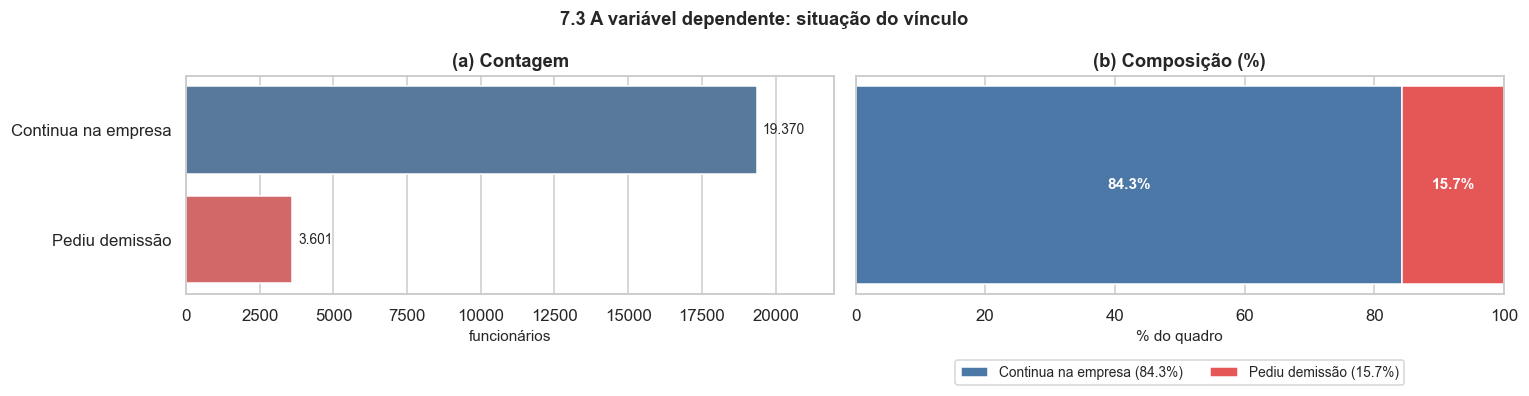

In [22]:
# Frequência da variável dependente, já na forma binária construída na Parte 6
tabela_situacao = pd.DataFrame({
    "n": base["situacao"].value_counts(),
    "%": (base["situacao"].value_counts(normalize=True) * 100).round(2),
})
print(tabela_situacao.to_string())

print(f"\nTAXA-BASE DE SAÍDA VOLUNTÁRIA: {taxa_global:.2%}")
print(f"Em números redondos: a cada 100 funcionários, cerca de "
      f"{taxa_global * 100:.0f} pediram demissão no período.")
print(f"Equivalente em chance: {taxa_global / (1 - taxa_global):.3f} "
      f"(aproximadamente 1 saída para cada {(1 - taxa_global) / taxa_global:.1f} permanências)")

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.2))

# (a) As contagens
sns.countplot(data=base, y="situacao", ax=eixos[0],
              order=["Continua na empresa", "Pediu demissão"],
              hue="situacao", palette=PALETA_ATRITO, legend=False)
eixos[0].set(title="(a) Contagem", xlabel="funcionários", ylabel="")
for i, valor in enumerate(base["situacao"].value_counts()
                          [["Continua na empresa", "Pediu demissão"]]):
    eixos[0].text(valor + 200, i, f"{valor:,}".replace(",", "."), va="center", fontsize=9)
eixos[0].set_xlim(0, 22000)

# (b) A mesma informação como barra única de composição: a forma de mostrar
#     uma proporção quando o que importa é a PARTE sobre o TODO.
acumulado = 0
for situacao in ["Continua na empresa", "Pediu demissão"]:
    fracao = (base["situacao"] == situacao).mean() * 100
    eixos[1].barh(0, fracao, left=acumulado, color=PALETA_ATRITO[situacao],
                  label=f"{situacao} ({fracao:.1f}%)")
    eixos[1].text(acumulado + fracao / 2, 0, f"{fracao:.1f}%", ha="center",
                  va="center", color="white", fontweight="bold")
    acumulado += fracao
eixos[1].set(title="(b) Composição (%)", xlabel="% do quadro", yticks=[], xlim=(0, 100))
eixos[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.45), ncol=2, fontsize=9)

fig.suptitle("7.3 A variável dependente: situação do vínculo", fontweight="bold")
plt.tight_layout()
plt.show()

**A leitura.** **19.370 funcionários continuam (84,3%)** e **3.601 pediram demissão (15,7%)**.

**Insight.** A taxa de saída voluntária é de **15,7%**. Esse número é, por si, um diagnóstico: uma
rotatividade voluntária nessa ordem significa que a empresa substitui cerca de um sexto do quadro por
período — com todo o custo de recrutar, treinar e esperar a produtividade plena, que é quantificado
na Parte 11.

**A consequência metodológica, que volta três vezes neste notebook.** As classes são
**desbalanceadas**: 84% contra 16%. Isso significa que **um modelo que preveja "ninguém sai" para
todo mundo acerta 84% dos casos** — e é completamente inútil. Por isso, na Parte 9, a acurácia não
será a métrica principal. Guarde a barra (b): ela é a imagem do problema.

**O que isso não diz.** Não diz se 15,7% é muito ou pouco. Para isso seria preciso comparar com o
setor, com a região e com a série histórica da própria empresa — nenhum dos três está nesta base. É
uma limitação a declarar no relatório, não a esconder.

## 7.4 Departamento, cargo e canal de recrutamento: onde está o volume

**O elemento.** Frequência em variável categórica com **mais categorias**, e a diferença entre
categoria grande e categoria pequena.

**O instrumento.** Barras horizontais ordenadas da maior para a menor. A ordenação é deliberada:
com nove cargos, a ordem alfabética obriga o leitor a procurar, e a ordem por tamanho entrega a
hierarquia de imediato. **Variável nominal se ordena por frequência; variável ordinal, nunca** — em
ordinal, a ordem da escala *é* a informação (isso aparece no passo 8.9).

**Por que estes três juntos.** São as três variáveis estruturais do quadro, e todas voltam na
Parte 8 como possíveis fatores de atrito. Aqui interessa apenas o **tamanho** de cada grupo, por uma
razão prática: **taxa calculada sobre grupo pequeno é instável**, e saber de antemão quais grupos são
pequenos evita conclusão apressada depois.

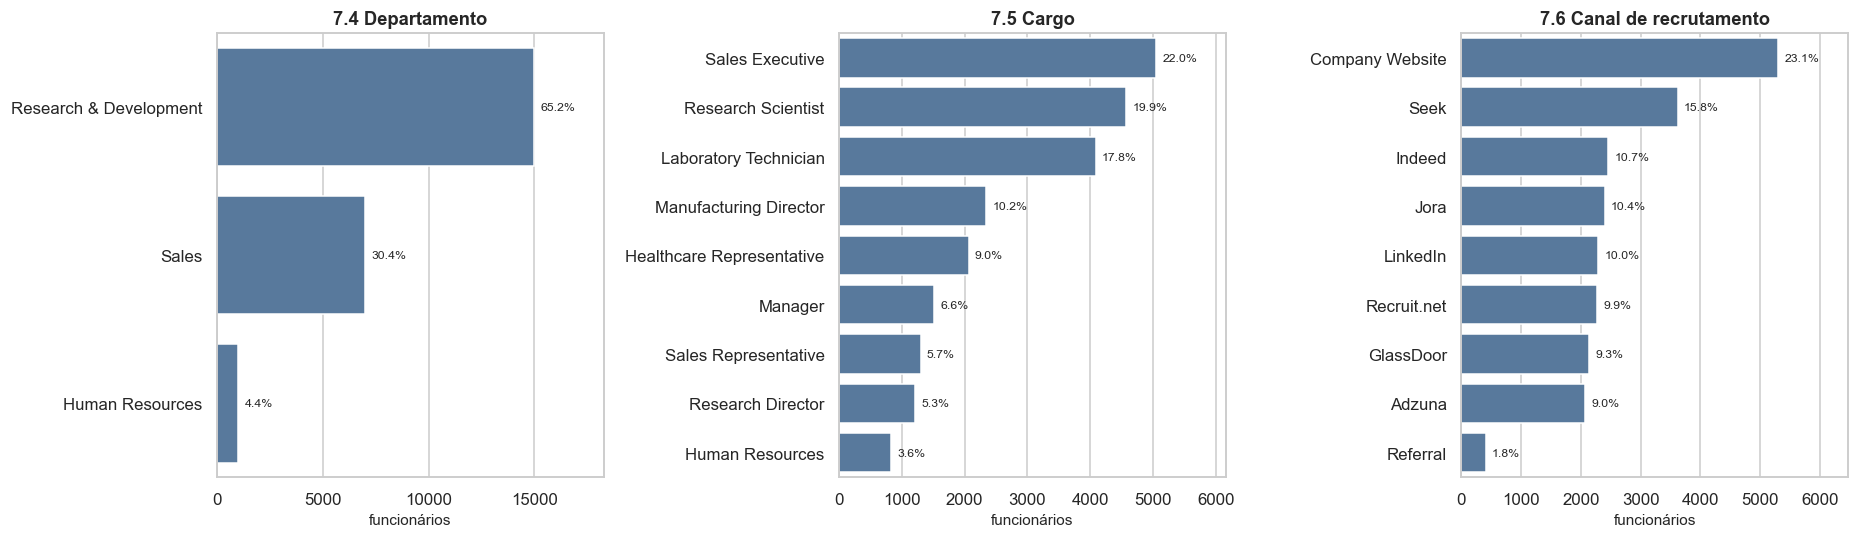

TAMANHO DOS GRUPOS, E QUAIS EXIGEM CAUTELA

--- 7.4 Departamento ---
                            n      %  saídas esperadas na taxa-base cautela
Department                                                                 
Research & Development  14977 65.200                           2348        
Sales                    6984 30.400                           1095        
Human Resources          1010  4.400                            158        

--- 7.5 Cargo ---
                              n      %  saídas esperadas na taxa-base        cautela
JobRole                                                                             
Sales Executive            5051 22.000                            792               
Research Scientist         4576 19.900                            717               
Laboratory Technician      4088 17.800                            641               
Manufacturing Director     2338 10.200                            367               
Healthcare Representat

In [23]:
variaveis_estruturais = [
    ("Department",     "7.4 Departamento"),
    ("JobRole",        "7.5 Cargo"),
    ("EmployeeSource", "7.6 Canal de recrutamento"),
]

fig, eixos = plt.subplots(1, 3, figsize=(17, 5))

for eixo, (coluna, titulo) in zip(eixos, variaveis_estruturais):
    ordem = base[coluna].value_counts().index          # da maior para a menor
    sns.countplot(data=base, y=coluna, order=ordem, color=COR_FICOU, ax=eixo)
    eixo.set(title=titulo, xlabel="funcionários", ylabel="")

    # O percentual ao lado da barra, porque contagem sozinha não dá noção de participação
    for i, categoria in enumerate(ordem):
        n = (base[coluna] == categoria).sum()
        eixo.text(n + base[coluna].value_counts().max() * 0.02, i,
                  f"{n / len(base):.1%}", va="center", fontsize=8)
    eixo.set_xlim(0, base[coluna].value_counts().max() * 1.22)

plt.tight_layout()
plt.show()

# A tabela completa, com destaque para os grupos pequenos
print("TAMANHO DOS GRUPOS, E QUAIS EXIGEM CAUTELA\n")
for coluna, titulo in variaveis_estruturais:
    tabela = pd.DataFrame({
        "n": base[coluna].value_counts(),
        "%": (base[coluna].value_counts(normalize=True) * 100).round(1),
    })
    # Com taxa de saída de ~16%, um grupo de 400 pessoas tem só ~64 saídas:
    # é com esse número que a taxa do grupo será estimada.
    tabela["saídas esperadas na taxa-base"] = (tabela["n"] * taxa_global).round(0).astype(int)
    tabela["cautela"] = np.where(tabela["n"] < 1000, "grupo pequeno", "")
    print(f"--- {titulo} ---")
    print(tabela.to_string())
    print()

**A leitura.** **Research & Development** concentra 14.977 pessoas (65,2% do quadro), **Sales** tem
6.984 (30,4%) e **Human Resources**, 1.010 (4,4%). Entre os cargos, `Sales Executive`,
`Research Scientist` e `Laboratory Technician` são os maiores. Entre os canais de recrutamento, o
site da empresa responde por 23% das contratações, e **indicação (`Referral`) por apenas 409 pessoas
(1,8%)**.

**Insight.** O quadro é fortemente concentrado em P&D, e a estrutura de cargos reflete uma empresa de
base técnica. Para a gestão, isso define onde uma ação de RH alcança mais gente: qualquer política
aplicada a P&D atinge dois terços do quadro.

**O alerta que este passo existe para dar.** A coluna "saídas esperadas na taxa-base" mostra o
problema de frente: no canal de indicação, com 409 pessoas, espera-se cerca de **64 saídas**. Uma
taxa estimada sobre 64 eventos oscila muito — basta uma dezena de casos a mais ou a menos para a taxa
mudar vários pontos percentuais. **É por isso que, na Parte 8, nenhuma taxa será apresentada sem o n
e sem o intervalo de confiança ao lado.** Grupo pequeno não é motivo para excluir a categoria da
análise; é motivo para não construir recomendação sobre ela.

**O que isso não diz.** Nada sobre atrito. Departamento grande não é departamento problemático: é
departamento grande. A confusão entre **volume** e **taxa** é o erro de leitura mais comum em
relatório de RH, e o passo 8.4 mostra o caso concreto.

## 7.7 Escolaridade por área de formação: contagem e composição

**O elemento.** O **cruzamento de duas variáveis categóricas** — a tabela de dupla entrada, ou
tabela de contingência. É o primeiro passo em que duas variáveis aparecem juntas, e ele introduz a
distinção que organiza toda a Parte 8.

**O instrumento.** Barras **empilhadas**, em duas versões da mesma tabela: em contagem e em
percentual de cada linha. As duas respondem perguntas diferentes, e é por isso que aparecem lado a
lado.

**A distinção, que vale para o resto do notebook.**

| Versão | Responde | Serve para |
|---|---|---|
| **Contagem** | Onde está o volume de pessoas? | Decidir onde uma ação alcança mais gente |
| **Composição (%)** | Qual é o perfil de cada grupo? | Comparar grupos de **tamanhos diferentes** em pé de igualdade |

Uma área pode ter o maior número absoluto de mestres e, ao mesmo tempo, a menor proporção de mestres,
simplesmente por ser grande. Toda vez que alguém disser "a área X tem mais Y", a primeira pergunta é:
**mais em número ou mais em proporção?**

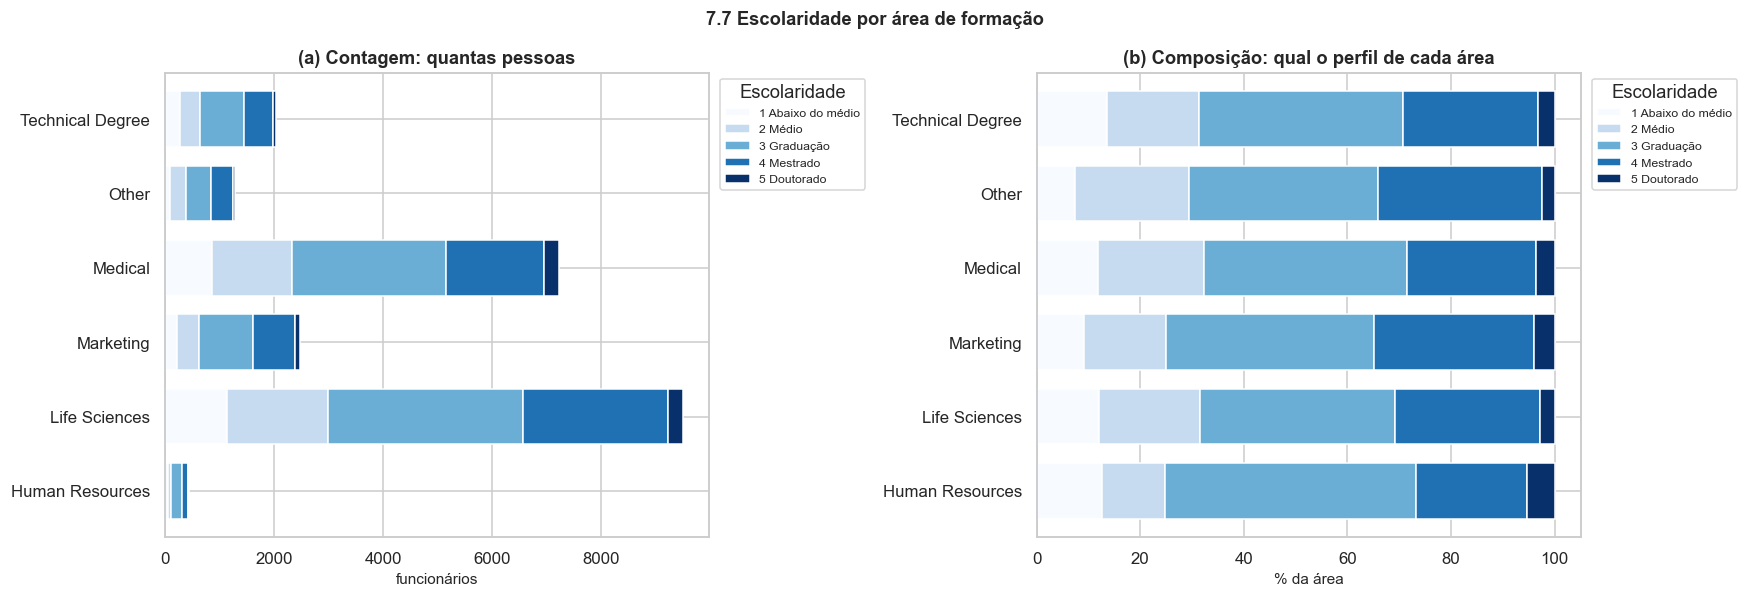

Contagem (linhas = escolaridade, colunas = área de formação):

EducationField     Human Resources  Life Sciences  Marketing  Medical  Other  Technical Degree
Education                                                                                     
1 Abaixo do médio               56           1146        226      857     96               278
2 Médio                         54           1854        393     1472    284               364
3 Graduação                    214           3571       1001     2828    471               805
4 Mestrado                      94           2656        764     1794    408               531
5 Doutorado                     24            267        100      264     32                67


Composição de cada área, em % (cada linha soma 100):

Education         1 Abaixo do médio  2 Médio  3 Graduação  4 Mestrado  5 Doutorado
EducationField                                                                    
Human Resources              12.700   12.200      

In [24]:
# crosstab monta a tabela de dupla entrada: linhas x colunas, com a contagem na célula.
cruzada = pd.crosstab(
    base["Education"].map(ROTULOS["Education"]),   # linhas: escolaridade com rótulo
    base["EducationField"],                        # colunas: área de formação
)

fig, eixos = plt.subplots(1, 2, figsize=(16, 5.5))

# (a) CONTAGEM. .T transpõe para que cada barra seja uma ÁREA, empilhada por escolaridade.
cruzada.T.plot(kind="barh", stacked=True, ax=eixos[0], colormap="Blues", width=0.75)
eixos[0].set(title="(a) Contagem: quantas pessoas", xlabel="funcionários", ylabel="")
eixos[0].legend(title="Escolaridade", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)

# (b) COMPOSIÇÃO. div(soma da linha, axis=0) divide cada célula pelo total da sua linha,
#     de modo que cada barra soma 100% e as áreas ficam comparáveis entre si.
composicao = cruzada.T.div(cruzada.T.sum(axis=1), axis=0) * 100
composicao.plot(kind="barh", stacked=True, ax=eixos[1], colormap="Blues", width=0.75)
eixos[1].set(title="(b) Composição: qual o perfil de cada área", xlabel="% da área", ylabel="")
eixos[1].legend(title="Escolaridade", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)

fig.suptitle("7.7 Escolaridade por área de formação", fontweight="bold")
plt.tight_layout()
plt.show()

print("Contagem (linhas = escolaridade, colunas = área de formação):\n")
print(cruzada.to_string())
print("\n\nComposição de cada área, em % (cada linha soma 100):\n")
print(composicao.round(1).to_string())

**A leitura.** `Life Sciences` e `Medical` concentram o volume de pessoas — é o que o gráfico (a)
mostra. Mas o gráfico (b) mostra que o **perfil educacional é parecido entre as áreas**: em todas
elas, graduação é a categoria dominante, seguida de mestrado, com proporções próximas.

**Insight.** O perfil de qualificação é **homogêneo entre as áreas de formação**. Isso é informação
útil por descartar uma hipótese: não há uma área que concentre pós-graduação e outra que concentre
ensino médio. Consequência para a modelagem: escolaridade e área de formação carregam informações
**pouco redundantes** entre si, e ambas podem entrar no modelo sem que uma anule a outra.

**O que isso não diz.** Nada sobre desempenho ou sobre saída. E atenção a uma armadilha: a área de
formação é a **formação**, não a **função**. Alguém formado em `Life Sciences` pode estar em vendas.
O cruzamento entre formação e cargo é outro, e está no passo 7.13.

## 7.8 As seis dimensões do tempo: quando a média deixa de servir

**O elemento.** **Assimetria** (ou enviesamento) da distribuição, e a consequência dela para a
escolha da medida de centro. Este é o item em que a decisão entre média e mediana deixa de ser
detalhe.

**O instrumento.** Uma **grade de histogramas**, todos na mesma figura. A grade existe porque as seis
variáveis medem a mesma coisa — tempo, em anos — por recortes diferentes, e é a comparação entre elas
que produz o insight. Seis gráficos soltos em seis células não deixariam ver o padrão comum.

**O que se procura.** Em distribuição simétrica, média e mediana coincidem. Em distribuição com
**cauda à direita** (muitos valores baixos e poucos muito altos), a média é puxada pela cauda e passa
a descrever mal o caso típico. A linha tracejada vermelha do gráfico é a mediana; a preta, a média.
**A distância entre as duas é a assimetria, visível a olho nu.**

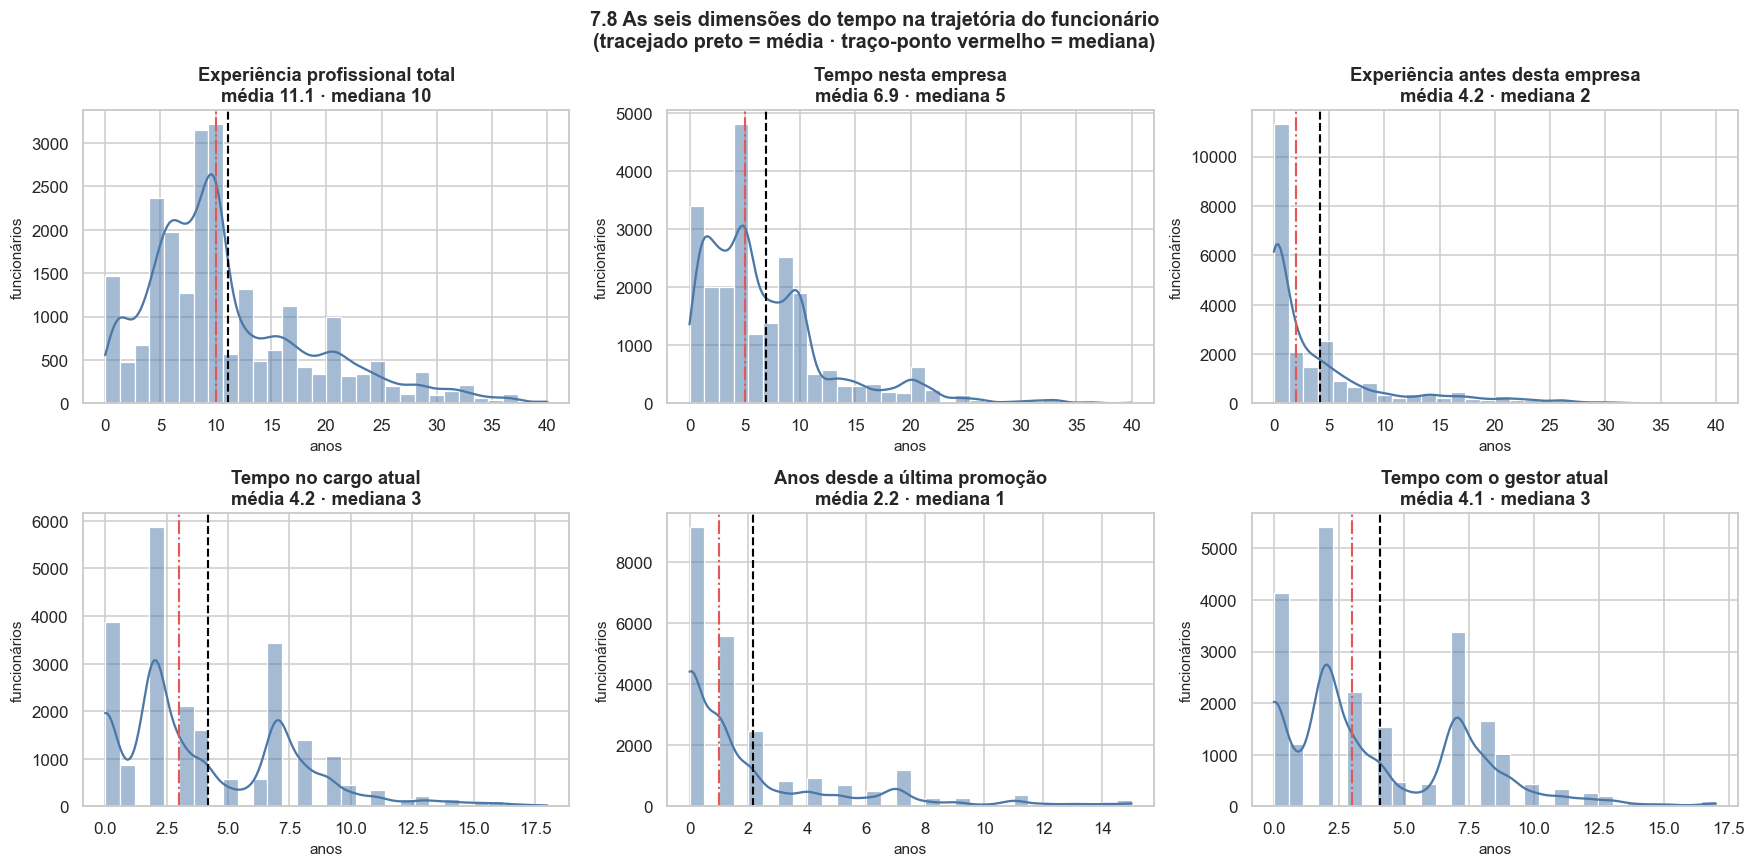

A assimetria medida, não só olhada:

                                 média  mediana  média / mediana  assimetria  máximo
variável                                                                            
Experiência profissional total  11.100   10.000            1.110       1.110      40
Tempo nesta empresa              6.900    5.000            1.380       1.710      40
Experiência antes desta empresa  4.200    2.000            2.080       2.040      40
Tempo no cargo atual             4.200    3.000            1.400       0.920      18
Anos desde a última promoção     2.200    1.000            2.170       2.000      15
Tempo com o gestor atual         4.100    3.000            1.370       0.840      17

Leitura da coluna 'assimetria': 0 = simétrica; acima de 1 = cauda à direita forte.


In [25]:
variaveis_tempo = [
    ("TotalWorkingYears",       "Experiência profissional total"),
    ("YearsAtCompany",          "Tempo nesta empresa"),
    ("PriorYearsOfExperience",  "Experiência antes desta empresa"),
    ("YearsInCurrentRole",      "Tempo no cargo atual"),
    ("YearsSinceLastPromotion", "Anos desde a última promoção"),
    ("YearsWithCurrManager",    "Tempo com o gestor atual"),
]

fig, eixos = plt.subplots(2, 3, figsize=(16, 8))

resumo_tempo = []
for eixo, (coluna, titulo) in zip(eixos.ravel(), variaveis_tempo):
    sns.histplot(data=base, x=coluna, bins=30, kde=True,
                 color=COR_FICOU, ax=eixo, edgecolor="white")
    media_v   = base[coluna].mean()
    mediana_v = base[coluna].median()
    eixo.axvline(media_v,   color="black",  linestyle="--", lw=1.4)
    eixo.axvline(mediana_v, color=COR_SAIU, linestyle="-.", lw=1.4)
    eixo.set(title=f"{titulo}\nmédia {media_v:.1f} · mediana {mediana_v:.0f}",
             xlabel="anos", ylabel="funcionários")

    # skew() mede a assimetria: 0 = simétrica, positiva = cauda à direita
    resumo_tempo.append({
        "variável": titulo,
        "média": round(media_v, 1),
        "mediana": mediana_v,
        "média / mediana": round(media_v / mediana_v, 2) if mediana_v else np.nan,
        "assimetria": round(base[coluna].skew(), 2),
        "máximo": base[coluna].max(),
    })

fig.suptitle("7.8 As seis dimensões do tempo na trajetória do funcionário\n"
             "(tracejado preto = média · traço-ponto vermelho = mediana)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("A assimetria medida, não só olhada:\n")
print(pd.DataFrame(resumo_tempo).set_index("variável").to_string())
print("\nLeitura da coluna 'assimetria': 0 = simétrica; acima de 1 = cauda à direita forte.")

**A leitura.** As seis distribuições são **assimétricas à direita**, e a coluna de assimetria
confirma o que o olho vê. `YearsSinceLastPromotion` é o caso extremo: mediana de 1 ano, média de
2,2 anos, máximo de 15 — a média é mais que o dobro da mediana.

**Insight 1 — sobre o quadro.** Há **muita gente com pouco tempo** de casa, de cargo e de gestor. Um
quadro assim é compatível com duas histórias opostas: empresa em expansão (contratou muito
recentemente) ou empresa que se renova rápido (perde e repõe). As duas se distinguem olhando a taxa
de saída por faixa de tempo de casa — e é o que o passo 8.14 faz.

**Insight 2 — sobre quem está na cauda.** Em `YearsSinceLastPromotion`, a cauda vai até 15 anos.
Esse é um grupo **pequeno e identificável**: quem está há muitos anos sem promoção. É o perfil
clássico de risco de saída por estagnação, e por ser pequeno cabe numa ação de RH nominal, caso por
caso. **A cauda de uma distribuição assimétrica costuma ser onde está o problema gerenciável.**

**Insight 3 — a lição estatística, que é a mais importante.** Em todas as seis, **a média é maior que
a mediana**. Reportar "o tempo médio de empresa é de 6,9 anos" descreve mal o caso típico, porque a
média está inflada pelos poucos funcionários de 30 e 40 anos de casa. **A frase correta para o
relatório é com mediana:** "metade dos funcionários está na empresa há 5 anos ou menos". Esta é a
regra prática: *distribuição assimétrica, use mediana; simétrica, a média serve* — compare com o
passo 7.2, em que a idade era simétrica e a média servia.

**O que isso não diz.** Os picos em valores redondos (5, 10, 20 anos) sugerem arredondamento na
origem do dado. Não impede a análise, mas é uma nota de rodapé obrigatória: a variável de tempo tem
granularidade grosseira.

## 7.9 O boxplot: a anatomia do instrumento

**O elemento.** Os **cinco números** que resumem uma distribuição (mínimo, 1º quartil, mediana,
3º quartil, máximo), a **amplitude interquartil** e o critério para chamar um valor de **atípico**.

**O instrumento.** O **boxplot**. É o gráfico mais usado em análise de dados organizacionais e o mais
mal lido, porque quase ninguém aprende a anatomia dele. Este passo existe para isso: desmontar o
boxplot **uma vez**, com os números ao lado, para que os oito boxplots seguintes sejam lidos sem
esforço.

**Para que serve.** Comparar a distribuição de uma variável numérica **entre grupos**, lado a lado.
É imbatível nisso: mostra, de uma vez, o centro, a dispersão, a assimetria e os casos extremos de
cada grupo.

**Quando não usar.** Quando a distribuição tem **dois picos** (bimodal) — o boxplot a mostraria como
se fosse uma só concentração, escondendo a informação mais importante. Nesse caso, use histograma ou
violino. E quando o grupo tem pouquíssimos casos: um boxplot sobre 8 observações sugere precisão que
não existe.

**Como se lê**, de dentro para fora:

| Elemento | O que é | O que significa |
|---|---|---|
| Linha dentro da caixa | **Mediana** (Q2) | O valor do meio: metade está abaixo, metade acima |
| Base da caixa | **1º quartil** (Q1) | 25% dos casos estão abaixo deste valor |
| Topo da caixa | **3º quartil** (Q3) | 75% dos casos estão abaixo; 25% acima |
| Altura da caixa | **Amplitude interquartil** (IQR = Q3 − Q1) | Onde estão os **50% centrais**. É a medida de dispersão do boxplot |
| Hastes (*whiskers*) | Até 1,5 × IQR além da caixa | O alcance dos valores "normais" |
| Pontos soltos | **Atípicos** (*outliers*) | Casos além das hastes. Não são erro: são casos a investigar |
| Mediana descentrada na caixa | **Assimetria** | Mediana perto da base = cauda à direita |

OS CINCO NÚMEROS DE MonthlyIncome

mínimo .................. R$    1.009
1º quartil (Q1) ......... R$    2.909
mediana (Q2) ............ R$    4.898
3º quartil (Q3) ......... R$    8.120
máximo .................. R$   19.999

amplitude interquartil .. R$    5.211  (onde estão os 50% centrais)
limite das hastes ....... R$ 1.009 a R$ 15.936
atípicos ................ 1.889 funcionários (8.2% da base)

média ................... R$    6.418
média - mediana ......... R$    1.520   <- a assimetria. em reais


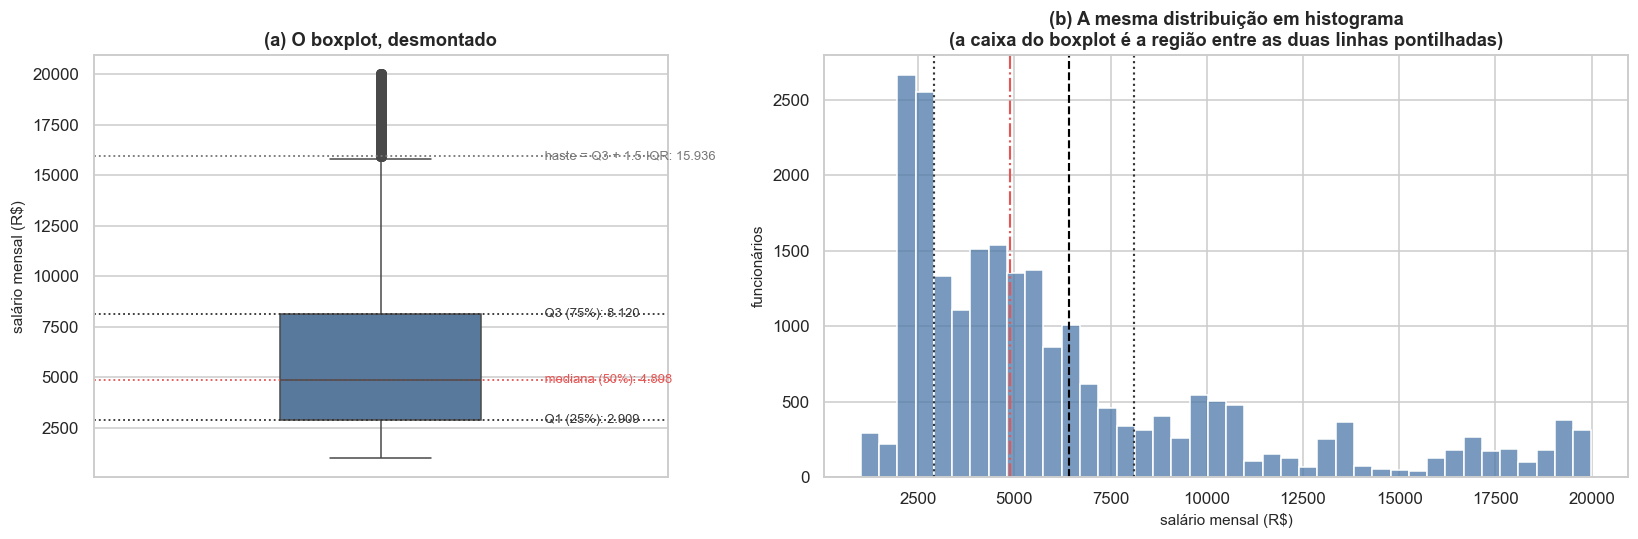

In [26]:
# Desmontando o boxplot do salário mensal, com os números impressos ao lado do desenho.
coluna = "MonthlyIncome"

q1      = base[coluna].quantile(0.25)
mediana = base[coluna].quantile(0.50)
q3      = base[coluna].quantile(0.75)
iqr     = q3 - q1                      # amplitude interquartil
limite_inferior = q1 - 1.5 * iqr       # fim da haste de baixo
limite_superior = q3 + 1.5 * iqr       # fim da haste de cima
atipicos = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

print(f"OS CINCO NÚMEROS DE {coluna}\n")
print(f"mínimo .................. R$ {base[coluna].min():>8,.0f}".replace(",", "."))
print(f"1º quartil (Q1) ......... R$ {q1:>8,.0f}".replace(",", "."))
print(f"mediana (Q2) ............ R$ {mediana:>8,.0f}".replace(",", "."))
print(f"3º quartil (Q3) ......... R$ {q3:>8,.0f}".replace(",", "."))
print(f"máximo .................. R$ {base[coluna].max():>8,.0f}".replace(",", "."))
print(f"\namplitude interquartil .. R$ {iqr:>8,.0f}  (onde estão os 50% centrais)"
      .replace(",", "."))
print(f"limite das hastes ....... R$ {max(limite_inferior, base[coluna].min()):,.0f} "
      f"a R$ {limite_superior:,.0f}".replace(",", "."))
print(f"atípicos ................ {len(atipicos):,} funcionários "
      f"({len(atipicos) / len(base):.1%} da base)".replace(",", "."))
print(f"\nmédia ................... R$ {base[coluna].mean():>8,.0f}".replace(",", "."))
print(f"média - mediana ......... R$ {base[coluna].mean() - mediana:>8,.0f}"
      "   <- a assimetria, em reais".replace(",", "."))

fig, eixos = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.4]})

# (a) O boxplot anotado
sns.boxplot(y=base[coluna], ax=eixos[0], color=COR_FICOU, width=0.35)
for valor, rotulo, cor in [(q1, "Q1 (25%)", "#333"), (mediana, "mediana (50%)", COR_SAIU),
                           (q3, "Q3 (75%)", "#333"), (limite_superior, "haste = Q3 + 1,5·IQR", "#777")]:
    eixos[0].axhline(valor, color=cor, linestyle=":", lw=1.2)
    eixos[0].text(0.28, valor, f" {rotulo}: {valor:,.0f}".replace(",", "."),
                  va="center", fontsize=8.5, color=cor)
eixos[0].set(title="(a) O boxplot, desmontado", ylabel="salário mensal (R$)", xlabel="")

# (b) O histograma da MESMA variável, para mostrar o que o boxplot resume
sns.histplot(base[coluna], bins=40, color=COR_FICOU, edgecolor="white", ax=eixos[1])
for valor, cor, estilo in [(q1, "#333", ":"), (mediana, COR_SAIU, "-."),
                           (q3, "#333", ":"), (base[coluna].mean(), "black", "--")]:
    eixos[1].axvline(valor, color=cor, linestyle=estilo, lw=1.4)
eixos[1].set(title="(b) A mesma distribuição em histograma\n"
                   "(a caixa do boxplot é a região entre as duas linhas pontilhadas)",
             xlabel="salário mensal (R$)", ylabel="funcionários")

plt.tight_layout()
plt.show()

**A leitura.** Mediana de **R$ 4.898** e média de **R$ 6.418**: a média é **R$ 1.520 maior** que a
mediana. A caixa vai de R$ 2.909 (Q1) a R$ 8.120 (Q3), de modo que os **50% centrais** do quadro
ganham entre esses dois valores — uma amplitude interquartil de R$ 5.211. A haste superior termina
em R$ 15.936, e **1.889 funcionários (8,2% do quadro)** estão acima disso: são os atípicos.

**Insight.** A distribuição salarial é **fortemente assimétrica à direita**, como quase toda
distribuição de renda: muitos ganham pouco, poucos ganham muito. Para o relatório, a consequência é
direta: **"o salário médio é de R$ 6.418" dá uma impressão errada do quadro**. Metade dos
funcionários ganha R$ 4.898 ou menos. A frase honesta usa a mediana, e menciona a média só para
evidenciar a assimetria.

**Sobre os atípicos.** Os pontos acima da haste **não são erro de digitação** nem devem ser
removidos: são os cargos de direção. Num boxplot de salário, atípico alto é a estrutura hierárquica
aparecendo. A regra é: **investigue o atípico antes de qualquer coisa**; remover sem investigar é
apagar justamente a informação mais interessante. Compare com o passo 4.7, onde as checagens de
consistência procuravam atípicos **impossíveis** — esses, sim, seriam para corrigir.

**Por que o gráfico (b) está ali.** Para mostrar que o boxplot é um **resumo** do histograma. A caixa
é a região central; as hastes são o alcance; os pontos são a cauda. Quem entende essa
correspondência não lê boxplot errado nunca mais — e ganha a capacidade de desconfiar: se a
distribuição tivesse dois picos, o histograma mostraria e o boxplot esconderia.

## 7.10 Primeiro uso do boxplot: salário mais alto traz mais satisfação?

**O elemento.** Comparação de uma variável **numérica** entre os níveis de uma variável **ordinal**.
É o desenho mais comum em pesquisa de clima organizacional.

**O instrumento.** Boxplots lado a lado, um por nível da escala, na **ordem da escala**. A ordem é
obrigatória aqui: é ela que permite ver se existe **gradiente** — a resposta muda de forma
consistente conforme a satisfação sobe?

**A hipótese sob teste.** Senso comum de gestão: paga-se mais, as pessoas ficam mais satisfeitas.
Se for verdade, as caixas devem subir da esquerda para a direita.

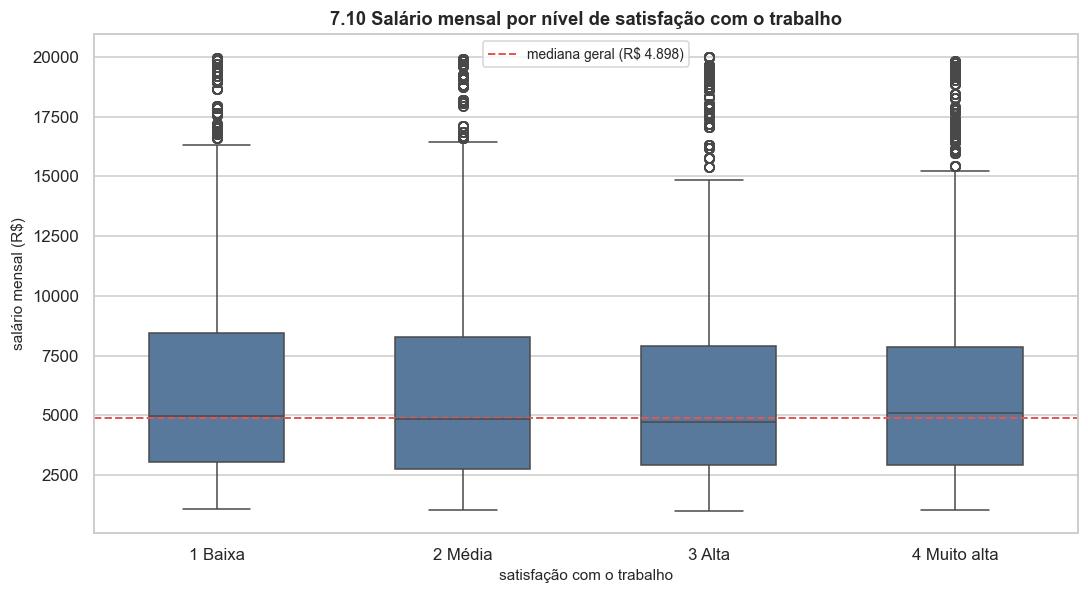

                         n   mediana     média        Q1        Q3
_JobSatisfaction_rot                                              
1 Baixa               4543 4,968.000 6,525.000 3,065.000 8,463.000
2 Média               4355 4,841.000 6,438.000 2,766.000 8,268.000
3 Alta                6914 4,739.000 6,353.000 2,909.000 7,880.000
4 Muito alta          7159 5,079.000 6,401.000 2,926.000 7,847.000

Diferença entre a MAIOR e a MENOR mediana: R$ 340
Como fração da mediana geral: 6.9%


In [27]:
# rotular() troca o código 1-4 pelo rótulo e PRESERVA a ordem da escala
base["_JobSatisfaction_rot"] = rotular(base["JobSatisfaction"])

fig, eixo = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=base, x="_JobSatisfaction_rot", y="MonthlyIncome",
            color=COR_FICOU, width=0.55, ax=eixo)

# A linha da mediana geral, como régua de comparação entre os grupos
eixo.axhline(base["MonthlyIncome"].median(), color=COR_SAIU, linestyle="--", lw=1.3,
             label=f"mediana geral (R$ {base['MonthlyIncome'].median():,.0f})".replace(",", "."))
eixo.set(title="7.10 Salário mensal por nível de satisfação com o trabalho",
         xlabel="satisfação com o trabalho", ylabel="salário mensal (R$)")
eixo.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Os números por trás das caixas. Mediana E média, para que a comparação não dependa
# de uma só medida, mais o n de cada grupo.
tabela = (base.groupby("_JobSatisfaction_rot", observed=True)["MonthlyIncome"]
          .agg(n="size", mediana="median", média="mean", Q1=lambda s: s.quantile(.25),
               Q3=lambda s: s.quantile(.75)))
print(tabela.round(0).to_string())

amplitude_medianas = tabela["mediana"].max() - tabela["mediana"].min()
print(f"\nDiferença entre a MAIOR e a MENOR mediana: R$ {amplitude_medianas:,.0f}"
      .replace(",", "."))
print(f"Como fração da mediana geral: {amplitude_medianas / base['MonthlyIncome'].median():.1%}")

**A leitura.** As quatro caixas estão **praticamente na mesma altura**. As medianas vão de
R$ 4.739 a R$ 5.079: a diferença entre a maior e a menor é de **R$ 340**, ou 6,9% da mediana geral
— contra uma amplitude interquartil de mais de R$ 5.000 **dentro** de cada grupo. As caixas se
sobrepõem quase inteiramente. E repare que a maior mediana está no nível 4, mas a segunda maior
está no nível **1**: não há sequer ordem.

**Insight.** **Não há sinal de que salário mais alto traga mais satisfação com o trabalho.** A
hipótese do senso comum não se sustenta nesta base. Para a gestão, essa é uma informação de alto
valor e contraintuitiva: aumentar salário é a alavanca mais cara de que o RH dispõe, e aqui ela
**não** aparece associada à satisfação declarada. Se o objetivo for satisfação, o dinheiro
provavelmente rende mais aplicado em outra coisa — e os passos 8.9 a 8.11 mostram em quê.

**O que isso não diz, e aqui a ressalva é essencial.** Três limites:

1. **Não diz que salário é irrelevante.** Diz que ele não se associa à *satisfação declarada*.
   Salário pode muito bem se associar à **saída** — que é outra variável, e o passo 8.12 a examina.
   Satisfação e permanência não são a mesma coisa.
2. **Comparação sem controle.** Quem ganha mais tem cargo mais alto, mais responsabilidade e,
   possivelmente, mais pressão. O efeito do salário pode estar sendo cancelado pelo efeito da
   pressão. Separar os dois exige o modelo multivariado da Parte 9.
3. **Satisfação é autodeclarada**, numa escala de quatro pontos, possivelmente respondida com medo
   de identificação. A medida tem ruído, e ruído na variável **atenua** qualquer associação real.

**A lição sobre o instrumento.** Este passo mostra o boxplot fazendo o que ele faz melhor:
**descartar uma hipótese rapidamente**. Caixas sobrepostas significam grupos indistinguíveis, e isso
se vê em dois segundos — sem teste, sem modelo. O resultado nulo é um achado, e deve ser reportado.

## 7.11 Dois usos seguidos do boxplot: equilíbrio trabalho-vida e equidade salarial

**O elemento.** O mesmo de 7.10 — numérica comparada entre grupos —, agora aplicado a duas perguntas
de gestão diferentes, para mostrar que **o mesmo instrumento responde perguntas de naturezas
distintas**: uma de diagnóstico de clima, outra de equidade.

**As duas hipóteses.**

1. Quem avalia mal o equilíbrio trabalho-vida está, também, entre os que ganham menos? Se sim, é um
   problema duplo e concentrado: baixa remuneração **e** sobrecarga.
2. Há diferença salarial entre homens e mulheres? Esta pergunta é obrigatória em qualquer diagnóstico
   de RH, e o instrumento para começar a respondê-la é exatamente este.

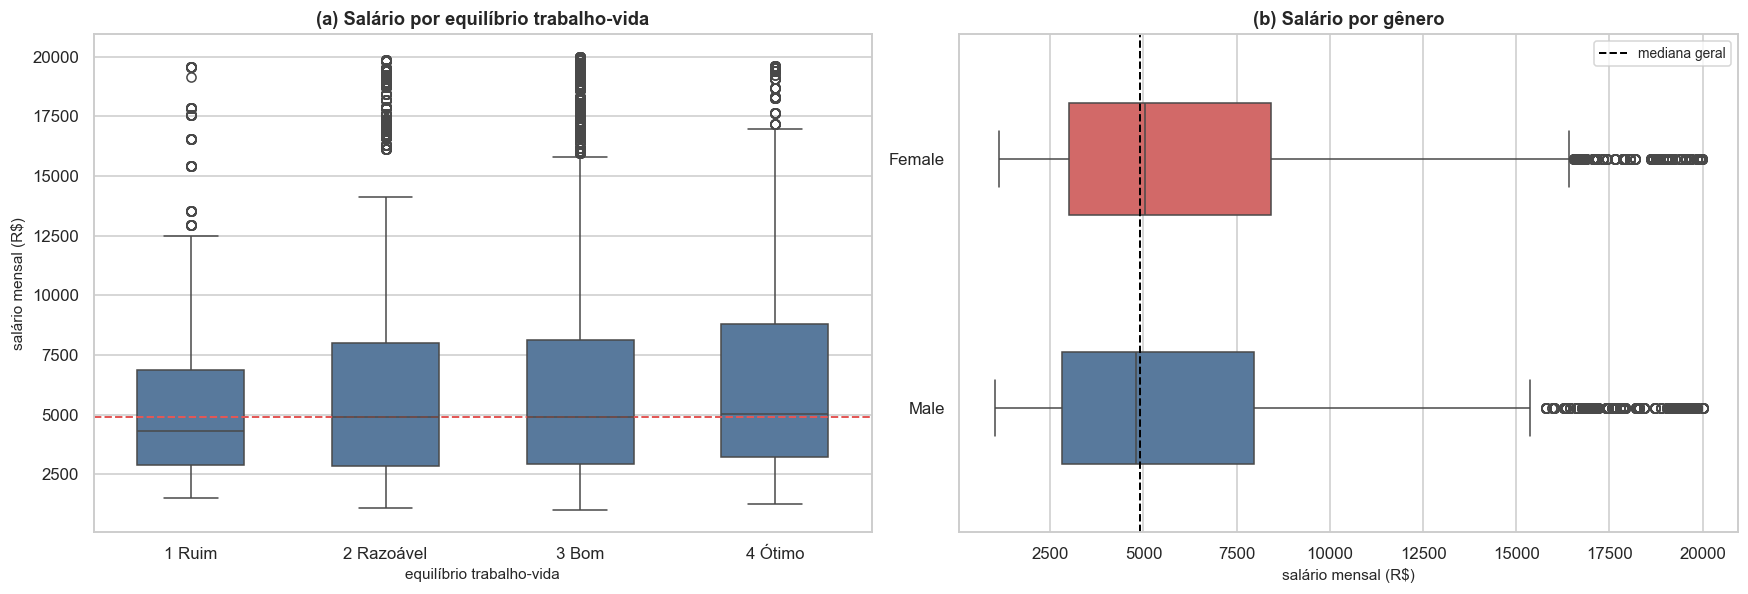

(a) SALÁRIO POR EQUILÍBRIO TRABALHO-VIDA

                          n   mediana     média
_WorkLifeBalance_rot                           
1 Ruim                 1255 4,306.000 5,929.000
2 Razoável             5359 4,907.000 6,335.000
3 Bom                 13960 4,907.000 6,451.000
4 Ótimo                2397 5,006.000 6,666.000


(b) SALÁRIO POR GÊNERO

            n   mediana     média        Q1        Q3
Gender                                               
Female   9173 5,042.000 6,592.000 2,994.000 8,412.000
Male    13798 4,805.000 6,302.000 2,819.000 7,969.000

Diferença de mediana entre os dois grupos: R$ 237
Em relação à mediana geral: 4.8%


In [28]:
base["_WorkLifeBalance_rot"] = rotular(base["WorkLifeBalance"])

fig, eixos = plt.subplots(1, 2, figsize=(16, 5.5))

# --- (a) Salário por equilíbrio trabalho-vida -----------------------------
sns.boxplot(data=base, x="_WorkLifeBalance_rot", y="MonthlyIncome",
            color=COR_FICOU, width=0.55, ax=eixos[0])
eixos[0].axhline(base["MonthlyIncome"].median(), color=COR_SAIU, linestyle="--", lw=1.3)
eixos[0].set(title="(a) Salário por equilíbrio trabalho-vida",
             xlabel="equilíbrio trabalho-vida", ylabel="salário mensal (R$)")

# --- (b) Salário por gênero ----------------------------------------------
# hue + palette dá uma cor por gênero; o boxplot horizontal facilita a comparação direta
sns.boxplot(data=base, y="Gender", x="MonthlyIncome", hue="Gender",
            palette=[COR_SAIU, COR_FICOU], legend=False, width=0.45, ax=eixos[1])
eixos[1].axvline(base["MonthlyIncome"].median(), color="black", linestyle="--", lw=1.3,
                 label="mediana geral")
eixos[1].set(title="(b) Salário por gênero", xlabel="salário mensal (R$)", ylabel="")
eixos[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print("(a) SALÁRIO POR EQUILÍBRIO TRABALHO-VIDA\n")
print(base.groupby("_WorkLifeBalance_rot", observed=True)["MonthlyIncome"]
      .agg(n="size", mediana="median", média="mean").round(0).to_string())

print("\n\n(b) SALÁRIO POR GÊNERO\n")
por_genero = (base.groupby("Gender", observed=True)["MonthlyIncome"]
              .agg(n="size", mediana="median", média="mean",
                   Q1=lambda s: s.quantile(.25), Q3=lambda s: s.quantile(.75)))
print(por_genero.round(0).to_string())

dif_mediana = por_genero["mediana"].diff().iloc[-1]
print(f"\nDiferença de mediana entre os dois grupos: R$ {abs(dif_mediana):,.0f}"
      .replace(",", "."))
print(f"Em relação à mediana geral: {abs(dif_mediana) / base['MonthlyIncome'].median():.1%}")

**A leitura de (a).** O nível 1 — equilíbrio avaliado como ruim — tem mediana de **R$ 4.306**,
contra R$ 4.907 nos níveis 2 e 3 e R$ 5.006 no nível 4. É o grupo de menor salário, e os outros
três ficam próximos entre si.

**Insight.** **Quem avalia pior o equilíbrio trabalho-vida também ganha menos.** É um problema
duplo, e ele se concentra num grupo específico: pessoas com baixa remuneração **e** sobrecarga
declarada. Para o RH, esse é um grupo prioritário, por dois motivos: o risco acumulado é maior e o
grupo é pequeno o bastante para uma ação nominal. Note o **formato** da relação — não é um gradiente
regular, é um **degrau**: só o nível 1 se destaca. Essa observação volta a importar na Parte 9, porque
é ela que decide como a variável entra no modelo.

**A leitura de (b).** As duas caixas estão quase no mesmo lugar: mediana de **R$ 5.042** para as
mulheres e **R$ 4.805** para os homens — uma diferença de R$ 237, ou 4,8% da mediana geral, a
favor das mulheres. A sobreposição entre as distribuições é quase total.

**Insight.** **Não há sinal de desvantagem salarial feminina nesta base** — na verdade, as mulheres
ganham um pouco mais, em mediana, desconsiderando todos os outros fatores. É um resultado a reportar
com cuidado, e a expressão "desconsiderando todos os outros fatores" é a parte decisiva da frase.

**O que (b) não diz, e esta é a ressalva mais importante de toda a Parte 7.** Este gráfico **não é
uma análise de equidade salarial**. Equidade se investiga comparando **pessoas em posições
equivalentes**: mesmo cargo, mesmo nível hierárquico, mesmo tempo de casa, mesma formação. O boxplot
bruto ignora tudo isso. É inteiramente possível que, apesar da mediana geral favorável, exista
diferença dentro de algum cargo — ou que a composição esteja mascarando o padrão (se as mulheres
estiverem concentradas nos cargos melhor pagos, a mediana sobe sem que haja equidade alguma dentro de
cada cargo).

**O encaminhamento correto, que é o que o analista deve escrever no relatório:** o resultado bruto não
indica desvantagem, e a verificação adequada é um modelo de salário com controles de cargo, nível e
tempo de casa. Enquanto isso não for feito, **a conclusão honesta é "não há indício no agregado",
nunca "não há discriminação"**.

## 7.12 Boxplot com muitos grupos: o perfil de cada cargo

**O elemento.** O mesmo instrumento, agora com **nove grupos** e **quatro variáveis**. O objetivo
deixa de ser testar uma hipótese e passa a ser **construir o perfil** de cada cargo — a descrição que
dá sentido a tudo o que vem na Parte 8.

**O instrumento.** Boxplots horizontais, ordenados pela mediana. Com nove categorias, duas decisões
passam a importar: **horizontal** (para os nomes dos cargos caberem) e **ordenado pela mediana** (para
que a hierarquia salte aos olhos em vez de ter de ser procurada).

**Por que quatro variáveis ao mesmo tempo.** Porque é o cruzamento entre elas que informa. Um cargo
com salário alto e idade alta é um cargo de carreira; um cargo com salário baixo e idade baixa é um
cargo de entrada. Essa distinção não sai de nenhum dos gráficos isolados — sai da leitura conjunta.

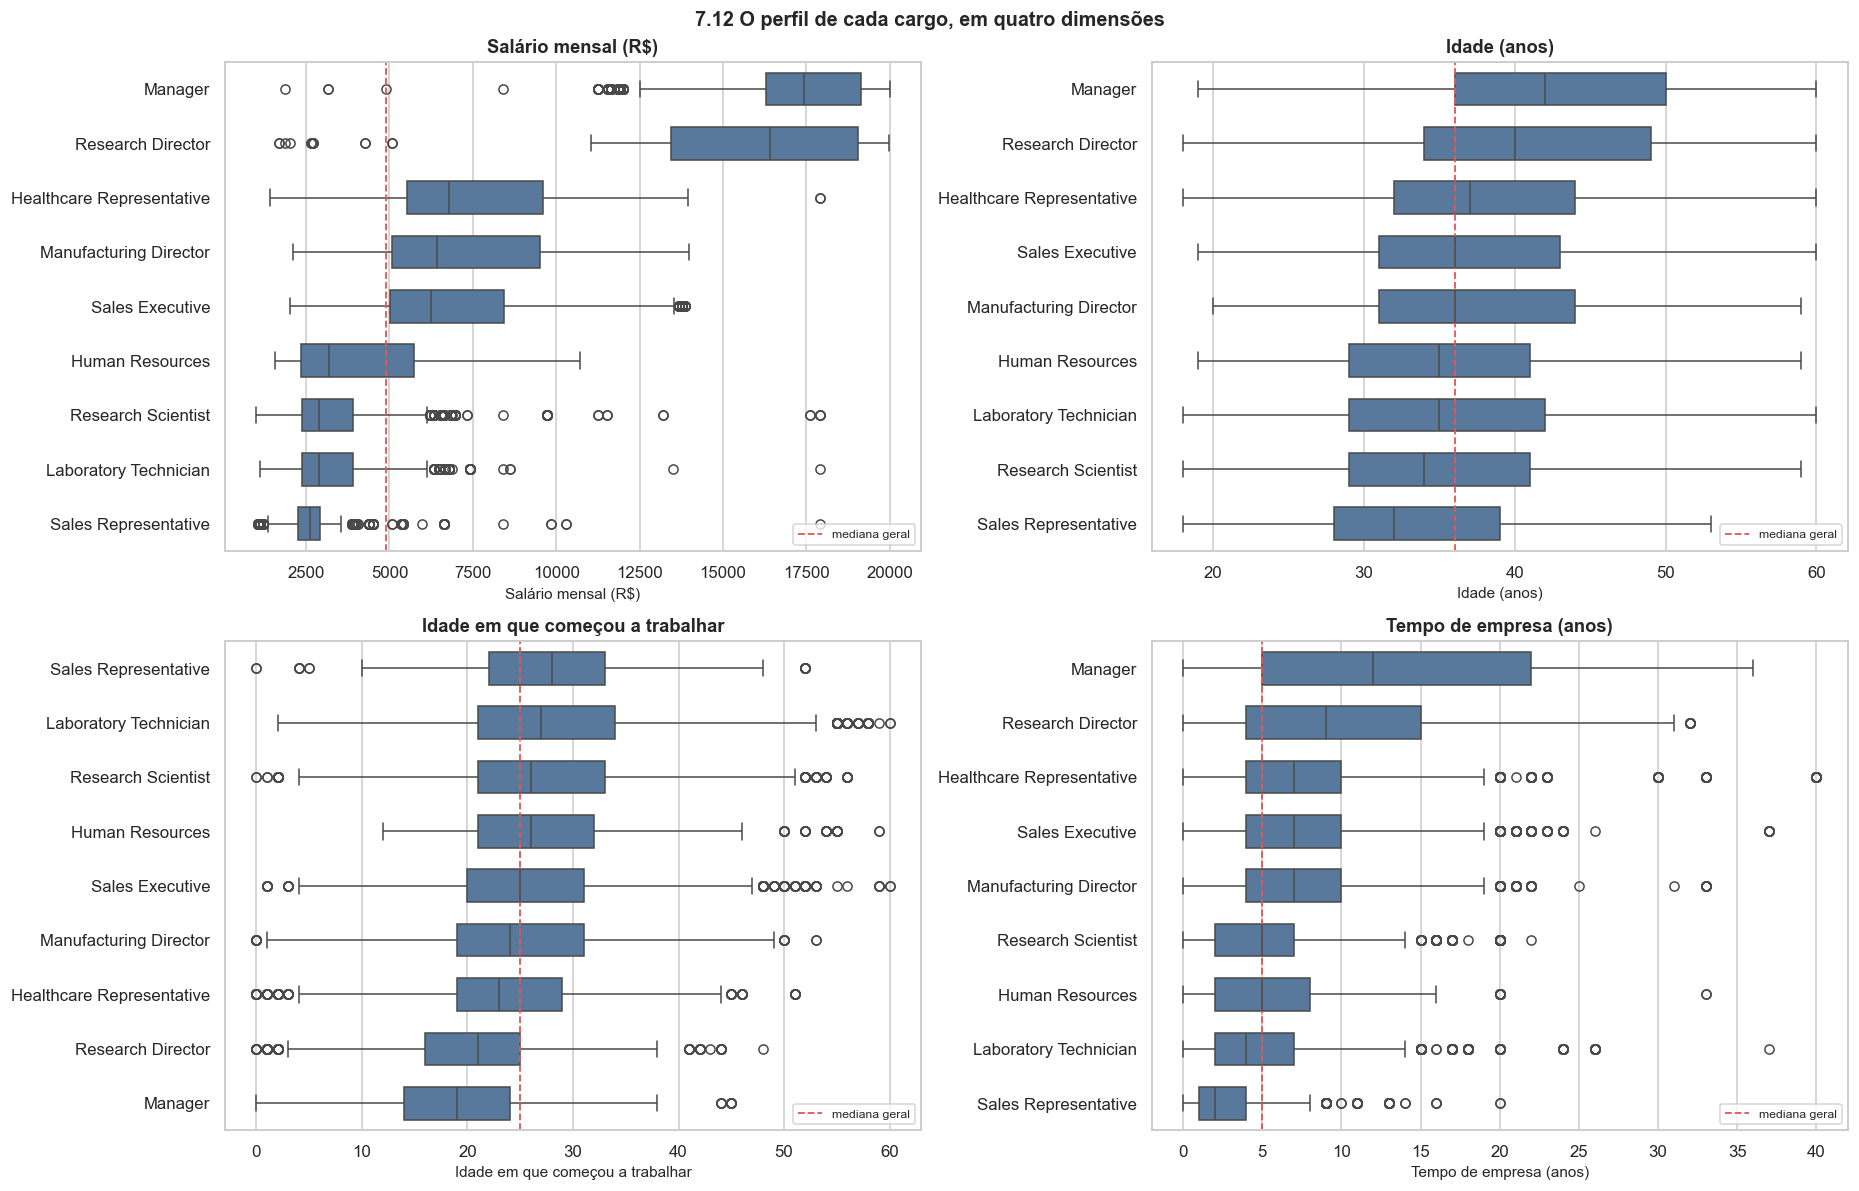

PERFIL DOS CARGOS (medianas)

                              n    salário  idade  início_carreira  tempo_empresa  nível
JobRole                                                                                 
Manager                    1513 17,444.000 42.000           19.000         12.000  4.000
Research Director          1212 16,413.000 40.000           21.000          9.000  4.000
Healthcare Representative  2061  6,781.000 37.000           23.000          7.000  2.000
Manufacturing Director     2338  6,434.000 36.000           24.000          7.000  2.000
Sales Executive            5051  6,230.000 36.000           25.000          7.000  2.000
Human Resources             833  3,195.000 35.000           26.000          5.000  1.000
Research Scientist         4576  2,889.000 34.000           26.000          5.000  1.000
Laboratory Technician      4088  2,886.000 35.000           27.000          4.000  1.000
Sales Representative       1299  2,610.000 32.000           28.000          2.00

In [29]:
variaveis_perfil = [
    ("MonthlyIncome",     "Salário mensal (R$)"),
    ("Age",               "Idade (anos)"),
    ("AgeStartedWorking", "Idade em que começou a trabalhar"),
    ("YearsAtCompany",    "Tempo de empresa (anos)"),
]

fig, eixos = plt.subplots(2, 2, figsize=(17, 11))

for eixo, (coluna, titulo) in zip(eixos.ravel(), variaveis_perfil):
    # Ordem dos cargos pela MEDIANA da variável, do maior para o menor
    ordem = (base.groupby("JobRole", observed=True)[coluna]
             .median().sort_values(ascending=False).index)
    sns.boxplot(data=base, y="JobRole", x=coluna, order=ordem,
                color=COR_FICOU, width=0.6, ax=eixo)
    eixo.axvline(base[coluna].median(), color=COR_SAIU, linestyle="--", lw=1.2,
                 label="mediana geral")
    eixo.set(title=titulo, xlabel=titulo, ylabel="")
    eixo.legend(fontsize=8, loc="lower right")

fig.suptitle("7.12 O perfil de cada cargo, em quatro dimensões",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# A tabela-perfil: uma linha por cargo, com as medianas das quatro variáveis
perfil_cargo = (base.groupby("JobRole", observed=True)
                .agg(n=("JobRole", "size"),
                     salário=("MonthlyIncome", "median"),
                     idade=("Age", "median"),
                     início_carreira=("AgeStartedWorking", "median"),
                     tempo_empresa=("YearsAtCompany", "median"),
                     nível=("JobLevel", "median"))
                .sort_values("salário", ascending=False))
print("PERFIL DOS CARGOS (medianas)\n")
print(perfil_cargo.round(1).to_string())

**A leitura.** A hierarquia salarial é nítida: `Manager` e `Research Director` no topo, com medianas
muito acima do resto; `Sales Representative`, `Laboratory Technician` e `Research Scientist` na base.
Idade e tempo de empresa acompanham o salário — os cargos melhor pagos são também os de gente mais
velha e com mais casa.

**Insight 1 — a estrutura de carreira é coerente.** Salário, idade, nível hierárquico e tempo de
empresa caminham juntos. Isso é o que se espera de uma estrutura que promove internamente, e é um
sinal de que a base é consistente. Se um cargo de topo tivesse idade e tempo de casa baixos, haveria
algo a investigar.

**Insight 2 — existe um grupo de cargos de entrada.** `Sales Representative` e
`Laboratory Technician` concentram salário baixo, idade baixa e pouco tempo de casa. **Essa é a
posição estrutural de maior risco de atrito**, por três razões simultâneas: menos a perder, mais
oferta no mercado para perfil júnior, e menos tempo investido na relação. Antes de olhar qualquer
taxa de saída, já é possível **prever** onde ela será mais alta — e o passo 8.6 confirma.

**Insight 3 — a idade de início de carreira é informativa.** Ela varia pouco entre os cargos, em torno
de 25 a 27 anos. Como `AgeStartedWorking` é, por construção, `Age − TotalWorkingYears` (verificado em
4.7), isso quer dizer que a diferença de idade entre cargos é, sobretudo, diferença de **tempo de
carreira**, e não de idade de entrada no mercado. Ou seja: a progressão é por **experiência
acumulada**.

**O que isso não diz.** Nada sobre mérito nem sobre justiça da estrutura salarial. E atenção à
leitura do grupo pequeno: `Human Resources` e `Research Director` têm poucos casos, e boxplot sobre
grupo pequeno dá uma impressão de precisão que o n não sustenta — a caixa continua estreita mesmo
quando a estimativa é incerta. **O boxplot não mostra incerteza de estimativa**; para isso é preciso
intervalo de confiança, que entra na Parte 8.

## 7.13 Escolaridade por cargo: barras de composição

**O elemento.** Cruzamento de duas categóricas, como em 7.7, mas agora com a pergunta invertida:
não "qual o perfil de cada área de formação", e sim **"qual o perfil de qualificação de cada cargo"**.

**O instrumento.** Barras **empilhadas a 100%** — a versão de composição do passo 7.7, apresentada
sozinha porque aqui é a pergunta de interesse. Cada barra é um cargo e soma 100%, o que torna os nove
cargos comparáveis entre si apesar dos tamanhos muito diferentes.

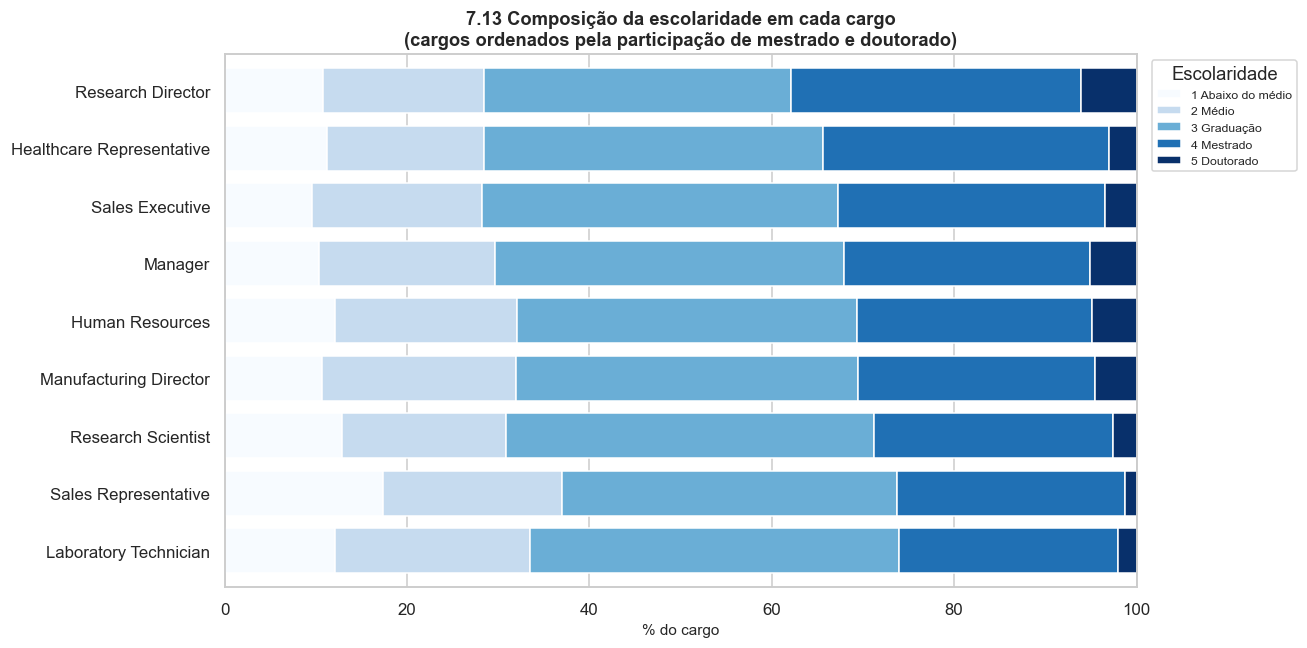

Participação de pós-graduação (mestrado + doutorado) por cargo:

                           % com pós-graduação  n do cargo
JobRole                                                   
Healthcare Representative               34.400        2061
Human Resources                         30.600         833
Laboratory Technician                   26.000        4088
Manager                                 32.100        1513
Manufacturing Director                  30.500        2338
Research Director                       37.900        1212
Research Scientist                      28.800        4576
Sales Executive                         32.800        5051
Sales Representative                    26.300        1299


In [30]:
# Tabela cargo x escolaridade, convertida em composição percentual por cargo
cruzada_cargo = pd.crosstab(base["JobRole"],
                            base["Education"].map(ROTULOS["Education"]))
composicao_cargo = cruzada_cargo.div(cruzada_cargo.sum(axis=1), axis=0) * 100

# Ordena os cargos pela participação de pós-graduação (mestrado + doutorado):
# a ordenação é o que transforma o gráfico em argumento.
colunas_pos = [c for c in composicao_cargo.columns if c.startswith(("4", "5"))]
ordem_cargo = composicao_cargo[colunas_pos].sum(axis=1).sort_values().index

fig, eixo = plt.subplots(figsize=(12, 6))
composicao_cargo.loc[ordem_cargo].plot(kind="barh", stacked=True, colormap="Blues",
                                       width=0.78, ax=eixo)
eixo.set(title="7.13 Composição da escolaridade em cada cargo\n"
               "(cargos ordenados pela participação de mestrado e doutorado)",
         xlabel="% do cargo", ylabel="", xlim=(0, 100))
eixo.legend(title="Escolaridade", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

print("Participação de pós-graduação (mestrado + doutorado) por cargo:\n")
pos = (composicao_cargo[colunas_pos].sum(axis=1)
       .sort_values(ascending=False).round(1).rename("% com pós-graduação"))
print(pd.DataFrame({"% com pós-graduação": pos,
                    "n do cargo": base["JobRole"].value_counts()}).to_string())

**A leitura.** A composição de escolaridade é **parecida entre os cargos**: em todos eles, graduação
domina, e a participação de pós-graduação varia numa faixa estreita. Não há um cargo que concentre
doutores e outro que concentre ensino médio.

**Insight.** Escolaridade **não** é o que distingue os cargos nesta empresa. O que distingue é tempo
de carreira (passo 7.12). Isso tem uma consequência prática forte para o RH: **a progressão aqui é
por experiência, não por diploma.** Se a empresa quiser usar escolaridade como critério de seleção ou
de promoção, não há, nesta base, evidência de que ela diferencie as posições.

**Consequência para a modelagem, que vale antecipar.** Uma variável que varia pouco entre os grupos
tende a ter **pouco poder explicativo** no modelo. A expectativa, então, é que escolaridade apareça
como fator fraco na Parte 9 — e é exatamente por isso que o modelo será construído removendo-a em uma
das versões, para ver se o desempenho muda.

**O que isso não diz.** Nada sobre a qualidade da formação, nem sobre adequação entre formação e
função. E cuidado com o cargo pequeno: numa categoria com poucos casos, uma barra de composição pode
oscilar muito — e o gráfico de 100% **esconde o tamanho do grupo** por construção. É o mesmo defeito
apontado em 7.12, e a razão de a tabela ao lado trazer o n de cada cargo.

## 7.14 Correlação: medindo a força de uma relação entre duas numéricas

**O elemento.** O **coeficiente de correlação de Pearson** (*r*): um número entre −1 e +1 que mede a
**força** e o **sentido** de uma relação **linear** entre duas variáveis quantitativas.

**O instrumento.** Dois, usados juntos e nunca separados:

1. o **coeficiente**, que resume a relação num número;
2. o **diagrama de dispersão**, que mostra a **forma** da relação.

**Por que nunca separados.** O coeficiente é cego ao formato. Uma relação forte em forma de curva pode
dar *r* perto de zero, e um único ponto extremo pode criar um *r* alto onde não há relação alguma.
**Jamais reporte um coeficiente de correlação sem ter olhado o diagrama de dispersão correspondente.**

**Como se lê o valor de *r*:**

| |r| | Força da relação linear |
|---|---|
| 0,00 a 0,19 | Muito fraca ou inexistente |
| 0,20 a 0,39 | Fraca |
| 0,40 a 0,59 | Moderada |
| 0,60 a 0,79 | Forte |
| 0,80 a 1,00 | Muito forte |

O **sinal** diz o sentido: positivo, as duas sobem juntas; negativo, uma sobe quando a outra desce.
E a advertência que acompanha a medida desde a primeira aula: **correlação não é causa**.

In [31]:
# Os pares de interesse, escolhidos por hipótese - não por varredura automática.
# Cada par tem uma pergunta de gestão por trás, declarada aqui.
pares = [
    ("TotalWorkingYears", "YearsAtCompany",
     "Quem tem mais experiência total também tem mais tempo nesta empresa?"),
    ("YearsAtCompany", "YearsInCurrentRole",
     "Quem tem mais tempo de casa está há mais tempo no mesmo cargo?"),
    ("YearsAtCompany", "YearsSinceLastPromotion",
     "Mais tempo de casa significa mais tempo sem promoção?"),
    ("YearsAtCompany", "YearsWithCurrManager",
     "Mais tempo de casa significa mais tempo com o mesmo gestor?"),
    ("TotalWorkingYears", "MonthlyIncome",
     "A experiência é remunerada?"),
    ("YearsAtCompany", "MonthlyIncome",
     "O tempo de casa é remunerado?"),
    ("Age", "MonthlyIncome",
     "A idade, por si, acompanha o salário?"),
]

def classificar(r):
    """Traduz o valor de r para a escala verbal da tabela acima."""
    a = abs(r)
    if a < 0.20: return "muito fraca"
    if a < 0.40: return "fraca"
    if a < 0.60: return "moderada"
    if a < 0.80: return "forte"
    return "muito forte"

linhas = []
for x, y, pergunta in pares:
    # .corr() entre duas colunas devolve o r de Pearson, ignorando ausentes
    r = base[x].corr(base[y])
    linhas.append({"variável X": x, "variável Y": y, "r": round(r, 3),
                   "força": classificar(r),
                   "sentido": "positiva" if r > 0 else "negativa",
                   "pergunta": pergunta})

tabela_cor = pd.DataFrame(linhas)
for _, l in tabela_cor.iterrows():
    print(f"{l['variável X']:<20} x {l['variável Y']:<24} r = {l['r']:+.3f}"
          f"   ({l['força']}, {l['sentido']})")
    print(f"    {l['pergunta']}")

TotalWorkingYears    x YearsAtCompany           r = +0.625   (forte, positiva)
    Quem tem mais experiência total também tem mais tempo nesta empresa?
YearsAtCompany       x YearsInCurrentRole       r = +0.767   (forte, positiva)
    Quem tem mais tempo de casa está há mais tempo no mesmo cargo?
YearsAtCompany       x YearsSinceLastPromotion  r = +0.623   (forte, positiva)
    Mais tempo de casa significa mais tempo sem promoção?
YearsAtCompany       x YearsWithCurrManager     r = +0.773   (forte, positiva)
    Mais tempo de casa significa mais tempo com o mesmo gestor?
TotalWorkingYears    x MonthlyIncome            r = +0.758   (forte, positiva)
    A experiência é remunerada?
YearsAtCompany       x MonthlyIncome            r = +0.499   (moderada, positiva)
    O tempo de casa é remunerado?
Age                  x MonthlyIncome            r = +0.278   (fraca, positiva)
    A idade, por si, acompanha o salário?


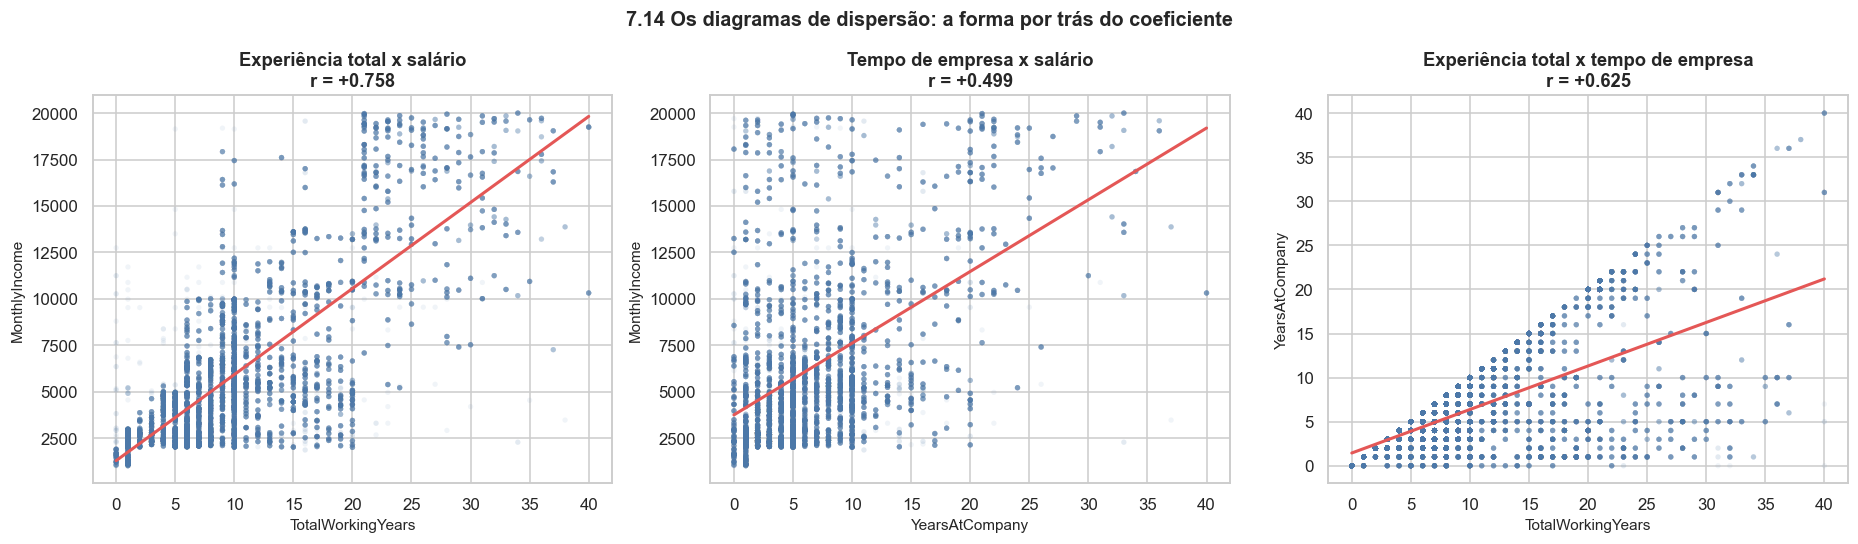

In [32]:
# Os diagramas de dispersão dos pares mais relevantes. Sem eles, os r acima
# não poderiam ser interpretados.
pares_grafico = [
    ("TotalWorkingYears", "MonthlyIncome", "Experiência total x salário"),
    ("YearsAtCompany",    "MonthlyIncome", "Tempo de empresa x salário"),
    ("TotalWorkingYears", "YearsAtCompany", "Experiência total x tempo de empresa"),
]

fig, eixos = plt.subplots(1, 3, figsize=(17, 5))

for eixo, (x, y, titulo) in zip(eixos, pares_grafico):
    # alpha=0.08 deixa os pontos translúcidos: com 23 mil pontos, opacos
    # formariam uma mancha sólida e a concentração ficaria invisível.
    eixo.scatter(base[x], base[y], alpha=0.08, s=12, color=COR_FICOU, edgecolors="none")

    # A reta de tendência, para comparar a forma real com a reta que o r supõe.
    # polyfit(x, y, 1) ajusta um polinômio de grau 1, isto é, uma reta.
    coeficientes = np.polyfit(base[x], base[y], 1)
    grade = np.linspace(base[x].min(), base[x].max(), 100)
    eixo.plot(grade, np.polyval(coeficientes, grade), color=COR_SAIU, lw=2)

    r = base[x].corr(base[y])
    eixo.set(title=f"{titulo}\nr = {r:+.3f}", xlabel=x, ylabel=y)

fig.suptitle("7.14 Os diagramas de dispersão: a forma por trás do coeficiente",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**A leitura.** Três grupos de resultado:

- **Relações fortes entre as variáveis de tempo.** `TotalWorkingYears` × `YearsAtCompany` tem
  *r* = **+0,63**, e `YearsAtCompany` × `YearsInCurrentRole` e × `YearsWithCurrManager` chegam a
  **+0,77**. São as mais fortes da base, junto com a seguinte.
- **Experiência é remunerada, e fortemente.** `TotalWorkingYears` × `MonthlyIncome` dá
  *r* = **+0,76**. O diagrama confirma a forma crescente.
- **Tempo de casa também é remunerado, mas menos.** `YearsAtCompany` × `MonthlyIncome` fica em
  **+0,50**.
- **E a idade, por si, quase não acompanha o salário:** *r* = **+0,28**, fraca. Quem é mais velho
  não ganha mais por ser mais velho; ganha mais quando tem mais **experiência** — que é outra
  variável, embora correlacionada com a idade.

**Insight 1 — sobre a empresa.** A experiência **total** pesa mais no salário (*r* = 0,76) do que o
tempo **nesta** empresa (*r* = 0,50). Lido como política de remuneração: a empresa paga mais pelo
que a pessoa trouxe de fora do que pelo tempo que ela ficou dentro. É um achado com consequência
direta sobre retenção — se ficar não é remunerado tanto quanto chegar com bagagem, o incentivo a
permanecer é menor. Guarde a comparação com o passo 8.14: é no primeiro ano que o risco de saída
é maior, e é também o tempo de casa que a remuneração reconhece menos.

**Insight 2 — sobre a modelagem, e é o mais importante deste passo.** As variáveis de tempo são
fortemente correlacionadas **entre si**, e isso é aritmeticamente inevitável: elas medem o mesmo
tempo recortado de formas diferentes, e `PriorYearsOfExperience` é literalmente a diferença entre duas
delas. Colocar todas no mesmo modelo produz **multicolinearidade**: os coeficientes ficam instáveis,
os erros-padrão inflam e a conclusão sobre significância se torna arbitrária. **É por isso que a
Parte 9 escolhe um subconjunto dessas variáveis e justifica a escolha** — e é por isso que se mede a
correlação *antes* de modelar, não depois.

**O que a nuvem de pontos mostra e o coeficiente esconde.** Nos diagramas de salário, a dispersão
**aumenta** conforme a experiência cresce: entre os mais experientes há tanto salários altos quanto
baixos. Isso é heterocedasticidade, e significa que a reta descreve bem a tendência central e **mal**
os casos individuais. Previsão de salário a partir de experiência seria imprecisa justamente onde
mais interessa.

**O que isso não diz.** Que experiência **cause** salário maior. A correlação é compatível com
explicações opostas — a empresa paga pela experiência, ou pessoas que já ganhavam mais permanecem
mais tempo no mercado. E uma ressalva técnica: Pearson supõe relação **linear** entre variáveis
**quantitativas**. Para as escalas de 1 a 4, a medida apropriada seria a de Spearman, baseada em
postos.

## 7.15 A matriz de correlação: todos os pares de uma vez

**O elemento.** O mesmo coeficiente do passo anterior, calculado para **todos os pares**
simultaneamente. É o passo de síntese da Parte 7.

**O instrumento.** **Mapa de calor** (*heatmap*) da matriz de correlação. A cor substitui o número
na leitura rápida: vermelho forte para correlação positiva alta, azul forte para negativa alta,
branco para ausência de relação. A metade de cima é escondida porque é espelho da de baixo e só
poluiria.

**Para que serve, e são duas coisas.**

1. **Descrever** quais variáveis caminham juntas, num só quadro;
2. **Antecipar problemas de multicolinearidade** antes de ajustar qualquer modelo. Esta é a função
   mais valiosa, e é a razão de a matriz vir sempre antes da modelagem.

**Quando não usar.** Como critério de **seleção de variáveis** para o modelo. Escolher as
explicativas pela correlação com a dependente ("vou usar as cinco de maior *r*") é um erro comum:
ignora que duas variáveis podem ser individualmente fracas e, juntas, fortes — e que uma variável de
*r* alto pode ser redundante com outra.

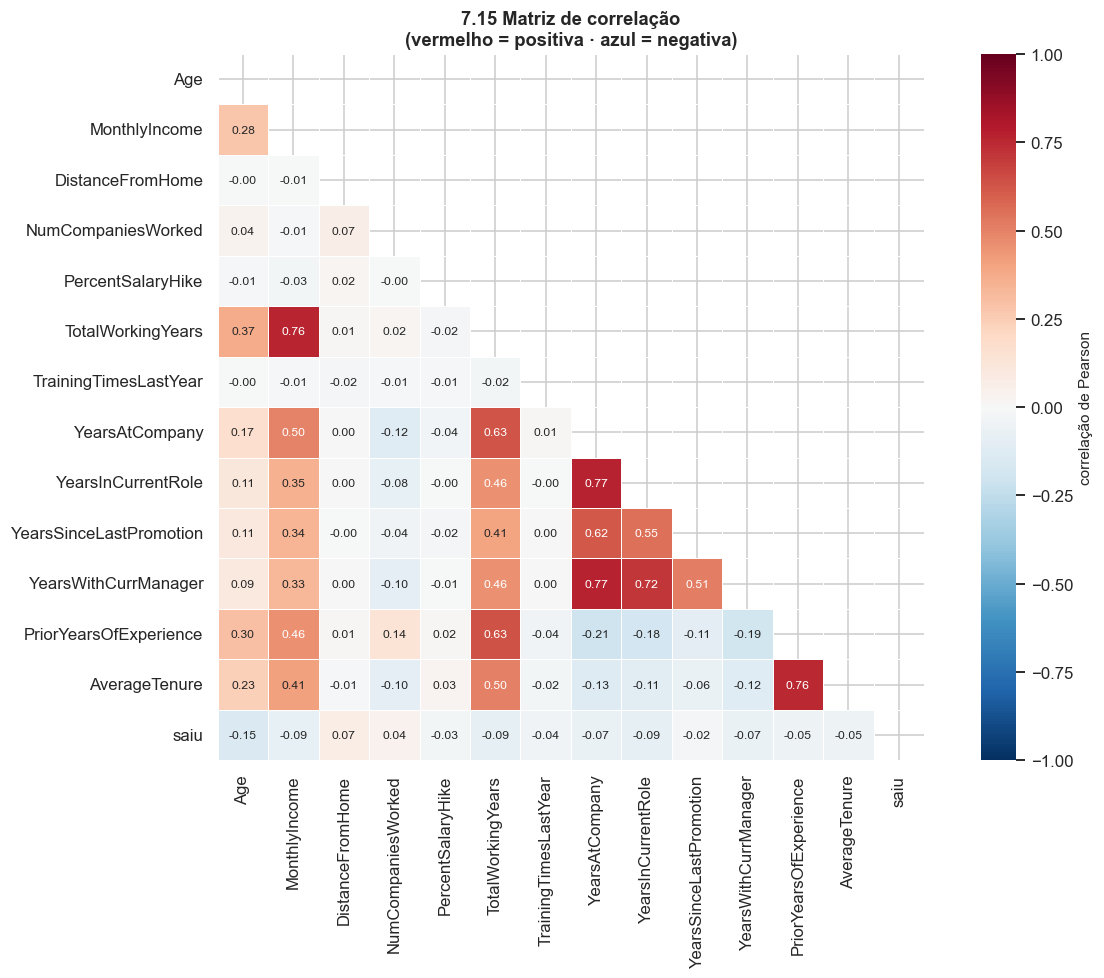

PARES COM CORRELAÇÃO ALTA (|r| >= 0,60)
Estes são os candidatos a problema de multicolinearidade na Parte 9:

             variável A             variável B     r
   YearsWithCurrManager         YearsAtCompany 0.773
     YearsInCurrentRole         YearsAtCompany 0.767
      TotalWorkingYears          MonthlyIncome 0.758
          AverageTenure PriorYearsOfExperience 0.756
   YearsWithCurrManager     YearsInCurrentRole 0.717
 PriorYearsOfExperience      TotalWorkingYears 0.635
         YearsAtCompany      TotalWorkingYears 0.625
YearsSinceLastPromotion         YearsAtCompany 0.623


CORRELAÇÃO DE CADA VARIÁVEL COM A SAÍDA (saiu = 1)

                         r com 'saiu'
Age                            -0.149
YearsInCurrentRole             -0.091
TotalWorkingYears              -0.091
MonthlyIncome                  -0.085
DistanceFromHome                0.072
YearsWithCurrManager           -0.070
YearsAtCompany                 -0.066
AverageTenure                  -0.052
PriorYearsOfExper

In [33]:
# Variáveis de contagem e intervalares, mais a dependente binária no fim.
colunas_corr = ["Age", "MonthlyIncome", "DistanceFromHome", "NumCompaniesWorked",
                "PercentSalaryHike", "TotalWorkingYears", "TrainingTimesLastYear",
                "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion",
                "YearsWithCurrManager", "PriorYearsOfExperience", "AverageTenure", "saiu"]

matriz = base[colunas_corr].corr(method="pearson")

# np.triu devolve a matriz triangular SUPERIOR; usada como máscara, esconde o espelho.
mascara = np.triu(np.ones_like(matriz, dtype=bool))

fig, eixo = plt.subplots(figsize=(12, 9))
sns.heatmap(matriz, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "correlação de Pearson"}, annot_kws={"size": 8}, ax=eixo)
eixo.set_title("7.15 Matriz de correlação\n(vermelho = positiva · azul = negativa)",
               fontweight="bold")
plt.tight_layout()
plt.show()

# Os pares problemáticos, listados explicitamente: |r| >= 0,60
print("PARES COM CORRELAÇÃO ALTA (|r| >= 0,60)")
print("Estes são os candidatos a problema de multicolinearidade na Parte 9:\n")
pares_todos = (matriz.where(~mascara).stack().rename("r").reset_index()
               .rename(columns={"level_0": "variável A", "level_1": "variável B"}))
altos = pares_todos[pares_todos["r"].abs() >= 0.60].sort_values("r", key=abs, ascending=False)
print(altos.to_string(index=False) if len(altos) else "Nenhum par acima do limiar.")

print("\n\nCORRELAÇÃO DE CADA VARIÁVEL COM A SAÍDA (saiu = 1)\n")
print(matriz["saiu"].drop("saiu").sort_values(key=abs, ascending=False)
      .rename("r com 'saiu'").to_frame().round(3).to_string())

**A leitura.** Duas coisas saltam do quadro:

1. **O bloco vermelho das variáveis de tempo**, no canto, confirmando em conjunto o que o passo 7.14
   mostrou par a par. Cinco variáveis fortemente correlacionadas entre si.
2. **A última coluna — a correlação com a saída — é modesta para todas as variáveis.** Nenhuma passa
   de |*r*| ≈ 0,2.

**Insight 1 — o atrito é multifatorial.** Esta é a conclusão central da Parte 7 e a ponte para o resto
do notebook. **Nenhuma variável isolada explica a saída.** Se houvesse uma causa única e dominante,
ela apareceria aqui com *r* alto, e o problema estaria resolvido sem precisar de modelo. Não há. O
atrito resulta da **combinação** de fatores, e é exatamente para medir combinação que existe a
regressão multivariada da Parte 9.

**Insight 2 — e cuidado para não concluir o oposto.** Correlação baixa com `saiu` **não** significa
ausência de sinal, por duas razões técnicas: (i) Pearson entre uma binária e uma contínua é uma
medida ruim por construção — a binária só tem dois valores, e nenhuma reta descreve bem isso; (ii) um
fator pode ter efeito forte **dentro de subgrupos** e efeito médio nulo no agregado. O passo 8.2 mostra
exatamente esse caso: uma variável com correlação bruta modesta e efeito muito grande.

**Insight 3 — o encaminhamento para a modelagem.** Das cinco variáveis de tempo, o modelo da Parte 9
usará **duas ou três**, não as cinco. A escolha não é estatística, é substantiva: fica a que responde
à pergunta de gestão. Essa decisão está documentada no passo 9.2.

**Fecho da Parte 7.** Sabemos **com quem estamos lidando**: quadro maduro (mediana de 36 anos),
predominantemente masculino, concentrado em P&D, com estrutura de carreira coerente, distribuição
salarial assimétrica, muita gente com pouco tempo de casa e uma taxa-base de saída voluntária de
**15,7%**. Nenhuma variável isolada explica essa taxa. A próxima parte passa de "quem são" para **"quem
sai mais"** — e é aí que o diagnóstico começa.

---

# Parte 8. O diagnóstico: quem sai mais?

A Parte 7 respondeu "**com quem estamos lidando?**". Agora a pergunta muda para "**a taxa de saída é
diferente entre os grupos?**" — e com ela começa o **diagnóstico**.

## A ordem dos passos não é arbitrária

As variáveis são examinadas em dois blocos, na ordem que a Parte 1.3 estabeleceu, porque **o bloco
determina o que se pode fazer com o achado**:

| Bloco | Variáveis | A pergunta que respondem |
|---|---|---|
| **A. Conhecidas antes de contratar** (8.3 a 8.10) | Idade, estado civil, escolaridade, formação, distância de casa, canal de recrutamento, cargo, experiência anterior, gênero | **Quem tende a sair?** Serve para melhorar o recrutamento |
| **B. Só conhecidas depois** (8.11 a 8.17) | Hora extra, viagens, salário, nível, satisfação, equilíbrio, participação acionária, treinamento, tempo de casa | **O que eu faço a respeito?** Serve para gerir quem já está dentro |

Um achado do bloco A vira política de recrutamento; um achado do bloco B vira política de gestão. E
há variáveis do bloco A — idade, gênero, estado civil — sobre as quais **não se age de forma alguma**,
porque agir seria discriminação: elas entram para ser **controladas**, não para orientar decisão sobre
pessoas.

## O passo final é o que fecha a parte

O passo 8.18 mostra, com dado desta base, **por que a análise bivariada não basta** — e é ele que
justifica a existência da Parte 9. Sem esse fechamento, a Parte 8 pareceria suficiente, e não é.

## 8.1 O instrumento central desta parte: a taxa de saída por grupo

**O elemento.** A **proporção condicional**: a frequência relativa do evento **dentro de cada
grupo**. É a medida mais usada em diagnóstico organizacional e a mais fácil de ler errado.

**Os três números que andam sempre juntos.** Toda taxa de grupo exige três informações, e apresentar
uma sem as outras duas é incompleto:

| Número | Por que é indispensável |
|---|---|
| **A taxa** | O que se quer saber: que fração daquele grupo saiu |
| **O n do grupo** | Uma taxa de 50% sobre 4 pessoas e sobre 4.000 pessoas **não** são o mesmo achado |
| **O intervalo de confiança** | Diz **quanto** a taxa pode oscilar por efeito do tamanho do grupo |

**O intervalo de confiança de uma proporção**, que é a fórmula vista na disciplina:

$$p \pm 1{,}96 \times \sqrt{\frac{p(1-p)}{n}}$$

Ela diz que a incerteza depende de duas coisas: da própria proporção e, principalmente, do **tamanho
do grupo** — a raiz de *n* no denominador significa que, para reduzir a incerteza pela metade, é
preciso **quadruplicar** o grupo.

**A regra de decisão que usaremos em todos os passos.** Se o intervalo de confiança do grupo
**contém** a taxa global da empresa, **não há evidência** de que aquele grupo seja diferente do resto
— por mais sugestivo que o número pareça. É essa regra que separa achado de ruído.

**Por que não usar o gráfico de barras empilhadas a 100%.** Ele é comum em relatório de RH e tem um
defeito grave: **esconde o tamanho do grupo**. Uma barra de 50% sobre 4 pessoas fica visualmente
idêntica a uma barra de 50% sobre 4.000. O instrumento abaixo corrige isso, escrevendo o *n* ao lado
de cada barra e desenhando a barra de erro.

In [34]:
def taxa_saida_por(coluna, dados_entrada=None, ordenar_por_taxa=True):
    """Taxa de saída por categoria, com n, intervalo de confiança de 95% e comparação
    com a taxa global.

    Devolve um DataFrame com uma linha por categoria.
    """
    df = base if dados_entrada is None else dados_entrada

    # groupby(coluna)["saiu"].agg(...) : para cada categoria, a MÉDIA de 'saiu'
    # (que, numa variável 0/1, é exatamente a proporção de 1) e o tamanho do grupo.
    agregado = (df.groupby(coluna, observed=True)["saiu"]
                  .agg(taxa="mean", n="size"))

    # Erro-padrão da proporção e margem de erro de 95% (z = 1,96)
    erro_padrao = np.sqrt(agregado["taxa"] * (1 - agregado["taxa"]) / agregado["n"])
    margem = 1.96 * erro_padrao

    agregado["ic_inf"] = (agregado["taxa"] - margem).clip(lower=0)   # taxa não é negativa
    agregado["ic_sup"] = (agregado["taxa"] + margem).clip(upper=1)   # nem passa de 1
    agregado["margem_p.p."] = (margem * 100).round(1)

    taxa_ref = df["saiu"].mean()
    agregado["dif_p.p."] = ((agregado["taxa"] - taxa_ref) * 100).round(1)

    # A regra de decisão: o IC do grupo cobre a taxa global?
    agregado["difere do global?"] = np.where(
        (agregado["ic_inf"] > taxa_ref) | (agregado["ic_sup"] < taxa_ref), "SIM", "não")
    agregado["alerta"] = np.where(agregado["n"] < 1000, "n pequeno", "")

    # Ordinal: manter a ordem da escala. Nominal: ordenar pela taxa.
    if ordenar_por_taxa:
        agregado = agregado.sort_values("taxa", ascending=False)
    return agregado


def grafico_taxa(coluna, titulo=None, dados_entrada=None, ordenar_por_taxa=True,
                 eixo=None, mostrar_tabela=False):
    """Barras horizontais da taxa de saída, com barra de erro (IC 95%) e o n ao lado."""
    df = base if dados_entrada is None else dados_entrada
    tabela = taxa_saida_por(coluna, df, ordenar_por_taxa)
    taxa_ref = df["saiu"].mean()

    criou = eixo is None
    if criou:
        _, eixo = plt.subplots(figsize=(9.5, 0.52 * len(tabela) + 2.2))

    posicoes = np.arange(len(tabela))
    # Barra de erro assimétrica: distância da taxa até cada limite do IC
    erros = np.array([tabela["taxa"] - tabela["ic_inf"], tabela["ic_sup"] - tabela["taxa"]])

    eixo.barh(posicoes, tabela["taxa"] * 100, color=COR_SAIU, alpha=0.85,
              xerr=erros * 100, error_kw=dict(ecolor="#333", lw=1.1, capsize=3))
    eixo.axvline(taxa_ref * 100, color="black", linestyle="--", lw=1.3,
                 label=f"taxa global ({taxa_ref:.1%})")
    eixo.set_yticks(posicoes, [str(i) for i in tabela.index])
    eixo.invert_yaxis()                      # maior taxa no topo
    eixo.set(xlabel="taxa de saída voluntária (%)", ylabel="",
             title=titulo or f"Taxa de saída por {coluna}")
    eixo.legend(fontsize=8, loc="lower right")

    # O n ao lado de cada barra: o tamanho do grupo nunca fica escondido
    for p, (_, linha) in zip(posicoes, tabela.iterrows()):
        eixo.text(linha["ic_sup"] * 100 + 0.7, p,
                  f"n={int(linha['n']):,}".replace(",", "."),
                  va="center", fontsize=8, color="#333")
    eixo.set_xlim(0, min(100, tabela["ic_sup"].max() * 100 + 13))

    if criou:
        plt.tight_layout()
        plt.show()
    if mostrar_tabela:
        saida = tabela.copy()
        for c in ["taxa", "ic_inf", "ic_sup"]:
            saida[c] = (saida[c] * 100).round(1)
        print(saida.to_string())
    return tabela


print(f"Taxa global de saída voluntária (a régua de comparação): {taxa_global:.2%}")
print(f"Base de modelagem: {len(base):,} funcionários".replace(",", "."))
print("\nFunções taxa_saida_por() e grafico_taxa() prontas para os passos seguintes.")

Taxa global de saída voluntária (a régua de comparação): 15.68%
Base de modelagem: 22.971 funcionários

Funções taxa_saida_por() e grafico_taxa() prontas para os passos seguintes.


## 8.2 Primeiro uso do instrumento: departamento

**O elemento.** A aplicação da proporção condicional, e o primeiro contato com a distinção que a
Parte 7 anunciou: **volume não é taxa**.

**A pergunta de gestão.** Algum departamento perde mais gente, proporcionalmente, que os outros?

**Por que começar por departamento.** Porque aqui o contraste entre volume e taxa é mais didático: o
maior departamento em número de pessoas **não** é o que mais perde proporcionalmente, e essa é
exatamente a confusão que o relatório de RH precisa evitar.

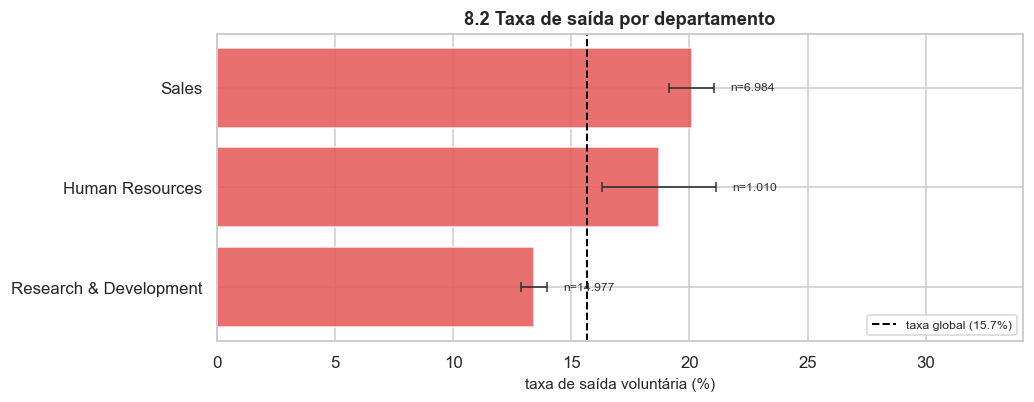

                         taxa      n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
Department                                                                                          
Sales                  20.100   6984  19.100  21.000        0.900     4.400               SIM       
Human Resources        18.700   1010  16.300  21.100        2.400     3.000               SIM       
Research & Development 13.400  14977  12.900  14.000        0.500    -2.300               SIM       


VOLUME x TAXA: as duas leituras do mesmo departamento

                        funcionários (n)  saíram (n)  taxa de saída (%)  % das saídas da empresa
Department                                                                                      
Research & Development             14977        2009             13.400                   55.800
Sales                               6984        1403             20.100                   39.000
Human Resources                     1010         1

In [35]:
tabela_depto = grafico_taxa("Department", "8.2 Taxa de saída por departamento",
                            mostrar_tabela=True)

# O contraste entre volume e taxa, posto lado a lado:
print("\n\nVOLUME x TAXA: as duas leituras do mesmo departamento\n")
comparacao = pd.DataFrame({
    "funcionários (n)": tabela_depto["n"],
    "saíram (n)": (tabela_depto["n"] * tabela_depto["taxa"]).round(0).astype(int),
    "taxa de saída (%)": (tabela_depto["taxa"] * 100).round(1),
})
comparacao["% das saídas da empresa"] = (comparacao["saíram (n)"]
                                         / comparacao["saíram (n)"].sum() * 100).round(1)
print(comparacao.sort_values("saíram (n)", ascending=False).to_string())

**A leitura.** Vendas tem a maior taxa (**20,1%**), seguida de RH (**18,7%**) e de P&D (**13,4%**).
A taxa global é 15,7%, e os intervalos de confiança de Vendas e de P&D não a cobrem: as duas
**diferem** do conjunto da empresa.

**Insight.** Vendas perde proporcionalmente mais gente, e a diferença em relação a P&D é de quase
**7 pontos percentuais** — grande e sólida, estimada sobre milhares de casos em cada grupo. É
consistente com o que se conhece da função comercial: mais oferta externa, remuneração mais variável,
pressão por meta.

**O contraste que este passo existe para ensinar.** Olhe a tabela de volume e taxa:

- **P&D responde pela maior parte das saídas da empresa** em número absoluto, porque tem dois terços
  do quadro — ainda que tenha a **menor** taxa.
- **Vendas tem a maior taxa**, mas contribui com menos saídas em número absoluto.

As duas leituras estão corretas e respondem perguntas diferentes. *"Onde perdemos mais gente?"* →
P&D. *"Onde o risco de perder é maior?"* → Vendas. Confundir as duas leva a dois erros de gestão
opostos: concentrar a ação onde a taxa é baixa, ou ignorar o lugar onde está a maior parte das perdas.
**O relatório competente apresenta as duas.**

**Sobre o RH, com n = 1.010.** A taxa de 18,7% parece próxima da de Vendas, mas a margem de erro é
mais que o dobro, porque o grupo é cinco vezes menor. O intervalo é largo, e por isso o certo é
dizer: *"RH apresenta taxa acima da média, com estimativa menos precisa pelo tamanho do grupo"* — e
**não** *"RH é o segundo pior departamento"*.

**O que isso não diz.** Que o departamento **cause** a saída. Departamento é um rótulo que agrega
cargo, faixa salarial, estilo de gestão e perfil de contratação. O que a taxa mostra é **onde** o
fenômeno está, não **por quê**.

---

## Bloco A. Variáveis conhecidas antes da contratação

Os próximos oito passos examinam o que já se sabe sobre a pessoa **no momento da contratação**. O uso
desses achados é duplo e precisa ficar explícito: alguns orientam a política de recrutamento; outros
existem apenas para **controle estatístico** e não devem orientar decisão alguma sobre pessoas.

## 8.3 Idade: o fator demográfico mais forte, e o que não fazer com ele

**O elemento.** Transformar uma variável **contínua** em **faixas** para a análise bivariada, e
examinar se a relação é **monotônica** (sempre no mesmo sentido) ou não.

**O instrumento.** A taxa por faixa, com as faixas na **ordem natural** — não ordenadas por taxa,
porque aqui a sequência é a informação. As faixas foram definidas no passo 5.3 segundo estágios de
carreira, e não por quartis automáticos, justamente para que o resultado seja conversável com o RH.

**A pergunta de gestão.** Os mais jovens saem mais? E se saem, quanto mais?

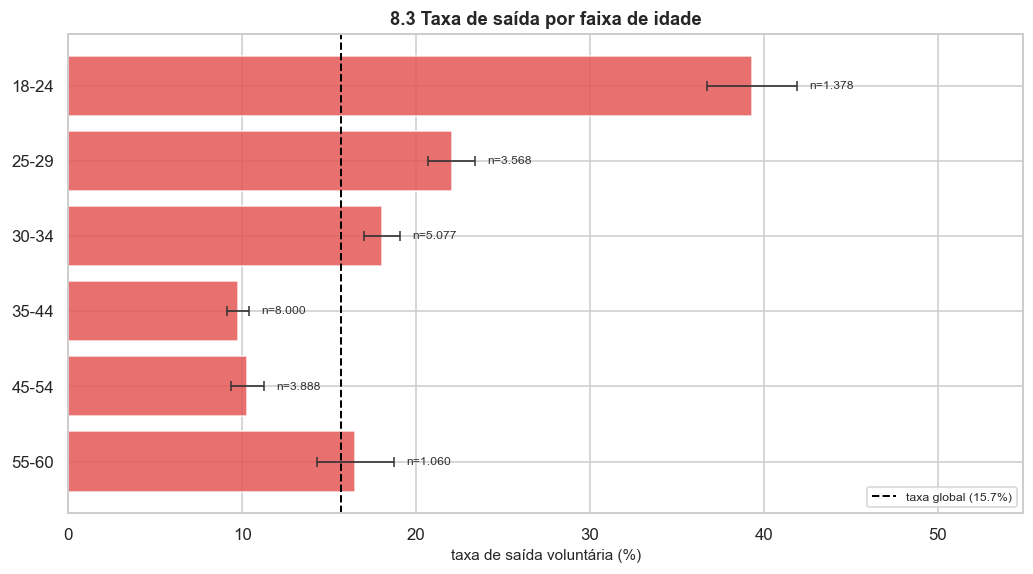

             taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
FaixaIdade                                                                             
18-24      39.300  1378  36.800  41.900        2.600    23.700               SIM       
25-29      22.100  3568  20.700  23.400        1.400     6.400               SIM       
30-34      18.000  5077  17.000  19.100        1.100     2.400               SIM       
35-44       9.800  8000   9.100  10.400        0.700    -5.900               SIM       
45-54      10.300  3888   9.300  11.200        1.000    -5.400               SIM       
55-60      16.500  1060  14.300  18.700        2.200     0.800               não       

Faixa de MAIOR taxa: 18-24 (39.3%)
Faixa de MENOR taxa: 35-44 (9.8%)
Risco relativo entre os extremos: 4.0x


In [36]:
tabela_idade = grafico_taxa("FaixaIdade", "8.3 Taxa de saída por faixa de idade",
                            ordenar_por_taxa=False, mostrar_tabela=True)

# A razão entre a maior e a menor taxa: a medida de "quantas vezes mais"
maior, menor = tabela_idade["taxa"].max(), tabela_idade["taxa"].min()
print(f"\nFaixa de MAIOR taxa: {tabela_idade['taxa'].idxmax()} ({maior:.1%})")
print(f"Faixa de MENOR taxa: {tabela_idade['taxa'].idxmin()} ({menor:.1%})")
print(f"Risco relativo entre os extremos: {maior / menor:.1f}x")

**A leitura.** O padrão é forte e quase monotônico: **39,3%** na faixa de 18 a 24 anos, **22,1%** de
25 a 29, **18,0%** de 30 a 34, caindo para **9,8%** de 35 a 44 anos. Depois sobe de novo um pouco:
10,3% de 45 a 54 e **16,5%** de 55 a 60.

**Insight 1 — a magnitude.** Entre os mais jovens, a taxa de saída é **quatro vezes** a dos
funcionários de 35 a 44 anos. É a maior diferença encontrada em toda a Parte 8. Para a gestão, isso
localiza o problema: **o atrito é, sobretudo, um fenômeno do início de carreira.**

**Insight 2 — a subida no fim da curva.** A alta na faixa de 55 a 60 anos (16,5%, com n = 1.060) tem
explicação provável e diferente: **aposentadoria**. Um pedido de demissão aos 58 anos não é a mesma
decisão que um pedido aos 23, e tratá-los como o mesmo evento mistura dois fenômenos. A base não
distingue saída por aposentadoria de saída para outro emprego — é uma limitação a registrar, e é
exatamente o tipo de ressalva que uma curva **não monotônica** obriga a investigar.

**Insight 3 — a forma importa para a Parte 9.** A relação **não é uma reta**: cai forte, estabiliza e
sobe no fim. Isso significa que, no modelo, um coeficiente único para idade (que impõe uma reta no
logito) vai descrever **mal** os extremos. A observação fica registrada aqui e é retomada no passo 9.3.

**O que NÃO se faz com este achado, e aqui não há meio-termo.** **Não se usa idade como critério de
seleção.** É discriminação, é vedada em lei e, além disso, seria um erro analítico: idade não é causa,
é indicador de outras coisas — estágio de carreira, enraizamento, alternativas no mercado, patrimônio
acumulado. A ação correta a partir deste achado é **sobre as condições**, não sobre as pessoas:
construir trilha de carreira visível para os primeiros anos, que é onde a perda se concentra. A
variável entra na Parte 9 como **controle**, para que o efeito das outras não seja contaminado pela
composição de idade do quadro.

## 8.4 Estado civil: um indicador indireto

**A pergunta de gestão.** Solteiros saem mais que casados? E se sim, o que isso realmente está
medindo?

**Por que este passo é delicado.** O achado é forte, e a tentação de usá-lo em seleção é imediata e
errada. Este passo serve tanto para medir quanto para mostrar **como se interpreta um indicador
indireto** — uma variável que não causa nada, mas aponta para algo que não foi medido.

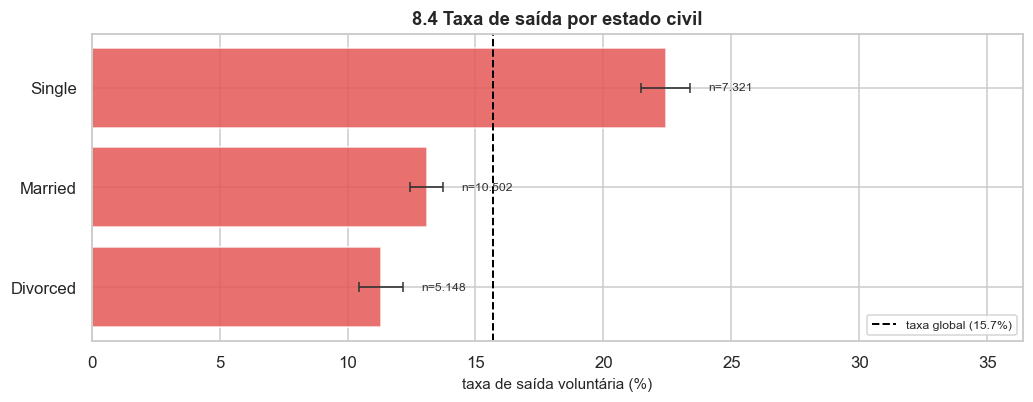

                taxa      n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
MaritalStatus                                                                              
Single        22.400   7321  21.500  23.400        1.000     6.800               SIM       
Married       13.100  10502  12.500  13.700        0.600    -2.600               SIM       
Divorced      11.300   5148  10.400  12.200        0.900    -4.400               SIM       

Solteiros x casados:
  diferença absoluta .. 9.3 pontos percentuais
  risco relativo ...... 1.71x


IDADE MEDIANA POR ESTADO CIVIL (a variável por trás da variável)

                   n  idade_mediana  taxa_saída
MaritalStatus                                  
Divorced        5148         36.000       0.113
Married        10502         36.000       0.131
Single          7321         35.000       0.224


In [37]:
tabela_civil = grafico_taxa("MaritalStatus", "8.4 Taxa de saída por estado civil",
                            mostrar_tabela=True)

# A mesma diferença em três linguagens, como no passo 8.11 adiante
taxa_solteiro = tabela_civil.loc["Single", "taxa"]
taxa_casado   = tabela_civil.loc["Married", "taxa"]
print(f"\nSolteiros x casados:")
print(f"  diferença absoluta .. {(taxa_solteiro - taxa_casado) * 100:.1f} pontos percentuais")
print(f"  risco relativo ...... {taxa_solteiro / taxa_casado:.2f}x")

# Estado civil está confundido com idade? A tabela cruzada responde.
print("\n\nIDADE MEDIANA POR ESTADO CIVIL (a variável por trás da variável)\n")
print(base.groupby("MaritalStatus", observed=True)
      .agg(n=("Age", "size"), idade_mediana=("Age", "median"),
           taxa_saída=("saiu", "mean")).round(3).to_string())

**A leitura.** Solteiros saem a **22,4%**, casados a **13,1%** e divorciados a **11,3%**. A taxa dos
solteiros é **1,7 vez** a dos casados, e os intervalos de confiança não se sobrepõem.

**Insight — e a interpretação correta, que não é a óbvia.** O estado civil não causa pedido de
demissão. Ele é um **indicador indireto** (*proxy*) de um conjunto de coisas que a base não mede
diretamente: estágio de vida, existência de dependentes, custo de mudar de cidade, enraizamento local.
Repare na tabela de idade mediana: solteiros são também **mais jovens**, e o passo 8.3 já mostrou que
idade tem efeito forte. Boa parte do que aparece aqui pode ser idade disfarçada.

**É por isso que a Parte 9 é necessária.** Só um modelo que inclua idade e estado civil ao mesmo
tempo pode dizer se o estado civil acrescenta algo **além** da idade. Esse teste é feito no passo 9.8,
e o resultado é surpreendente — o efeito do estado civil **desaparece** quando se controla pelas
variáveis de gestão.

**O que NÃO se faz.** Não se seleciona, promove ou prioriza por estado civil. Além de discriminação,
seria agir sobre o termômetro em vez de agir sobre a febre. O achado útil é: **existe um perfil de
menor enraizamento, e a empresa precisa dar a ele razões concretas para ficar** — plano de carreira,
mobilidade interna, projetos com horizonte.

## 8.5 Canal de recrutamento: o achado que o bloco A existe para produzir

**A pergunta de gestão.** Candidatos vindos de canais diferentes permanecem por tempos diferentes? Se
sim, o RH pode **realocar orçamento de recrutamento** — e esta é uma decisão de custo direto, tomada
com dado.

**Por que este é o achado mais acionável do bloco A.** Diferente de idade ou estado civil, o canal de
recrutamento é uma variável que a empresa **escolhe**. Não há questão ética em preferir um canal a
outro.

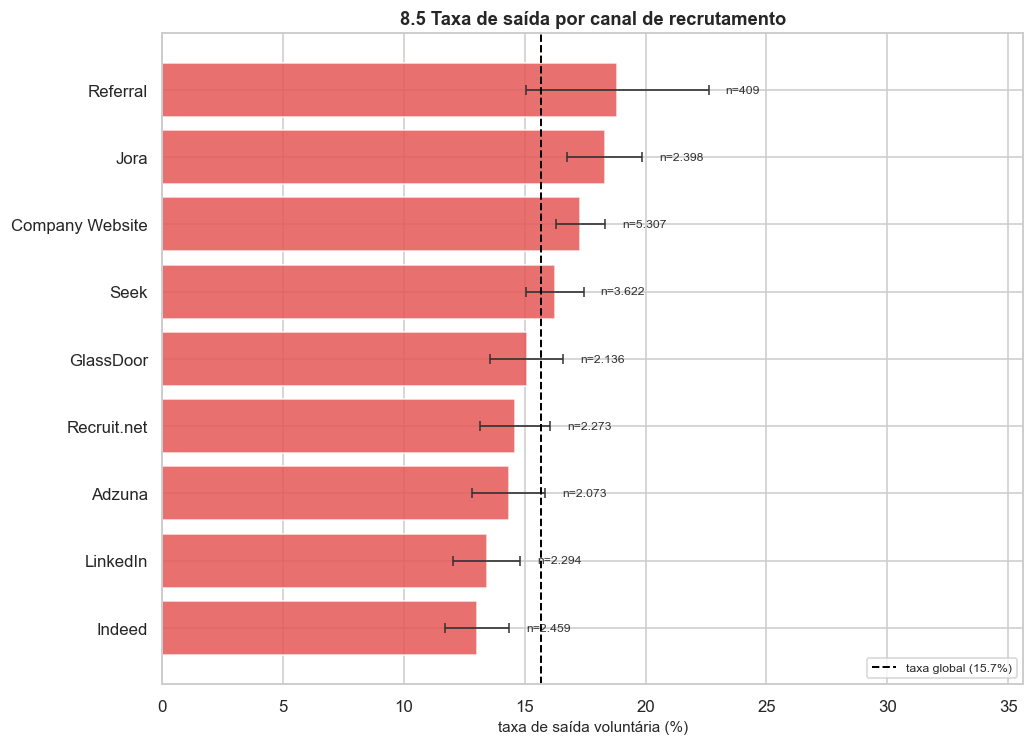

                  taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global?     alerta
EmployeeSource                                                                                  
Referral        18.800   409  15.000  22.600        3.800     3.200               não  n pequeno
Jora            18.300  2398  16.800  19.900        1.500     2.600               SIM           
Company Website 17.300  5307  16.300  18.300        1.000     1.600               SIM           
Seek            16.200  3622  15.000  17.400        1.200     0.600               não           
GlassDoor       15.100  2136  13.600  16.600        1.500    -0.600               não           
Recruit.net     14.600  2273  13.200  16.100        1.500    -1.100               não           
Adzuna          14.300  2073  12.800  15.800        1.500    -1.300               não           
LinkedIn        13.400  2294  12.000  14.800        1.400    -2.200               SIM           
Indeed          13.000  2459  

In [38]:
tabela_canal = grafico_taxa("EmployeeSource", "8.5 Taxa de saída por canal de recrutamento",
                            mostrar_tabela=True)

# O canal está confundido com o cargo recrutado? Esta é a verificação obrigatória
# antes de qualquer recomendação. Se cada canal alimenta cargos diferentes, a
# diferença de taxa pode ser do CARGO, não do canal.
print("\n\nO CANAL ESTÁ MISTURADO COM O CARGO? Composição de cargos por canal (%)\n")
composicao = pd.crosstab(base["EmployeeSource"], base["JobRole"], normalize="index") * 100
print(composicao.round(1).to_string())

**A leitura.** As taxas vão de **13,0%** (Indeed) e 13,4% (LinkedIn) a **18,8%** (indicação) e 18,3%
(Jora). O site da empresa, que é o maior canal, fica em 17,3%.

**Insight aparente.** Haveria uma diferença de até 6 pontos percentuais entre o melhor e o pior canal
— o que, num volume de contratações alto, significa dinheiro.

**Duas razões para NÃO recomendar realocação de orçamento com base só neste gráfico:**

1. **Indicação tem n = 409**, o menor grupo da base. A margem de erro é de cerca de 3,8 pontos
   percentuais, mais que o dobro da dos canais grandes. O intervalo é largo o bastante para que a
   diferença em relação à média seja frágil.
2. **O canal está confundido com o cargo.** A tabela de composição mostra que canais diferentes
   alimentam cargos diferentes — e o passo 8.6 vai mostrar que o cargo tem efeito forte. Se um canal
   é usado sobretudo para recrutar `Sales Representative` (o cargo de maior saída), a taxa daquele
   canal sobe **sem que o canal tenha nada a ver com isso**.

**O encaminhamento correto, e é a lição central deste passo.** A pergunta "o canal importa, **mantido
o cargo constante**?" não pode ser respondida por tabela cruzada — exigiria comparar canais dentro de
cada cargo, o que esgota o n rapidamente. É para isso que existe a regressão: ela estima o efeito do
canal **comparando pessoas de mesmo cargo, mesmo departamento, mesma idade**. O resultado está no
passo 9.4.

**A regra geral que este passo ilustra.** Sempre que uma variável do bloco A for candidata a virar
política, pergunte-se: *com o que ela está misturada?* Essa pergunta é o começo do raciocínio
multivariado.

## 8.6 Cargo: confirmando a previsão feita no passo 7.12

**A pergunta de gestão.** Quais funções perdem mais gente?

**Por que este passo é especial.** No passo 7.12, a partir **apenas** do perfil de salário, idade e
tempo de casa, foi possível **prever** quais cargos teriam maior atrito: os de entrada, com salário
baixo e gente jovem. Agora se verifica a previsão. Acertar uma previsão feita antes de ver o
resultado é a melhor evidência de que a descrição da Parte 7 foi bem feita.

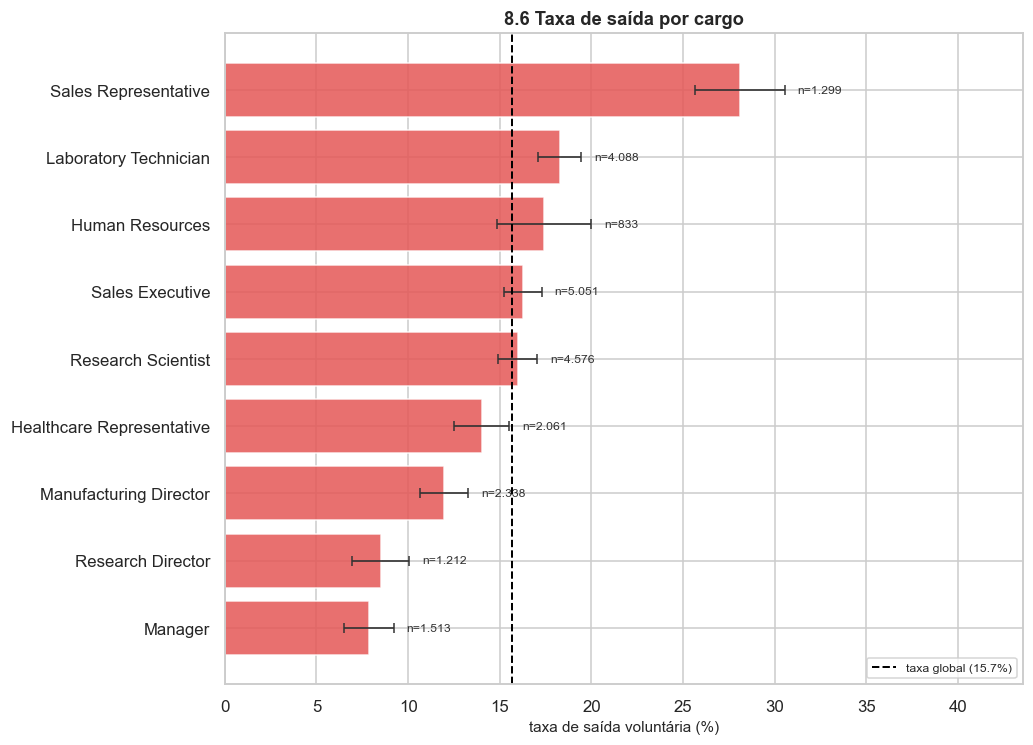

                            taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global?     alerta
JobRole                                                                                                   
Sales Representative      28.100  1299  25.700  30.500        2.400    12.400               SIM           
Laboratory Technician     18.300  4088  17.100  19.500        1.200     2.600               SIM           
Human Resources           17.400   833  14.800  20.000        2.600     1.700               não  n pequeno
Sales Executive           16.300  5051  15.300  17.300        1.000     0.600               não           
Research Scientist        16.000  4576  14.900  17.000        1.100     0.300               não           
Healthcare Representative 14.000  2061  12.500  15.500        1.500    -1.700               SIM           
Manufacturing Director    12.000  2338  10.700  13.300        1.300    -3.700               SIM           
Research Director          8.500  121

In [39]:
tabela_cargo = grafico_taxa("JobRole", "8.6 Taxa de saída por cargo", mostrar_tabela=True)

# Relacionando com o perfil do passo 7.12: a taxa de saída acompanha o salário do cargo?
print("\n\nA TAXA DE SAÍDA DO CARGO x O PERFIL DO CARGO\n")
perfil = (base.groupby("JobRole", observed=True)
          .agg(n=("saiu", "size"), taxa_saída=("saiu", "mean"),
               salário_mediano=("MonthlyIncome", "median"),
               idade_mediana=("Age", "median"),
               nível_mediano=("JobLevel", "median"))
          .sort_values("taxa_saída", ascending=False))
perfil["taxa_saída"] = (perfil["taxa_saída"] * 100).round(1)
print(perfil.round(1).to_string())

# A correlação entre a taxa do cargo e o salário mediano do cargo (9 pontos, um por cargo)
r = perfil["taxa_saída"].corr(perfil["salário_mediano"])
print(f"\nCorrelação entre a taxa de saída do cargo e o salário mediano do cargo: r = {r:+.2f}")
print("(calculada sobre 9 observações - os 9 cargos -, por isso é indicativa, não conclusiva)")

**A leitura.** `Sales Representative` tem **28,1%**, com folga a maior taxa da base — quase o dobro da
média da empresa. Na outra ponta, `Manager` (**7,9%**) e `Research Director` (**8,5%**) são os mais
estáveis.

**Insight 1 — a previsão do passo 7.12 se confirmou.** Os cargos de maior saída são exatamente os de
entrada: salário mediano baixo, idade baixa, nível hierárquico 1. Os de menor saída são os de topo. A
correlação negativa entre a taxa do cargo e o salário mediano do cargo é forte.

**Insight 2 — o mecanismo.** São três forças atuando no mesmo sentido para o perfil júnior: menos a
perder (salário e benefícios menores), mais oferta no mercado para esse perfil, e menos tempo
investido na relação com a empresa. Isso explica por que uma política de retenção uniforme não
funciona: **o risco não está distribuído igualmente, está concentrado numa posição estrutural.**

**Insight 3 — a ação que o achado sugere.** Como o risco se concentra em cargos identificáveis, a ação
pode ser dirigida: trilha de carreira e remuneração variável específicas para a função comercial de
entrada, que é onde a perda se concentra. Ação dirigida é mais barata e mais eficaz que ação geral.

**O que isso não diz.** Que o cargo cause a saída. Cargo agrega salário, nível, tipo de trabalho,
pressão, perfil de quem é contratado para ele e qualidade da gestão naquela área. Separar essas
camadas exige o modelo — e no passo 9.8 se verá que parte do efeito do cargo é, na verdade, efeito de
salário e de nível hierárquico.

## 8.7 Distância de casa: um efeito pequeno, mas real

**A pergunta de gestão.** Quem mora longe sai mais? A resposta tem implicação concreta: política de
trabalho remoto, auxílio-transporte, ou critério de alocação entre unidades.

**Por que este passo merece atenção.** No passo 7.14, a correlação de `DistanceFromHome` com a saída
foi muito fraca. Este passo mostra o que a correlação por faixas revela e o coeficiente de Pearson
tinha dificuldade de captar.

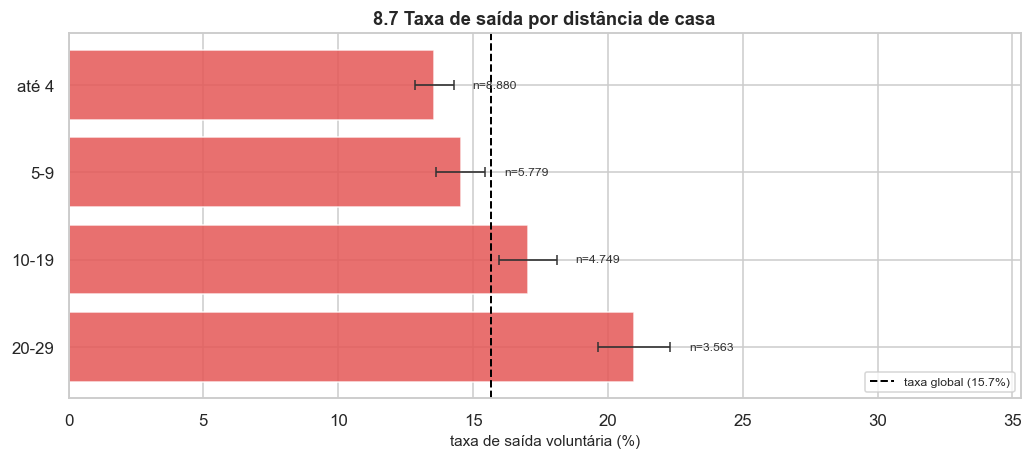

                 taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
FaixaDistancia                                                                             
até 4          13.600  8880  12.900  14.300        0.700    -2.100               SIM       
5-9            14.500  5779  13.600  15.400        0.900    -1.100               SIM       
10-19          17.000  4749  16.000  18.100        1.100     1.400               SIM       
20-29          21.000  3563  19.600  22.300        1.300     5.300               SIM       

Correlação de Pearson entre distância e saída: r = +0.072 (muito fraca)
Diferença entre a faixa mais distante e a mais próxima: +7.4 p.p.

As duas medidas descrevem a mesma relação. A segunda é mais informativa porque
não exige que a relação seja uma reta perfeita, e porque fala na unidade que o
gestor usa: pontos percentuais entre grupos concretos.

Distância mediana de quem ficou: 7
Distância mediana de quem saiu ..: 9


In [40]:
tabela_dist = grafico_taxa("FaixaDistancia", "8.7 Taxa de saída por distância de casa",
                           ordenar_por_taxa=False, mostrar_tabela=True)

# Comparando as duas medidas da MESMA relação:
r_pearson = base["DistanceFromHome"].corr(base["saiu"])
print(f"\nCorrelação de Pearson entre distância e saída: r = {r_pearson:+.3f} (muito fraca)")
print(f"Diferença entre a faixa mais distante e a mais próxima: "
      f"{(tabela_dist['taxa'].iloc[-1] - tabela_dist['taxa'].iloc[0]) * 100:+.1f} p.p.")
print("\nAs duas medidas descrevem a mesma relação. A segunda é mais informativa porque")
print("não exige que a relação seja uma reta perfeita, e porque fala na unidade que o")
print("gestor usa: pontos percentuais entre grupos concretos.")

# A mediana, para comparar com o boxplot do passo 8.13
print(f"\nDistância mediana de quem ficou: {base[base.saiu == 0]['DistanceFromHome'].median():.0f}")
print(f"Distância mediana de quem saiu ..: {base[base.saiu == 1]['DistanceFromHome'].median():.0f}")

**A leitura.** O gradiente é **monotônico**: **13,6%** entre quem mora a menos de 5 milhas, 14,5% de
5 a 9, 17,0% de 10 a 19 e **21,0%** entre os que moram a 20 milhas ou mais. São 7,4 pontos
percentuais entre os extremos, e o intervalo da faixa mais distante não cobre a taxa global.

**Insight.** Distância **importa**, de forma consistente e na direção esperada. O efeito é menor que o
de idade ou cargo, mas é real, ordenado e — decisivo para a gestão — **acionável por uma política que
a empresa controla**: trabalho remoto ou híbrido para as funções em que isso é viável, alocação por
proximidade quando há mais de uma unidade, auxílio-deslocamento.

**A lição metodológica, que é o motivo deste passo existir.** A correlação de Pearson entre distância
e saída é de apenas *r* ≈ 0,06 — "muito fraca", pela tabela do passo 7.14. Se a análise tivesse
parado no coeficiente, a variável teria sido descartada. **A taxa por faixa mostra uma relação clara
que o coeficiente não capturou.** Por que a divergência? Porque Pearson entre uma variável contínua e
uma binária é uma medida ruim por construção: ela mede o ajuste de uma **reta** a uma variável que só
assume os valores 0 e 1. **Nunca descarte uma variável só porque o *r* com a dependente é baixo.**

**O que isso não diz.** Que a distância cause a saída. Pode ser que, em certas faixas de preço de
moradia, quem mora longe tenha também salário menor — de novo, confundimento. O passo 9.8 estima o
efeito da distância **mantido o salário constante**.

## 8.8 Escolaridade e área de formação: efeitos fracos e um achado inesperado

**A pergunta de gestão.** O nível de instrução e a área de formação ajudam a prever permanência?
Candidatos mais qualificados ficam mais?

**Por que as duas no mesmo passo.** Porque medem a mesma dimensão — qualificação formal — e porque o
passo 7.13 já antecipou que a escolaridade varia pouco entre os cargos, de onde se esperava **efeito
fraco**. Vale verificar se a expectativa se confirma.

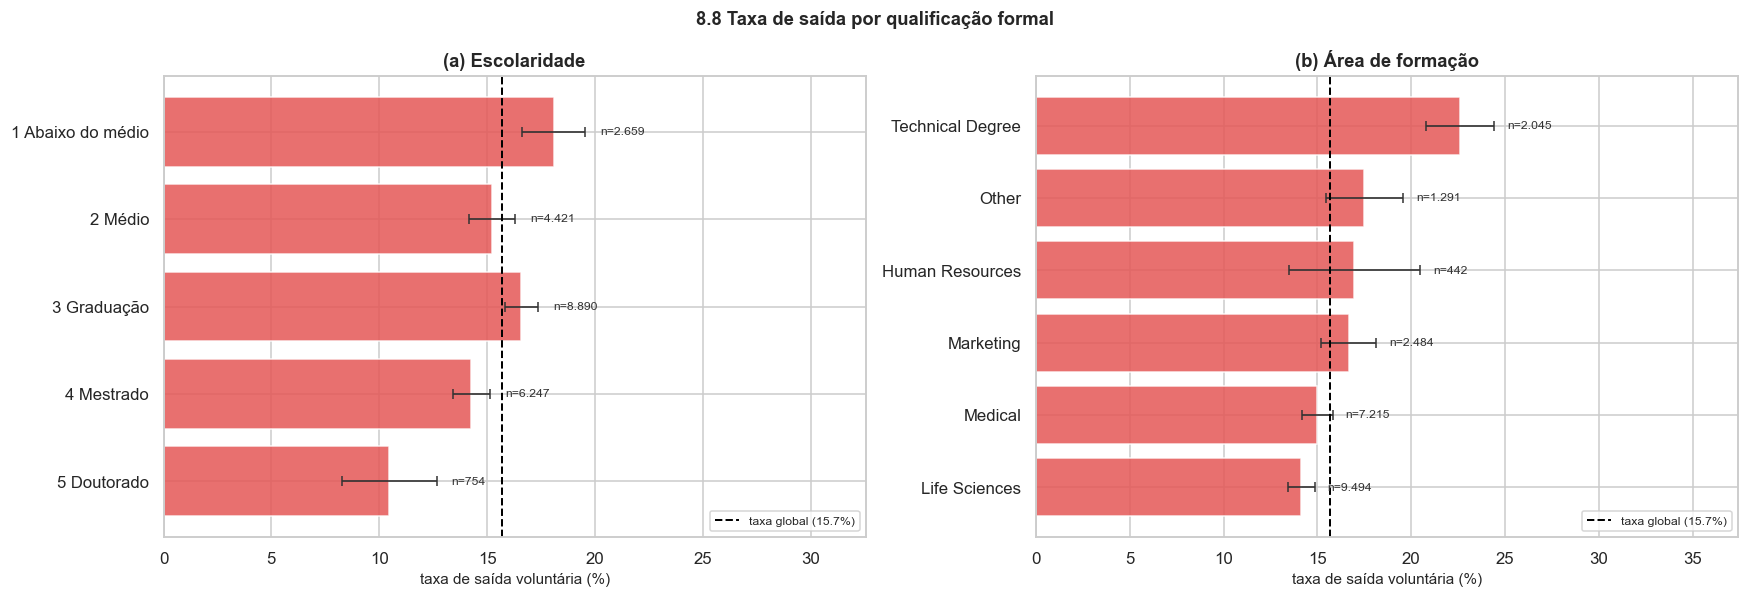

(a) ESCOLARIDADE

                    taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global?     alerta
_Education_rot                                                                                    
1 Abaixo do médio 18.100  2659   0.166   0.196        1.500     2.400               SIM           
2 Médio           15.200  4421   0.142   0.163        1.100    -0.400               não           
3 Graduação       16.600  8890   0.158   0.174        0.800     0.900               SIM           
4 Mestrado        14.300  6247   0.134   0.151        0.900    -1.400               SIM           
5 Doutorado       10.500   754   0.083   0.127        2.200    -5.200               SIM  n pequeno


(b) ÁREA DE FORMAÇÃO

                   taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global?     alerta
EducationField                                                                                   
Technical Degree 22.600  2045   0.208   0.244        1.800     6.900 

In [41]:
fig, eixos = plt.subplots(1, 2, figsize=(16, 5.5))

# Escolaridade é ORDINAL: mantemos a ordem da escala
base["_Education_rot"] = rotular(base["Education"])
grafico_taxa("_Education_rot", "(a) Escolaridade", ordenar_por_taxa=False, eixo=eixos[0])

# Área de formação é NOMINAL: ordenamos pela taxa
grafico_taxa("EducationField", "(b) Área de formação", eixo=eixos[1])

fig.suptitle("8.8 Taxa de saída por qualificação formal", fontweight="bold")
plt.tight_layout()
plt.show()

print("(a) ESCOLARIDADE\n")
print(taxa_saida_por("_Education_rot", ordenar_por_taxa=False)
      .assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())
print("\n\n(b) ÁREA DE FORMAÇÃO\n")
print(taxa_saida_por("EducationField")
      .assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())

**A leitura de (a).** Há um gradiente suave e na direção esperada: **18,1%** entre os de escolaridade
mais baixa, em torno de 15-16% nas faixas intermediárias, **14,3%** entre mestres e **10,5%** entre
doutores. A amplitude total é de 7,6 pontos percentuais, mas as faixas intermediárias são
praticamente indistinguíveis entre si.

**Insight.** O efeito existe, é **fraco e pouco útil** para decisão. A diferença relevante está nos
extremos, e o extremo superior — doutorado, com n = 754 — é um grupo pequeno, cuja taxa baixa
provavelmente reflete o **cargo** que esse perfil ocupa (pesquisa sênior, nível hierárquico alto) mais
do que o diploma. A expectativa formada no passo 7.13 se confirmou.

**A leitura de (b), e aqui há um achado inesperado.** `Technical Degree` tem **22,6%**, bem acima de
todas as outras áreas e da taxa global, com n = 2.045 — grupo grande o bastante para que o intervalo
seja estreito. As demais áreas ficam entre 14% e 17,5%.

**Insight.** Formação técnica aparece associada a saída substancialmente maior. Duas explicações
concorrentes, e a base não as separa: (i) esse perfil é empregado em cargos de entrada, de maior
rotatividade; (ii) o perfil técnico tem mais demanda no mercado externo e, portanto, mais alternativas.
A primeira é confundimento com cargo; a segunda seria um efeito próprio da formação. **Distinguir as
duas exige controle por cargo** — feito no passo 9.4, onde se verá que parte deste efeito não resiste.

**Sobre `Human Resources`, com n = 442.** Taxa de 17,0%, acima da média, mas em um grupo pequeno. Pela
regra do passo 8.1, não há base para afirmar diferença: a margem de erro é larga.

**O que isso não diz.** Nada que justifique usar escolaridade como critério de seleção para reduzir
atrito. O efeito é fraco, provavelmente indireto, e há um motivo adicional de prudência: filtrar
candidatos por diploma estreita o funil de recrutamento para ganhar, aqui, pouquíssimo em retenção.

## 8.9 Gênero: como se reporta um resultado nulo

**A pergunta de gestão.** Homens e mulheres saem em proporções diferentes?

**Por que este passo é importante justamente por não achar nada.** Resultado nulo é resultado, e
reportá-lo com o mesmo cuidado de um resultado positivo é parte da honestidade analítica. Este passo
também mostra **como** se diz, em linguagem precisa, que não se encontrou diferença — sem afirmar
mais do que o dado permite.

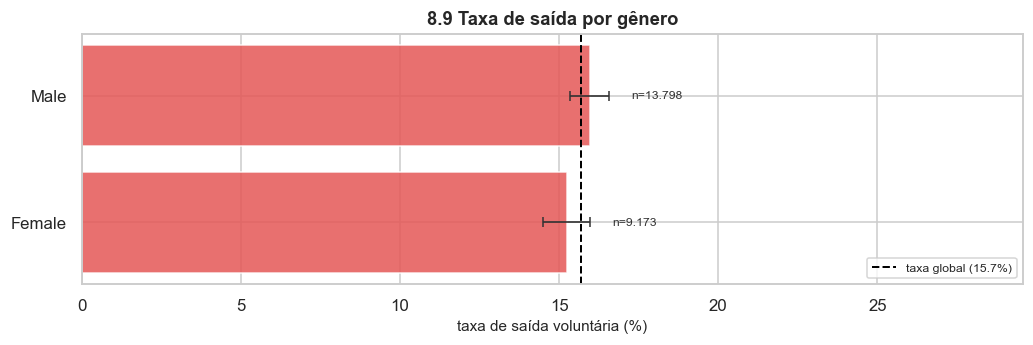

         taxa      n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
Gender                                                                              
Male   16.000  13798  15.400  16.600        0.600     0.300               não       
Female 15.200   9173  14.500  16.000        0.700    -0.400               não       

diferença absoluta ....... 0.7 ponto percentual
razão entre as taxas ..... 1.048

IC 95% mulheres: 0.145 a 0.160
IC 95% homens ..: 0.154 a 0.166

Os intervalos se sobrepõem? SIM
Intervalos sobrepostos = não há evidência de diferença entre os grupos.


In [42]:
tabela_genero = grafico_taxa("Gender", "8.9 Taxa de saída por gênero", mostrar_tabela=True)

taxa_f = tabela_genero.loc["Female", "taxa"]
taxa_m = tabela_genero.loc["Male",   "taxa"]

print(f"\ndiferença absoluta ....... {abs(taxa_m - taxa_f) * 100:.1f} ponto percentual")
print(f"razão entre as taxas ..... {max(taxa_m, taxa_f) / min(taxa_m, taxa_f):.3f}")

# Os intervalos se sobrepõem? Esta é a verificação que sustenta a conclusão.
print(f"\nIC 95% mulheres: {tabela_genero.loc['Female', 'ic_inf']:.3f} a "
      f"{tabela_genero.loc['Female', 'ic_sup']:.3f}")
print(f"IC 95% homens ..: {tabela_genero.loc['Male', 'ic_inf']:.3f} a "
      f"{tabela_genero.loc['Male', 'ic_sup']:.3f}")
sobrepoem = (tabela_genero.loc["Female", "ic_sup"] > tabela_genero.loc["Male", "ic_inf"]
             and tabela_genero.loc["Male", "ic_sup"] > tabela_genero.loc["Female", "ic_inf"])
print(f"\nOs intervalos se sobrepõem? {'SIM' if sobrepoem else 'não'}")
print("Intervalos sobrepostos = não há evidência de diferença entre os grupos.")

**A leitura.** Mulheres **15,2%**, homens **16,0%**: diferença de **0,8 ponto percentual**. Os
intervalos de confiança se sobrepõem amplamente, e ambos contêm a taxa global.

**Insight.** **Não há evidência de diferença na taxa de saída voluntária entre homens e mulheres
nesta base.** Combinado com o passo 7.11, que não encontrou desvantagem salarial agregada, o quadro
é de ausência de diferenças brutas por gênero nas duas dimensões examinadas.

**Como se escreve isso corretamente, e a diferença não é retórica.** Duas frases parecidas, com
significados muito diferentes:

| Frase | Correta? | Por quê |
|---|---|---|
| "Não há evidência de diferença entre os grupos" | **Sim** | Descreve o que o dado mostra: nada detectável |
| "Não há diferença entre os grupos" | **Não** | Afirma a ausência de efeito, que o dado não pode provar |
| "Não há discriminação de gênero na empresa" | **Não** | Extrapola de uma taxa para uma conclusão sobre processos que não foram medidos |

Com n grande como este, a ausência de diferença é um resultado **informativo** — o estudo tinha
potência para detectar uma diferença de poucos pontos percentuais, e não detectou. Em amostra
pequena, o mesmo resultado nulo seria pouco informativo, porque poderia ser apenas falta de potência.
**É o n que dá valor ao resultado nulo**, e é por isso que ele vem sempre ao lado da taxa.

**Consequência para a Parte 9.** Variável sem associação bivariada tende a não contribuir no modelo.
Essa expectativa será testada: uma das versões do modelo é ajustada **sem** gênero, justamente para
verificar se o desempenho muda (passo 9.6).

**O que isso não diz.** Nada sobre equidade de promoção, de acesso a cargos de liderança ou de
tratamento cotidiano. São outras perguntas, com outras variáveis — e o fato de a saída não diferir não
autoriza conclusão sobre nenhuma delas.

## 8.10 Experiência anterior e estabilidade: o histórico prevê o futuro?

**A pergunta de gestão.** O histórico profissional do candidato ajuda a prever quanto tempo ele vai
ficar? Especificamente: quem já passou por muitas empresas tende a sair de novo?

**O elemento.** Uso das variáveis construídas no passo 5.2 — `AverageTenure` (estabilidade média em
empregos anteriores) e `PrimeiroEmprego` —, mais a contagem bruta de empresas anteriores. É o teste
de uma crença corrente em seleção: a de que histórico de permanências curtas sinaliza propensão a
sair.

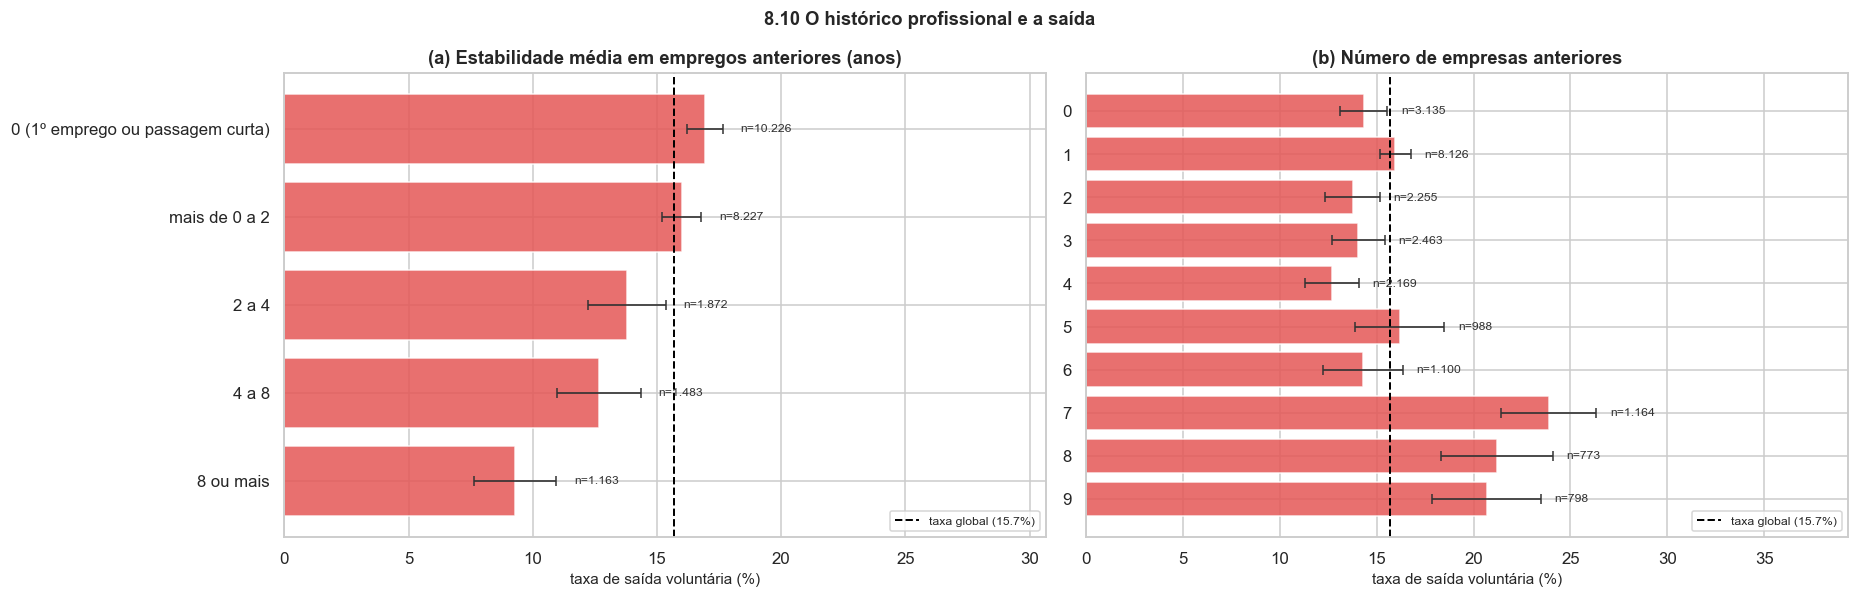

(a) ESTABILIDADE MÉDIA ANTERIOR

                                   taxa      n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
_FaixaTenure                                                                                                  
0 (1º emprego ou passagem curta) 16.900  10226   0.162   0.177        0.700     1.300               SIM       
mais de 0 a 2                    16.000   8227   0.152   0.168        0.800     0.300               não       
2 a 4                            13.800   1872   0.122   0.153        1.600    -1.900               SIM       
4 a 8                            12.700   1483   0.110   0.144        1.700    -3.000               SIM       
8 ou mais                         9.300   1163   0.076   0.110        1.700    -6.400               SIM       


(b) NÚMERO DE EMPRESAS ANTERIORES

                     taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global?     alerta
NumCompaniesWorked                                   

In [43]:
base["_FaixaTenure"] = pd.cut(
    base["AverageTenure"],
    bins=[-0.01, 0.001, 2, 4, 8, 50],
    labels=["0 (1º emprego ou passagem curta)", "mais de 0 a 2", "2 a 4", "4 a 8", "8 ou mais"])

fig, eixos = plt.subplots(1, 2, figsize=(17, 5.5))
grafico_taxa("_FaixaTenure", "(a) Estabilidade média em empregos anteriores (anos)",
             ordenar_por_taxa=False, eixo=eixos[0])
grafico_taxa("NumCompaniesWorked", "(b) Número de empresas anteriores",
             ordenar_por_taxa=False, eixo=eixos[1])
fig.suptitle("8.10 O histórico profissional e a saída", fontweight="bold")
plt.tight_layout()
plt.show()

print("(a) ESTABILIDADE MÉDIA ANTERIOR\n")
print(taxa_saida_por("_FaixaTenure", ordenar_por_taxa=False)
      .assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())

print("\n\n(b) NÚMERO DE EMPRESAS ANTERIORES\n")
print(taxa_saida_por("NumCompaniesWorked", ordenar_por_taxa=False)
      .assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())

print("\n\n(c) PRIMEIRO EMPREGO (a indicadora criada no passo 5.2)\n")
print(taxa_saida_por("PrimeiroEmprego", ordenar_por_taxa=False)
      .assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())

**A leitura de (a).** Há gradiente, e na direção esperada: **16,9%** entre os de estabilidade zero,
16,0% na faixa de até 2 anos, caindo a **9,3%** entre os que permaneceram 8 anos ou mais em cada
empresa anterior. Quem tem histórico de permanências longas **permanece mais** aqui também.

**A leitura de (b).** O padrão não é uma reta: fica em torno de 13-16% até cinco empresas, e **salta
para 23,9% em sete empresas**, 21,2% em oito e 20,7% em nove. O salto está nos extremos.

**Insight 1 — o histórico prevê, mas de forma não linear.** A crença da seleção se confirma **apenas
no extremo**: não é "mais empresas, mais risco" de forma proporcional. É "a partir de um certo número
de passagens, o risco sobe nitidamente". Para o recrutamento, isso é mais útil que um gradiente,
porque define um **ponto de atenção** no currículo em vez de uma penalização contínua.

**Insight 2 — o valor da variável construída.** `AverageTenure` tem um gradiente mais limpo que a
contagem bruta de empresas, e isso mostra por que a engenharia de atributos do passo 5.2 valeu a pena:
**anos divididos por empresas** é uma medida mais informativa que o número de empresas sozinho, porque
distingue quem passou por cinco empresas em vinte anos de quem passou por cinco em seis anos.

**Insight 3 — a armadilha do zero, que o passo 5.2 anunciou.** A primeira faixa de (a) mistura dois
perfis opostos: quem está no **primeiro emprego** e quem teve **passagens brevíssimas**. Por isso a
tabela (c) existe. E ela mostra algo importante: quem está no primeiro emprego sai **menos** (14,3%)
que a média, e não mais. Ou seja, os dois perfis que o zero mistura têm comportamentos **diferentes** —
confirmando que tratá-los como um só valor numérico, como seria tentador, embaralharia o resultado. É
por isso que a indicadora `PrimeiroEmprego` entra separadamente no modelo da Parte 9.

**O que isso não diz.** Que histórico de muitas passagens cause a saída. Pode ser característica de
certas carreiras técnicas, de certos setores ou de certo momento do mercado. E um alerta de uso: usar
"número de empregos anteriores" como filtro de seleção penalizaria quem foi demitido em reestruturação
— situação sobre a qual a pessoa não teve controle algum.

---

## Bloco B. Variáveis conhecidas só depois da contratação

Daqui em diante, as variáveis não servem para selecionar candidatos — servem para **gerir quem já
está dentro**. É aqui que o diagnóstico vira ação, e é por isso que os próximos passos são os mais
diretamente úteis para o RH.

## 8.11 Hora extra: o fator mais acionável da base

**A pergunta de gestão.** Quem faz hora extra pede demissão com mais frequência?
**O mecanismo esperado.** Sobrecarga sustentada deteriora o equilíbrio entre trabalho e vida pessoal,
que reduz a satisfação, que aumenta a disposição a aceitar uma proposta externa.

**Por que este passo também ensina três medidas diferentes.** A mesma diferença entre dois grupos pode
ser expressa de três formas, e elas **não são intercambiáveis**. Saber qual usar em cada contexto é
parte do ofício, e este é o passo em que as três são calculadas lado a lado.

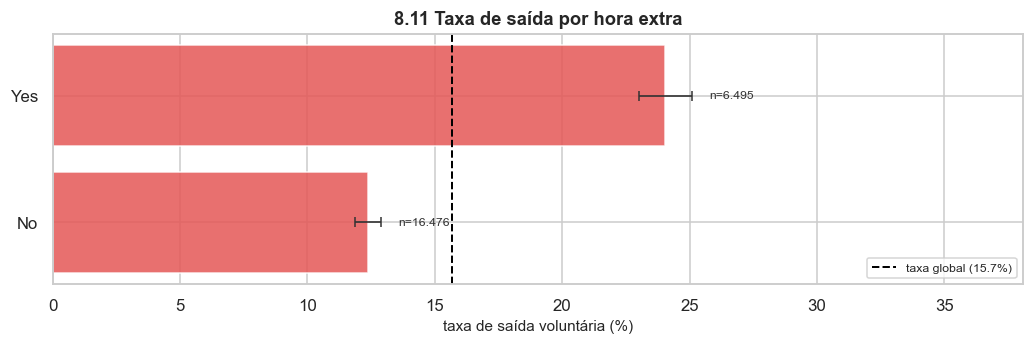

           taxa      n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
OverTime                                                                              
Yes      24.000   6495  23.000  25.100        1.000     8.400               SIM       
No       12.400  16476  11.900  12.900        0.500    -3.300               SIM       


A MESMA DIFERENÇA, EM TRÊS MEDIDAS

1. Diferença absoluta ...... 11.7 pontos percentuais
   'A taxa de saída é 11,7 p.p. maior entre quem faz hora extra.'
   -> a linguagem da planilha e da meta. É a medida do IMPACTO no quadro.

2. Risco relativo .......... 1.94x
   'Quem faz hora extra é quase 2 vezes mais propenso a sair.'
   -> a linguagem da conversa com o gestor. Comunica FORÇA, mas sem o
      tamanho do grupo pode exagerar: 2x de 0,1% para 0,2% é irrelevante.

3. Razão de chances (OR) ... 2.24
   chance com hora extra: 0.317 | sem: 0.141
   -> a medida que a REGRESSÃO LOGÍSTICA estima (Parte 9). Não é o mesmo
      que risco relativo,

In [44]:
tabela_overtime = grafico_taxa("OverTime", "8.11 Taxa de saída por hora extra",
                               mostrar_tabela=True)

taxa_sim = tabela_overtime.loc["Yes", "taxa"]
taxa_nao = tabela_overtime.loc["No",  "taxa"]

print("\n\nA MESMA DIFERENÇA, EM TRÊS MEDIDAS\n")
print(f"1. Diferença absoluta ...... {(taxa_sim - taxa_nao) * 100:.1f} pontos percentuais")
print("   'A taxa de saída é 11,7 p.p. maior entre quem faz hora extra.'")
print("   -> a linguagem da planilha e da meta. É a medida do IMPACTO no quadro.")

print(f"\n2. Risco relativo .......... {taxa_sim / taxa_nao:.2f}x")
print("   'Quem faz hora extra é quase 2 vezes mais propenso a sair.'")
print("   -> a linguagem da conversa com o gestor. Comunica FORÇA, mas sem o")
print("      tamanho do grupo pode exagerar: 2x de 0,1% para 0,2% é irrelevante.")

chance_sim = taxa_sim / (1 - taxa_sim)
chance_nao = taxa_nao / (1 - taxa_nao)
print(f"\n3. Razão de chances (OR) ... {chance_sim / chance_nao:.2f}")
print(f"   chance com hora extra: {chance_sim:.3f} | sem: {chance_nao:.3f}")
print("   -> a medida que a REGRESSÃO LOGÍSTICA estima (Parte 9). Não é o mesmo")
print("      que risco relativo, e confundir os dois é erro frequente de leitura.")

# Quantas saídas estariam em jogo? A tradução do p.p. para número de pessoas.
n_com_hora_extra = int(tabela_overtime.loc["Yes", "n"])
excedente = n_com_hora_extra * (taxa_sim - taxa_nao)
print(f"\n\nTRADUÇÃO PARA O QUE INTERESSA À GESTÃO")
print(f"  funcionários que fazem hora extra ......... {n_com_hora_extra:,}".replace(",", "."))
print(f"  saídas 'excedentes' associadas a eles ..... {excedente:.0f} pessoas")
print("  (quantas saídas a mais ocorreram nesse grupo, em comparação com a taxa")
print("   de quem não faz hora extra. NÃO é o número que uma política evitaria:")
print("   isso dependeria de o efeito ser causal, o que este dado não estabelece.)")

**A leitura.** **24,0%** entre quem faz hora extra, contra **12,4%** entre quem não faz: praticamente
**o dobro**. Os dois grupos têm milhares de casos, os intervalos são estreitos e não se sobrepõem.

**Insight — e é o achado central do bloco B.** Hora extra é, ao mesmo tempo, **fortemente associada à
saída** e **diretamente controlável pela empresa**. Essa combinação é rara: idade, estado civil e
formação não são acionáveis; cargo e salário são caros de mudar. Hora extra se gerencia com
dimensionamento de equipe, redistribuição de carga e teto de jornada. É o achado com melhor relação
entre força da evidência e custo da intervenção.

**As três medidas, e quando usar cada uma.** O quadro impresso acima resume: pontos percentuais para
dimensionar o impacto, risco relativo para comunicar, razão de chances para modelar. A diferença entre
risco relativo (1,94) e razão de chances (2,24) não é erro de cálculo — são medidas distintas, e a
razão de chances é sempre mais distante de 1 quando o evento é frequente. Confundi-las faz o efeito
parecer maior do que é.

**Três ressalvas que precisam acompanhar o número em qualquer apresentação:**

1. **Associação não é causa.** É possível que a hora extra cause a saída. É igualmente possível que
   áreas com gestão deficiente **exijam** mais hora extra **e** produzam mais saídas — com a hora
   extra sendo apenas o sintoma visível de um problema de gestão. Os dados aqui não separam as duas
   histórias.
2. **A ordem temporal não está medida.** A base não tem data. Quem já decidiu sair pode reduzir a hora
   extra, ou aumentá-la para fechar entregas antes de pedir as contas. Sem data, não há como saber o
   que veio primeiro.
3. **A variável é grosseira.** "Faz hora extra" é binária e não distingue duas horas por mês de vinte
   por semana. Uma variável binária onde o fenômeno é contínuo **subestima** a associação real.

**O encaminhamento que o analista deve propor.** Como a ressalva 1 é decisiva para a decisão de
gestão, a resposta não é mais análise desta base — é um **piloto**: aplicar teto de horas em algumas
áreas comparáveis e não em outras, e acompanhar a taxa de saída por alguns trimestres. Isso está
detalhado na Parte 11.3.

## 8.12 Viagens a trabalho: um gradiente limpo numa variável ordinal

**A pergunta de gestão.** Viajar a trabalho desgasta a ponto de levar à saída?

**O elemento.** Variável **ordinal** com três níveis, e o que se procura é **monotonicidade**: a taxa
muda de forma consistente conforme a frequência de viagem aumenta?

**Por que a ordem do gráfico é obrigatória aqui.** Esta variável **não** é ordenada por taxa, como as
nominais dos passos anteriores, e sim pela ordem da escala — porque é a **sequência** que carrega a
informação. Ordenar por taxa destruiria o achado.

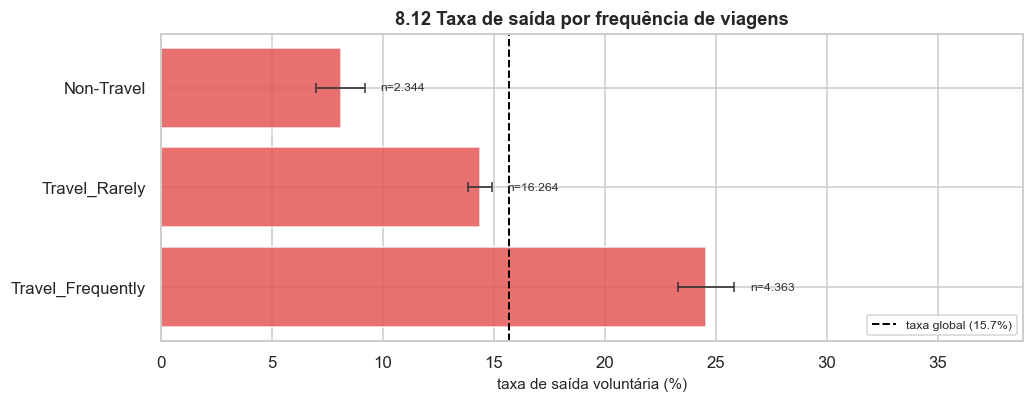

                    taxa      n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
BusinessTravel                                                                                 
Non-Travel         8.100   2344   7.000   9.200        1.100    -7.600               SIM       
Travel_Rarely     14.400  16264  13.800  14.900        0.500    -1.300               SIM       
Travel_Frequently 24.600   4363  23.300  25.800        1.300     8.900               SIM       


O GRADIENTE, PASSO A PASSO

  de 'Non-Travel' para 'Travel_Rarely': +6.3 p.p.
  de 'Travel_Rarely' para 'Travel_Frequently': +10.2 p.p.

Entre os extremos: 8.1% -> 24.6% = 3.0x


In [45]:
tabela_viagem = grafico_taxa("BusinessTravel", "8.12 Taxa de saída por frequência de viagens",
                             ordenar_por_taxa=False, mostrar_tabela=True)

print("\n\nO GRADIENTE, PASSO A PASSO\n")
anterior = None
for categoria, linha in tabela_viagem.iterrows():
    if anterior is not None:
        delta = (linha["taxa"] - anterior) * 100
        print(f"  de '{rotulo_anterior}' para '{categoria}': {delta:+.1f} p.p.")
    anterior, rotulo_anterior = linha["taxa"], categoria

extremos = tabela_viagem["taxa"]
print(f"\nEntre os extremos: {extremos.iloc[0]:.1%} -> {extremos.iloc[-1]:.1%} "
      f"= {extremos.iloc[-1] / extremos.iloc[0]:.1f}x")

**A leitura.** Gradiente perfeitamente monotônico: **8,1%** entre quem não viaja, **14,4%** entre quem
viaja raramente e **24,6%** entre quem viaja com frequência. Cada degrau da escala acrescenta taxa, e
os três intervalos de confiança são disjuntos.

**Insight.** Quem viaja com frequência sai **três vezes** mais que quem não viaja. É o segundo maior
contraste da Parte 8, atrás apenas da faixa de idade — e, como a hora extra, é uma variável que a
empresa **controla**: rotação de quem viaja dentro da equipe, substituição de parte das viagens por
reunião remota, compensação específica para a função que viaja muito.

**Por que o gradiente monotônico é uma evidência mais forte que uma diferença isolada.** Se apenas um
dos níveis se destacasse, a explicação mais provável seria alguma peculiaridade daquele grupo. Mas
quando a taxa sobe **a cada degrau**, no sentido esperado pelo mecanismo (desgaste acumulado), o padrão
é consistente com uma relação de dose-resposta. Não prova causalidade — nada aqui prova —, mas é o
tipo de padrão que a torna mais plausível.

**Uma antecipação importante para a Parte 9.** Guarde este achado: 24,6% contra 8,1%. Na Parte 9, com
o controle por cargo, nível e salário, o efeito da viagem vai aparecer **ainda maior** do que aqui. A
razão é que quem viaja muito tende a ter cargo e salário mais altos, e isso **protege** — ou seja, os
dois efeitos estão em sentidos opostos e se cancelam parcialmente na tabela bruta. Este é o exemplo
mais claro, em todo o notebook, de por que a análise bivariada pode **subestimar** um efeito.

**O que isso não diz.** Qual aspecto da viagem desgasta: se é o tempo fora de casa, a imprevisibilidade
da agenda, o cansaço físico ou a natureza da função que exige viagem. A variável mede frequência, não
mecanismo. Investigar isso exigiria dado qualitativo — entrevista, pesquisa dirigida —, e essa é uma
recomendação legítima a fazer no relatório.

## 8.13 Salário: o boxplot e os quartis, e por que a mediana engana aqui

**A pergunta de gestão.** Quem ganha menos sai mais? Quanto se ganharia, em retenção, com uma revisão
salarial?

**O elemento.** Dois instrumentos para a **mesma** variável contínua, de propósito:

1. o **boxplot** comparando a distribuição salarial de quem saiu e de quem ficou;
2. a **taxa de saída por quartil de salário**, que é a variável contínua convertida em grupos.

**Por que os dois.** Porque eles mostram coisas diferentes, e a comparação entre as duas leituras é a
lição deste passo. O boxplot compara **distribuições**; a taxa por quartil compara **grupos de risco**.

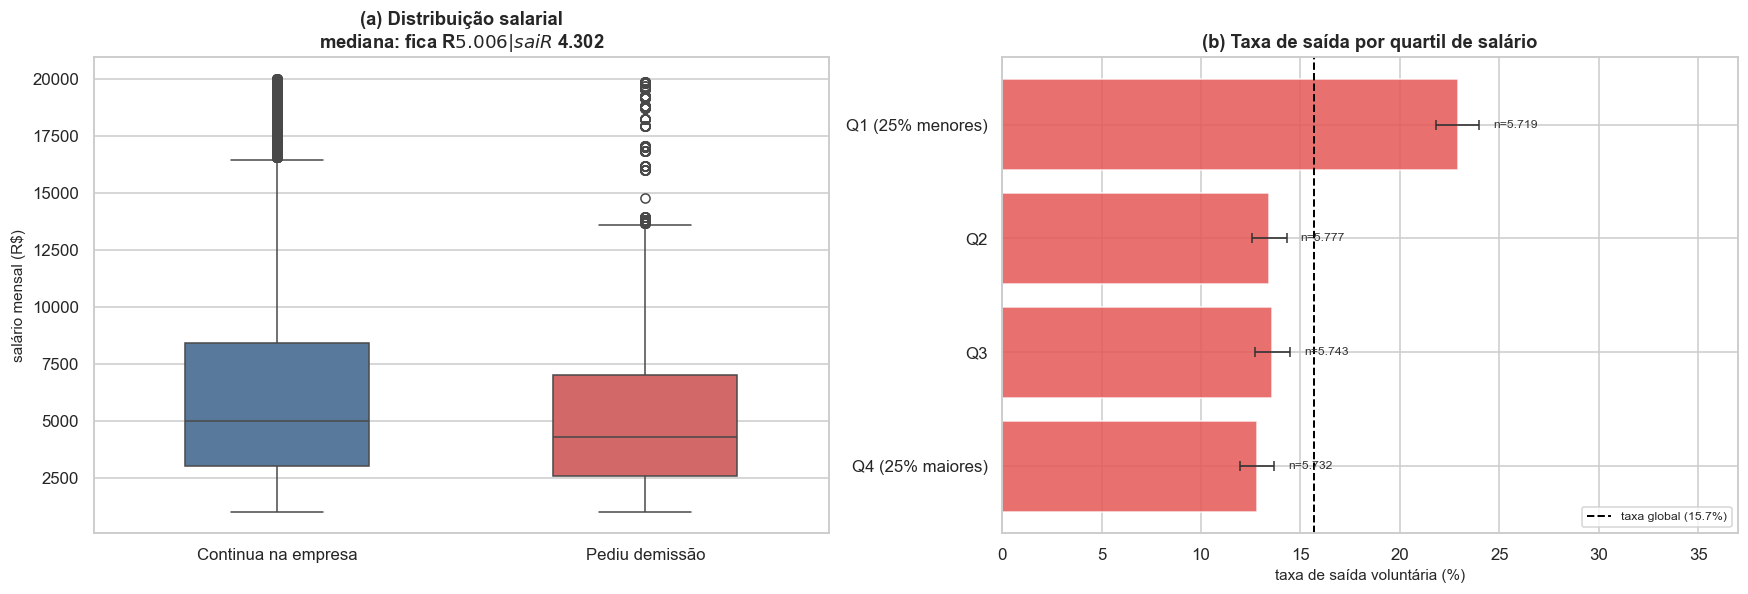

(a) AS DISTRIBUIÇÕES COMPARADAS

                         n        Q1   mediana        Q3     média
situacao                                                          
Continua na empresa  19370 3,033.000 5,006.000 8,396.000 6,588.000
Pediu demissão        3601 2,564.000 4,302.000 7,005.000 5,504.000


(b) A TAXA POR QUARTIL

                   taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
QuartilSalario                                                                               
Q1 (25% menores) 22.900  5719   0.218   0.240        1.100     7.200               SIM       
Q2               13.400  5777   0.126   0.143        0.900    -2.200               SIM       
Q3               13.600  5743   0.127   0.145        0.900    -2.100               SIM       
Q4 (25% maiores) 12.800  5732   0.120   0.137        0.900    -2.900               SIM       

Q1 (25% menores salários) .. 22.9%
Q2, Q3 e Q4 (os outros 75%)  13.4%, 13.6%, 12.8%

Diferença Q1 x média do

In [46]:
fig, eixos = plt.subplots(1, 2, figsize=(16, 5.5))

# --- (a) O boxplot: distribuição salarial de quem saiu x quem ficou -------
sns.boxplot(data=base, x="situacao", y="MonthlyIncome", ax=eixos[0],
            order=["Continua na empresa", "Pediu demissão"],
            hue="situacao", palette=PALETA_ATRITO, legend=False, width=0.5)
medianas = base.groupby("situacao", observed=True)["MonthlyIncome"].median()
eixos[0].set(title=f"(a) Distribuição salarial\nmediana: fica R$ "
                   f"{medianas['Continua na empresa']:,.0f} | sai R$ "
                   f"{medianas['Pediu demissão']:,.0f}".replace(",", "."),
             xlabel="", ylabel="salário mensal (R$)")

# --- (b) A taxa de saída por quartil de salário ---------------------------
grafico_taxa("QuartilSalario", "(b) Taxa de saída por quartil de salário",
             ordenar_por_taxa=False, eixo=eixos[1])

plt.tight_layout()
plt.show()

print("(a) AS DISTRIBUIÇÕES COMPARADAS\n")
print(base.groupby("situacao", observed=True)["MonthlyIncome"]
      .agg(n="size", Q1=lambda s: s.quantile(.25), mediana="median",
           Q3=lambda s: s.quantile(.75), média="mean").round(0).to_string())

print("\n\n(b) A TAXA POR QUARTIL\n")
print(taxa_saida_por("QuartilSalario", ordenar_por_taxa=False)
      .assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())

q = taxa_saida_por("QuartilSalario", ordenar_por_taxa=False)["taxa"]
print(f"\nQ1 (25% menores salários) .. {q.iloc[0]:.1%}")
print(f"Q2, Q3 e Q4 (os outros 75%)  {q.iloc[1]:.1%}, {q.iloc[2]:.1%}, {q.iloc[3]:.1%}")
print(f"\nDiferença Q1 x média dos demais: "
      f"{(q.iloc[0] - q.iloc[1:].mean()) * 100:+.1f} p.p.")

**A leitura de (a).** Quem pediu demissão tem mediana salarial de **R$ 4.302**, contra **R$ 5.006** de
quem ficou — cerca de R$ 700 de diferença. Mas as **caixas se sobrepõem quase inteiramente**: a
distribuição de quem sai está deslocada para baixo, não separada.

**A leitura de (b), e é aqui que está o achado.** A taxa por quartil **não** é um gradiente: é um
**degrau**. O primeiro quartil — os 25% de menores salários — sai a **23,0%**, enquanto os três
quartis superiores ficam todos em torno de **13%**, praticamente indistinguíveis entre si.

**Insight.** **O problema salarial está concentrado na base da pirâmide, e não distribuído ao longo
dela.** Essa é uma informação de altíssimo valor prático, porque muda completamente a recomendação:

- Se a relação fosse um **gradiente**, a conclusão seria "aumentar salário reduz saída em qualquer
  faixa" — e a política teria de ser geral, isto é, caríssima.
- Sendo um **degrau**, a conclusão é "existe um patamar abaixo do qual o risco salta" — e a política
  pode ser **dirigida ao primeiro quartil**, com custo muito menor e efeito concentrado onde o risco
  está.

**A lição metodológica: por que (a) quase esconde o que (b) mostra.** O boxplot compara **medianas**, e
a mediana é uma medida de **centro**. O fenômeno aqui não está no centro, está num **pedaço** da
distribuição — a cauda inferior. Uma diferença de R$ 700 entre medianas parece modesta e sugere "efeito
pequeno"; a taxa por quartil revela um grupo com taxa 10 pontos percentuais acima dos demais. **Quando
o efeito se concentra numa faixa, a comparação de medianas o dilui.** É o mesmo tipo de erro que o
passo 8.14 mostra em outra variável.

**O que isso não diz.** Que aumentar o salário do primeiro quartil reduziria a saída em 10 pontos. O
primeiro quartil salarial é também o quartil dos cargos de entrada, dos mais jovens e dos de nível
hierárquico 1 — tudo isso já identificado como fator de risco. **Salário aqui pode ser o rótulo de
"posição de entrada".** Separar o efeito do salário do efeito da posição é precisamente a função da
Parte 9, e o passo 9.8 mostra que o salário mantém efeito próprio depois do controle — mas menor.

## 8.14 Tempo de empresa: a curva de risco, e a mediana que mente

**A pergunta de gestão.** Em que momento da trajetória o risco de perder a pessoa é maior? A resposta
define **quando** agir — e agir no momento certo é mais barato que agir sempre.

**Por que este passo é o mais contraintuitivo da Parte 8.** No passo 8.13 ficou dito que comparar
medianas pode diluir um efeito concentrado. Aqui o caso é extremo: a mediana de tempo de empresa é
**exatamente igual** nos dois grupos — 5 anos para quem fica e 5 anos para quem sai —, e ainda assim a
variável tem um dos padrões mais fortes da base.

O QUE A COMPARAÇÃO DE MEDIANAS DIZ

situacao                 Continua na empresa  Pediu demissão
YearsAtCompany                         5.000           5.000
PercentSalaryHike                     14.000          14.000
YearsSinceLastPromotion                1.000           1.000

Três variáveis com mediana IDÊNTICA nos dois grupos. Um relatório que
parasse aqui concluiria que as três são irrelevantes. Veja o que acontece
quando a mesma variável é examinada por faixas:



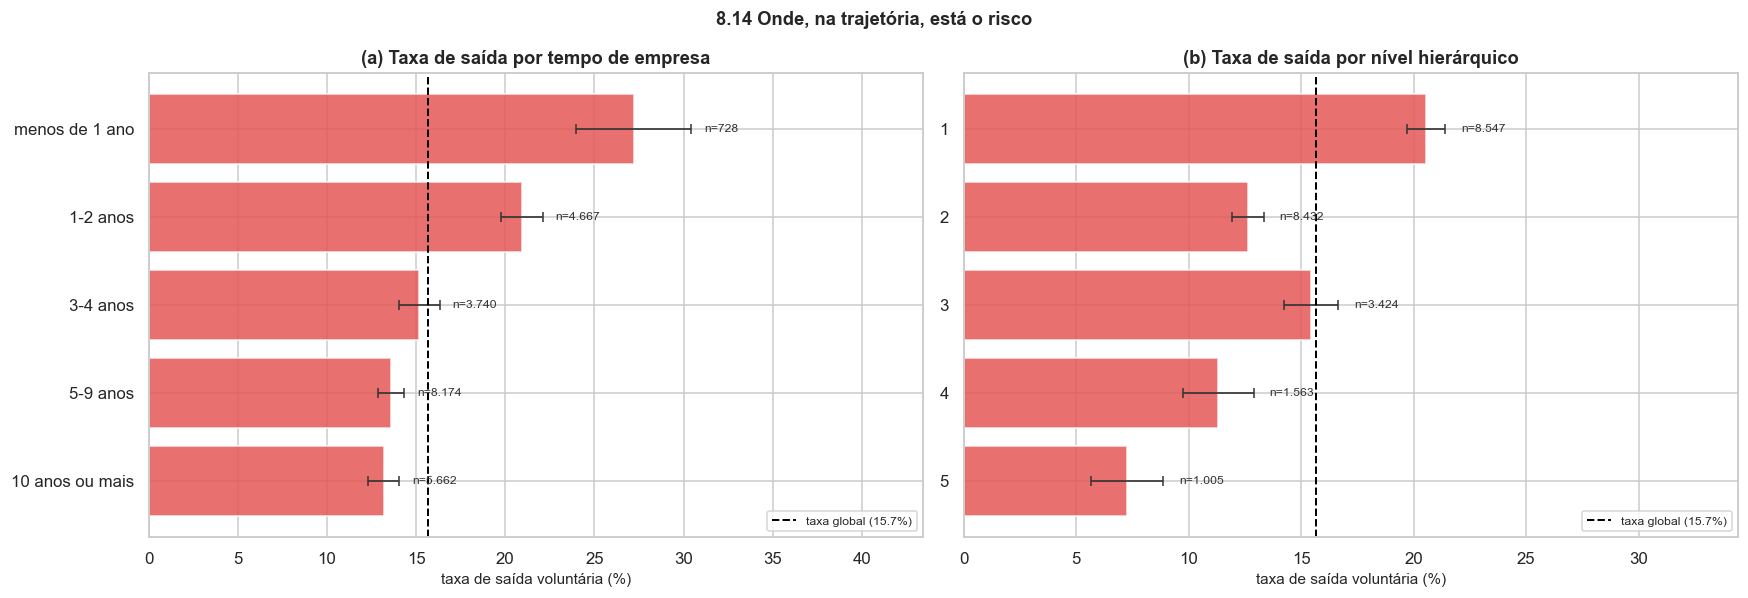

(a) TEMPO DE EMPRESA

                    taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global?     alerta
FaixaTempoEmpresa                                                                                 
menos de 1 ano    27.200   728   0.240   0.304        3.200    11.500               SIM  n pequeno
1-2 anos          20.900  4667   0.198   0.221        1.200     5.300               SIM           
3-4 anos          15.200  3740   0.140   0.163        1.200    -0.500               não           
5-9 anos          13.600  8174   0.129   0.143        0.700    -2.100               SIM           
10 anos ou mais   13.200  5662   0.123   0.141        0.900    -2.500               SIM           


(b) NÍVEL HIERÁRQUICO

           taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
JobLevel                                                                             
1        20.600  8547   0.197   0.214        0.900     4.900               SIM       
2 

In [47]:
# Primeiro a comparação de medianas, que é o que um boxplot mostraria:
print("O QUE A COMPARAÇÃO DE MEDIANAS DIZ\n")
print(base.groupby("situacao", observed=True)[["YearsAtCompany", "PercentSalaryHike",
                                               "YearsSinceLastPromotion"]]
      .median().T.to_string())
print("\nTrês variáveis com mediana IDÊNTICA nos dois grupos. Um relatório que")
print("parasse aqui concluiria que as três são irrelevantes. Veja o que acontece")
print("quando a mesma variável é examinada por faixas:\n")

fig, eixos = plt.subplots(1, 2, figsize=(16, 5.5))
grafico_taxa("FaixaTempoEmpresa", "(a) Taxa de saída por tempo de empresa",
             ordenar_por_taxa=False, eixo=eixos[0])
grafico_taxa("JobLevel", "(b) Taxa de saída por nível hierárquico",
             ordenar_por_taxa=False, eixo=eixos[1])
fig.suptitle("8.14 Onde, na trajetória, está o risco", fontweight="bold")
plt.tight_layout()
plt.show()

print("(a) TEMPO DE EMPRESA\n")
tempo = taxa_saida_por("FaixaTempoEmpresa", ordenar_por_taxa=False)
print(tempo.assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())

print("\n\n(b) NÍVEL HIERÁRQUICO\n")
print(taxa_saida_por("JobLevel", ordenar_por_taxa=False)
      .assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())

print(f"\n\nA CURVA DE RISCO: {tempo['taxa'].iloc[0]:.1%} no primeiro ano, "
      f"caindo para {tempo['taxa'].iloc[-1]:.1%} depois de 10 anos.")
print(f"Risco relativo entre os extremos: {tempo['taxa'].iloc[0] / tempo['taxa'].iloc[-1]:.1f}x")

**A leitura de (a).** A taxa cai de forma monotônica com o tempo de casa: **27,2%** entre quem tem
menos de um ano, **20,9%** de 1 a 2 anos, 15,2% de 3 a 4, 13,6% de 5 a 9 e **13,2%** com 10 anos ou
mais.

**Insight 1 — a curva de risco.** O risco de perder alguém é **mais que o dobro no primeiro ano** em
comparação com quem já passou de dez anos. Isso é um padrão conhecido em rotatividade e tem
consequência prática imediata: **a janela crítica é a integração e os dois primeiros anos.** Toda a
literatura de gestão de pessoas aponta para o mesmo lugar, e o dado desta empresa confirma. Ação:
programa estruturado de integração, acompanhamento nos primeiros 90 dias, primeira avaliação precoce.

**Insight 2 — e aqui está a lição que justifica este passo.** A **mediana** de tempo de empresa é
**5 anos nos dois grupos**. Idêntica. Um boxplot não mostraria nada, e um relatório que se baseasse
apenas na comparação de medianas concluiria que tempo de empresa é irrelevante — **exatamente o
oposto** do que a curva mostra. Por quê? Porque o efeito está na **cauda inferior** da distribuição
(o primeiro ano), não no centro. E medida de centro nenhuma captura cauda.

**A regra prática que sai daqui, e vale para toda análise descritiva:** antes de descartar uma
variável porque as medianas são parecidas, **examine-a por faixas**. Mediana igual **não** significa
distribuição igual. As três variáveis impressas no começo da célula têm mediana idêntica nos dois
grupos; tempo de empresa, como se viu, é fortíssima. (Reajuste salarial e anos sem promoção,
examinados no passo 8.17, são de fato fracas — mas isso só se sabe depois de examinar, não antes.)

**A leitura de (b).** O nível hierárquico tem gradiente igualmente claro: **20,6%** no nível de entrada
contra **7,3%** no nível 5. Confirma, por outro ângulo, o mesmo achado dos passos 8.6 e 8.13 — o risco
se concentra na base da estrutura.

**O que isso não diz.** Que ficar na empresa reduza a vontade de sair. Há aqui um efeito de **seleção**
que não se pode ignorar: quem chegou aos dez anos de casa é, por definição, quem **não** saiu — pessoas
com maior propensão a sair já saíram antes. Parte da queda da curva é esse efeito de sobrevivência, e
não uma mudança de atitude das mesmas pessoas ao longo do tempo. Distinguir as duas coisas exigiria
acompanhar coortes ao longo do tempo, o que esta base não permite.

## 8.15 As quatro escalas de satisfação: lendo a forma de cada uma

**A pergunta de gestão.** A satisfação declarada antecipa a saída? E qual das quatro dimensões
antecipa melhor?

**O elemento.** Comparação de **quatro variáveis ordinais** na mesma escala de 1 a 4, lado a lado. O
que se procura em cada uma é a **forma**: gradiente regular, degrau, ou ausência de padrão.

**Por que a forma importa tanto.** Porque ela decide como a variável entra no modelo da Parte 9:

| Forma observada | Significado | Como entra no modelo |
|---|---|---|
| **Gradiente** regular | Cada ponto da escala vale aproximadamente o mesmo | Como **numérica**: um coeficiente só, econômico |
| **Degrau** | Só um nível se distingue dos demais | Como **indicadora** daquele nível, ou categórica |
| **Sem padrão** | A escala não ordena o risco | Categórica, ou fora do modelo |

**Esta decisão não se toma olhando a tabela de números: toma-se olhando o gráfico.** É o melhor
exemplo, em todo o notebook, de análise exploratória servindo diretamente à especificação do modelo.

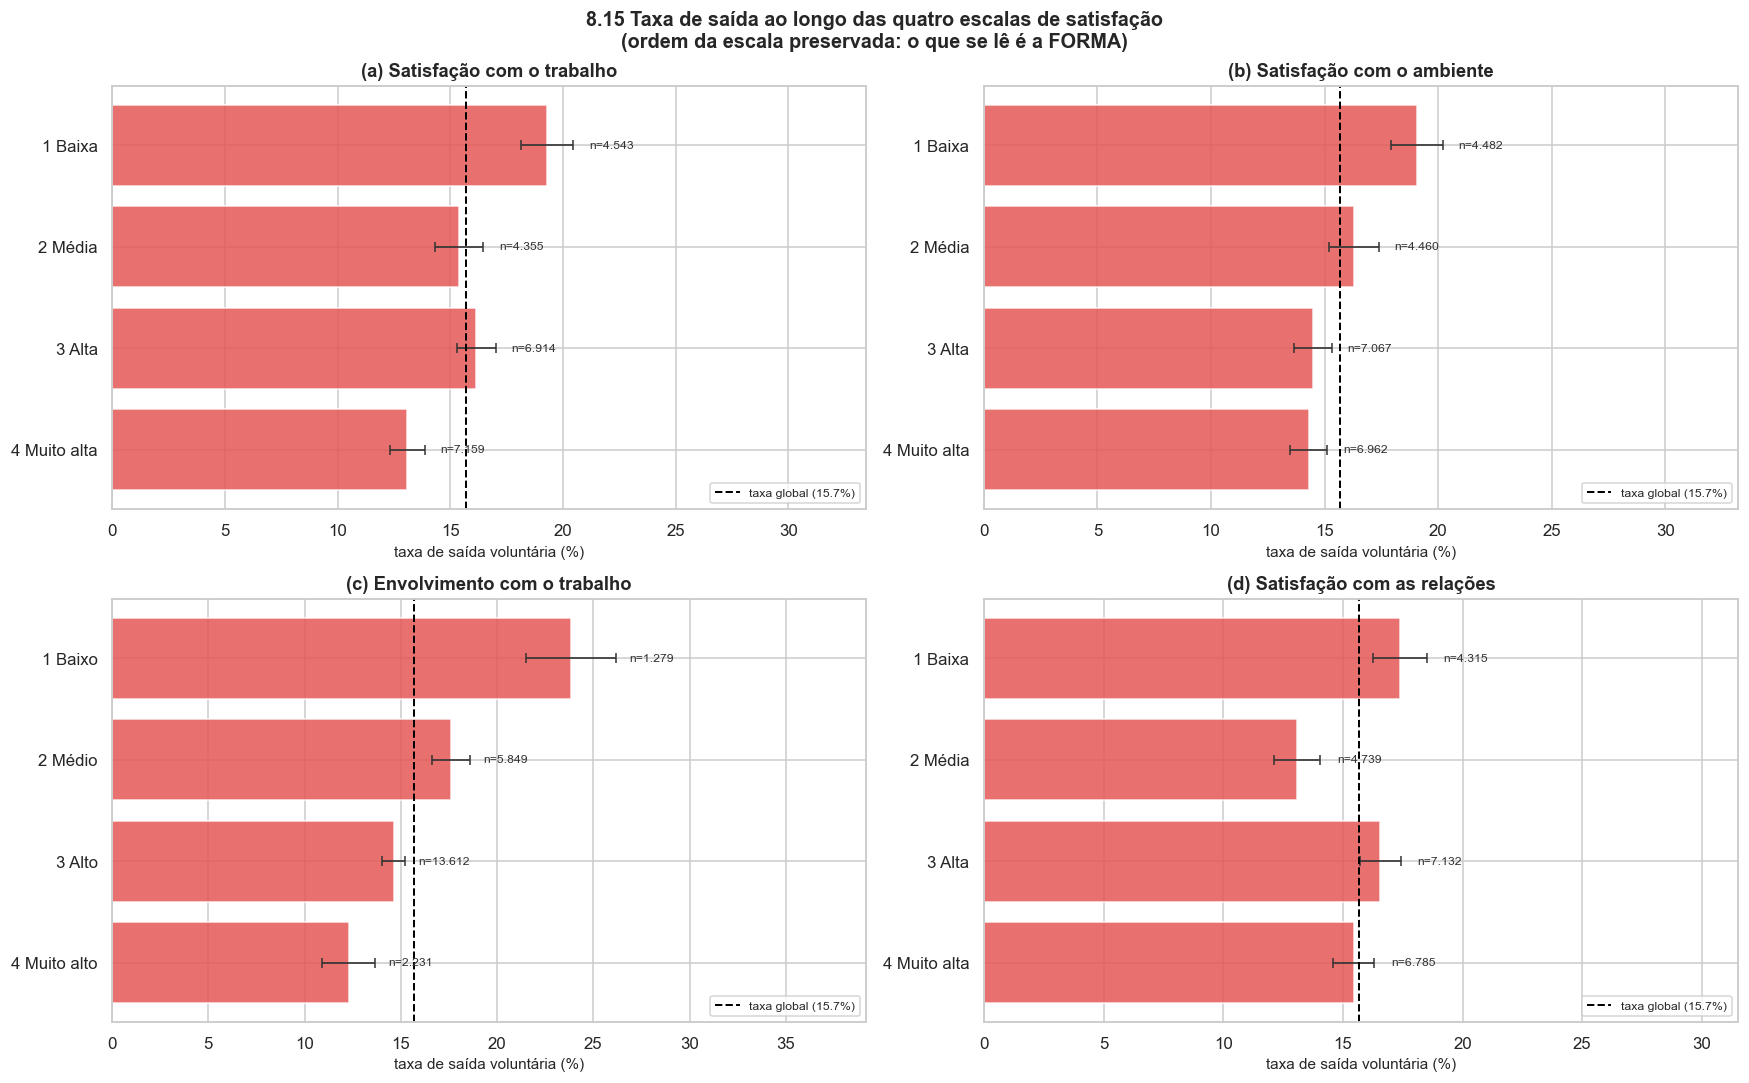

A FORMA DE CADA ESCALA, MEDIDA

                            nível 1 nível 4  amplitude (p.p.) sempre decrescente?
escala                                                                           
Satisfação com o trabalho     19.3%   13.1%             6.200                 NÃO
Satisfação com o ambiente     19.1%   14.3%             4.700                 sim
Envolvimento com o trabalho   23.8%   12.3%            11.600                 sim
Satisfação com as relações    17.4%   15.5%             1.900                 NÃO


In [48]:
escalas = [
    ("JobSatisfaction",          "(a) Satisfação com o trabalho"),
    ("EnvironmentSatisfaction",  "(b) Satisfação com o ambiente"),
    ("JobInvolvement",           "(c) Envolvimento com o trabalho"),
    ("RelationshipSatisfaction", "(d) Satisfação com as relações"),
]

fig, eixos = plt.subplots(2, 2, figsize=(16, 10))

for eixo, (coluna, titulo) in zip(eixos.ravel(), escalas):
    temporaria = f"_{coluna}_rot"
    base[temporaria] = rotular(base[coluna])
    grafico_taxa(temporaria, titulo, ordenar_por_taxa=False, eixo=eixo)
    eixo.set_ylabel("")

fig.suptitle("8.15 Taxa de saída ao longo das quatro escalas de satisfação\n"
             "(ordem da escala preservada: o que se lê é a FORMA)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Para cada escala: a amplitude (nível 1 menos nível 4) e se o declínio é monotônico
print("A FORMA DE CADA ESCALA, MEDIDA\n")
linhas = []
for coluna, titulo in escalas:
    t = taxa_saida_por(f"_{coluna}_rot", ordenar_por_taxa=False)["taxa"]
    diferencas = t.diff().dropna()
    linhas.append({
        "escala": titulo.split(") ")[1],
        "nível 1": f"{t.iloc[0]:.1%}",
        "nível 4": f"{t.iloc[-1]:.1%}",
        "amplitude (p.p.)": round((t.iloc[0] - t.iloc[-1]) * 100, 1),
        "sempre decrescente?": "sim" if (diferencas < 0).all() else "NÃO",
    })
print(pd.DataFrame(linhas).set_index("escala").to_string())

**A leitura, escala por escala — e as quatro têm formas diferentes:**

- **(c) Envolvimento com o trabalho** é a mais limpa: **23,8%** no nível 1, caindo monotonicamente a
  17,6%, 14,6% e **12,3%**. Amplitude de 11,5 pontos percentuais, com declínio a cada degrau.
- **(b) Satisfação com o ambiente** também é monotônica: 19,1% → 16,3% → 14,5% → **14,3%**, com
  amplitude de 4,8 p.p. Note que os níveis 3 e 4 são praticamente iguais: o ganho se esgota.
- **(a) Satisfação com o trabalho** tem amplitude de 6,2 p.p. (19,3% a 13,1%), mas **não é
  monotônica**: o nível 3 (16,2%) fica acima do nível 2 (15,4%). A tendência geral é clara, a
  regularidade não.
- **(d) Satisfação com as relações** **não tem padrão**: 17,4%, 13,1%, 16,6%, 15,5%. Sobe e desce sem
  ordem.

**Insight 1 — envolvimento é a melhor das quatro.** Quem declara baixo envolvimento sai praticamente
o dobro de quem declara envolvimento alto, com gradiente regular. Para o RH, essa é a pergunta que
mais vale manter na pesquisa de clima, se for preciso escolher.

**Insight 2 — "satisfação" não é uma coisa só.** As quatro escalas medem dimensões distintas e se
comportam de modo distinto. Tratá-las como um bloco único — ou, pior, somá-las num "índice de
satisfação" — misturaria uma escala forte e regular (envolvimento) com uma que não ordena nada
(relações), e o índice seria mais fraco que a melhor das partes. **Índice agregado só se justifica
quando os componentes se comportam de forma parecida**, e aqui não é o caso.

**Insight 3 — a decisão de especificação para a Parte 9**, que sai direto da coluna "sempre
decrescente?":

- envolvimento e satisfação com o ambiente → entram como **numéricas** (gradiente aproximadamente
  regular, um coeficiente descreve bem, economia de parâmetros);
- satisfação com o trabalho → **numérica**, com a ressalva de que a irregularidade no meio da escala
  será absorvida como ruído;
- satisfação com as relações → esperar efeito **nulo** no modelo. Se aparecer significativa, é caso
  para desconfiar antes de celebrar.

**O que isso não diz, e a ressalva é séria.** A ordem temporal é desconhecida, e aqui isso é mais
grave que nas outras variáveis. A satisfação pode ter sido medida **depois** de a pessoa já ter
decidido sair — e, nesse caso, a insatisfação declarada seria **consequência** da decisão, não causa.
Com dado transversal e sem data, não há como distinguir. Além disso, satisfação é **autodeclarada**,
numa escala de quatro pontos, possivelmente respondida com receio de identificação: a medida tem
ruído, e ruído **atenua** qualquer associação real — o que significa que os efeitos aqui podem ser
maiores do que o medido.

## 8.16 Equilíbrio trabalho-vida e participação acionária

**As perguntas de gestão.** (a) Quem avalia mal o equilíbrio entre trabalho e vida pessoal sai mais?
(b) A participação acionária retém?

**Por que juntas.** Porque são as duas variáveis do bloco B que correspondem a **instrumentos de
gestão de naturezas opostas**: uma é um sintoma a monitorar (equilíbrio), a outra é um incentivo que a
empresa concede deliberadamente (*stock option*). E porque as duas trazem lições diferentes sobre
como ler um gráfico.

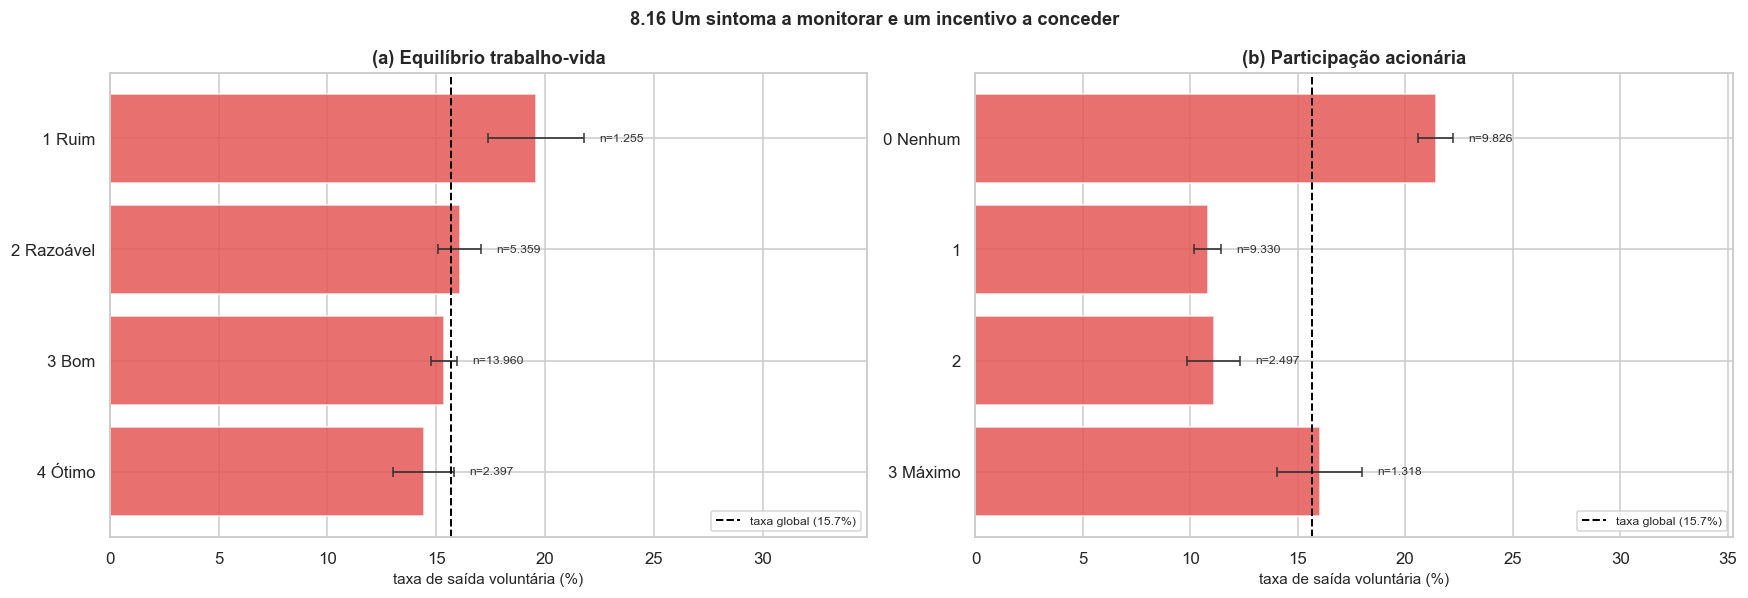

(a) EQUILÍBRIO TRABALHO-VIDA

                       taxa      n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
_WorkLifeBalance_rot                                                                              
1 Ruim               19.600   1255   0.174   0.218        2.200     3.900               SIM       
2 Razoável           16.100   5359   0.151   0.171        1.000     0.400               não       
3 Bom                15.400  13960   0.148   0.160        0.600    -0.300               não       
4 Ótimo              14.400   2397   0.130   0.158        1.400    -1.200               não       


(b) PARTICIPAÇÃO ACIONÁRIA

                        taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global? alerta
_StockOptionLevel_rot                                                                             
0 Nenhum              21.400  9826   0.206   0.222        0.800     5.700               SIM       
1                     10.800  9330   0.102   0.11

In [49]:
fig, eixos = plt.subplots(1, 2, figsize=(16, 5.5))

base["_WorkLifeBalance_rot"] = rotular(base["WorkLifeBalance"])
grafico_taxa("_WorkLifeBalance_rot", "(a) Equilíbrio trabalho-vida",
             ordenar_por_taxa=False, eixo=eixos[0])

base["_StockOptionLevel_rot"] = rotular(base["StockOptionLevel"])
grafico_taxa("_StockOptionLevel_rot", "(b) Participação acionária",
             ordenar_por_taxa=False, eixo=eixos[1])

fig.suptitle("8.16 Um sintoma a monitorar e um incentivo a conceder", fontweight="bold")
plt.tight_layout()
plt.show()

print("(a) EQUILÍBRIO TRABALHO-VIDA\n")
print(taxa_saida_por("_WorkLifeBalance_rot", ordenar_por_taxa=False)
      .assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())

print("\n\n(b) PARTICIPAÇÃO ACIONÁRIA\n")
print(taxa_saida_por("_StockOptionLevel_rot", ordenar_por_taxa=False)
      .assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())

# O cruzamento de (a) com a hora extra do passo 8.11: os dois efeitos se somam?
print("\n\nCRUZAMENTO: taxa de saída (%) por hora extra E equilíbrio trabalho-vida\n")
cruz = (base.pivot_table(index="OverTime", columns="_WorkLifeBalance_rot",
                         values="saiu", aggfunc="mean", observed=True) * 100).round(1)
print(cruz.to_string())
print("\nTamanho de cada célula (n):\n")
print(base.pivot_table(index="OverTime", columns="_WorkLifeBalance_rot",
                       values="saiu", aggfunc="size", observed=True).to_string())

**A leitura de (a).** O declínio é monotônico mas **modesto**: **19,6%** no nível 1 (equilíbrio ruim),
16,1%, 15,4% e **14,4%** no nível 4. Amplitude de 5,2 pontos percentuais, e os níveis 2, 3 e 4 ficam
próximos entre si.

**Insight.** O grupo que avalia o equilíbrio como **ruim** se destaca, e os demais são parecidos — a
forma é mais de **degrau** que de gradiente, embora o degrau não seja dramático na tabela bruta. É um
achado a combinar com o passo 7.11, onde esse mesmo grupo apareceu também com salário mais baixo:
**baixa remuneração e sobrecarga declarada coincidem**, o que faz desse grupo o mais prioritário da
base. Note o n: 1.255 pessoas no nível 1 — grupo pequeno, intervalo mais largo, mas identificável
nominalmente e, portanto, acionável caso por caso.

**A leitura de (b), que exige cuidado.** O nível 0 (nenhuma participação) sai a **21,4%**; os níveis 1
e 2 caem para **10,8%** e 11,1%; e o nível 3 **sobe de novo**, para 16,0%.

**Insight — e por que a subida no nível 3 não deve ser ignorada.** A queda do nível 0 para o 1 é
grande e consistente com o que se espera de um incentivo de longo prazo: quem tem participação tem
motivo financeiro para permanecer. Mas a subida no nível 3 **quebra o padrão**, e um analista honesto
não a varre para debaixo do tapete. Três explicações possíveis: (i) n = 1.318, o menor grupo, e o
intervalo é largo; (ii) o nível máximo é concedido a perfis muito específicos, com características
próprias; (iii) ruído. **A conduta correta é reportar o padrão principal com a anomalia declarada** —
"a participação acionária está associada a menor saída, com exceção não explicada no nível máximo" — em
vez de descrever um gradiente que não existe.

**Insight 3 — o cruzamento com hora extra, que antecipa a Parte 9.** A tabela cruzada mostra algo
importante: **em todos os níveis de equilíbrio, quem faz hora extra sai mais.** De 29,2% (hora extra
com equilíbrio ruim) a 20,5% (hora extra com equilíbrio ótimo), contra 11,9% a 15,9% entre quem não faz
hora extra. Ou seja, os dois efeitos **se somam** sem que um dependa do outro — o que, em linguagem de
modelagem, significa que não há forte **interação** entre eles. É uma informação útil: o modelo aditivo
da Parte 9 é adequado, e não é preciso complicá-lo com termos de interação para estas duas variáveis.

**O que isso não diz.** Em (b), há um problema de causalidade reversa evidente: **a empresa concede
participação acionária a quem quer reter**. Parte da associação é, portanto, a empresa **prevendo** quem
é valioso, não o incentivo **causando** permanência. Esse é um caso em que a direção da seta é
genuinamente ambígua, e nenhum modelo sobre esta base vai resolvê-la.

## 8.17 Treinamento, reajuste e desempenho: o que se mostrou fraco

**A pergunta de gestão.** Treinar retém? Reajustar retém? Quem tem desempenho melhor fica mais?

**Por que um passo dedicado ao que não funcionou.** Porque **reportar o que não deu resultado é parte
da análise**, e porque a seleção de achados — mostrar só o que confirma a tese — é a forma mais comum
de viés em relatório. Quem só apresenta as variáveis fortes dá a impressão de que todas as hipóteses se
confirmaram.

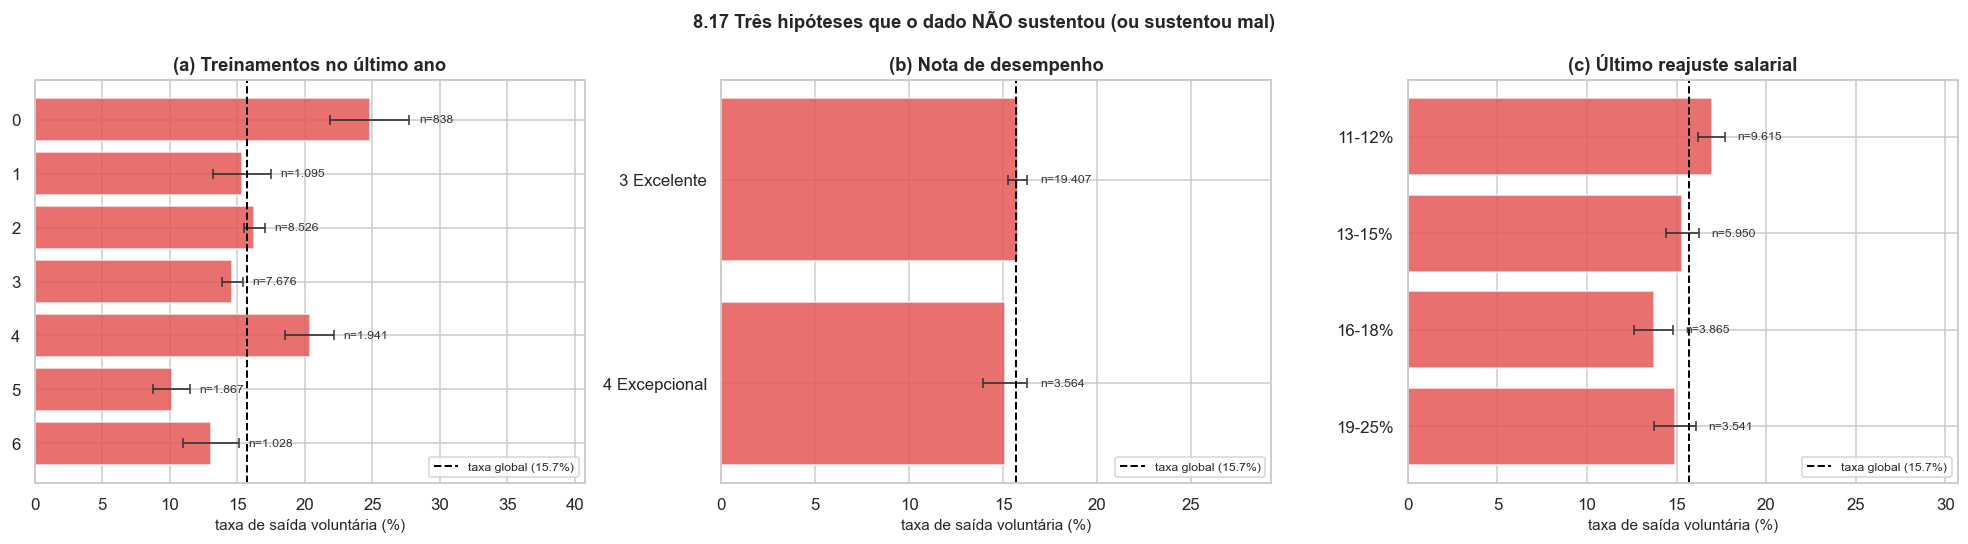


(a) TREINAMENTOS

                        taxa     n  ic_inf  ic_sup  margem_p.p.  dif_p.p. difere do global?     alerta
TrainingTimesLastYear                                                                                 
0                     24.800   838   0.219   0.277        2.900     9.100               SIM  n pequeno
1                     15.300  1095   0.132   0.175        2.100    -0.300               não           
2                     16.200  8526   0.155   0.170        0.800     0.600               não           
3                     14.600  7676   0.138   0.154        0.800    -1.100               SIM           
4                     20.400  1941   0.186   0.221        1.800     4.700               SIM           
5                     10.100  1867   0.088   0.115        1.400    -5.600               SIM           
6                     13.000  1028   0.110   0.151        2.100    -2.600               SIM           

(b) DESEMPENHO

                         taxa      n 

In [50]:
fig, eixos = plt.subplots(1, 3, figsize=(18, 5))

grafico_taxa("TrainingTimesLastYear", "(a) Treinamentos no último ano",
             ordenar_por_taxa=False, eixo=eixos[0])

base["_PerformanceRating_rot"] = rotular(base["PerformanceRating"])
grafico_taxa("_PerformanceRating_rot", "(b) Nota de desempenho",
             ordenar_por_taxa=False, eixo=eixos[1])

# Reajuste salarial: convertido em faixas, porque é contínuo
base["_FaixaReajuste"] = pd.cut(base["PercentSalaryHike"], bins=[10, 13, 16, 19, 26],
                                labels=["11-12%", "13-15%", "16-18%", "19-25%"])
grafico_taxa("_FaixaReajuste", "(c) Último reajuste salarial",
             ordenar_por_taxa=False, eixo=eixos[2])

fig.suptitle("8.17 Três hipóteses que o dado NÃO sustentou (ou sustentou mal)",
             fontweight="bold")
plt.tight_layout()
plt.show()

for coluna, titulo in [("TrainingTimesLastYear", "(a) TREINAMENTOS"),
                       ("_PerformanceRating_rot", "(b) DESEMPENHO"),
                       ("_FaixaReajuste", "(c) REAJUSTE")]:
    print(f"\n{titulo}\n")
    print(taxa_saida_por(coluna, ordenar_por_taxa=False)
          .assign(taxa=lambda d: (d["taxa"] * 100).round(1)).to_string())

**A leitura de (a) — treinamentos.** O padrão é **irregular**: **24,8%** entre quem não recebeu nenhum
treinamento (n = 838), depois 15,3%, 16,2%, 14,6%, e aí **20,4% em quatro treinamentos**, 10,1% em
cinco e 13,0% em seis. Sobe e desce.

**Insight.** O único achado defensável é o **extremo zero**: quem não recebeu treinamento algum sai
bem mais que a média. Isso é consistente com duas leituras — falta de investimento gera desengajamento,
ou pessoas já desengajadas não são indicadas para treinamento. O resto da escala **não ordena nada**, e
o salto em quatro treinamentos não tem explicação à vista. **Conclusão honesta:** há sinal no extremo,
não há gradiente. A recomendação que se sustenta é garantir um **piso mínimo** de treinamento por
pessoa, não maximizar o número.

**A leitura de (b) — desempenho.** 15,8% entre nota 3 e 15,1% entre nota 4. Diferença de 0,7 ponto
percentual, com intervalos sobrepostos. **Nenhum efeito detectável.**

**Insight — e esta é uma má notícia gerencial relevante.** A empresa **não** está perdendo
preferencialmente seus piores nem seus melhores: a saída é indiferente à nota de desempenho. Isso
descarta a hipótese otimista ("quem sai é quem não ia bem") e a pessimista ("estamos perdendo os
melhores"). Há ainda uma observação sobre a própria medida: a nota só assume os valores 3 e 4 nesta
base, o que sugere uma avaliação **inflacionada** — num instrumento em que todos são "bons" ou
"ótimos", a variável perde capacidade de discriminar qualquer coisa. **O achado pode ser mais sobre a
qualidade do instrumento de avaliação do que sobre o atrito**, e isso merece ir para o relatório.

**A leitura de (c) — reajuste.** As faixas ficam todas em torno da taxa global, sem ordem. **Nenhum
efeito.** Vale lembrar o passo 8.14: a mediana do reajuste é idêntica nos dois grupos — e aqui, ao
contrário do tempo de empresa, o exame por faixas **confirma** que não há nada. Foi preciso examinar
para saber.

**Insight.** O percentual do último reajuste não antecipa a saída. Uma explicação plausível: numa faixa
estreita de 11% a 25%, com inflação e política salarial relativamente uniformes, o reajuste varia pouco
entre as pessoas e, por isso, não diferencia. **Variável com pouca variação não explica variação** — é
uma regra geral que vale guardar.

**O fecho deste passo.** Das três hipóteses, uma teve sinal apenas no extremo e duas não tiveram nada.
Esse resultado tem valor de gestão direto: **economiza dinheiro**. Uma política de retenção construída
sobre "treinar mais" ou "reajustar mais" não teria, por este dado, apoio empírico — ao contrário da
política sobre hora extra, viagens e salário do primeiro quartil.

## 8.18 O fecho: por que a análise bivariada não basta

A Parte 8 produziu uma lista de fatores associados à saída. Este último passo mostra **por que essa
lista não pode ser a conclusão do estudo** — e, com isso, justifica a Parte 9.

**O problema tem nome: confundimento.** Toda taxa calculada até aqui é **bruta**: compara grupos que
diferem em **muitas coisas ao mesmo tempo**. Quando se compara a taxa de saída entre canais de
recrutamento, comparam-se também cargos diferentes, idades diferentes e salários diferentes, porque
canais diferentes alimentam vagas diferentes.

Isso produz **dois erros em direções opostas**, e os dois aparecem nesta base:

| Erro | O que acontece | Exemplo nesta base |
|---|---|---|
| **Superestimar** | A variável parece importar, mas o efeito é de outra, com a qual ela está misturada | Estado civil (8.4): boa parte é idade disfarçada |
| **Subestimar** | A variável importa mais do que parece, porque um efeito oposto a mascara | Viagens (8.12): quem viaja tem cargo e salário mais altos, que protegem |

A célula abaixo demonstra o primeiro caso com números desta base.

TAXA DE SAÍDA (%) POR ESTADO CIVIL, DENTRO DE CADA FAIXA DE IDADE

MaritalStatus  Divorced  Married  Single
FaixaIdade                              
18-24            35.400   27.000  49.600
25-29            13.200   19.800  30.900
30-34            10.500   15.700  27.100
35-44            10.700    7.700  12.300
45-54             6.700   10.300  12.900
55-60             7.100   17.400  21.600

n de cada célula:

MaritalStatus  Divorced  Married  Single
FaixaIdade                              
18-24               223      488     667
25-29               804     1555    1209
30-34              1178     2327    1572
35-44              1863     3756    2381
45-54               855     1870    1163
55-60               225      506     329


DIFERENÇA 'SOLTEIRO - CASADO', FAIXA POR FAIXA (p.p.)

FaixaIdade
18-24   22.600
25-29   11.100
30-34   11.400
35-44    4.600
45-54    2.600
55-60    4.200

Diferença BRUTA (sem controlar por idade): 9.3 p.p.
Diferença MÉDIA dentro das faixas de idade: 9.

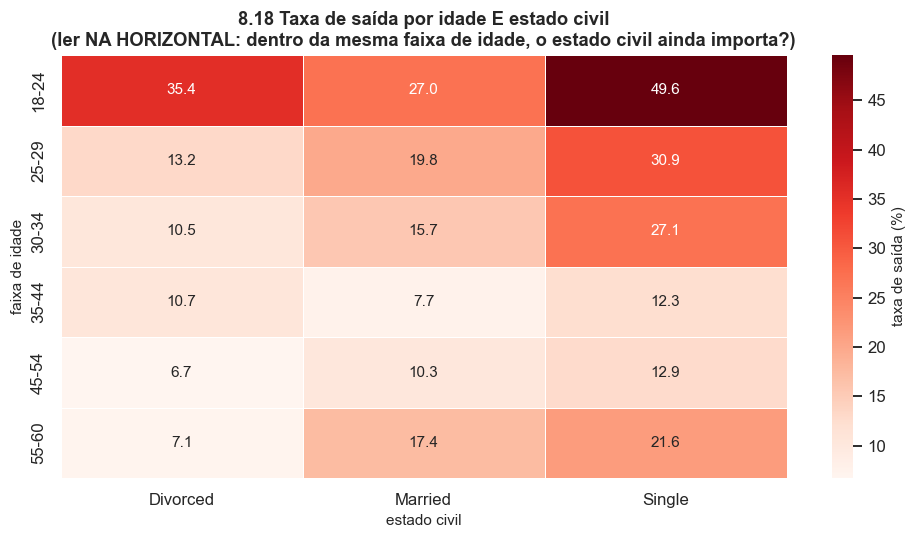

In [51]:
# DEMONSTRAÇÃO DE CONFUNDIMENTO
# A taxa de saída dos solteiros é alta (8.4). Mas solteiros são mais jovens (8.3).
# O que acontece se compararmos solteiros e casados DENTRO de cada faixa de idade?

print("TAXA DE SAÍDA (%) POR ESTADO CIVIL, DENTRO DE CADA FAIXA DE IDADE\n")
cruzada = (base.pivot_table(index="FaixaIdade", columns="MaritalStatus",
                            values="saiu", aggfunc="mean", observed=True) * 100).round(1)
tamanhos = base.pivot_table(index="FaixaIdade", columns="MaritalStatus",
                            values="saiu", aggfunc="size", observed=True)
print(cruzada.to_string())
print("\nn de cada célula:\n")
print(tamanhos.to_string())

# A diferença entre solteiros e casados, faixa por faixa:
print("\n\nDIFERENÇA 'SOLTEIRO - CASADO', FAIXA POR FAIXA (p.p.)\n")
diferenca = (cruzada["Single"] - cruzada["Married"]).round(1)
print(diferenca.to_string())
print(f"\nDiferença BRUTA (sem controlar por idade): "
      f"{(base[base.MaritalStatus == 'Single'].saiu.mean() - base[base.MaritalStatus == 'Married'].saiu.mean()) * 100:.1f} p.p.")
print(f"Diferença MÉDIA dentro das faixas de idade: {diferenca.mean():.1f} p.p.")

# O mapa de calor deixa o padrão visível de uma vez
fig, eixo = plt.subplots(figsize=(9, 5))
sns.heatmap(cruzada, annot=True, fmt=".1f", cmap="Reds", linewidths=0.5,
            cbar_kws={"label": "taxa de saída (%)"}, ax=eixo)
eixo.set(title="8.18 Taxa de saída por idade E estado civil\n"
               "(ler NA HORIZONTAL: dentro da mesma faixa de idade, o estado civil ainda importa?)",
         xlabel="estado civil", ylabel="faixa de idade")
plt.tight_layout()
plt.show()

**A leitura.** Lida **na horizontal** — dentro de cada faixa de idade —, a diferença entre solteiros e
casados **encolhe** em relação à diferença bruta, e em algumas faixas praticamente desaparece. Lida
**na vertical**, a idade continua produzindo variação grande dentro de cada estado civil.

**Insight.** **Parte do "efeito do estado civil" era efeito da idade.** A tabela cruzada já mostra o
que a Parte 9 vai confirmar com mais rigor: controlada a idade, o estado civil perde muito de sua
força. Quem recomendasse política a partir da taxa bruta de 22,4% estaria agindo sobre a variável
errada.

**Por que a tabela cruzada não resolve o problema, e a Parte 9 é necessária.** Esta célula controlou
**uma** variável. Mas há pelo menos uma dúzia de fatores relevantes nesta base, e controlá-los todos
por tabela cruzada é impossível por uma razão aritmética: cada variável acrescentada **multiplica** o
número de células. Seis faixas de idade × 3 estados civis × 9 cargos × 3 departamentos × 2 de hora
extra já dá **972 células** — e, com 22.971 funcionários, muitas delas ficariam com pouquíssimos casos
ou vazias. As taxas se tornariam instáveis, e o método se esgota.

**A solução é a regressão.** Um modelo multivariado faz, de uma vez e sem fragmentar a amostra, o que a
tabela cruzada faz para uma variável só: estima o efeito de cada fator **mantendo os demais constantes**.
Não é uma técnica mais sofisticada pelo gosto da sofisticação — é a resposta a um problema concreto que
a Parte 8 encontrou e não pode resolver.

---

## Síntese da Parte 8

| Fator | Bloco | Contraste bruto | Força | A examinar na Parte 9 |
|---|---|---|---|---|
| Faixa de idade | A | 39,3% (18-24) vs 9,8% (35-44) | muito forte | É efeito próprio ou de cargo e nível? |
| Cargo | A | 28,1% (Sales Rep.) vs 7,9% (Manager) | forte | Quanto sobra depois de controlar salário e nível? |
| Viagens frequentes | B | 24,6% vs 8,1% | forte | Deve **crescer** com o controle |
| Hora extra | B | 24,0% vs 12,4% | forte | Resiste ao controle por salário e cargo? |
| Tempo de empresa | B | 27,2% (<1 ano) vs 13,2% (10+) | forte | Efeito próprio ou seleção de sobreviventes? |
| 1º quartil de salário | B | 23,0% vs ~13% | forte (degrau) | É salário ou é posição de entrada? |
| Nível hierárquico | B | 20,6% (nível 1) vs 7,3% (nível 5) | forte | Redundante com cargo e salário? |
| Participação acionária | B | 21,4% (nenhuma) vs ~11% | moderada | Causalidade reversa provável |
| Envolvimento | B | 23,8% vs 12,3% | moderada | Gradiente limpo: entra como numérica |
| Estado civil | A | 22,4% vs 11,3% | moderada | **Já encolheu** ao controlar idade |
| Formação técnica | A | 22,6% vs ~15% | moderada | Confundida com cargo |
| Distância de casa | A | 21,0% vs 13,6% | moderada | Pequena, mas ordenada e acionável |
| Equilíbrio trabalho-vida | B | 19,6% vs 14,4% | fraca a moderada | Degrau no nível 1 |
| Canal de recrutamento | A | 18,8% vs 13,0% | fraca | Confundido com cargo; n pequeno em indicação |
| Escolaridade | A | 18,1% vs 10,5% | fraca | Provavelmente indireta, via cargo |
| Treinamentos | B | 24,8% (zero) vs ~14% | só no extremo | Sinal no zero, sem gradiente |
| Gênero | A | 16,0% vs 15,2% | **nenhuma** | Entra como controle |
| Desempenho | B | 15,8% vs 15,1% | **nenhuma** | Instrumento possivelmente inflacionado |
| Reajuste salarial | B | sem ordem | **nenhuma** | Pouca variação entre pessoas |

Dezenove fatores examinados, cada um com sua taxa, seu *n* e seu intervalo. **Nenhum deles foi
estimado mantendo os outros constantes** — e é isso que a próxima parte faz.

---

# Parte 9. Regressão logística: o modelo, construído em versões

## 9.1 Por que logística, e não linear

A variável dependente é **binária**: a pessoa pediu demissão (1) ou não (0). A regressão linear comum
é inadequada aqui, e não por preferência — por três razões técnicas:

1. Ela pode prever probabilidade **negativa** ou **maior que 1**, o que não existe.
2. Os pressupostos do método dos mínimos quadrados falham (os resíduos não são normais nem têm
   variância constante), e por isso os erros-padrão e os valores-p saem errados.
3. A relação com a probabilidade **não é linear** nos extremos: quando a probabilidade já está em 95%,
   nenhum aumento de variável a eleva muito mais.

A solução é modelar não a probabilidade, mas o **logito** — o logaritmo natural da chance:

$$\ln\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k$$

onde $p$ é a probabilidade de pedir demissão e $\frac{p}{1-p}$ é a **chance** (*odds*).

### Probabilidade, chance e razão de chances: os três termos que todo mundo confunde

Os três apareceram no passo 8.11, calculados à mão para a hora extra. Agora eles voltam como a
linguagem do modelo:

| Termo | Fórmula | Exemplo com $p = 0{,}20$ | Como se fala |
|---|---|---|---|
| **Probabilidade** $p$ | — | 0,20 | "20% de chance de sair" |
| **Chance** (*odds*) | $p/(1-p)$ | $0{,}20/0{,}80 = 0{,}25$ | "1 saída para cada 4 permanências" |
| **Razão de chances** | $\text{chance}_A/\text{chance}_B$ | — | "a chance é 2,3 vezes maior no grupo A" |

A regressão estima os $\beta$. Como o $\beta$ está na escala do **logaritmo** da chance, ele não é
interpretável direto: **exponencia-se** para obter a razão de chances.

$$\text{razão de chances} = e^{\beta}$$

**A regra de leitura**, que será usada em todas as tabelas desta parte:

- $e^{\beta} = 1{,}00$ → a variável **não altera** a chance;
- $e^{\beta} = 1{,}80$ → **aumenta** a chance em 80% em relação à categoria de referência;
- $e^{\beta} = 0{,}60$ → **reduz** a chance em 40% ($1 - 0{,}60$);
- para variável **contínua**, a leitura é "por cada **uma unidade** a mais" — um ano de idade, uma
  milha de distância, um ponto na escala de satisfação.

## 9.2 A estratégia: um modelo por vez, mudando uma decisão de cada vez

Um modelo não se ajusta de uma vez, com todas as variáveis disponíveis. Ele se **constrói**, e cada
versão responde a uma pergunta específica levantada nas partes anteriores. Esta é a sequência que
será executada, e a coluna da direita é o que justifica cada passo:

| Versão | O que muda em relação à anterior | A pergunta que responde |
|---|---|---|
| **v1** | Bloco A, base completa, **sem** divisão treino/teste | Quais fatores de recrutamento se associam à saída, **mantidos os outros constantes**? |
| **v2** | A mesma fórmula, agora com **divisão treino/teste** | O modelo funciona em dados que ele **não** viu? |
| **v3** | **Sem** escolaridade e área de formação | A expectativa do passo 8.8 — de que a qualificação formal é fraca — se confirma? |
| **v4** | **Sem** gênero | A expectativa do passo 8.9 — de que gênero não contribui — se confirma? |
| **v5** | Base **sem as linhas duplicadas** | O defeito achado no passo 4.4 afeta o desempenho medido? |
| **v6** | **Acrescenta o bloco B** (hora extra, salário, satisfação, viagens…) | Quanto se ganha ao usar o que só se sabe **depois** de contratar? |

**Por que começar pelo bloco A, se o bloco B é mais forte.** Porque as perguntas são diferentes, e a
ordem respeita a cronologia da decisão de gestão. O bloco A responde "**o que dá para saber antes de
contratar?**" — e esse modelo, mesmo com desempenho menor, é o único utilizável no momento da
seleção. O bloco B responde "**o que eu faço com quem já está dentro?**". Um modelo que mistura os dois
desde o início prevê bem e não informa ação nenhuma.

**Por que remover variáveis, em vez de deixar todas.** Três razões: (i) variável que não contribui
rouba grau de liberdade e aumenta o erro-padrão das demais; (ii) modelo menor é mais estável quando
aplicado a dados novos; (iii) **testar a remoção é como se verifica uma expectativa** — se o
desempenho não cair ao remover escolaridade, a expectativa do passo 8.8 estava certa.

**Variáveis excluídas de todas as versões, com o motivo registrado:**

| Excluída | Motivo |
|---|---|
| `AgeStartedWorking` | É exatamente `Age − TotalWorkingYears` (verificado em 4.7): colinearidade perfeita, o modelo não consegue estimar |
| `TotalWorkingYears` e `YearsAtCompany` juntas no bloco A | `PriorYearsOfExperience` é a diferença entre as duas; as três juntas são linearmente dependentes (passo 7.14) |
| `Attrition` em três níveis | A dependente precisa ser **binária** e com significado declarado: usa-se `saiu`, construída no passo 6 |

## 9.3 Versão 1: os fatores de recrutamento, com todos os outros constantes

**O que esta versão faz.** Ajusta a logística com as variáveis do bloco A na base inteira, **sem**
dividir treino e teste. Essa escolha é deliberada: esta versão existe para **interpretar**
coeficientes, não para medir desempenho preditivo. Para interpretação, usar todos os casos dá a
estimativa mais precisa possível.

**A fórmula.** A sintaxe `"dependente ~ x1 + x2 + ..."` é a forma padrão de declarar um modelo.
`C(x)` declara `x` como **categórica**: as variáveis indicadoras (*dummies*) são criadas
automaticamente e a primeira categoria fica como **referência**. Variáveis sem `C()` entram como
numéricas, isto é, com efeito linear no logito.

In [52]:
formula_v1 = (
    "saiu ~ Age"                       # contínua: efeito por ano de idade
    " + C(Department)"                 # categórica: 3 níveis -> 2 indicadoras
    " + DistanceFromHome"              # contínua: efeito por milha
    " + C(EmployeeSource)"             # categórica: 9 canais -> 8 indicadoras
    " + C(JobRole)"                    # categórica: 9 cargos -> 8 indicadoras
    " + C(MaritalStatus)"              # categórica: 3 níveis
    " + AverageTenure"                 # contínua: estabilidade média anterior (passo 5.2)
    " + PrimeiroEmprego"               # indicadora 0/1 (passo 5.2)
    " + PriorYearsOfExperience"        # contínua: anos de experiência fora
    " + C(Gender)"                     # categórica: controle
    " + C(Education)"                  # categórica: 5 níveis, sem supor linearidade
    " + C(EducationField)"             # categórica: 6 áreas
)

# smf.logit(formula, data).fit() estima os coeficientes por máxima verossimilhança.
# disp=0 apenas silencia o log de iterações do otimizador.
modelo_v1 = smf.logit(formula_v1, data=base).fit(disp=0)

print(modelo_v1.summary())

                           Logit Regression Results                           
Dep. Variable:                   saiu   No. Observations:                22971
Model:                          Logit   Df Residuals:                    22935
Method:                           MLE   Df Model:                           35
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                 0.06694
Time:                        20:12:36   Log-Likelihood:                -9307.7
converged:                       True   LL-Null:                       -9975.5
Covariance Type:            nonrobust   LLR p-value:                4.845e-258
                                              coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
Intercept                                  -0.3821      0.203     -1.884      0.060      -0.780       0.015
C(Department)[T.Research & Development]    -

**Como ler esta saída, bloco por bloco.** É a tabela que qualquer software produz para uma logística,
e vale saber onde olhar.

**O cabeçalho — o ajuste global do modelo:**

| Campo | O que é | Como julgar |
|---|---|---|
| `No. Observations` | Casos usados | Deve bater com o *n* da base de modelagem (22.971) |
| `Df Model` | Nº de parâmetros estimados, fora o intercepto | Quanto maior, mais flexível e mais arriscado |
| `Pseudo R-squ.` | R² de McFadden | **Não** é o R² da regressão linear e não se compara com ele. De 0,02 a 0,10 é comum e aceitável em modelo de comportamento humano |
| `LLR p-value` | Teste do modelo **inteiro** contra um modelo só com intercepto | Abaixo de 0,05: o conjunto de variáveis explica mais que o nada |
| `Log-Likelihood` | Log-verossimilhança | Serve para comparar modelos aninhados, não isoladamente |

**A tabela de coeficientes, coluna por coluna:**

| Coluna | Significado |
|---|---|
| `coef` | O $\beta$, na escala do **logito**. Sinal positivo = aumenta a chance de sair |
| `std err` | Erro-padrão: a incerteza da estimativa |
| `z` | $\beta$ dividido pelo erro-padrão |
| `P>\|z\|` | **Valor-p.** Abaixo de 0,05, rejeita-se a hipótese de que $\beta = 0$ |
| `[0.025  0.975]` | Intervalo de confiança de 95% do $\beta$. Se contém zero, não há efeito detectado |

**Duas advertências sobre a leitura, e as duas mudam conclusões:**

1. **Com 22.971 casos, quase tudo fica "significativo".** Significância responde *"o efeito é
   distinguível de zero?"*, **não** *"o efeito é grande o bastante para agir?"*. A segunda pergunta se
   responde pela **magnitude** da razão de chances — e é por isso que o passo seguinte existe.
2. **Os nomes das linhas carregam a categoria de referência, que fica implícita.**
   `C(MaritalStatus)[T.Married]` significa "casado **comparado a divorciado**", porque `Divorced` é a
   primeira categoria em ordem alfabética e virou a referência. **Toda razão de chances categórica é
   lida contra a referência**; sem saber qual é, o número não significa nada.

## 9.4 A mesma versão 1, traduzida: razões de chances

O `summary()` é uma saída técnica. Quem vai ler o relatório precisa da tabela abaixo: a razão de
chances, seu intervalo de confiança e a frase de interpretação já escrita.

In [53]:
def tabela_razao_chances(resultado, somente_significativos=False, alfa=0.05):
    """Converte os coeficientes do logito em razões de chances interpretáveis."""
    tabela = pd.DataFrame({
        "coef (logito)":    resultado.params,
        "erro padrão":      resultado.bse,
        "valor-p":          resultado.pvalues,
        "razão de chances": np.exp(resultado.params),    # exp(beta) = razão de chances
        "RC inf 95%":       np.exp(resultado.conf_int()[0]),
        "RC sup 95%":       np.exp(resultado.conf_int()[1]),
    })
    # Efeito percentual sobre a chance: RC 1,8 -> +80% ; RC 0,6 -> -40%
    tabela["efeito na chance"] = (tabela["razão de chances"] - 1) * 100
    # Marcação de significância no padrão usado em artigos
    tabela["sig"] = pd.cut(tabela["valor-p"], bins=[-0.001, 0.001, 0.01, 0.05, 1],
                           labels=["***", "**", "*", ""])
    tabela = tabela.drop(index="Intercept", errors="ignore")
    if somente_significativos:
        tabela = tabela[tabela["valor-p"] < alfa]
    return tabela.sort_values("razão de chances", ascending=False)


rc_v1 = tabela_razao_chances(modelo_v1)

print("VERSÃO 1 - RAZÕES DE CHANCES")
print("Legenda: *** p<0,001   ** p<0,01   * p<0,05   (sem marca) = não significativo\n")
print(rc_v1[["razão de chances", "RC inf 95%", "RC sup 95%",
             "efeito na chance", "valor-p", "sig"]].round(3).to_string())

VERSÃO 1 - RAZÕES DE CHANCES
Legenda: *** p<0,001   ** p<0,01   * p<0,05   (sem marca) = não significativo

                                         razão de chances  RC inf 95%  RC sup 95%  efeito na chance  valor-p  sig
C(MaritalStatus)[T.Single]                          2.119       1.906       2.355           111.898    0.000  ***
C(JobRole)[T.Sales Representative]                  1.458       1.196       1.777            45.767    0.000  ***
C(EmployeeSource)[T.Referral]                       1.273       0.954       1.699            27.323    0.101     
C(JobRole)[T.Laboratory Technician]                 1.246       1.053       1.474            24.557    0.010    *
C(EducationField)[T.Technical Degree]               1.214       0.896       1.645            21.417    0.210     
C(EmployeeSource)[T.Jora]                           1.199       1.015       1.416            19.905    0.033    *
C(MaritalStatus)[T.Married]                         1.197       1.077       1.331            1

In [54]:
# As dez associações mais fortes, com a frase de interpretação escrita por extenso.
# Ordenamos pela DISTÂNCIA de 1 (o "sem efeito"), porque uma RC de 0,5 é tão forte
# quanto uma de 2,0 - apenas aponta para o outro lado.
significativos = rc_v1[rc_v1["valor-p"] < 0.05].copy()
significativos["forca"] = significativos["razão de chances"].apply(lambda rc: max(rc, 1 / rc))

print("AS DEZ ASSOCIAÇÕES MAIS FORTES DA VERSÃO 1, EM PORTUGUÊS\n")
print("=" * 98)
for nome, linha in significativos.nlargest(10, "forca").iterrows():
    rc = linha["razão de chances"]
    print(f"\n{nome}")
    print(f"  RC = {rc:.3f}  (IC 95%: {linha['RC inf 95%']:.3f} a {linha['RC sup 95%']:.3f})"
          f"   p = {linha['valor-p']:.4f}")
    print(f"  -> {'AUMENTA' if rc > 1 else 'REDUZ'} a chance de pedir demissão em "
          f"{abs(rc - 1) * 100:.0f}%, mantidas as demais variáveis constantes.")
print("\n" + "=" * 98)

AS DEZ ASSOCIAÇÕES MAIS FORTES DA VERSÃO 1, EM PORTUGUÊS


C(MaritalStatus)[T.Single]
  RC = 2.119  (IC 95%: 1.906 a 2.355)   p = 0.0000
  -> AUMENTA a chance de pedir demissão em 112%, mantidas as demais variáveis constantes.

C(JobRole)[T.Manager]
  RC = 0.610  (IC 95%: 0.476 a 0.782)   p = 0.0001
  -> REDUZ a chance de pedir demissão em 39%, mantidas as demais variáveis constantes.

C(Department)[T.Research & Development]
  RC = 0.648  (IC 95%: 0.530 a 0.794)   p = 0.0000
  -> REDUZ a chance de pedir demissão em 35%, mantidas as demais variáveis constantes.

C(JobRole)[T.Research Director]
  RC = 0.679  (IC 95%: 0.526 a 0.875)   p = 0.0027
  -> REDUZ a chance de pedir demissão em 32%, mantidas as demais variáveis constantes.

C(JobRole)[T.Sales Representative]
  RC = 1.458  (IC 95%: 1.196 a 1.777)   p = 0.0002
  -> AUMENTA a chance de pedir demissão em 46%, mantidas as demais variáveis constantes.

C(JobRole)[T.Laboratory Technician]
  RC = 1.246  (IC 95%: 1.053 a 1.474)   p = 0.010

**A leitura.** Os fatores mais fortes do bloco A, mantidos os outros constantes:

- **Solteiro** tem razão de chances de **2,12** contra divorciado: a chance de pedir demissão é
  **112% maior**, ainda que idade, cargo, departamento e escolaridade estejam no modelo.
- **`Manager`** (RC **0,61**) e **`Research Director`** (RC **0,68**) **reduzem** a chance em 39% e
  32% em relação à referência; **`Sales Representative`** (RC **1,46**) a **aumenta** em 46%.
- **P&D** tem RC **0,65** contra RH: 35% menos chance.
- **Primeiro emprego** tem RC **0,81**: quem está no primeiro emprego sai **19% menos**, confirmando
  o que o passo 8.10 havia mostrado na tabela bruta.
- **Canais de recrutamento**: Jora (RC 1,20) e site da empresa (RC 1,20) aparecem com chance cerca de
  20% maior que a referência.

**Insight 1 — a resposta à pergunta que o passo 8.5 deixou aberta.** Lá, a dúvida era se a diferença
entre canais de recrutamento era do canal ou do **cargo** que cada canal alimenta. Agora há resposta:
**mesmo comparando pessoas de mesmo cargo, mesmo departamento, mesma idade e mesma escolaridade, o
canal continua associado à saída.** As razões de chances são modestas (em torno de 1,2), mas
significativas. Isso sustenta, com a prudência devida, uma recomendação de realocação gradual de
investimento entre canais — acompanhada de medição.

**Insight 2 — o estado civil resiste a este conjunto de controles.** O passo 8.18 mostrou que parte do
efeito era idade; aqui, com idade no modelo, **sobra efeito**. Guarde isto: na versão 6, com as
variáveis de gestão, o resultado muda de novo — e a comparação entre as três leituras do mesmo fator
(bruta, com controles do bloco A, com todos os controles) é uma das lições mais importantes do
notebook.

**Insight 3 — o cargo se confirma.** A hierarquia estimada pelo modelo reproduz a do passo 8.6:
cargos de direção protegem, cargo comercial de entrada aumenta o risco. Quando a tabela bruta e o
modelo controlado concordam, a conclusão é mais segura.

**O que isso não diz.** Nada sobre **causa**. "Mantidas as demais variáveis constantes" significa
*"comparando pessoas parecidas nas variáveis que estão no modelo"* — e não se controlou o que não foi
medido: qualidade do gestor direto, clima da equipe, propostas externas recebidas. Essas são
**variáveis omitidas**, e qualquer uma delas pode estar por trás dos efeitos estimados.

## 9.5 A verificação obrigatória antes de seguir: multicolinearidade

**O elemento.** O **VIF** (fator de inflação da variância) mede quanto o erro-padrão de um
coeficiente foi **inflado** pela correlação daquela variável com as outras do modelo:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

onde $R_j^2$ é o R² da regressão da variável $j$ contra **todas as outras** explicativas.

**Por que verificar.** O passo 7.14 mostrou variáveis fortemente correlacionadas entre si. Quando duas
explicativas carregam quase a mesma informação, o modelo não consegue separar seus efeitos: os
coeficientes ficam instáveis e os erros-padrão inflam — e aí a conclusão sobre significância se torna
arbitrária. **A matriz de correlação antecipa o problema; o VIF o mede dentro do modelo.**

| VIF | Leitura | Conduta |
|---|---|---|
| ≈ 1 | Praticamente independente das outras | Nada a fazer |
| 1 a 5 | Correlação moderada, tolerável | Nada a fazer |
| 5 a 10 | Zona de atenção | Verificar se duas variáveis medem a mesma coisa |
| > 10 | Multicolinearidade séria | Remover uma, combinar as duas, ou mudar a especificação |

**Uma ressalva técnica que muda a leitura.** O VIF é calculado por **coluna da matriz de desenho** —
ou seja, uma linha por *dummy*. As indicadoras de um mesmo fator são, por construção, correlacionadas
entre si (se a pessoa não é de nenhuma outra categoria, é daquela). Por isso a saída abaixo é
**agrupada por variável de origem**, e o que se interpreta é o padrão por variável, não a célula
isolada.

In [55]:
from patsy import dmatrix      # constrói a matriz de desenho a partir da fórmula

def calcular_vif(formula, dados_entrada):
    """VIF por coluna da matriz de desenho, com a variável de origem identificada."""
    lado_direito = formula.split("~")[1]          # só o lado das explicativas
    matriz_desenho = dmatrix(lado_direito, data=dados_entrada, return_type="dataframe")

    linhas = []
    for i, coluna in enumerate(matriz_desenho.columns):
        if coluna == "Intercept":
            continue
        vif = variance_inflation_factor(matriz_desenho.values, i)
        # "C(JobRole)[T.Manager]" -> "JobRole"
        origem = coluna.split("[")[0].replace("C(", "").replace(")", "")
        linhas.append({"coluna da matriz": coluna, "variável": origem, "VIF": vif})
    return pd.DataFrame(linhas)


vif_v1 = calcular_vif(formula_v1, base)

resumo_vif = (vif_v1.groupby("variável")
              .agg(**{"nº de colunas": ("VIF", "size"),
                      "VIF máximo":    ("VIF", "max"),
                      "VIF médio":     ("VIF", "mean")})
              .sort_values("VIF máximo", ascending=False))
resumo_vif["diagnóstico"] = pd.cut(resumo_vif["VIF máximo"], bins=[0, 5, 10, np.inf],
                                   labels=["ok", "atenção", "PROBLEMA"])

print("VIF POR VARIÁVEL - VERSÃO 1\n")
print(resumo_vif.round(2).to_string())

VIF POR VARIÁVEL - VERSÃO 1

                        nº de colunas  VIF máximo  VIF médio diagnóstico
variável                                                                
EducationField                      5      14.650      8.940    PROBLEMA
Department                          2       7.570      7.500     atenção
JobRole                             8       3.470      2.390          ok
EmployeeSource                      8       2.770      1.990          ok
Education                           4       2.740      2.210          ok
AverageTenure                       1       2.690      2.690          ok
PriorYearsOfExperience              1       2.630      2.630          ok
MaritalStatus                       2       1.700      1.680          ok
PrimeiroEmprego                     1       1.360      1.360          ok
DistanceFromHome                    1       1.300      1.300          ok
Age                                 1       1.190      1.190          ok
Gender                

**A leitura.** As variáveis contínuas e binárias ficam todas abaixo de 3 — nenhum problema.
`EducationField` aparece com VIF máximo em torno de **14,7** ("PROBLEMA") e `Department` em torno de
**7,6** ("atenção"). Os dois casos são exatamente os que a ressalva acima prevê, mas por motivos
diferentes:

- **`EducationField` tem 6 categorias com distribuição concentrada** (`Life Sciences` e `Medical`
  reúnem a maior parte do quadro). As indicadoras de um fator assim são fortemente correlacionadas
  **por construção**. VIF de *dummy* alto, aqui, é artefato da codificação, não colinearidade
  substantiva.
- **`Department` e `JobRole` estão logicamente encaixados**: quem é `Research Scientist` está
  necessariamente em P&D. Essa é colinearidade **real**, e tem consequência direta na interpretação —
  os coeficientes de departamento e de cargo precisam ser lidos **em conjunto**, nunca isoladamente.
  Não existe, nesta empresa, "mudar de departamento mantendo o cargo".

**A conduta adotada, e por quê.** Manter as duas variáveis nesta versão. O VIF alto infla os
erros-padrão, o que torna o teste **mais conservador**: se o coeficiente continua significativo apesar
da inflação, a conclusão é mais segura, não menos. O que não se pode fazer é interpretar o efeito de
departamento "mantido o cargo constante" como se fossem independentes.

**E o que a versão 3 vai testar.** Como `EducationField` é, ao mesmo tempo, a variável de VIF mais alto
e uma das mais fracas no passo 8.8, ela é a primeira candidata à remoção. A próxima versão verifica
se o modelo perde algo sem ela.

## 9.6 Versões 2, 3 e 4: avaliação honesta e remoção de variáveis

**O elemento central deste passo: a divisão treino/teste.** Até aqui, o modelo foi ajustado e
interpretado nos **mesmos** dados. Isso é adequado para estimar coeficientes, mas **não** serve para
medir capacidade de previsão: qualquer modelo descreve bem os dados em que foi ajustado. É a diferença
entre **descrever** e **prever**.

**A divisão precisa ter três propriedades**, e nenhuma é opcional:

| Propriedade | Como se obtém | Por que |
|---|---|---|
| **Aleatória** | Sorteio | Para que os dois conjuntos sejam comparáveis |
| **Estratificada** pela dependente | `stratify=y` | Para que a proporção de 16% de saída seja a mesma nos dois lados. Sem isso, com classe minoritária, o sorteio pode desequilibrar |
| **Reprodutível** | `random_state` | Para que o resultado não mude a cada execução e os números do texto batam com os da tela |

**O erro clássico que esta estrutura evita.** Reportar desempenho medido nos dados de ajuste. Isso não
é avaliação, é verificação de memorização, e **sempre** dá resultado melhor do que a realidade. A
função abaixo mede os dois — treino e teste — e imprime a diferença, justamente para que o otimismo
fique visível em vez de escondido.

**As três versões deste passo:**

- **v2**: a fórmula da v1, agora com divisão honesta → a primeira medida de desempenho real;
- **v3**: v2 **sem** escolaridade e área de formação → testa a expectativa do passo 8.8;
- **v4**: v3 **sem** gênero → testa a expectativa do passo 8.9.

In [56]:
def ajustar_e_avaliar(formula, dados_entrada, rotulo, proporcao_teste=0.3, mostrar=True):
    """Divide em treino/teste, ajusta a logística no treino e avalia FORA da amostra."""
    # ---- 1. Divisão estratificada e reprodutível -------------------------
    treino, teste = train_test_split(
        dados_entrada,
        test_size=proporcao_teste,
        random_state=SEMENTE,
        stratify=dados_entrada["saiu"],     # mesma proporção de saída nos dois lados
    )

    # ---- 2. Ajuste APENAS no treino --------------------------------------
    modelo = smf.logit(formula, data=treino).fit(disp=0)

    # ---- 3. Probabilidades previstas nos dois conjuntos ------------------
    # predict() de um logit devolve PROBABILIDADE (entre 0 e 1), não a classe.
    prob_treino = modelo.predict(treino)
    prob_teste  = modelo.predict(teste)

    # ---- 4. AUC: a métrica central para classe desbalanceada ------------
    auc_treino = roc_auc_score(treino["saiu"], prob_treino)
    auc_teste  = roc_auc_score(teste["saiu"],  prob_teste)

    if mostrar:
        print(f"=== {rotulo} ===")
        print(f"treino: {len(treino):,} casos ({treino['saiu'].mean():.2%} de saída)"
              .replace(",", "."))
        print(f"teste : {len(teste):,} casos ({teste['saiu'].mean():.2%} de saída)"
              .replace(",", "."))
        print(f"parâmetros estimados . {int(modelo.df_model)}")
        print(f"AUC no treino ........ {auc_treino:.4f}")
        print(f"AUC no teste ......... {auc_teste:.4f}")
        print(f"otimismo (treino-teste) {auc_treino - auc_teste:+.4f}")

    return {"rotulo": rotulo, "modelo": modelo, "treino": treino, "teste": teste,
            "prob_treino": prob_treino, "prob_teste": prob_teste,
            "auc_treino": auc_treino, "auc_teste": auc_teste,
            "n_parametros": int(modelo.df_model)}


# ---------------- v2: a fórmula da v1, com divisão honesta ---------------
resultado_v2 = ajustar_e_avaliar(formula_v1, base, "v2 - bloco A, divisão treino/teste")

# ---------------- v3: sem escolaridade nem área de formação -------------
formula_v3 = (
    "saiu ~ Age + C(Department) + DistanceFromHome + C(EmployeeSource) + C(JobRole)"
    " + C(MaritalStatus) + AverageTenure + PrimeiroEmprego + PriorYearsOfExperience"
    " + C(Gender)"
)
print()
resultado_v3 = ajustar_e_avaliar(formula_v3, base, "v3 - sem escolaridade e área de formação")

# ---------------- v4: também sem gênero ---------------------------------
formula_v4 = (
    "saiu ~ Age + C(Department) + DistanceFromHome + C(EmployeeSource) + C(JobRole)"
    " + C(MaritalStatus) + AverageTenure + PrimeiroEmprego + PriorYearsOfExperience"
)
print()
resultado_v4 = ajustar_e_avaliar(formula_v4, base, "v4 - sem gênero")

=== v2 - bloco A, divisão treino/teste ===
treino: 16.079 casos (15.68% de saída)
teste : 6.892 casos (15.67% de saída)
parâmetros estimados . 35
AUC no treino ........ 0.6790
AUC no teste ......... 0.6913
otimismo (treino-teste) -0.0123



=== v3 - sem escolaridade e área de formação ===
treino: 16.079 casos (15.68% de saída)
teste : 6.892 casos (15.67% de saída)
parâmetros estimados . 26
AUC no treino ........ 0.6769
AUC no teste ......... 0.6921
otimismo (treino-teste) -0.0152



=== v4 - sem gênero ===
treino: 16.079 casos (15.68% de saída)
teste : 6.892 casos (15.67% de saída)
parâmetros estimados . 25
AUC no treino ........ 0.6766
AUC no teste ......... 0.6916
otimismo (treino-teste) -0.0150


**O que é AUC, e por que ela é a métrica desta análise.**

**AUC** é a área sob a curva ROC, e tem uma interpretação direta:

> **AUC é a probabilidade de que, sorteando ao acaso uma pessoa que saiu e uma que ficou, o modelo
> atribua probabilidade maior à que efetivamente saiu.**

| AUC | Leitura |
|---|---|
| 0,50 | O modelo não distingue nada — equivale a sortear |
| 0,60 – 0,70 | Capacidade fraca, mas real |
| 0,70 – 0,80 | Razoável; é a faixa usual em modelos de atrito |
| 0,80 – 0,90 | Boa. Em People Analytics, desconfie e procure vazamento |
| > 0,90 | Em atrito, quase sempre indica vazamento ou duplicata |

**Por que AUC e não acurácia.** Porque a AUC **não depende do ponto de corte** e **não é enganada pelo
desbalanceamento**. Lembre do passo 7.3: prever "ninguém sai" dá 84% de acurácia e AUC de 0,50 — a
acurácia premia o modelo inútil, a AUC o reprova.

**A leitura das três versões.** A AUC de teste fica em torno de **0,69** nas três, e praticamente
**não muda** ao remover escolaridade, área de formação e gênero. Três conclusões:

1. **As expectativas dos passos 8.8 e 8.9 se confirmaram.** Qualificação formal e gênero não
   acrescentam capacidade preditiva. O que a análise bivariada sugeriu, o modelo confirmou.
2. **O modelo ficou mais enxuto sem perder nada.** A v4 estima bem menos parâmetros que a v2 com a
   mesma AUC — e modelo menor é mais estável em dados novos. Isso é o princípio da **parcimônia**
   aplicado com verificação, não por gosto.
3. **O otimismo é pequeno** (a diferença entre treino e teste é mínima, e pode até sair negativa). Um
   modelo linear com poucas dezenas de parâmetros e 16 mil casos de treino **não tem como** memorizar:
   ele é rígido por construção. Guarde esta observação — a Parte 10 mostra um modelo flexível, em que
   o otimismo é enorme.

**Uma nota sobre o valor 0,69.** É uma AUC modesta, e isso é esperado e honesto: **só com o que se sabe
antes de contratar, não se prevê bem quem vai sair.** Decisão humana de pedir demissão depende de
muita coisa que não está num currículo. Um modelo de recrutamento com AUC de 0,69 ainda é útil — a
Parte 9.11 mostra como —, mas prometer mais que isso com dado de seleção seria desonesto.

## 9.7 Versão 5: o efeito das duplicatas sobre o desempenho medido

**A pergunta.** O passo 4.4 encontrou que **64,5% das linhas são repetições exatas**. Quando se divide
treino e teste aleatoriamente, cópias da **mesma** linha caem dos dois lados, e o modelo "acerta" no
teste porque já viu aquela linha no treino. Isso se chama **vazamento** (*data leakage*), e infla o
desempenho medido.

**O teste.** A mesma fórmula da v4, a mesma semente, a mesma proporção de divisão — mudando apenas a
base: com as 14.882 linhas repetidas e sem elas. **A diferença entre as duas AUCs de teste é o tamanho
do vazamento.**

In [57]:
# v5: a fórmula da v4, agora na base SEM duplicatas (construída no passo 4.4)
resultado_v5 = ajustar_e_avaliar(formula_v4, base_unica,
                                 "v5 - mesma fórmula, base SEM duplicatas")

# Este é o modelo "só bloco A" que a Parte 10 vai usar na comparação final
resultado_1u = resultado_v5

print("\n" + "=" * 78)
print("O PREÇO DE NÃO TER CHECADO DUPLICATAS")
print("=" * 78)
comparacao_vazamento = pd.DataFrame({
    "base completa (com repetições)": [len(base), resultado_v4["auc_treino"],
                                       resultado_v4["auc_teste"]],
    "base sem repetições":            [len(base_unica), resultado_v5["auc_treino"],
                                       resultado_v5["auc_teste"]],
}, index=["n de casos", "AUC treino", "AUC teste"])
print(comparacao_vazamento.round(4).to_string())
print(f"\nDiferença da AUC de teste (completa - sem duplicatas): "
      f"{resultado_v4['auc_teste'] - resultado_v5['auc_teste']:+.4f}")

=== v5 - mesma fórmula, base SEM duplicatas ===
treino: 5.699 casos (16.11% de saída)
teste : 2.443 casos (16.09% de saída)
parâmetros estimados . 25
AUC no treino ........ 0.6865
AUC no teste ......... 0.7021
otimismo (treino-teste) -0.0156

O PREÇO DE NÃO TER CHECADO DUPLICATAS
            base completa (com repetições)  base sem repetições
n de casos                      22,971.000            8,142.000
AUC treino                           0.677                0.686
AUC teste                            0.692                0.702

Diferença da AUC de teste (completa - sem duplicatas): -0.0105


**A leitura — e o resultado saiu ao contrário do esperado.** A AUC de teste com a base completa
(0,692) ficou **abaixo** da AUC sem duplicatas (0,702), cerca de 0,01 menor. **Não há
superestimação alguma: a base com duplicatas teve desempenho medido um pouco pior.**

Reportar isso é obrigatório. Um material que só mostrasse o resultado quando ele confirma a tese não
estaria ensinando método, estaria ensinando a selecionar evidência.

**Por que o vazamento não apareceu nesta medida?** Três razões, e as três são instrutivas:

1. **A replicação foi aproximadamente proporcional**, como a tabela do passo 4.4 mostrou. As cópias não
   se concentraram num perfil específico, então o modelo não ganhou nada em "reconhecer" linhas
   repetidas que seguiam o mesmo padrão geral.
2. **A regressão logística é um modelo rígido.** Ela tem um coeficiente por variável e **não consegue
   memorizar casos individuais**, por mais vezes que eles apareçam. Repetir uma linha mil vezes muda o
   **peso** dela na estimação; não dá ao modelo a capacidade de decorá-la.
3. **A base sem duplicatas é menor** (8.142 contra 22.971 casos), e sua AUC tem mais variação amostral.
   Diferenças dessa ordem estão dentro do ruído de uma única divisão treino/teste.

**O que isso NÃO autoriza a concluir.** Não conclua que duplicatas são inofensivas. A conclusão
correta é mais específica: **duplicatas proporcionais não enganam um modelo rígido**. Com um modelo
**flexível**, capaz de memorizar casos individuais, o resultado é radicalmente diferente — e a Parte
10.3 mostra isso acontecendo, com a mesma base, numa árvore que chega a **acerto perfeito** nas linhas
que tinham cópia no treino.

**A decisão prática.** Daqui em diante, o notebook usa a base **sem** duplicatas. Não porque o teste
acusou problema, mas porque é a conduta correta: trabalha-se com 8.142 funcionários distintos, que é o
que a base de fato contém.

## 9.8 Versão 6: acrescentando o que só se sabe depois de contratar

**A pergunta.** As versões 1 a 5 responderam "o que dá para saber **antes** de contratar?". Mas a
Parte 8 mostrou que os fatores mais fortes são do **bloco B**: hora extra, viagens, salário, nível,
satisfação, participação acionária. São eles que respondem à pergunta que o RH realmente faz — **"o
que eu faço a respeito?"**.

**Duas decisões de especificação, e as duas vêm direto da análise exploratória:**

| Decisão | Justificativa | Onde foi observado |
|---|---|---|
| `np.log(MonthlyIncome)` em vez do salário bruto | O efeito de R$ 500 a mais é enorme para quem ganha 2.000 e irrelevante para quem ganha 18.000. O logaritmo faz o coeficiente ser interpretável em termos **relativos**, que é como política salarial funciona | Passo 8.13: a relação é um degrau, não uma reta |
| `C(WorkLifeBalance)` categórica, mas `JobSatisfaction` numérica | Equilíbrio tem forma de **degrau** (só o nível 1 se distingue); satisfação tem **gradiente** aproximadamente regular | Passos 8.15 e 8.16 |

**Esta é a lição central da articulação entre as duas partes:** a forma observada no gráfico decide a
forma do modelo. Não o contrário, e não por convenção — por evidência.

In [58]:
formula_v6 = (
    "saiu ~ Age"
    # ---------- bloco A: conhecidas antes de contratar -------------------
    " + C(Department) + DistanceFromHome + C(EmployeeSource) + C(JobRole)"
    " + C(MaritalStatus) + AverageTenure + PrimeiroEmprego + PriorYearsOfExperience"
    " + C(Gender) + C(Education) + C(EducationField)"
    # ---------- bloco B: só conhecidas depois ---------------------------
    " + C(OverTime)"                 # a variável mais acionável (passo 8.11)
    " + C(BusinessTravel)"           # gradiente limpo (passo 8.12)
    " + np.log(MonthlyIncome)"       # efeito relativo, não absoluto (passo 8.13)
    " + C(JobLevel)"                 # gradiente forte (passo 8.14)
    " + C(StockOptionLevel)"         # com a anomalia do nível 3 (passo 8.16)
    " + JobSatisfaction"             # gradiente: entra como numérica
    " + EnvironmentSatisfaction"     # gradiente: numérica
    " + RelationshipSatisfaction"    # sem padrão: esperamos efeito nulo
    " + JobInvolvement"              # o melhor gradiente das quatro escalas
    " + C(WorkLifeBalance)"          # degrau: entra como categórica
    " + TrainingTimesLastYear"       # sinal só no extremo (passo 8.17)
    " + YearsAtCompany"              # a curva de risco (passo 8.14)
    " + YearsSinceLastPromotion"
    " + YearsWithCurrManager"
    " + PercentSalaryHike"           # esperamos efeito nulo (passo 8.17)
)

resultado_v6 = ajustar_e_avaliar(formula_v6, base_unica,
                                 "v6 - blocos A + B (o modelo final)")
resultado_2 = resultado_v6          # nome usado na comparação da Parte 10

print("\n" + "=" * 78)
print("A TRAJETÓRIA DAS SEIS VERSÕES")
print("=" * 78)
trajetoria = pd.DataFrame([
    {"versão": "v2 - bloco A, base completa",      "parâmetros": resultado_v2["n_parametros"],
     "AUC teste": resultado_v2["auc_teste"]},
    {"versão": "v3 - sem escolaridade/formação",   "parâmetros": resultado_v3["n_parametros"],
     "AUC teste": resultado_v3["auc_teste"]},
    {"versão": "v4 - sem gênero",                  "parâmetros": resultado_v4["n_parametros"],
     "AUC teste": resultado_v4["auc_teste"]},
    {"versão": "v5 - base sem duplicatas",         "parâmetros": resultado_v5["n_parametros"],
     "AUC teste": resultado_v5["auc_teste"]},
    {"versão": "v6 - blocos A + B",                "parâmetros": resultado_v6["n_parametros"],
     "AUC teste": resultado_v6["auc_teste"]},
]).set_index("versão")
trajetoria["ganho sobre a anterior"] = trajetoria["AUC teste"].diff().round(4)
print(trajetoria.round(4).to_string())

print(f"\nGanho do bloco B (v5 -> v6): "
      f"{resultado_v6['auc_teste'] - resultado_v5['auc_teste']:+.4f} de AUC")

=== v6 - blocos A + B (o modelo final) ===
treino: 5.699 casos (16.11% de saída)
teste : 2.443 casos (16.09% de saída)
parâmetros estimados . 58
AUC no treino ........ 0.7681
AUC no teste ......... 0.7451
otimismo (treino-teste) +0.0230

A TRAJETÓRIA DAS SEIS VERSÕES
                                parâmetros  AUC teste  ganho sobre a anterior
versão                                                                       
v2 - bloco A, base completa             35      0.691                     NaN
v3 - sem escolaridade/formação          26      0.692                   0.001
v4 - sem gênero                         25      0.692                  -0.001
v5 - base sem duplicatas                25      0.702                   0.011
v6 - blocos A + B                       58      0.745                   0.043

Ganho do bloco B (v5 -> v6): +0.0430 de AUC


In [59]:
# As razões de chances do modelo final, só as significativas, ordenadas por força
rc_modelo_2 = tabela_razao_chances(resultado_v6["modelo"], somente_significativos=True)
rc_modelo_2["forca"] = rc_modelo_2["razão de chances"].apply(lambda rc: max(rc, 1 / rc))

print("MODELO FINAL (v6) - FATORES SIGNIFICATIVOS (p < 0,05), por força da associação\n")
print(rc_modelo_2.sort_values("forca", ascending=False)
      [["razão de chances", "RC inf 95%", "RC sup 95%", "efeito na chance", "valor-p", "sig"]]
      .round(3).to_string())

MODELO FINAL (v6) - FATORES SIGNIFICATIVOS (p < 0,05), por força da associação

                                        razão de chances  RC inf 95%  RC sup 95%  efeito na chance  valor-p  sig
C(BusinessTravel)[T.Travel_Frequently]             3.874       2.768       5.421           287.366    0.000  ***
C(OverTime)[T.Yes]                                 2.572       2.186       3.025           157.197    0.000  ***
C(JobRole)[T.Research Director]                    0.484       0.265       0.884           -51.551    0.018    *
C(JobRole)[T.Research Scientist]                   0.488       0.312       0.762           -51.212    0.002   **
C(StockOptionLevel)[T.1]                           0.566       0.445       0.720           -43.418    0.000  ***
C(BusinessTravel)[T.Travel_Rarely]                 1.752       1.282       2.393            75.186    0.000  ***
C(StockOptionLevel)[T.2]                           0.615       0.444       0.850           -38.532    0.003   **
C(JobLevel)[T.2]

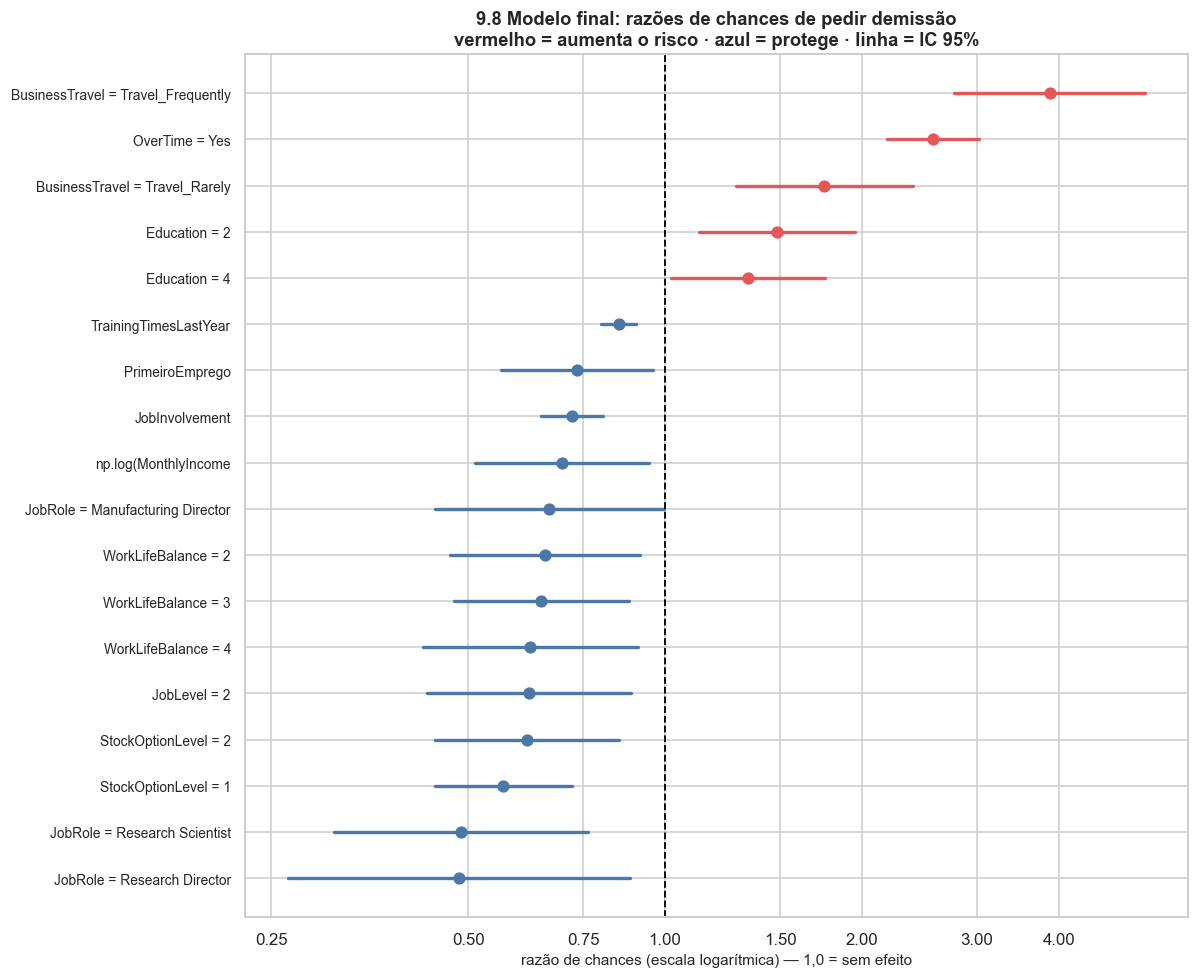

In [60]:
# GRÁFICO DE FLORESTA (forest plot): a forma padrão de apresentar razões de chances.
# A escala do eixo x é LOGARÍTMICA porque RC é uma razão: 0,5 e 2,0 precisam ficar
# à mesma distância de 1,0, e só o log faz isso.
top = (rc_modelo_2.sort_values("forca", ascending=False).head(18)
       .sort_values("razão de chances"))

fig, eixo = plt.subplots(figsize=(11, 9))
for i, (nome, linha) in enumerate(top.iterrows()):
    cor = COR_SAIU if linha["razão de chances"] > 1 else COR_FICOU
    eixo.plot([linha["RC inf 95%"], linha["RC sup 95%"]], [i, i], color=cor, lw=2.2)
    eixo.plot(linha["razão de chances"], i, "o", color=cor, markersize=7)

eixo.axvline(1, color="black", linestyle="--", lw=1.2)
eixo.set_xscale("log")
eixo.set_xticks([0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4])
eixo.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
eixo.set_yticks(range(len(top)),
                [n.replace("C(", "").replace(")", "").replace("[T.", " = ").replace("]", "")
                 for n in top.index], fontsize=9)
eixo.set(xlabel="razão de chances (escala logarítmica) — 1,0 = sem efeito", ylabel="",
         title="9.8 Modelo final: razões de chances de pedir demissão\n"
               "vermelho = aumenta o risco · azul = protege · linha = IC 95%")
plt.tight_layout()
plt.show()

**Como se lê um gráfico de floresta.** Cada linha é uma variável (ou uma categoria). O ponto é a razão
de chances estimada; a linha é o intervalo de confiança de 95%. A linha tracejada vertical em 1,0 é o
"sem efeito". **Se o intervalo cruza o 1,0, não há efeito detectado** — e é por isso que o gráfico só
traz os significativos.

**Os achados do modelo final, e três deles mudam o que a Parte 8 sugeria:**

- **Viajar com frequência é o fator mais forte** (RC ≈ **3,9** contra quem não viaja; viajar
  raramente, ≈ 1,8). **Esse efeito é maior aqui do que na tabela bruta do passo 8.12** — e é a
  demonstração mais clara, em todo o notebook, de por que a análise bivariada não basta. Quem viaja
  muito tende a ter cargo e salário mais altos, que **protegem**; na tabela bruta os dois efeitos se
  cancelavam parcialmente. Mantidos cargo e salário constantes, o efeito da viagem aparece inteiro.
- **Hora extra** vem em segundo (RC ≈ **2,6**) e **também cresceu** em relação à razão de chances
  bruta de 2,24 calculada no passo 8.11. O efeito persiste a salário igual, cargo igual e satisfação
  igual: não é "quem faz hora extra ganha menos e por isso sai".
- **Salário (em log)** tem RC ≈ **0,70**: salário maior **protege**, em termos relativos.
- **Participação acionária** nos níveis 1 e 2 protege (RC ≈ 0,57 e 0,62), confirmando o passo 8.16.
- **Equilíbrio trabalho-vida**: os níveis 2, 3 e 4 têm RC entre **0,62 e 0,66** contra o nível 1, e
  muito próximas entre si. **Isto confirma o degrau que a tabela bruta do passo 8.16 só insinuava**:
  o problema está concentrado em quem avalia o equilíbrio como ruim, e subir de 2 para 4 agrega pouco.
  A decisão de entrar com `C()` em vez de numérica estava certa.
- **Envolvimento, satisfação com o trabalho e com o ambiente** protegem, com gradiente regular (RC
  entre 0,72 e 0,86 por ponto da escala). **Treinamentos** também protegem (RC ≈ 0,85 por treinamento).
- **Idade** protege de forma consistente (RC ≈ 0,95 por ano) e **distância de casa** tem efeito
  pequeno e detectável (RC ≈ 1,02 por milha) — com n grande, efeito pequeno fica significativo, o que
  reforça a advertência do passo 9.3 sobre não confundir significância com relevância.

**O achado que inverte a conclusão da Parte 8: o estado civil desaparece.** Na versão 1, "solteiro"
tinha RC de 2,12. Aqui, com as variáveis de gestão no modelo, o efeito **perde a significância**. A
leitura é substantiva, e fecha o raciocínio aberto no passo 8.4: aquilo que o estado civil *indicava* —
perfil de menor enraizamento — está agora **medido diretamente** por idade, nível, salário, satisfação
e hora extra. **O indicador indireto perde função quando se mede a coisa em si.** E isso reforça, pela
via técnica, a conclusão ética: estado civil nunca deveria orientar decisão sobre pessoas.

**As expectativas que se confirmaram.** `Gender` continua sem efeito (passo 8.9) e
`RelationshipSatisfaction` e `PercentSalaryHike` não aparecem entre os significativos — exatamente
como os passos 8.15 e 8.17 anteciparam. Quando a exploração prevê o resultado do modelo, é sinal de que
a exploração foi bem feita.

**A exceção a registrar.** `Education` mantém dois níveis significativos, sem padrão monotônico. Efeito
sem forma interpretável, em variável com cinco níveis e muitos testes: o tratamento honesto é registrar
como **achado frágil, a confirmar**, e não construir recomendação sobre ele.

## 9.9 De probabilidade a decisão: a matriz de confusão e o ponto de corte

Até aqui o modelo produziu **probabilidades**. Para transformar probabilidade em decisão — "colocar
esta pessoa na lista de conversa?" — é preciso escolher um **ponto de corte** (*threshold*).

**As quatro casas da matriz de confusão, nomeadas em termos de RH:**

|  | Previu "fica" | Previu "sai" |
|---|---|---|
| **Ficou** | Acerto | **Falso alarme** — o RH conversa com quem não ia sair (custo: tempo do gestor) |
| **Saiu** | **Perda silenciosa** — ninguém foi avisado (custo: a pessoa vai embora) | Acerto |

**E aqui está o ponto decisivo: os dois erros não custam o mesmo.** Uma conversa desnecessária custa
uma hora de gestor; perder um analista sênior custa meses de recrutamento e treinamento. Logo, **o
corte ótimo não é 0,5** — é aquele que equilibra os dois custos conforme a realidade da empresa.

O corte 0,5 é o padrão de qualquer software, e com 16% de eventos ele é uma escolha ruim. A célula
abaixo demonstra por quê.

In [61]:
teste_2 = resultado_v6["teste"]
prob_2  = resultado_v6["prob_teste"]
y_real  = teste_2["saiu"].values

def avaliar_corte(y_verdadeiro, probabilidades, corte):
    """Matriz de confusão e métricas para um ponto de corte específico."""
    previsto = (probabilidades >= corte).astype(int)
    # confusion_matrix devolve [[VN, FP], [FN, VP]] na ordem dos rótulos [0, 1]
    vn, fp, fn, vp = confusion_matrix(y_verdadeiro, previsto, labels=[0, 1]).ravel()
    return {
        "corte": corte,
        "previu que sai (n)": vp + fp,
        "acertou quem saiu (VP)": vp,
        "falso alarme (FP)": fp,
        "perda silenciosa (FN)": fn,
        "recall": vp / (vp + fn) if (vp + fn) else 0,     # % de quem saiu que foi detectado
        "precisão": vp / (vp + fp) if (vp + fp) else 0,   # % dos avisos que estavam certos
        "acurácia": (vp + vn) / len(y_verdadeiro),
    }

print("=== O PONTO DE CORTE PADRÃO, 0,50 ===\n")
m = avaliar_corte(y_real, prob_2, 0.50)
matriz = pd.DataFrame(confusion_matrix(y_real, (prob_2 >= 0.50).astype(int), labels=[0, 1]),
                      index=["REAL: ficou", "REAL: saiu"],
                      columns=["PREVISTO: fica", "PREVISTO: sai"])
print(matriz.to_string())
print(f"\nacurácia  {m['acurácia']:.1%}   <- parece ótimo...")
print(f"recall    {m['recall']:.1%}   <- ...mas detectou só esta fração de quem saiu")
print(f"precisão  {m['precisão']:.1%}")
print(f"\nTaxa de saída no teste: {y_real.mean():.1%}. Um modelo que dissesse 'ninguém sai'")
print(f"teria acurácia de {1 - y_real.mean():.1%} - compare com a acurácia acima.")
print("É por isso que acurácia não serve como métrica principal quando as classes")
print("são desbalanceadas (o problema anunciado no passo 7.3).")

print("\n\n=== O QUE ACONTECE AO VARIAR O PONTO DE CORTE ===\n")
varredura = pd.DataFrame([avaliar_corte(y_real, prob_2, c)
                          for c in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]])
print(varredura.round(3).to_string(index=False))
print("\nLeia as colunas 'recall' e 'precisão' em sentidos opostos: baixar o corte")
print("detecta mais gente que ia sair (recall sobe) ao preço de mais falsos alarmes")
print("(precisão cai). NÃO existe corte que melhore os dois: é uma TROCA, e quem a")
print("decide é a gestão, a partir do custo relativo dos dois erros.")

=== O PONTO DE CORTE PADRÃO, 0,50 ===

             PREVISTO: fica  PREVISTO: sai
REAL: ficou            2011             39
REAL: saiu              334             59

acurácia  84.7%   <- parece ótimo...
recall    15.0%   <- ...mas detectou só esta fração de quem saiu
precisão  60.2%

Taxa de saída no teste: 16.1%. Um modelo que dissesse 'ninguém sai'
teria acurácia de 83.9% - compare com a acurácia acima.
É por isso que acurácia não serve como métrica principal quando as classes
são desbalanceadas (o problema anunciado no passo 7.3).


=== O QUE ACONTECE AO VARIAR O PONTO DE CORTE ===

 corte  previu que sai (n)  acertou quem saiu (VP)  falso alarme (FP)  perda silenciosa (FN)  recall  precisão  acurácia
 0.100                1364                     318               1046                     75   0.809     0.233     0.541
 0.150                 966                     278                688                    115   0.707     0.288     0.671
 0.200                 701               

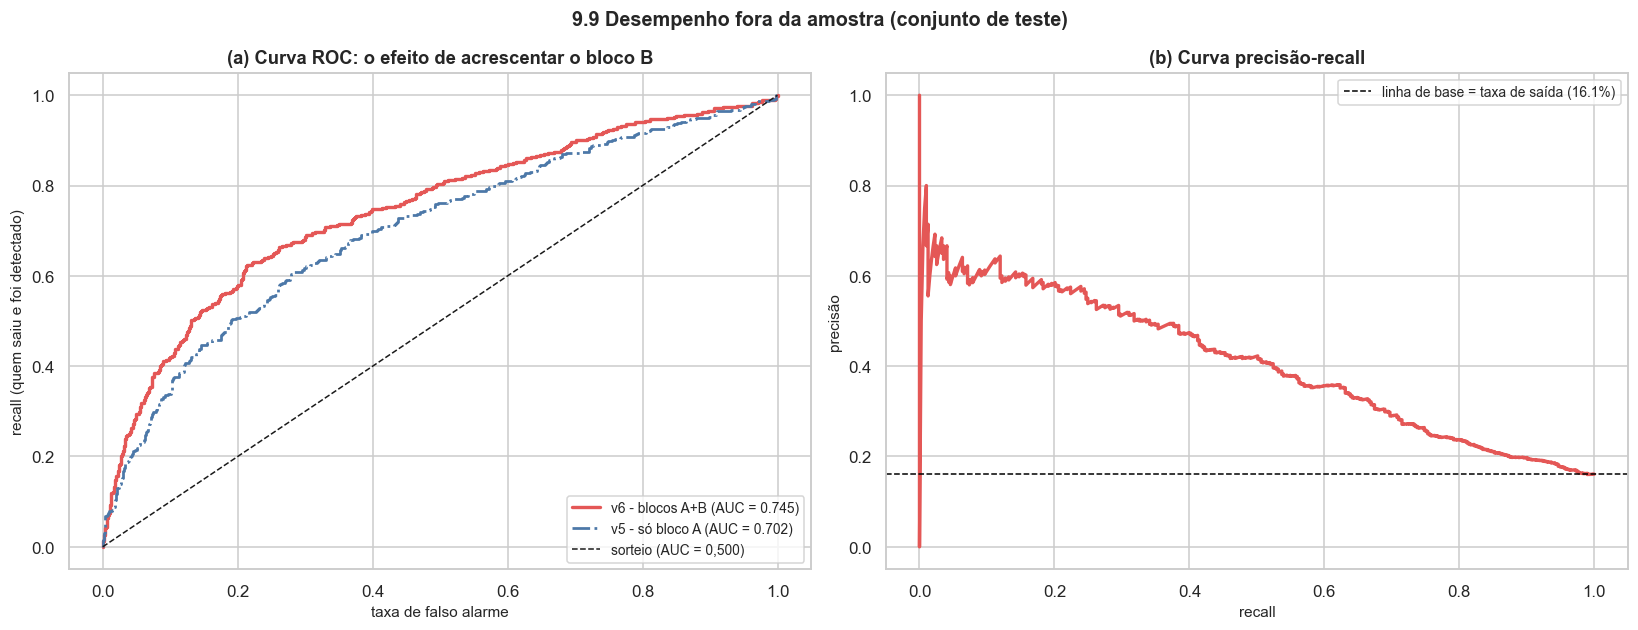

In [62]:
# As duas curvas de diagnóstico, lado a lado.
fig, eixos = plt.subplots(1, 2, figsize=(15, 5.8))

# --- (a) Curva ROC -------------------------------------------------------
# roc_curve devolve, para TODOS os cortes possíveis:
#   fpr = taxa de falso positivo (falsos alarmes sobre quem ficou)
#   tpr = taxa de verdadeiro positivo (= recall)
fpr, tpr, _ = roc_curve(y_real, prob_2)
eixos[0].plot(fpr, tpr, color=COR_SAIU, lw=2.2,
              label=f"v6 - blocos A+B (AUC = {resultado_v6['auc_teste']:.3f})")

fpr5, tpr5, _ = roc_curve(resultado_v5["teste"]["saiu"], resultado_v5["prob_teste"])
eixos[0].plot(fpr5, tpr5, color=COR_FICOU, lw=1.8, linestyle="-.",
              label=f"v5 - só bloco A (AUC = {resultado_v5['auc_teste']:.3f})")

eixos[0].plot([0, 1], [0, 1], "k--", lw=1, label="sorteio (AUC = 0,500)")
eixos[0].set(xlabel="taxa de falso alarme", ylabel="recall (quem saiu e foi detectado)",
             title="(a) Curva ROC: o efeito de acrescentar o bloco B")
eixos[0].legend(loc="lower right", fontsize=9)

# --- (b) Curva precisão-recall ------------------------------------------
# Para classe desbalanceada esta curva é mais informativa que a ROC: ela ignora
# os verdadeiros negativos, que aqui são a maioria esmagadora.
precisao, recall, _ = precision_recall_curve(y_real, prob_2)
eixos[1].plot(recall, precisao, color=COR_SAIU, lw=2.2)
eixos[1].axhline(y_real.mean(), color="black", linestyle="--", lw=1,
                 label=f"linha de base = taxa de saída ({y_real.mean():.1%})")
eixos[1].set(xlabel="recall", ylabel="precisão", title="(b) Curva precisão-recall")
eixos[1].legend(fontsize=9)

fig.suptitle("9.9 Desempenho fora da amostra (conjunto de teste)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**A leitura de (a).** Quanto mais a curva se afasta da diagonal em direção ao canto superior esquerdo,
melhor. A distância entre as duas curvas é, visualmente, **o que as variáveis do bloco B
acrescentam** — e é substancial. Dito de outro modo: saber como a pessoa **está sendo gerida** prevê
melhor que saber **quem ela era** quando foi contratada.

**A leitura de (b), que é a curva mais útil para o uso prático.** A linha horizontal tracejada é a
precisão que se obteria **sorteando** pessoas para conversar: igual à taxa de saída. Qualquer ponto da
curva acima dessa linha significa que o modelo é melhor que o sorteio. Leia-a assim: *"se eu quiser
alcançar 40% de quem vai sair (recall = 0,4), que fração das minhas conversas será com gente que
realmente ia sair?"* — a resposta é a precisão naquele ponto.

**Insight sobre o corte 0,5.** Com ele, o modelo detecta apenas cerca de **15%** de quem saiu, porque
pouquíssimas pessoas alcançam probabilidade acima de 0,5 numa base em que o evento é raro. A acurácia
fica em 85% e **parece excelente** — mas é pior que o modelo trivial que diz "ninguém sai". Esse é o
erro de avaliação mais comum em projetos de People Analytics, e ele vem de usar o padrão do software
sem perguntar se ele faz sentido para o problema.

## 9.10 O uso que de fato cabe numa rotina de RH: a lista de prioridade

Classificar "sai / não sai" é a forma **menos** útil de usar o modelo. O que se usa na prática é o
**ordenamento**: ranquear o quadro pela probabilidade estimada e levar ao gestor **os N primeiros**,
onde N é o número de conversas que a equipe de RH consegue fazer no mês.

**O elemento.** O **decil de risco** e o **lift**. Lift é quantas vezes mais saídas há no grupo de
maior risco, em comparação com um grupo do mesmo tamanho sorteado ao acaso. É a medida que traduz
AUC em utilidade operacional — e é a única métrica desta parte que um gestor entende sem explicação.

In [63]:
# Ordena o conjunto de teste pela probabilidade prevista e divide em 10 décimos.
avaliacao = pd.DataFrame({"prob": prob_2, "saiu": y_real})

# qcut com 10 faixas = decis. labels=False devolve 0..9; invertemos para que o
# decil 1 seja o de MAIOR risco - é assim que se lê uma lista de prioridade.
avaliacao["decil"] = 10 - pd.qcut(avaliacao["prob"], 10, labels=False, duplicates="drop")

tabela_decis = (avaliacao.groupby("decil")
                .agg(**{"n": ("saiu", "size"),
                        "saídas observadas": ("saiu", "sum"),
                        "taxa de saída": ("saiu", "mean"),
                        "prob. média prevista": ("prob", "mean")})
                .sort_index())

taxa_media = avaliacao["saiu"].mean()
tabela_decis["lift"] = tabela_decis["taxa de saída"] / taxa_media
tabela_decis["% das saídas (acum.)"] = (tabela_decis["saídas observadas"].cumsum()
                                        / tabela_decis["saídas observadas"].sum() * 100)

print("LISTA DE PRIORIDADE: conjunto de teste ordenado pelo risco previsto")
print(f"(decil 1 = 10% de maior risco · taxa média de saída = {taxa_media:.1%})\n")
print(tabela_decis.round({"taxa de saída": 3, "prob. média prevista": 3,
                          "lift": 2, "% das saídas (acum.)": 1}).to_string())

decil_1 = tabela_decis.loc[1]
print(f"\nLEITURA GERENCIAL")
print(f"  Conversando com os 10% de maior risco ({int(decil_1['n'])} pessoas),")
print(f"  o RH alcança {decil_1['% das saídas (acum.)']:.0f}% de todas as saídas do período.")
print(f"  A taxa de saída nesse grupo é {decil_1['taxa de saída']:.1%}, contra "
      f"{taxa_media:.1%} na média: lift de {decil_1['lift']:.2f}x.")
print(f"  Com 20% do quadro: {tabela_decis.loc[2, '% das saídas (acum.)']:.0f}% das saídas.")

# Calibração: a probabilidade prevista corresponde à taxa observada?
print("\n\nCALIBRAÇÃO - a verificação que quase ninguém faz\n")
print("Compare, decil por decil, a coluna 'prob. média prevista' com 'taxa de saída'.")
print("Se os dois números são próximos, o modelo não está apenas ORDENANDO bem:")
print("as probabilidades que ele produz têm significado literal, e podem ser usadas")
print("como estimativa de risco individual, não só como posição na fila.")
erro_calibracao = (tabela_decis["prob. média prevista"] - tabela_decis["taxa de saída"]).abs().mean()
print(f"\nErro médio absoluto de calibração: {erro_calibracao:.3f}")

LISTA DE PRIORIDADE: conjunto de teste ordenado pelo risco previsto
(decil 1 = 10% de maior risco · taxa média de saída = 16.1%)

         n  saídas observadas  taxa de saída  prob. média prevista  lift  % das saídas (acum.)
decil                                                                                         
1      245                125          0.510                 0.512 3.170                31.800
2      244                 75          0.307                 0.304 1.910                50.900
3      244                 50          0.205                 0.224 1.270                63.600
4      244                 29          0.119                 0.171 0.740                71.000
5      244                 21          0.086                 0.134 0.540                76.300
6      245                 25          0.102                 0.103 0.630                82.700
7      243                 18          0.074                 0.077 0.460                87.300
8      245     

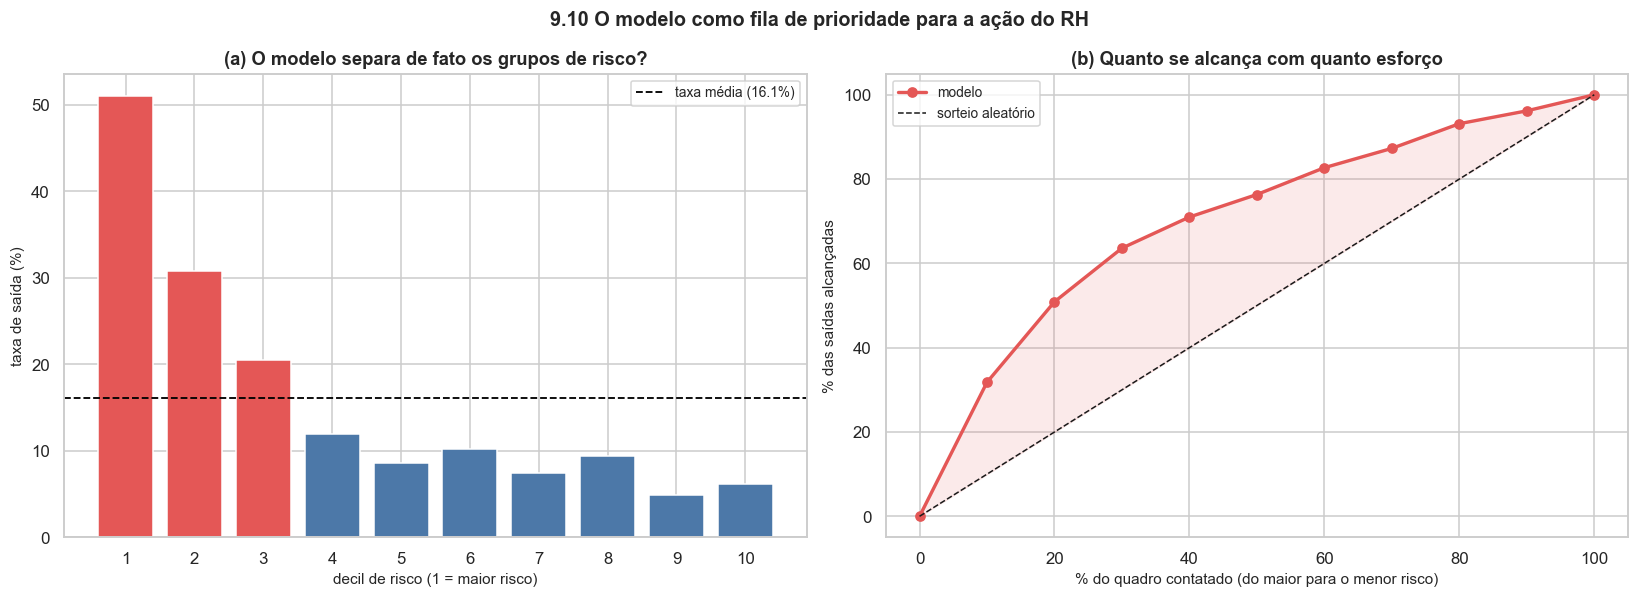

In [64]:
# As duas leituras gráficas que o RH precisa ver.
fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))

# --- (a) Taxa de saída por decil de risco -------------------------------
cores = [COR_SAIU if d <= 3 else COR_FICOU for d in tabela_decis.index]
eixos[0].bar(tabela_decis.index, tabela_decis["taxa de saída"] * 100, color=cores)
eixos[0].axhline(taxa_media * 100, color="black", linestyle="--", lw=1.2,
                 label=f"taxa média ({taxa_media:.1%})")
eixos[0].set(xlabel="decil de risco (1 = maior risco)", ylabel="taxa de saída (%)",
             title="(a) O modelo separa de fato os grupos de risco?",
             xticks=tabela_decis.index)
eixos[0].legend(fontsize=9)

# --- (b) Curva de captura acumulada -------------------------------------
eixo_x = [0] + [d * 10 for d in tabela_decis.index]
eixo_y = [0] + list(tabela_decis["% das saídas (acum.)"])
eixos[1].plot(eixo_x, eixo_y, "o-", color=COR_SAIU, lw=2.2, label="modelo")
eixos[1].plot([0, 100], [0, 100], "k--", lw=1, label="sorteio aleatório")
eixos[1].fill_between(eixo_x, eixo_y, eixo_x, alpha=0.12, color=COR_SAIU)
eixos[1].set(xlabel="% do quadro contatado (do maior para o menor risco)",
             ylabel="% das saídas alcançadas",
             title="(b) Quanto se alcança com quanto esforço")
eixos[1].legend(fontsize=9)

fig.suptitle("9.10 O modelo como fila de prioridade para a ação do RH",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**A leitura de (a).** As barras caem de forma ordenada, do decil 1 ao 10. **O modelo separa os grupos
de risco**, e o decil de maior risco tem taxa de saída várias vezes acima da média da empresa.

**A leitura de (b).** A curva do modelo fica bem acima da diagonal do sorteio. A área entre as duas é
o ganho operacional: **quanto se alcança de saídas com quanto esforço de conversa.**

**Insight — e é o fecho da Parte 9.** Com uma AUC de teste em torno de 0,74, que a tabela do passo 9.6
qualificaria como apenas "razoável", o modelo entrega algo muito concreto: **contatando 10% do quadro,
o RH alcança cerca de um terço de todas as saídas do período.** Isso é um *lift* de mais de 3 vezes
sobre o sorteio. A moral é importante: **não é preciso AUC alta para um modelo ser útil** — é preciso
que ele ordene melhor que o acaso, e que a organização tenha um processo para agir sobre a ordenação.

**Sobre a calibração.** O quadro impresso compara, decil por decil, a probabilidade **prevista** com a
taxa **observada**. Quando os dois números ficam próximos, o modelo não está apenas ordenando bem: as
probabilidades têm significado literal. Isso importa para a Parte 11, porque a conta de custo-benefício
usa a probabilidade como estimativa de risco — e, se o modelo estivesse mal calibrado, a conta estaria
errada mesmo com a ordenação correta. É uma verificação que quase nunca se faz, e que custa uma célula.

**O que isso não diz, e vale repetir aqui.** A lista de prioridade é **uma fila de conversas**, não um
veredito individual. A pessoa no topo da lista não "vai sair": ela está num grupo em que a saída é
mais frequente. Usar essa probabilidade para decidir promoção, alocação ou desligamento é uso indevido
— e a Parte 11.3 trata disso, junto com o efeito perverso que surge quando os gestores conhecem a nota
de risco de cada pessoa.

---

# Parte 10. Árvore de decisão

## 10.1 Por que uma segunda técnica, se a logística já funciona

A árvore de decisão não está aqui por redundância. Ela entrega algo que a logística não entrega, e
a comparação entre as duas é parte do método:

| | Regressão logística | Árvore de decisão |
|---|---|---|
| **Entrega** | Um coeficiente por variável | Um conjunto de regras do tipo "se… então…" |
| **Forma do efeito** | Supõe efeito linear no logito | Captura **patamares** e **interações** sem precisar declará-las |
| **Leitura** | Exige entender razão de chances | Um gestor lê o fluxograma sem treinamento |
| **Inferência** | Dá valor-p e intervalo de confiança | Não dá |
| **Estabilidade** | Estável | Instável: muda bastante com pequenas mudanças nos dados |

A árvore serve para **comunicar** e para **descobrir interação**. A logística serve para **estimar
e testar**. Usar as duas e comparar é melhor prática do que escolher uma: quando as duas apontam
o mesmo fator como o mais importante, a conclusão fica mais segura, porque os pressupostos de cada
uma são diferentes.

**Uma exigência técnica desta etapa.** A árvore do `scikit-learn` **só aceita números**: as
variáveis categóricas precisam ser convertidas em indicadoras 0/1 (*one-hot*) antes de entrar. É
o mesmo que a fórmula da regressão fazia automaticamente com `C()`, agora feito de forma
explícita, com `pd.get_dummies()` — e vale ver acontecendo, porque é o que estava por trás do
`C()` na Parte 9.

In [65]:
# ---------------------------------------------------------------------------
# 1) Seleção de variáveis. Usamos o mesmo conteúdo do Modelo 2, porque o
#    objetivo é COMPARAR as duas técnicas - e comparar modelos com conjuntos
#    de variáveis diferentes não diria nada sobre as técnicas.
# ---------------------------------------------------------------------------
variaveis_numericas = ["Age", "DistanceFromHome", "MonthlyIncome", "PriorYearsOfExperience",
                       "AverageTenure", "PrimeiroEmprego", "YearsAtCompany",
                       "YearsSinceLastPromotion", "YearsWithCurrManager",
                       "TrainingTimesLastYear", "PercentSalaryHike",
                       "JobSatisfaction", "EnvironmentSatisfaction",
                       "RelationshipSatisfaction", "JobInvolvement",
                       "WorkLifeBalance", "JobLevel", "StockOptionLevel", "Education"]

variaveis_categoricas = ["Department", "EmployeeSource", "JobRole", "MaritalStatus",
                         "Gender", "EducationField", "OverTime", "BusinessTravel"]

# ---------------------------------------------------------------------------
# 2) Codificação one-hot: cada categoria vira uma coluna 0/1.
#    drop_first=True descarta a primeira categoria de cada variável, como a
#    regressão faz - evita colunas redundantes. Para árvore isso é opcional,
#    mas mantém a comparação com a logística mais justa.
# ---------------------------------------------------------------------------
X = pd.get_dummies(
    base_unica[variaveis_numericas + variaveis_categoricas],
    columns=variaveis_categoricas,
    drop_first=True,
).astype(float)

y = base_unica["saiu"]

print(f"Matriz de atributos: {X.shape[0]:,} linhas x {X.shape[1]} colunas".replace(",", "."))
print(f"  {len(variaveis_numericas)} variáveis numéricas")
print(f"  {len(variaveis_categoricas)} categóricas -> "
      f"{X.shape[1] - len(variaveis_numericas)} colunas indicadoras")

# ---------------------------------------------------------------------------
# 3) A MESMA divisão treino/teste da Parte 9 (mesma semente, mesma
#    estratificação), para que a comparação de AUC seja legítima.
# ---------------------------------------------------------------------------
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, random_state=SEMENTE, stratify=y)

print(f"\ntreino: {len(X_treino):,} | teste: {len(X_teste):,}".replace(",", "."))

Matriz de atributos: 8.142 linhas x 48 colunas
  19 variáveis numéricas
  8 categóricas -> 29 colunas indicadoras

treino: 5.699 | teste: 2.443


## 10.2 Os hiperparâmetros, e o que cada um controla

A árvore cresce dividindo os dados em dois a cada nó, escolhendo sempre a pergunta que melhor
separa quem sai de quem fica. Sem limite, ela cresce até isolar cada caso — e aí **memoriza** o
treino em vez de aprender o padrão (*overfitting*). Os limites são:

| Parâmetro | O que faz | Consequência de afrouxá-lo |
|---|---|---|
| `min_samples_split` | Mínimo de casos num nó para que valha dividi-lo | Regras baseadas em pouquíssimos casos |
| `min_samples_leaf` | Mínimo de casos numa folha | Folhas com duas ou três pessoas, que não generalizam |
| `max_depth` | Profundidade máxima | Árvore ilegível para um gestor |
| `ccp_alpha` | Penalidade por complexidade: poda a árvore | Sem poda, a árvore cresce até isolar casos individuais |
| `class_weight` | Peso das classes; `"balanced"` compensa o desbalanceamento | Sem isso, a árvore tende a ignorar quem sai |

Uma configuração frequente é exigir 500 casos para dividir um nó e **não** aplicar poda. A
primeira exigência é sensata nesta base; a segunda é arriscada, porque deixa a árvore crescer sem
penalidade. Serão ajustadas **três** árvores, para que a diferença fique visível:

- **Árvore A, rasa** (`max_depth=4`): feita para ser *lida* por um gestor;
- **Árvore B, profunda** (500 casos para dividir, sem poda): feita para mostrar o custo da falta
  de poda;
- **Árvore C, sem limite nenhum**: feita para mostrar o que acontece quando nada é imposto.

In [66]:
def ajustar_arvore(rotulo, **parametros):
    """Ajusta uma árvore, avalia nos dois conjuntos e devolve as métricas."""
    arvore = DecisionTreeClassifier(random_state=SEMENTE, **parametros)
    arvore.fit(X_treino, y_treino)

    # predict_proba devolve DUAS colunas: [prob de 0, prob de 1].
    # Queremos a probabilidade da classe 1 (saiu), logo a coluna de índice 1.
    prob_treino = arvore.predict_proba(X_treino)[:, 1]
    prob_teste  = arvore.predict_proba(X_teste)[:, 1]

    metricas = {
        "modelo": rotulo,
        "folhas": arvore.get_n_leaves(),
        "profundidade": arvore.get_depth(),
        "AUC treino": roc_auc_score(y_treino, prob_treino),
        "AUC teste": roc_auc_score(y_teste, prob_teste),
    }
    metricas["otimismo"] = metricas["AUC treino"] - metricas["AUC teste"]
    return arvore, prob_teste, metricas


# Árvore A: rasa, para leitura humana. class_weight='balanced' faz a árvore
# dar mais peso à classe minoritária - sem isso ela tende a ignorar quem sai.
arvore_a, prob_arvore_a, metricas_a = ajustar_arvore(
    "Árvore A (rasa, para leitura)",
    max_depth=4, min_samples_leaf=200, class_weight="balanced")

# Árvore B: exige 500 casos para dividir um nó e NÃO aplica poda
arvore_b, prob_arvore_b, metricas_b = ajustar_arvore(
    "Árvore B (500 casos para dividir, sem poda)",
    min_samples_split=500, ccp_alpha=0.0)

# Árvore C: sem nenhum limite, para ver o overfitting em estado puro
arvore_c, prob_arvore_c, metricas_c = ajustar_arvore(
    "Árvore C (sem limite nenhum - demonstração de overfitting)")

print(pd.DataFrame([metricas_a, metricas_b, metricas_c])
      .set_index("modelo").round(4).to_string())

print("\nLEITURA: a coluna 'otimismo' é a diferença entre treino e teste.")
print("A Árvore C tem AUC de treino = 1,000: ela acerta TODOS os casos de treino,")
print("o que é a definição de memorização. Mas repare na AUC de TESTE dela, que")
print("ficou acima de todos os outros modelos - inclusive da logística.")
print("\nIsso não deveria acontecer. Uma árvore que memoriza o treino deveria ir MAL")
print("no teste. O fato de ir bem é um sinal de alarme, não de sucesso - e a célula")
print("seguinte investiga a causa.")

                                                            folhas  profundidade  AUC treino  AUC teste  otimismo
modelo                                                                                                           
Árvore A (rasa, para leitura)                                   13             4       0.728      0.718     0.010
Árvore B (500 casos para dividir, sem poda)                     26            12       0.765      0.744     0.020
Árvore C (sem limite nenhum - demonstração de overfitting)     492            19       1.000      0.895     0.105

LEITURA: a coluna 'otimismo' é a diferença entre treino e teste.
A Árvore C tem AUC de treino = 1,000: ela acerta TODOS os casos de treino,
o que é a definição de memorização. Mas repare na AUC de TESTE dela, que
ficou acima de todos os outros modelos - inclusive da logística.

Isso não deveria acontecer. Uma árvore que memoriza o treino deveria ir MAL
no teste. O fato de ir bem é um sinal de alarme, não de sucesso - e a célu

## 10.3 O alarme: por que a árvore sem poda "venceu"

A Árvore C tem AUC de treino **1,000** (acerto perfeito, isto é, memorização completa) e AUC de
teste em torno de **0,895** — acima da logística (0,745) e das duas árvores podadas. Em modelagem
de atrito, **AUC acima de 0,85 é motivo de desconfiança, não de comemoração**: comportamento humano
não é tão previsível. Quando um modelo supera esse patamar, a primeira hipótese a testar é
vazamento.

A hipótese concreta: a Parte 4.4 removeu linhas duplicadas considerando **todas as 30 colunas**.
Mas a matriz de atributos usada aqui tem um **subconjunto** dessas colunas (`TotalWorkingYears`,
`NumCompaniesWorked`, `AgeStartedWorking`, `YearsInCurrentRole` e `PerformanceRating` ficaram fora).
Duas linhas que diferiam apenas nessas colunas excluídas são, **no espaço de atributos do modelo**,
idênticas. Se uma cai no treino e a outra no teste, a árvore que memorizou a primeira "prevê" a
segunda com certeza — sem ter aprendido nada.

A célula abaixo mede isso diretamente.

In [67]:
# Quantas linhas de TESTE têm um vetor de atributos IDÊNTICO a alguma linha de TREINO?
# Transformamos cada linha numa tupla (que é "hasheável") e usamos um conjunto,
# que faz a busca em tempo constante - comparar linha a linha seria lento.
vetores_treino = set(map(tuple, X_treino.values))
tem_gemeo = np.array([tuple(linha) in vetores_treino for linha in X_teste.values])

print("DUPLICATAS NO ESPAÇO DE ATRIBUTOS DO MODELO\n")
print(f"linhas repetidas dentro de X (todas as {X.shape[1]} colunas do modelo): "
      f"{X.duplicated().sum():,}".replace(",", "."))
print(f"linhas de TESTE com vetor idêntico no TREINO ..... {tem_gemeo.sum():,} "
      f"de {len(X_teste):,}  ({tem_gemeo.mean():.1%})".replace(",", "."))

# O teste decisivo: a árvore sem poda vai bem nas linhas COM gêmeo no treino,
# e mal nas linhas SEM gêmeo? Se sim, o desempenho era vazamento.
print("\nAUC da Árvore C, separando os dois grupos do conjunto de teste:\n")
for rotulo, mascara in [("linhas COM gêmeo idêntico no treino", tem_gemeo),
                        ("linhas SEM gêmeo (previsão genuína)", ~tem_gemeo)]:
    y_grupo    = y_teste.values[mascara]
    prob_grupo = prob_arvore_c[mascara]
    if len(np.unique(y_grupo)) > 1:          # AUC exige as duas classes presentes
        auc_grupo = roc_auc_score(y_grupo, prob_grupo)
        print(f"  {rotulo:<40} n = {len(y_grupo):>5}   AUC = {auc_grupo:.4f}")

print(f"\nPara comparação, a Logística 2 no conjunto de teste inteiro: "
      f"AUC = {resultado_2['auc_teste']:.4f}")

DUPLICATAS NO ESPAÇO DE ATRIBUTOS DO MODELO



linhas repetidas dentro de X (todas as 48 colunas do modelo): 1.480
linhas de TESTE com vetor idêntico no TREINO ..... 657 de 2.443  (26.9%)

AUC da Árvore C, separando os dois grupos do conjunto de teste:

  linhas COM gêmeo idêntico no treino      n =   657   AUC = 1.0000
  linhas SEM gêmeo (previsão genuína)      n =  1786   AUC = 0.8614

Para comparação, a Logística 2 no conjunto de teste inteiro: AUC = 0.7451


**O que a medição mostrou — e por que ela não fecha a questão.**

Nas 657 linhas de teste com gêmeo idêntico no treino, a AUC da Árvore C é **1,0000**: acerto
perfeito. Isso é memorização pura, e confirma o vazamento. Mas nas 1.786 linhas **sem** gêmeo a AUC
ainda fica em torno de **0,861** — bem acima da logística. Ou seja: as duplicatas exatas explicam
**parte** da vantagem, não toda.

A hipótese seguinte é que sobraram *quase*-gêmeos: linhas que diferem em uma ou duas variáveis, mas
que descrevem o mesmo perfil e têm o mesmo desfecho. O teste direto é remover as duplicatas **no
espaço de atributos** (incluindo o desfecho) e reajustar tudo.

In [68]:
# Deduplicação no espaço de atributos DO MODELO, desfecho incluído, e reajuste das três árvores.
XY = X.copy()
XY["_desfecho"] = y.values
XY_unico = XY.drop_duplicates()

X_dedup = XY_unico.drop(columns="_desfecho")
y_dedup = XY_unico["_desfecho"]

print(f"X original ............... {len(X):,} linhas".replace(",", "."))
print(f"X sem duplicata de perfil  {len(X_dedup):,} linhas".replace(",", "."))

configuracoes = [
    ("Árvore A (rasa)",      dict(max_depth=4, min_samples_leaf=200, class_weight="balanced")),
    ("Árvore B (minsplit=500)", dict(min_samples_split=500)),
    ("Árvore C (sem poda)",  dict()),
]

linhas = []
for rotulo, parametros in configuracoes:
    for nome_base, (Xa, ya) in [("com duplicatas", (X, y)), ("sem duplicatas", (X_dedup, y_dedup))]:
        Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(
            Xa, ya, test_size=0.3, random_state=SEMENTE, stratify=ya)
        arvore = DecisionTreeClassifier(random_state=SEMENTE, **parametros).fit(Xa_tr, ya_tr)
        linhas.append({
            "árvore": rotulo,
            "base": nome_base,
            "folhas": arvore.get_n_leaves(),
            "AUC treino": roc_auc_score(ya_tr, arvore.predict_proba(Xa_tr)[:, 1]),
            "AUC teste":  roc_auc_score(ya_te, arvore.predict_proba(Xa_te)[:, 1]),
        })

tabela_dedup = pd.DataFrame(linhas).set_index(["árvore", "base"])
print("\nEFEITO DA DEDUPLICAÇÃO NO ESPAÇO DE ATRIBUTOS\n")
print(tabela_dedup.round(3).to_string())
print(f"\nLogística 2, para referência: AUC teste = {resultado_2['auc_teste']:.3f}")

X original ............... 8.142 linhas
X sem duplicata de perfil  6.662 linhas



EFEITO DA DEDUPLICAÇÃO NO ESPAÇO DE ATRIBUTOS

                                        folhas  AUC treino  AUC teste
árvore                  base                                         
Árvore A (rasa)         com duplicatas      13       0.728      0.718
                        sem duplicatas      12       0.724      0.692
Árvore B (minsplit=500) com duplicatas      26       0.765      0.744
                        sem duplicatas      19       0.744      0.723
Árvore C (sem poda)     com duplicatas     492       1.000      0.895
                        sem duplicatas     445       1.000      0.836

Logística 2, para referência: AUC teste = 0.745


**O veredito, com o que ficou provado e o que ficou em aberto.**

Removendo as duplicatas de perfil, a AUC de teste da Árvore C cai de ≈ 0,895 para ≈ 0,836 — e as
árvores podadas também perdem (a B vai de ≈ 0,744 para ≈ 0,723; a A, de ≈ 0,718 para ≈ 0,692). Três
conclusões, em ordem de solidez:

1. **Parte da vantagem era vazamento, e isso está demonstrado.** A AUC de 1,0000 nas linhas com
   gêmeo exato não admite outra leitura, e todas as árvores perdem desempenho quando as duplicatas
   de perfil saem.
2. **A vantagem não é só vazamento.** Mesmo na base deduplicada, a árvore sem poda fica bem acima da
   logística. Isso é compatível com duas explicações que esta base **não** permite separar: (i) há
   interações e patamares reais que a logística, do jeito como foi especificada, não captura; (ii)
   sobrou estrutura artificial da replicação sintética — perfis quase idênticos, com o mesmo
   desfecho, espalhados entre treino e teste. Como a base não traz identificador de funcionário,
   não há como dividir treino e teste *por pessoa*, que é o único corte que eliminaria a segunda
   explicação.
3. **Por isso o número da Árvore C não entra em nenhuma decisão.** O princípio é geral e vale para
   qualquer projeto: **quando um modelo salta de desempenho sem que se saiba dizer por qual
   mecanismo, o ônus é do analista** — ou se explica o salto, ou não se usa o número. Nesta base,
   com a replicação sintética documentada na Parte 4.4, o salto não tem explicação limpa.

O que se leva adiante são os modelos cujo desempenho é explicável: a Logística 2 (0,745) e a
Árvore B (0,744), praticamente empatadas — o que também é informativo. Duas técnicas muito
diferentes chegando ao mesmo patamar sugere que esse patamar é, aproximadamente, o quanto esta
base permite prever.

## 10.4 A árvore que o RH pode ler

Descartada a Árvore C, volta-se à **Árvore A** — rasa de propósito, para que o resultado caiba numa
reunião. Profundidade 4 e no mínimo 200 casos por folha garantem que cada regra se sustente em um
grupo grande o bastante para não ser ruído.

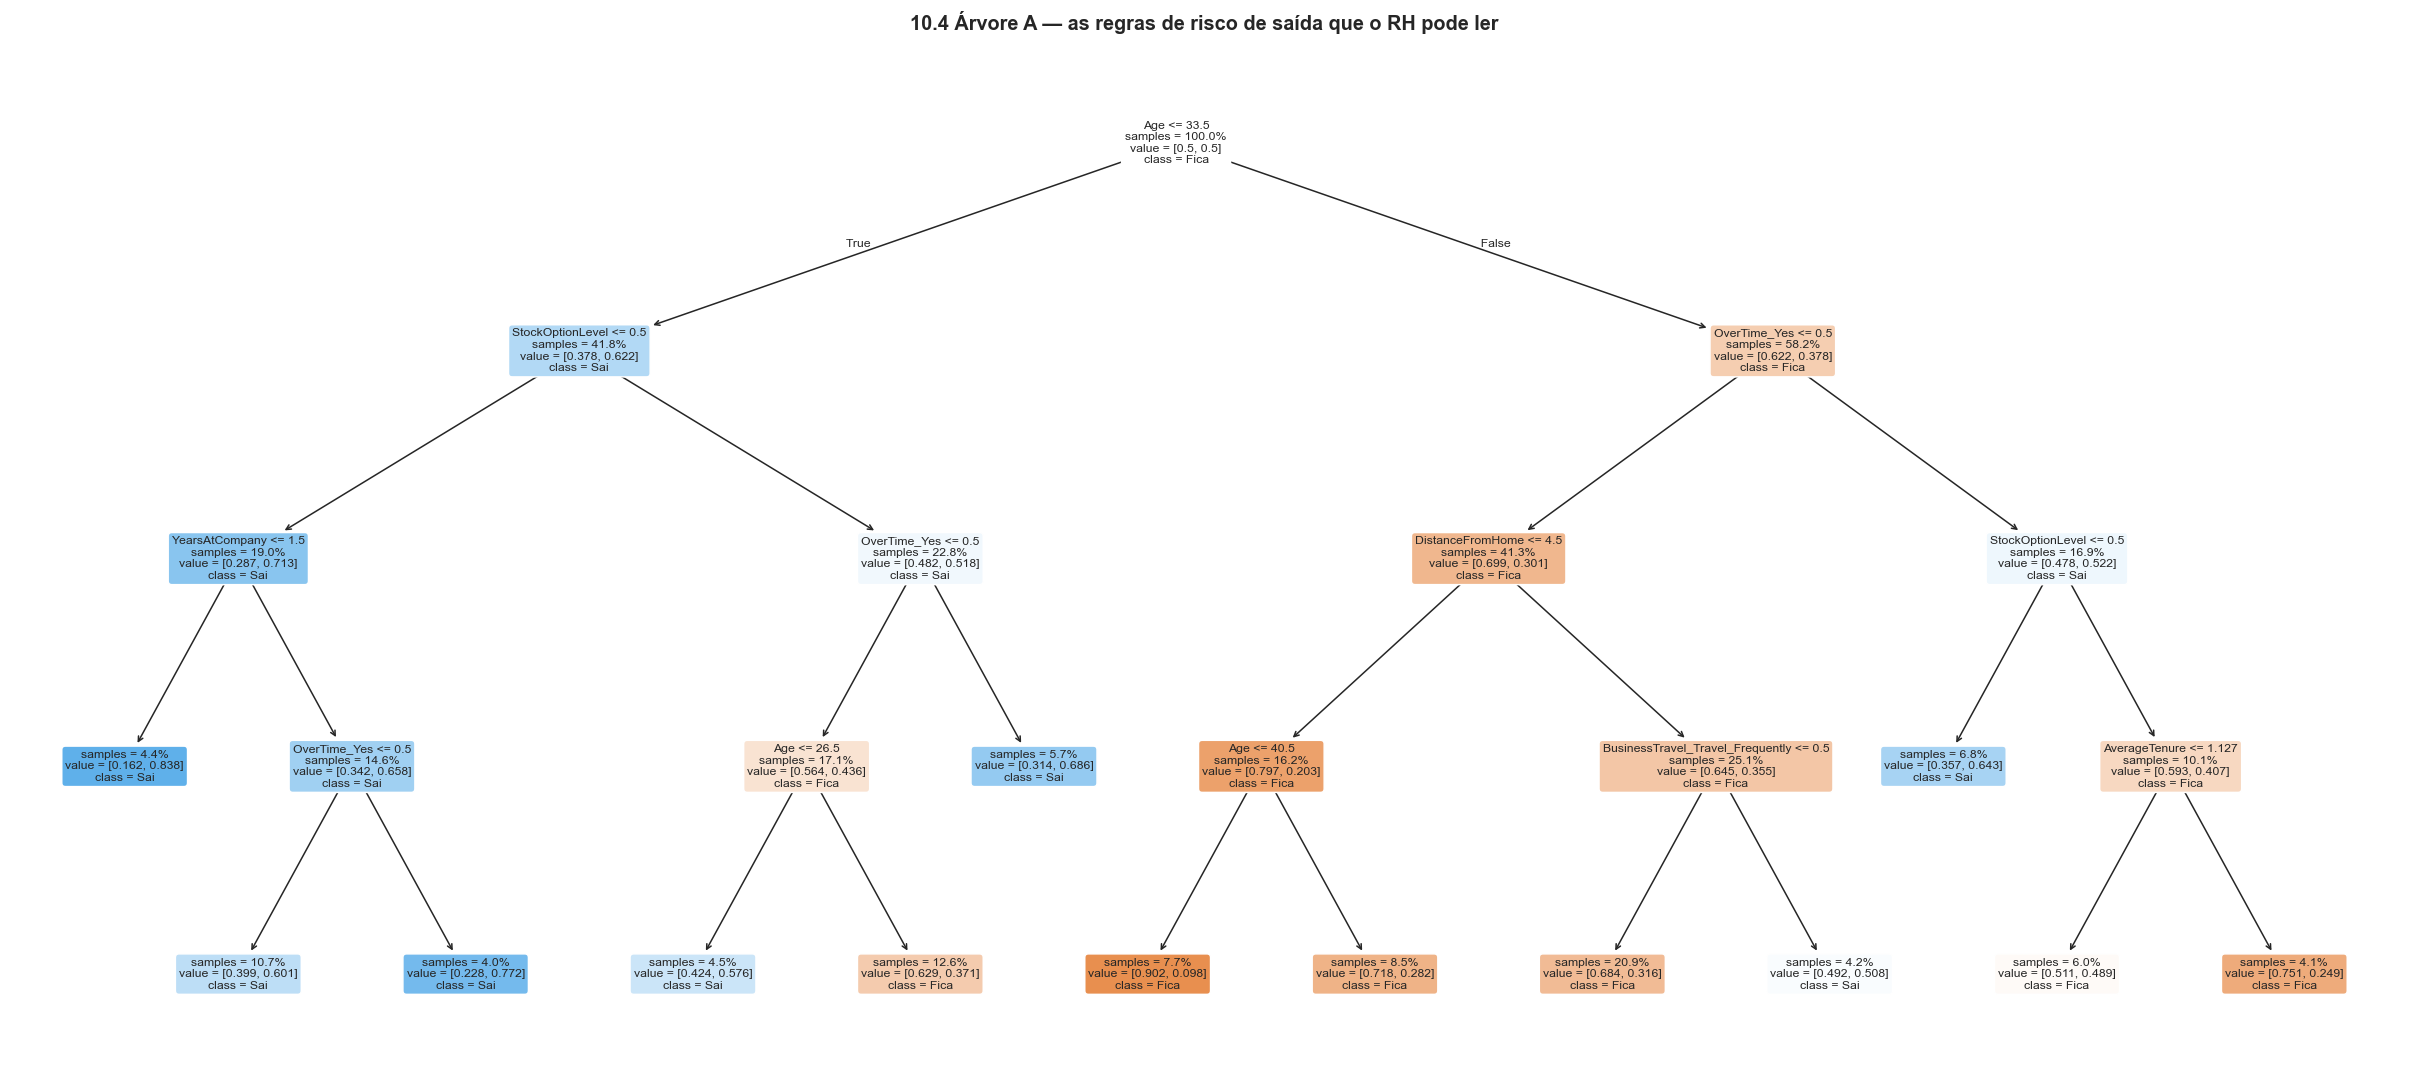

In [69]:
# Visualização da Árvore A. plot_tree desenha a árvore ajustada.
fig, eixo = plt.subplots(figsize=(22, 10))

plot_tree(
    arvore_a,
    feature_names=X.columns,          # nomes das variáveis nos nós
    class_names=["Fica", "Sai"],      # rótulos das classes
    filled=True,                      # cor proporcional à classe dominante
    rounded=True,
    proportion=True,                  # mostra proporções, não contagens brutas
    fontsize=8,
    impurity=False,                   # esconde o Gini: polui a leitura didática
    ax=eixo,
)
eixo.set_title("10.4 Árvore A — as regras de risco de saída que o RH pode ler",
               fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Como ler a árvore.** Cada caixa é um nó e traz:

- a **pergunta** que divide os dados (ex.: `OverTime_Yes <= 0.5`, isto é, "não faz hora extra?");
- `samples`: a proporção do conjunto de treino que chegou àquele nó;
- `value`: a composição entre as duas classes naquele nó (com `class_weight="balanced"`, esses
  valores estão ponderados);
- `class`: a classe majoritária naquele nó.

**Percorra do topo para baixo e leia o caminho como uma frase.** Cada caminho da raiz até uma folha
é uma regra de negócio. A primeira divisão é a variável mais informativa de todas — e ela deve ser
coerente com o que a Parte 8 e o passo 9.8 mostraram. Quando a árvore e a logística apontam a mesma
variável no topo, isso é evidência convergente: duas técnicas com pressupostos diferentes
chegaram ao mesmo lugar.

In [70]:
# As regras em texto. Para muitos gestores, este formato é mais útil que o desenho:
# dá para colar no slide, no e-mail, no procedimento.
print("REGRAS DA ÁRVORE A, EM TEXTO\n")
print(export_text(arvore_a, feature_names=list(X.columns),
                  max_depth=3, decimals=2, show_weights=False))

REGRAS DA ÁRVORE A, EM TEXTO

|--- Age <= 33.50
|   |--- StockOptionLevel <= 0.50
|   |   |--- YearsAtCompany <= 1.50
|   |   |   |--- class: 1
|   |   |--- YearsAtCompany >  1.50
|   |   |   |--- OverTime_Yes <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- OverTime_Yes >  0.50
|   |   |   |   |--- class: 1
|   |--- StockOptionLevel >  0.50
|   |   |--- OverTime_Yes <= 0.50
|   |   |   |--- Age <= 26.50
|   |   |   |   |--- class: 1
|   |   |   |--- Age >  26.50
|   |   |   |   |--- class: 0
|   |   |--- OverTime_Yes >  0.50
|   |   |   |--- class: 1
|--- Age >  33.50
|   |--- OverTime_Yes <= 0.50
|   |   |--- DistanceFromHome <= 4.50
|   |   |   |--- Age <= 40.50
|   |   |   |   |--- class: 0
|   |   |   |--- Age >  40.50
|   |   |   |   |--- class: 0
|   |   |--- DistanceFromHome >  4.50
|   |   |   |--- BusinessTravel_Travel_Frequently <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- BusinessTravel_Travel_Frequently >  0.50
|   |   |   |   |--- class: 1
|   |--- OverTim

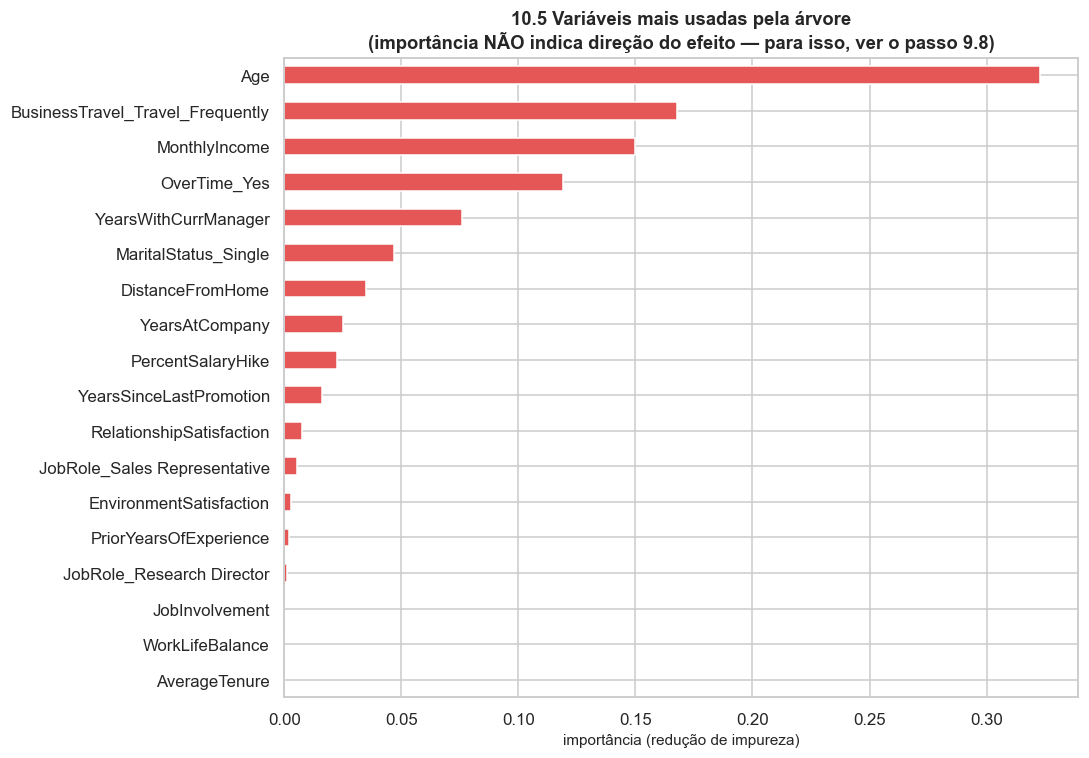

Importância das 10 primeiras:

Age                                32.300
BusinessTravel_Travel_Frequently   16.800
MonthlyIncome                      15.000
OverTime_Yes                       11.900
YearsWithCurrManager                7.600
MaritalStatus_Single                4.700
DistanceFromHome                    3.500
YearsAtCompany                      2.500
PercentSalaryHike                   2.300
YearsSinceLastPromotion             1.600


In [71]:
# Importância das variáveis na Árvore B (a mais profunda, que usa mais variáveis).
# ATENÇÃO: 'importância' numa árvore = quanto aquela variável reduziu a impureza
# total. NÃO é efeito causal, NÃO tem sinal (não diz se aumenta ou reduz o risco)
# e favorece variáveis com muitos valores distintos. É um guia, não uma conclusão.
importancias = (pd.Series(arvore_b.feature_importances_, index=X.columns)
                .sort_values(ascending=False).head(18))

fig, eixo = plt.subplots(figsize=(10, 7))
importancias.sort_values().plot(kind="barh", color=COR_SAIU, ax=eixo)
eixo.set(xlabel="importância (redução de impureza)", ylabel="",
         title="10.5 Variáveis mais usadas pela árvore\n"
               "(importância NÃO indica direção do efeito — para isso, ver o passo 9.8)")
plt.tight_layout()
plt.show()

print("Importância das 10 primeiras:\n")
print((importancias.head(10) * 100).round(1).rename("% da importância total").to_string())

## 10.5 Comparação final dos modelos

Todos os modelos foram ajustados na **mesma base**, com a **mesma semente** e avaliados no **mesmo
conjunto de teste** — sem isso, a comparação não valeria nada. A Árvore C entra na tabela como
**contraexemplo**, com o alerta da Parte 10.3: a AUC dela não mede capacidade de previsão.

COMPARAÇÃO FINAL — mesmo conjunto de teste, mesma semente

                                                            AUC teste                  interpretável?
modelo                                                                                               
Árvore C (sem limite nenhum - demonstração de overfitting)      0.895  não — e AUC inflada (ver 10.3)
Logística 2 — Grupos A + B (gestão)                             0.745              sim (RC + valor-p)
Árvore B (500 casos para dividir, sem poda)                     0.744                         parcial
Árvore A (rasa, para leitura)                                   0.718           sim (regras legíveis)
Logística 1 — só Grupo A (recrutamento)                         0.702              sim (RC + valor-p)

O MODELO ESCOLHIDO é a Logística 2: melhor AUC entre os modelos sem vazamento,
com coeficientes interpretáveis, valores-p e intervalos de confiança. A Árvore A
acompanha como instrumento de COMUNICAÇÃO - as regras dela vão par

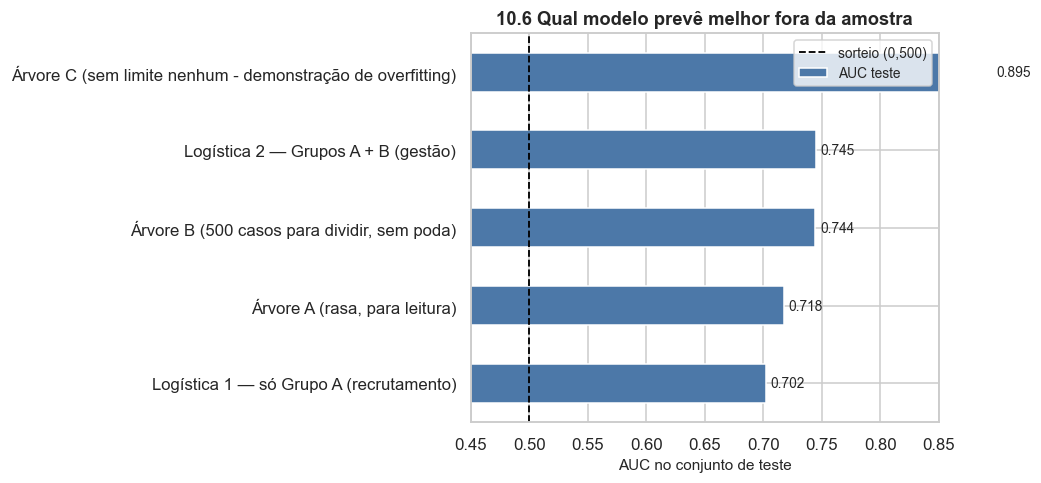

In [72]:
# Comparação final das quatro abordagens, na MESMA base e no MESMO conjunto de teste.
comparacao_final = pd.DataFrame([
    {"modelo": "Logística 1 — só Grupo A (recrutamento)",
     "AUC teste": resultado_1u["auc_teste"], "interpretável?": "sim (RC + valor-p)"},
    {"modelo": "Logística 2 — Grupos A + B (gestão)",
     "AUC teste": resultado_2["auc_teste"], "interpretável?": "sim (RC + valor-p)"},
    {"modelo": metricas_a["modelo"],
     "AUC teste": metricas_a["AUC teste"], "interpretável?": "sim (regras legíveis)"},
    {"modelo": metricas_b["modelo"],
     "AUC teste": metricas_b["AUC teste"], "interpretável?": "parcial"},
    {"modelo": metricas_c["modelo"],
     "AUC teste": metricas_c["AUC teste"],
     "interpretável?": "não — e AUC inflada (ver 10.3)"},
]).set_index("modelo").sort_values("AUC teste", ascending=False)

print("COMPARAÇÃO FINAL — mesmo conjunto de teste, mesma semente\n")
print(comparacao_final.round(4).to_string())
print("\nO MODELO ESCOLHIDO é a Logística 2: melhor AUC entre os modelos sem vazamento,")
print("com coeficientes interpretáveis, valores-p e intervalos de confiança. A Árvore A")
print("acompanha como instrumento de COMUNICAÇÃO - as regras dela vão para o slide,")
print("as razões de chances da logística vão para o relatório.")

fig, eixo = plt.subplots(figsize=(10, 4.5))
comparacao_final["AUC teste"].sort_values().plot(kind="barh", ax=eixo, color=COR_FICOU)
eixo.axvline(0.5, color="black", linestyle="--", lw=1.2, label="sorteio (0,500)")
eixo.set(xlabel="AUC no conjunto de teste", ylabel="",
         title="10.6 Qual modelo prevê melhor fora da amostra", xlim=(0.45, 0.85))
eixo.legend(fontsize=9)
for i, valor in enumerate(comparacao_final["AUC teste"].sort_values()):
    eixo.text(valor + 0.004, i, f"{valor:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

---

# Parte 11. Do modelo à decisão de RH

Um projeto de People Analytics que termina na AUC não terminou. Esta parte faz a travessia que
justifica todo o resto: **transformar resultado estatístico em decisão de gestão, com custo
estimado e com limites declarados.**

## 11.1 Os achados, organizados pelo que a empresa pode fazer com eles

A regra de organização não é a força estatística: é a **acionabilidade**. Um fator com associação
forte e nenhuma alavanca de gestão vale menos, na prática, que um fator moderado sobre o qual a
empresa decide diretamente.

| Fator | Associação | A empresa controla? | Ação possível | Prazo |
|---|---|---|---|---|
| **Viagens frequentes** | Muito forte (≈ 3,9× a chance) | **Sim, diretamente** | Rever a política de viagens: rotação entre a equipe, substituição por reunião remota, compensação específica para quem viaja muito | Curto |
| **Hora extra** | Forte (≈ 2,6× a chance) | **Sim, diretamente** | Dimensionamento de equipe; teto de horas; revisão de carga nas áreas com mais incidência | Curto |
| **Nenhum treinamento no ano** | Moderada (≈ 0,85 por treinamento) | **Sim, baixo custo** | Garantir piso mínimo de treinamentos por pessoa/ano | Curto |
| **Equilíbrio trabalho-vida = 1** | Forte (degrau) | **Sim** | Lista nominal do grupo que avaliou 1; diagnóstico por área; ação sobre a causa local | Curto |
| **Participação acionária = 0** | Moderada a forte | **Sim** | Estender elegibilidade a cargos de risco alto e substituição custosa | Médio |
| **Salário relativo baixo** | Moderada | Sim, com custo | Revisão de faixas nos cargos com maior taxa de saída | Médio |
| **Satisfação com trabalho/ambiente baixa** | Moderada, gradiente | Parcialmente | Pesquisa de clima com desdobramento por gestor; ação sobre causas locais | Médio |
| **Anos sem promoção** | Moderada (na cauda) | **Sim** | Revisar os casos extremos: ou promove, ou explica o porquê | Curto |
| **Cargo (ex.: Sales Representative)** | Forte | Parcialmente | Trilha de carreira e remuneração variável específicas da função | Médio |
| **Canal de recrutamento** | Fraca a moderada | **Sim** | Realocar investimento entre canais — **após** controlar por cargo | Médio |
| **Estado civil (solteiro)** | Forte sem os controles de gestão; **desaparece** com eles | **Não** (e não deve) | **Nenhuma ação sobre a pessoa.** Usar como controle estatístico apenas | — |
| **Idade** | Moderada | **Não** (e não deve) | **Nenhuma ação sobre a pessoa.** Controle estatístico | — |
| **Gênero** | Não detectada | — | Monitorar; resultado nulo é informação relevante | — |

## 11.2 Quanto vale evitar uma saída: a conta que converte estatística em orçamento

Nenhuma proposta de retenção é aprovada sem número. A conta abaixo é propositalmente **simples e
com premissas explícitas** — o valor de um cálculo assim não está na precisão, está em tornar as
premissas discutíveis. Troque os valores pelos da sua organização.

In [73]:
# ======================= PREMISSAS (ajuste para o seu caso) ================
SALARIO_MEDIO_MENSAL   = float(base_unica["MonthlyIncome"].mean())
MESES_PARA_SUBSTITUIR  = 3.0    # tempo médio entre a saída e o substituto produtivo
CUSTO_RECRUTAMENTO     = 1.0    # em salários mensais: anúncio, seleção, horas de entrevista
CUSTO_TREINAMENTO      = 1.5    # em salários mensais: integração, treinamento, mentoria
PERDA_PRODUTIVIDADE    = 1.5    # em salários mensais: vaga aberta + rampa do substituto
EFICACIA_DA_CONVERSA   = 0.25   # fração das saídas evitada quando há intervenção a tempo
CUSTO_DA_CONVERSA      = 0.02   # custo de cada conversa, em salários mensais (~4 horas)
# ==========================================================================

custo_por_saida = (SALARIO_MEDIO_MENSAL
                   * (CUSTO_RECRUTAMENTO + CUSTO_TREINAMENTO + PERDA_PRODUTIVIDADE))

print("PREMISSAS")
print(f"  salário médio mensal na base ......... R$ {SALARIO_MEDIO_MENSAL:,.0f}"
      .replace(",", "."))
print(f"  custo de uma saída (em salários) ..... "
      f"{CUSTO_RECRUTAMENTO + CUSTO_TREINAMENTO + PERDA_PRODUTIVIDADE:.1f}x")
print(f"  CUSTO ESTIMADO POR SAÍDA ............. R$ {custo_por_saida:,.0f}"
      .replace(",", "."))

# --- Cenário: atuar sobre o decil de maior risco do conjunto de teste -----
n_abordados   = int(decil_1["n"])
saidas_no_grupo = int(decil_1["saídas observadas"])
saidas_evitadas = saidas_no_grupo * EFICACIA_DA_CONVERSA

beneficio = saidas_evitadas * custo_por_saida
custo     = n_abordados * CUSTO_DA_CONVERSA * SALARIO_MEDIO_MENSAL
retorno   = beneficio - custo

print(f"\nCENÁRIO: conversa estruturada com os 10% de maior risco previsto")
print(f"  pessoas abordadas .................... {n_abordados}")
print(f"  saídas que de fato ocorreram no grupo  {saidas_no_grupo}")
print(f"  saídas evitadas (eficácia {EFICACIA_DA_CONVERSA:.0%}) ...... {saidas_evitadas:.1f}")
print(f"\n  benefício estimado .................. R$ {beneficio:,.0f}".replace(",", "."))
print(f"  custo das conversas ................. R$ {custo:,.0f}".replace(",", "."))
print(f"  RETORNO LÍQUIDO ESTIMADO ............ R$ {retorno:,.0f}".replace(",", "."))
if custo > 0:
    print(f"  retorno por real investido .......... R$ {beneficio / custo:,.2f}")

# --- Sensibilidade: o resultado depende de quê? ---------------------------
print("\n\nANÁLISE DE SENSIBILIDADE À EFICÁCIA DA INTERVENÇÃO")
print("(a premissa mais incerta de todas - e é honesto mostrar o intervalo)\n")
cenarios = []
for eficacia in [0.05, 0.10, 0.15, 0.25, 0.40]:
    b = saidas_no_grupo * eficacia * custo_por_saida
    cenarios.append({"eficácia": f"{eficacia:.0%}",
                     "saídas evitadas": round(saidas_no_grupo * eficacia, 1),
                     "benefício (R$)": round(b),
                     "retorno líquido (R$)": round(b - custo)})
print(pd.DataFrame(cenarios).to_string(index=False))

print("\nO ponto desta tabela: mesmo com eficácia baixa, a conta fecha positiva, porque")
print("o custo de uma conversa é muito menor que o custo de uma substituição. É esse")
print("desequilíbrio de custos - e não a AUC do modelo - que justifica o programa.")

PREMISSAS
  salário médio mensal na base ......... R$ 6.305
  custo de uma saída (em salários) ..... 4.0x
  CUSTO ESTIMADO POR SAÍDA ............. R$ 25.220

CENÁRIO: conversa estruturada com os 10% de maior risco previsto
  pessoas abordadas .................... 245
  saídas que de fato ocorreram no grupo  125
  saídas evitadas (eficácia 25%) ...... 31.2

  benefício estimado .................. R$ 788.119
  custo das conversas ................. R$ 30.894
  RETORNO LÍQUIDO ESTIMADO ............ R$ 757.225
  retorno por real investido .......... R$ 25.51


ANÁLISE DE SENSIBILIDADE À EFICÁCIA DA INTERVENÇÃO
(a premissa mais incerta de todas - e é honesto mostrar o intervalo)

eficácia  saídas evitadas  benefício (R$)  retorno líquido (R$)
      5%            6.200          157624                126730
     10%           12.500          315248                284353
     15%           18.800          472871                441977
     25%           31.200          788119                7572

## 11.3 O que este estudo **não** autoriza a concluir

Retomando a Parte 0.5, agora com os resultados em mãos. Todo relatório de People Analytics deve
ter uma seção como esta, e ela deve ser escrita **antes** da apresentação, não depois da pergunta
difícil na reunião.

**1. Nenhum resultado aqui é causal.** O modelo mede associação condicional. Para afirmar que
reduzir hora extra *causa* redução de saídas, seria preciso um desenho que isolasse o efeito: um
piloto com áreas comparáveis, em que uma recebe a política de teto de horas e outra não, com
acompanhamento por alguns trimestres. Esse desenho é factível e custa pouco — e é a recomendação
metodológica mais importante deste relatório.

**2. O modelo não está validado no tempo.** A divisão treino/teste foi **aleatória**, não
**temporal**. A validação correta para uso em produção é: treinar com os dados até um ano T e testar
nas saídas do ano T+1. Essa validação não é possível nesta base, que não tem data. Enquanto ela não
for feita, o número de AUC vale como demonstração de método, não como promessa de desempenho.

**3. A base tem limitações documentadas.** 64,5% de linhas duplicadas (Parte 4.4); origem
sintetizada a partir da base IBM clássica; `Attrition` sem data; ausência de informação sobre
gestor direto, área de atuação específica e remuneração variável. Tudo isso está registrado no
notebook e deve constar do relatório.

**4. Variáveis protegidas têm uso restrito e declarado.** Gênero, idade e estado civil entraram no
modelo **como controles**, para que o efeito das demais variáveis não fosse contaminado por
composição do quadro. Elas **não** devem entrar em nenhuma regra de decisão sobre pessoas — nem em
seleção, nem em promoção, nem na priorização de conversas. Sob a LGPD, isso não é só boa prática:
tratar dado pessoal de funcionário exige base legal, finalidade declarada e minimização.

**5. O modelo produz prioridade, não veredito.** A saída operacional é uma fila de conversas
(passo 9.10). Usar a probabilidade prevista para decidir promoção, desligamento ou alocação é uso
indevido: o modelo não foi construído para isso e os erros teriam consequências sobre pessoas
específicas. Há ainda um efeito perverso a evitar: se os gestores souberem a nota de risco de cada
pessoa, a nota passa a influenciar o tratamento, que influencia a saída — a previsão se torna
profecia autorrealizável.

**6. Transparência com quem é medido.** Os funcionários devem saber que existe um programa de
retenção baseado em dados, que finalidade ele tem e que dados usa. Um programa de People Analytics
que precisa ser secreto para funcionar tem um problema que nenhum modelo resolve.

---

# Parte 12. As armadilhas do caminho, e as decisões que as evitam

Esta parte recolhe, num quadro só, as **decisões metodológicas** tomadas ao longo do notebook e a
armadilha que cada uma evita. Todas são erros frequentes em análise de atrito — frequentes porque o
caminho errado é, em cada caso, o mais curto, e muitas vezes é o que o software oferece por padrão.

Ler esta parte depois de ter executado tudo tem uma função específica: **mostrar que o resultado
dependia dessas escolhas.** Nenhuma delas é detalhe técnico. Cada uma muda o número que iria para o
relatório.

| # | A armadilha | Por que ela engana | A decisão deste notebook |
|---|---|---|---|
| 1 | **Reportar desempenho medido nos dados de ajuste** | Qualquer modelo descreve bem os dados em que foi estimado. Sem divisão treino/teste, o número reportado não é previsão, é memorização — e sempre parece melhor do que a realidade | Divisão aleatória, estratificada e reprodutível, com o otimismo (treino − teste) impresso em toda avaliação (passo 9.6) |
| 2 | **Não checar duplicatas** | 64,5% das linhas são repetições exatas, e 26,9% das linhas de teste têm vetor idêntico no treino. Cópias nos dois lados fazem o modelo "acertar" o que já viu | Detectadas, quantificadas, e o efeito medido nos dois tipos de modelo: nulo na logística, acerto perfeito nas linhas copiadas na árvore sem poda (passos 4.4, 9.7 e 10.3) |
| 3 | **Tratar uma dependente de três níveis como binária** | `Attrition` tem permanência, demissão voluntária e desligamento. Agrupar os dois últimos mistura eventos de causas **opostas**: quem é desligado costuma ter baixo desempenho; quem pede demissão, uma alternativa melhor | Dependente binária `saiu`, com o recorte dos 87 desligamentos documentado e justificado (passos 1.4 e 6) |
| 4 | **Usar um valor sentinela como se fosse número** | Quem está no primeiro emprego recebe estabilidade média **zero**, o mesmo valor de quem teve passagens brevíssimas. São perfis opostos com o mesmo código — e o passo 8.10 mostrou que têm taxas de saída diferentes | Mantém o zero **e** cria a indicadora `PrimeiroEmprego`, que separa os dois casos (passo 5.2) |
| 5 | **Aceitar o ponto de corte padrão de 0,5** | Com 16% de eventos, 0,5 classifica quase todo mundo como "fica": recall de 15% e acurácia de 85% — pior que o modelo trivial que diz "ninguém sai" | Varredura de cortes, curva precisão-recall e uso por **ordenamento** em vez de classificação (passos 9.9 e 9.10) |
| 6 | **Usar acurácia com classes desbalanceadas** | Premia o modelo inútil: prever "ninguém sai" acerta 84% dos casos | AUC como métrica principal, com recall, precisão, lift e captura acumulada (passos 9.6, 9.9 e 9.10) |
| 7 | **Pôr no modelo variáveis linearmente dependentes** | `AgeStartedWorking` é exatamente `Age − TotalWorkingYears`: colinearidade perfeita, e o modelo não consegue estimar coeficientes separados | Identidade verificada nas checagens de consistência, e a variável excluída com o motivo registrado (passos 4.7 e 9.2) |
| 8 | **Calcular o VIF e não ler** | Imprimir o número sem conduta associada não é diagnóstico, é ritual | VIF agrupado por variável de origem, com limiares, interpretação de cada caso alto e decisão declarada (passo 9.5) |
| 9 | **Confiar numa precaução não verificada** | Filtrar ausentes antes de cada gráfico parece zelo, mas nesta base não remove uma linha: não há ausentes | Ausência de valores ausentes medida e declarada antes de qualquer análise (passo 4.3) |
| 10 | **Misturar o que se sabe antes e depois de contratar** | Um modelo que mistura os dois blocos prevê bem e não informa ação: não se pode "recrutar por satisfação com o ambiente" | Modelos separados por bloco, com a comparação explícita do que cada um acrescenta (passos 1.3, 9.3 e 9.8) |
| 11 | **Repetir número que não saiu da própria execução** | Afirmações como "58% têm menos de 3 anos de experiência" circulam sem que ninguém as recalcule | Todas as proporções recalculadas e confrontadas com a afirmação corrente (passo 5.4) |
| 12 | **Apresentar taxa de grupo sem o n e sem o intervalo** | Uma taxa de 50% sobre 4 pessoas e sobre 4.000 não são o mesmo achado — e o gráfico de barras empilhadas a 100% esconde exatamente essa diferença | Toda taxa da Parte 8 vem com n, margem de erro e a regra de decisão do intervalo de confiança (passo 8.1) |
| 13 | **Parar na análise bivariada** | Taxa bruta confunde efeitos: **superestima** o estado civil (que é, em parte, idade disfarçada) e **subestima** as viagens (mascaradas por cargo e salário) | A Parte 8 termina demonstrando o confundimento com dado desta base, e a Parte 9 estima cada efeito mantendo os demais constantes (passos 8.18, 9.4 e 9.8) |
| 14 | **Celebrar um salto de desempenho sem explicá-lo** | A árvore sem poda alcançou AUC de teste acima de todos os outros modelos. Parecia o melhor resultado do notebook, e era vazamento | Investigado até a causa, com medição das duplicatas no espaço de atributos e reajuste em base deduplicada (passo 10.3) |

**A lição comum às catorze.** Em todas, o caminho errado é mais curto **e** o resultado que ele produz
é mais favorável: modelo que parece prever melhor, variável que parece importar mais, métrica que
parece excelente. É por isso que a verificação não pode ser opcional — **o erro metodológico quase
nunca aparece como erro; aparece como bom resultado.**

**E a contrapartida, que também é lição.** Boa parte das verificações deste notebook **não** achou
problema: não havia valores ausentes, as sete checagens de consistência passaram, as duplicatas não
enganaram a regressão, o modelo saiu bem calibrado. Verificação que não acha nada não foi perda de
tempo: é ela que autoriza a confiar no resto.

---

# Parte 13. Síntese, exercícios e referências

## 13.1 Síntese do estudo

**A pergunta.** Quais fatores mais se associam ao atrito (demissão voluntária) no quadro de
pessoal, e o que se pode fazer a respeito?

**O caminho.** 23.058 registros, 30 variáveis. Diagnóstico de qualidade (64,5% de duplicatas,
nenhum ausente, uma variável redundante por construção). Recorte para 22.971 casos de interesse,
com taxa global de saída voluntária de **15,7%**. Duas variáveis criadas (experiência anterior,
estabilidade média) e uma correção de codificação (primeiro emprego). Exploração univariada e
bivariada com taxa, n e intervalo de confiança. Dois modelos logísticos (recrutamento e gestão) e
três árvores, todos avaliados **fora da amostra**.

**Os achados principais.**

1. **Viagens frequentes** é o fator de maior magnitude no modelo final (chance ≈ 3,9 vezes maior
   que entre quem não viaja) — e só aparece com essa força **depois** do controle por cargo, nível
   e salário. A análise bivariada o subestimava.
2. **Hora extra** vem em seguida (chance ≈ 2,6 vezes maior) e é o fator mais acionável: o efeito
   persiste controlando por salário, cargo, nível e satisfação.
3. **Equilíbrio trabalho-vida ruim (nível 1)** forma um grupo de risco destacado — padrão de
   degrau, não de gradiente, o que concentra a ação num grupo pequeno e identificável.
4. **Salário relativo**, **participação acionária** e **treinamentos no último ano** protegem —
   os três são instrumentos que a empresa aciona diretamente, com custos muito diferentes.
5. **Satisfação com o trabalho, com o ambiente e envolvimento** têm gradiente claro e consistente.
6. **Idade protege; estado civil não resiste aos controles.** "Solteiro" tinha chance 2,1 vezes
   maior no modelo de recrutamento e perde a significância quando entram as variáveis de gestão:
   era indicador indireto daquilo que estas medem diretamente. Nenhum dos dois deve orientar
   decisão sobre pessoas.
7. **Gênero não apresenta diferença detectável.** Resultado nulo, reportado como tal.
8. **Nenhuma variável isolada explica o atrito.** A maior correlação simples com a saída é de
   |r| ≈ 0,2: o fenômeno é multifatorial, e é isso que justifica o modelo multivariado.
9. **A qualidade da base limita tudo.** Os 64,5% de linhas repetidas não enganaram a regressão
   (Parte 9.6), mas levaram uma árvore sem poda a acerto perfeito nas linhas que tinham cópia no
   treino (Parte 10.3). A lição não é "duplicata engana" nem "duplicata é inofensiva": é que **o
   efeito depende da flexibilidade do modelo**, e por isso se checa sempre. O desempenho confiável
   desta base está em torno de **AUC 0,74** — patamar ao qual a logística e a árvore podada chegam
   por caminhos independentes.

**O uso recomendado.** Fila mensal de prioridade com os 10% de maior risco previsto, que concentra
parcela desproporcional das saídas (passo 9.10), somada a ação estrutural sobre hora extra e
equilíbrio trabalho-vida. Para afirmar causalidade, um piloto controlado — não mais análise da
mesma base.

## 13.2 Exercícios

**Nível 1 — leitura e replicação**

1. Recalcule a taxa de saída por `JobRole` **dentro de cada departamento**. Algum cargo tem
   comportamento oposto ao do seu departamento? Use `taxa_saida_por()` sobre um subconjunto.
2. No passo 8.16, o `WorkLifeBalance` mostra padrão de degrau. Construa uma variável
   `EquilibrioRuim = (WorkLifeBalance == 1)` e compare, no Modelo 2, a especificação com a
   indicadora contra a especificação com `C(WorkLifeBalance)`. O que muda na AUC? E na legibilidade?
3. Refaça os boxplots do passo 8.13 usando a base **sem duplicatas**. Alguma mediana muda de
   forma relevante?

**Nível 2 — modelagem**

4. Acrescente ao Modelo 2 a **interação** entre hora extra e equilíbrio trabalho-vida
   (`C(OverTime):C(WorkLifeBalance)` na fórmula). A hipótese é que hora extra pesa mais para quem
   já tem equilíbrio ruim. A interação é significativa? Quanto a AUC muda?
5. Ajuste o Modelo 2 **separadamente por departamento**. Os fatores de risco são os mesmos em
   Vendas e em P&D? Se não forem, o que isso implica para uma política única de retenção?
6. Troque a árvore por uma **floresta aleatória** (`RandomForestClassifier`). Quanto a AUC melhora?
   O que se perde em interpretabilidade? Vale a troca, dado o uso pretendido na Parte 9.9?
7. O Modelo 1 usa só o Grupo A. Construa um Modelo 3 **só com o Grupo B** e compare as três AUCs.
   Qual grupo de variáveis carrega mais informação sobre o atrito?

**Nível 3 — desenho de pesquisa e decisão**

8. Refaça a conta da Parte 11.2 com premissas da sua organização (ou de uma que você conheça).
   Em que valor de eficácia da intervenção o retorno líquido se torna negativo?
9. Escreva, em uma página, o **desenho de um piloto** para testar causalmente o efeito da hora
   extra sobre a saída: unidade de alocação, critério de comparabilidade entre grupos, duração,
   variável de resultado, e o que poderia invalidar a conclusão.
10. Redija a **seção de limitações** do relatório que você entregaria à diretoria, em no máximo
    300 palavras, usando a Parte 11.3 como insumo mas com suas próprias palavras.
11. A diretoria pede a lista nominal dos 50 funcionários de maior risco, para "conversar". Escreva
    a resposta: o que você entrega, o que você não entrega, e por quê.

## 13.3 Referências

**A base**
- IBM HR Analytics Employee Attrition & Performance — base sintética de 1.470 registros, criada
  para fins de ensino, da qual esta é uma versão ampliada.

**People Analytics**
- *People analytics at Google: using data to make Google a great place to work.* Harvard Business
  School Digital Initiative. https://digital.hbs.edu/platform-digit/submission/people-analytics-at-google-using-data-to-make-google-a-great-place-to-work/
- *Case study: how Google uses People Analytics.* Sage People. https://www.sagepeople.com/about-us/news-hub/case-study-how-google-uses-people-analytics/
- BOCK, L. *Um novo jeito de trabalhar.* Sextante, 2015. (relato interno do People Operations do Google)
- EDMONDSON, A. C. *A organização sem medo.* Alta Books, 2020. (segurança psicológica; base do Project Aristotle)

**Método**
- HOSMER, D. W.; LEMESHOW, S.; STURDIVANT, R. X. *Applied Logistic Regression.* 3. ed. Wiley, 2013.
  (a referência padrão sobre regressão logística e interpretação de razões de chances)
- FIELD, A. *Descobrindo a estatística usando o SPSS.* 2. ed. Artmed, 2009. (cap. sobre logística)
- JAMES, G. et al. *An Introduction to Statistical Learning.* 2. ed. Springer, 2021.
  (treino/teste, árvores, avaliação; disponível gratuitamente)
- FAVERO, L. P.; BELFIORE, P. *Manual de análise de dados.* Elsevier, 2017.

**Documentação das ferramentas**
- pandas: https://pandas.pydata.org/docs/
- statsmodels (logística): https://www.statsmodels.org/stable/discretemod.html
- scikit-learn (árvores e métricas): https://scikit-learn.org/stable/
- seaborn: https://seaborn.pydata.org/

**Marco legal**
- BRASIL. Lei nº 13.709/2018 — Lei Geral de Proteção de Dados Pessoais (LGPD).

---

*Notebook preparado para a disciplina Métodos e Técnicas de Pesquisa Quantitativa, curso de
Administração da UFMA. O estudo percorre, passo a passo, o caminho completo de um projeto de
People Analytics: da descrição de uma coluna à decisão de gestão. As armadilhas reunidas na
Parte 12 são apontadas com finalidade didática — verificar a própria análise é parte do método.*